# Tethered-mRNA Harringtonine Runoff Analysis — Cell-Level, Replicate-Aware Statistics

This notebook imports paired tethered-mRNA crop-array files:

- **Untracked spot data:** `Cell01_TRNL_Ch1.nc`
- **Tracked data:** `Cell01_TRNL_Ch1_tracked.nc`

Both datasets are retained, but HT-resistant-fraction and runoff quantification use the **untracked spot data**.

## Statistical unit

Every inferential analysis uses **one averaged value per cell** as an observation. Because cells acquired in the same biological replicate are clustered, the primary tests are **cell-level linear mixed-effects models** with biological replicate as a random intercept. Thus, the result tables report both `n_cells` and `n_replicates`; biological-replicate means are displayed on plots as open circles but are not substituted for the cell observations.

## Restarting from saved data

Set `DATA_SOURCE_MODE = 'saved'` in Part I-A to load the saved Zarr datasets and CSV/Parquet dataframes. In this mode, the notebook skips file discovery, metadata assignment, and raw NetCDF measurement, then resumes at spot-level quality control.


## Part I — Imports and user configuration

In [1]:
# CELL PURPOSE: Import dependencies and define the notebook version.

from __future__ import annotations

import json
import math
import re
import shutil
import warnings
from pathlib import Path
from typing import Mapping, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr
from IPython.display import clear_output, display
from scipy.optimize import curve_fit
from scipy.special import erfc
from scipy import stats

import statsmodels.formula.api as smf

try:
    import ipywidgets as widgets
except ImportError:
    widgets = None

import crop_array_tools as ca

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_colwidth', 140)

NOTEBOOK_VERSION = '2026-07-30 tethered mRNA HT v4.1 plotting refactor'
print(f'Loaded: {NOTEBOOK_VERSION}')


Loaded: 2026-07-30 tethered mRNA HT v4.1 plotting refactor


In [2]:
# CELL PURPOSE: Configure paths, HT timing, baseline flattening, fitting, and plotting.
NAS_ROOT = Path(r'Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT')  # EDIT
OUTPUT_ROOT = NAS_ROOT / 'Analysis_Output' / 'Tethered_HT'
DATASET_DIR = OUTPUT_ROOT / 'Datasets'
DATAFRAME_DIR = OUTPUT_ROOT / 'Dataframes'
FIGURE_DIR = OUTPUT_ROOT / 'Figures'
GROUP_ASSIGNMENT_FILE = OUTPUT_ROOT / 'group_assignments.csv'
for directory in (DATASET_DIR, DATAFRAME_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
SPOT_FILE_PATTERN = 'Cell*_TRNL_Ch1.nc'
TRACKED_FILE_PATTERN = 'Cell*_TRNL_Ch1_tracked.nc'
TRANSLATION_CHANNEL = 1
MEASURE_SIGNAL_KWARGS = {'ref_ch': TRANSLATION_CHANNEL, 'disk_r': 3, 'roll_num': 1}

# -----------------------------------------------------------------------------
# Harringtonine experimental timeline and fitting convention
# -----------------------------------------------------------------------------
# Frames 0-4 are acquired before HT is added. HT is added immediately after
# acquisition of frame 4, so frame 4 is the experimental t = 0 reference.
# Frame 5 is the first acquisition ~1 minute after addition.
#
# The ~1 minute HT-action delay is retained as a biological timing correction,
# but it is NOT implemented by discarding the upper shoulder of the runoff
# curve. Instead, the residual-aware tanh is fit continuously from frame 4
# onward. This lets frame 4, frame 5, and the full descending phase jointly
# constrain the tanh width (and therefore the elongation rate).
#
# A constant 1-minute action delay shifts absolute timing parameters such as
# t_half, but it does not change the fitted tanh width. Therefore the elongation
# rate (which is derived from that width) is not post-hoc reduced by 1 minute.
HT_ADDITION_FRAME = 4
FRAME_INTERVAL_MIN = 1.0
HT_ACTION_DELAY_MIN = 1.0
HT_ACTION_TIME_AFTER_ADDITION_MIN = HT_ACTION_DELAY_MIN
HT_ACTION_FRAME = (
    HT_ADDITION_FRAME
    + HT_ACTION_TIME_AFTER_ADDITION_MIN / FRAME_INTERVAL_MIN
)

# Full-runoff fit starts at the HT-addition reference frame.
HT_FIT_START_FRAME = HT_ADDITION_FRAME
HT_FIT_START_TIME_AFTER_ADDITION_MIN = 0.0
DISPLAY_HT_ADDITION_FRAME = HT_ADDITION_FRAME

# Baseline-QC routines use an exclusive upper frame bound. Setting this to 5
# keeps all five true pre-HT acquisitions (frames 0-4) in baseline QC even
# though the nonlinear runoff fit begins at frame 4.
BASELINE_END_EXCLUSIVE_FRAME = HT_ADDITION_FRAME + 1

FIT_CONVENTION = 'full_runoff_from_ht_addition'

ORF_LENGTH_AA = 780

# -----------------------------------------------------------------------------
# Spot-level quality control
# -----------------------------------------------------------------------------
# When enabled, only finite spot measurements within these absolute signal
# bounds are retained for every downstream calculation.
USE_SPOT_QC = True
SPOT_QC_MIN_SIGNAL = 100
SPOT_QC_MAX_SIGNAL = None

# Optional diagnostic histogram comparing raw and retained signal values.
PLOT_SPOT_QC_HISTOGRAM = True
SPOT_QC_HISTOGRAM_BINS = 100

# Average these anchor frames per cell and replace every intervening pre-HT frame.
BASELINE_ANCHOR_FRAMES = (0,4)
FLATTEN_BASELINE = False
ENDPOINT_FRAME_COUNT = 5

RESISTANT_BASELINE_FRAMES = BASELINE_ANCHOR_FRAMES
RESISTANT_END_FRAMES = (29,)
RESISTANT_SIGNAL_FRACTION = 0.05

TANH_INITIAL_T_HALF_MIN = 4.0
TANH_INITIAL_RATE_AA_SEC = 2.0
TANH_RATE_BOUNDS_AA_SEC = (0.01, 30.0)
MIN_POST_HT_FIT_POINTS = 4

# Allow the tanh model to estimate the residual fraction.
RESIDUAL_FIT_MODE = 'fit'

# Bounds used only when RESIDUAL_FIT_MODE = 'fit'.
RESIDUAL_FRACTION_BOUNDS = (0.0, 0.80)

# When fitting the residual, restrict it to a region around the experimentally
# measured endpoint fraction. For example, an endpoint of 0.10 would initially
# allow approximately 0.00 to 0.25.
RESIDUAL_FIT_MARGIN = 0.15

# Keep this False to match the unweighted fitting used previously.
# Set True to give points with smaller SEM more influence.
USE_SEM_WEIGHTING = False

# Prevent nearly zero SEM values from receiving excessive weight.
MIN_FIT_SEM = 0.02

CONTROL_GROUP = 'Control'
TYPE_ORDER = ['No Nsp1', 'Nsp1']
GROUP_ORDER = ['Control', "SARS_5'UTR", "SARS_3'UTR", "SARS_5'_3'UTR"]
GROUP_LABELS = {
    'Control': 'Host Reporter',
    "SARS_5'UTR": "SARS 5' UTR",
    "SARS_3'UTR": "SARS 3' UTR",
    "SARS_5'_3'UTR": "SARS 5' and 3' UTRs",
}
TYPE_LABELS = {'No Nsp1': 'No Nsp1', 'Nsp1': '+ Nsp1'}
TYPE_COLORS = {'No Nsp1': '#00D8D8', 'Nsp1': '#029090'}
GRAY_PALETTE = ['darkgray', 'dimgray']
SAVE_FIGURES = True
FIGURE_DPI = 300
print(f'Input root: {NAS_ROOT}')
print(f'Output root: {OUTPUT_ROOT}')
print(f'Baseline anchors: {BASELINE_ANCHOR_FRAMES}')
print(
    'HT timeline / fit convention: '
    f'addition after frame {HT_ADDITION_FRAME} (t=0); '
    f'~{HT_ACTION_DELAY_MIN:g} min expected action delay; '
    f'continuous tanh fit begins at frame {HT_FIT_START_FRAME} (t=0)'
)
print(
    'Spot QC: '
    f'{"enabled" if USE_SPOT_QC else "disabled"}; '
    f'min={SPOT_QC_MIN_SIGNAL}, max={SPOT_QC_MAX_SIGNAL}'
)

# -----------------------------------------------------------------------------
# General isolated baseline-dip correction
# -----------------------------------------------------------------------------

AUTO_CORRECT_BASELINE_DIPS = True

# Apply the correction to total translation-site intensity only.
# Spot counts remain unchanged.
BASELINE_DIP_METRIC = 'total_spot_intensity'

# Conservative threshold applied across every group and type.
# A frame must be at least 25% below expectation.
BASELINE_DIP_MIN_DROP_FRACTION = 0.25

# The two neighboring reference frames must agree within 25%.
BASELINE_DIP_MAX_REFERENCE_RELATIVE_DIFFERENCE = 0.20

# The drop must also exceed normal baseline variability.
BASELINE_DIP_MIN_ROBUST_Z = 3.0

# Require at least five finite pre-HT frames.
BASELINE_DIP_MIN_BASELINE_FRAMES = 5

# The general detector corrects no more than one frame per cell.
BASELINE_DIP_MAX_CORRECTIONS_PER_CELL = 1

# Allow isolated edge-frame detection globally. For Control +Nsp1,
# frames 0 and 4 are restored before the targeted correction.
BASELINE_DIP_ALLOW_EDGE_CORRECTION = True


# -----------------------------------------------------------------------------
# Targeted Control +Nsp1 multi-frame baseline correction
# -----------------------------------------------------------------------------

CONTROL_NSP1_MULTI_FRAME_CORRECTION = True

CONTROL_NSP1_CORRECTION_GROUP = 'Control'
CONTROL_NSP1_CORRECTION_TYPE = 'Nsp1'

# These frames are treated as protected, reliable reference anchors.
CONTROL_NSP1_REFERENCE_FRAMES = (
    0,
    4,
)

# These are the only frames eligible for the targeted correction.
CONTROL_NSP1_INTERIOR_FRAMES = (
    1,
    2,
    3,
)

# Require at least two clearly affected interior frames before
# activating the targeted multi-frame correction.
CONTROL_NSP1_MIN_BAD_INTERIOR_FRAMES = 2

# At least two frames must be at least 20% below their expected values
# to establish that a multi-frame acquisition problem occurred.
CONTROL_NSP1_MIN_DROP_FRACTION = 0.20

# Once the event is activated, correct other related interior frames
# that are at least 10% below expectation.
CONTROL_NSP1_SECONDARY_DROP_FRACTION = 0.10

# Frames 0 and 4 must agree within 25% before they are accepted as
# reliable interpolation anchors.
CONTROL_NSP1_MAX_REFERENCE_RELATIVE_DIFFERENCE = 0.25


Input root: Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT
Output root: Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT\Analysis_Output\Tethered_HT
Baseline anchors: (0, 4)
HT timeline / fit convention: addition after frame 4 (t=0); ~1 min expected action delay; continuous tanh fit begins at frame 4 (t=0)
Spot QC: enabled; min=100, max=None


In [3]:
# CELL PURPOSE:
# Define the figure-saving helper before any downstream plotting cell calls it.


def save_figure(fig, stem):
    """Save SVG and PNG copies of a Matplotlib figure when enabled."""
    if SAVE_FIGURES:
        fig.savefig(
            FIGURE_DIR / f'{stem}.svg',
            format='svg',
            dpi=FIGURE_DPI,
            bbox_inches='tight',
        )
        fig.savefig(
            FIGURE_DIR / f'{stem}.png',
            format='png',
            dpi=FIGURE_DPI,
            bbox_inches='tight',
        )


In [4]:
# CELL PURPOSE:
# Configure the per-cell HT runoff workflow without changing the
# existing baseline-correction logic.

# ------------------------------------------------------------------
# Normalization and baseline definitions
# ------------------------------------------------------------------

# Normalize every cell independently to the mean corrected signal in
# frames 2, 3, and 4.
NORMALIZATION_FRAMES = (
    2,
    3,
    4,
)

# Frames described as the baseline in the experimental methods.
METHODS_BASELINE_FRAMES = (
    0,
    1,
    2,
    3,
    4,
)

# Preserve compatibility with older notebook cells that still refer
# to BASELINE_ANCHOR_FRAMES.
BASELINE_ANCHOR_FRAMES = (
    NORMALIZATION_FRAMES
)

# Keep the count-based resistant-fraction calculation based on the
# complete methods baseline rather than only the normalization frames.
RESISTANT_BASELINE_FRAMES = (
    METHODS_BASELINE_FRAMES
)

# Do not replace any measured baseline values with a flat value.
FLATTEN_BASELINE = False

# Require all normalization frames to be present and finite.
REQUIRE_COMPLETE_NORMALIZATION_FRAMES = True

# Numerical tolerance for confirming that each cell's normalized mean
# over frames 2, 3, and 4 equals 1.
NORMALIZATION_VALIDATION_ATOL = 1e-10


# ------------------------------------------------------------------
# Per-cell and per-replicate tanh fitting
# ------------------------------------------------------------------

PER_CELL_FIT_METRIC = (
    'total_spot_intensity_baseline_norm'
)

PER_CELL_ENDPOINT_FRACTION_METRIC = (
    'total_spot_intensity_endpoint_fraction'
)

PER_CELL_MIN_POST_HT_FIT_POINTS = (
    MIN_POST_HT_FIT_POINTS
)

# Successful fits at the elongation-rate boundary remain in the audit
# table but are excluded from the primary kinetic plots.
PER_CELL_EXCLUDE_RATE_BOUNDARY = True

# Residual-boundary fits are flagged but retained by default.
PER_CELL_EXCLUDE_RESIDUAL_BOUNDARY = False

# A parameter is considered near a bound when it is within 1% of the
# allowed parameter range.
PER_CELL_BOUNDARY_TOLERANCE_FRACTION = 0.01


print(
    'Per-cell normalization frames: '
    f'{NORMALIZATION_FRAMES}'
)

print(
    'Methods baseline frames retained: '
    f'{METHODS_BASELINE_FRAMES}'
)

print(
    'HT-resistant baseline frames: '
    f'{RESISTANT_BASELINE_FRAMES}'
)

Per-cell normalization frames: (2, 3, 4)
Methods baseline frames retained: (0, 1, 2, 3, 4)
HT-resistant baseline frames: (0, 1, 2, 3, 4)


## Part I-A — Select raw discovery or saved-data restart

Choose one mode below:

- `DATA_SOURCE_MODE = 'saved'` loads the previously saved Zarr datasets and dataframe tables. This is the normal restart path.
- `DATA_SOURCE_MODE = 'raw'` reruns NAS discovery, metadata assignment, NetCDF loading, signal measurement, and saving.

When using saved mode, run the notebook normally from the top. Parts II–V remain visible for documentation but their discovery/assignment work is skipped automatically.


In [5]:
# CELL PURPOSE: Configure and validate the saved-data restart path.

DATA_SOURCE_MODE = 'saved'  # EDIT: 'saved' or 'raw'
SAVED_DATA_STRICT = True
LOAD_FULL_SAVED_TABLES = False  # Full untracked/tracked tables are not needed downstream.

VALID_DATA_SOURCE_MODES = {'saved', 'raw'}
if DATA_SOURCE_MODE not in VALID_DATA_SOURCE_MODES:
    raise ValueError(
        f'DATA_SOURCE_MODE must be one of {sorted(VALID_DATA_SOURCE_MODES)}; '
        f'observed {DATA_SOURCE_MODE!r}.'
    )

SPOT_ZARR = DATASET_DIR / 'tethered_ht_untracked_spots.zarr'
TRACKED_ZARR = DATASET_DIR / 'tethered_ht_tracked.zarr'


def load_saved_table(stem: str, required: bool = True) -> pd.DataFrame:
    """Load a saved dataframe, preferring Parquet and falling back to CSV."""

    candidates = [
        DATAFRAME_DIR / f'{stem}.parquet',
        DATAFRAME_DIR / f'{stem}.csv',
    ]

    errors = []
    for path in candidates:
        if not path.exists():
            continue
        try:
            if path.suffix.lower() == '.parquet':
                frame = pd.read_parquet(path)
            else:
                frame = pd.read_csv(path, low_memory=False)
            print(f'Loaded dataframe: {path}')
            return frame
        except Exception as exc:
            errors.append(f'{path}: {exc}')

    if required:
        detail = '\n'.join(errors) if errors else 'No candidate file exists.'
        raise FileNotFoundError(
            f'Could not load saved dataframe {stem!r} from {DATAFRAME_DIR}.\n'
            f'{detail}\n'
            "Run once with DATA_SOURCE_MODE = 'raw' to create the saved files."
        )

    return pd.DataFrame()


print(f'Data source mode: {DATA_SOURCE_MODE}')
if DATA_SOURCE_MODE == 'saved':
    print(f'Expected untracked dataset: {SPOT_ZARR}')
    print(f'Expected tracked dataset:   {TRACKED_ZARR}')


Data source mode: saved
Expected untracked dataset: Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT\Analysis_Output\Tethered_HT\Datasets\tethered_ht_untracked_spots.zarr
Expected tracked dataset:   Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT\Analysis_Output\Tethered_HT\Datasets\tethered_ht_tracked.zarr


### Recommended execution paths

**Routine restart:** leave `DATA_SOURCE_MODE = 'saved'` and run all cells. The notebook opens the saved datasets/dataframes and skips discovery/assignment.

**Rebuild from raw files:** set `DATA_SOURCE_MODE = 'raw'`, run all cells, complete the metadata GUI if needed, and save the resulting datasets/dataframes for subsequent restarts.


### Metadata assignment unit

Each stable folder layout receives one experimental group and one experimental type. Dates and cell numbers are excluded from the assignment key, allowing later replicate dates with the same folder layout to inherit the saved labels.

In [6]:
# CELL PURPOSE: Configure the date-independent folder signature used by the GUI.

ASSIGNMENT_KEY_FIELDS = ('Source_Folder', 'Acquisition_Subpath')
DATE_PATTERN = re.compile(r'^(?:\d{6}|\d{8})$')
CELL_FOLDER_PATTERN = re.compile(r'^Cell(?P<cell>\d{2,3})(?:_processed)?$', re.IGNORECASE)


def parse_date_folder(name: str) -> pd.Timestamp:
    if re.fullmatch(r'\d{6}', name):
        return pd.to_datetime(name, format='%y%m%d')
    if re.fullmatch(r'\d{8}', name):
        return pd.to_datetime(name, format='%Y%m%d')
    raise ValueError(f'Unsupported date folder: {name}')


def find_named_ancestor(path: Path, pattern: re.Pattern, stop_at: Path) -> Path | None:
    stop_at = stop_at.resolve()
    for candidate in (path, *path.parents):
        if pattern.fullmatch(candidate.name):
            return candidate
        if candidate.resolve() == stop_at:
            break
    return None


def build_assignment_key(record: Mapping[str, object]) -> str:
    return ' || '.join(f'{field}={record.get(field, "<none>")}' for field in ASSIGNMENT_KEY_FIELDS)

## Part II — Optional raw-file discovery

This section runs only when `DATA_SOURCE_MODE = 'raw'`. In saved mode it is skipped.


In [7]:
# CELL PURPOSE: Discover one paired untracked/tracked NetCDF record per cell.

def discover_ht_pairs(nas_root: Path) -> pd.DataFrame:
    nas_root = Path(nas_root)
    if not nas_root.exists():
        raise FileNotFoundError(f'NAS_ROOT does not exist: {nas_root}')

    rows = []
    for spot_path in sorted(nas_root.rglob(SPOT_FILE_PATTERN)):
        # The broad spot glob also matches tracked files; explicitly exclude them.
        if spot_path.name.endswith('_tracked.nc'):
            continue

        cell_dir = find_named_ancestor(spot_path.parent, CELL_FOLDER_PATTERN, nas_root)
        date_dir = find_named_ancestor(spot_path.parent, DATE_PATTERN, nas_root)
        if cell_dir is None or date_dir is None:
            continue

        match = CELL_FOLDER_PATTERN.fullmatch(cell_dir.name)
        cell_number = int(match.group('cell'))
        tracked_path = spot_path.with_name(spot_path.stem + '_tracked.nc')

        source_relative = date_dir.parent.relative_to(nas_root)
        source_folder = source_relative.as_posix() if source_relative.parts else '.'
        source_name = date_dir.parent.name
        after_date = cell_dir.relative_to(date_dir).parts[:-1]
        acquisition_subpath = '/'.join(after_date) if after_date else '.'

        movie_id = spot_path.relative_to(nas_root).as_posix()
        record = {
            'Movie_ID': movie_id,
            'Spot_Path': str(spot_path),
            'Tracked_Path': str(tracked_path) if tracked_path.exists() else pd.NA,
            'Cell_Directory': str(cell_dir),
            'Source_Folder': source_folder,
            'Source_Top_Folder': source_relative.parts[0] if source_relative.parts else '.',
            'Source_Name': source_name,
            'Date': parse_date_folder(date_dir.name),
            'Date_Folder': date_dir.name,
            'Acquisition_Subpath': acquisition_subpath,
            'Cell_Number': cell_number,
            'Spot_File_Found': True,
            'Tracked_File_Found': tracked_path.exists(),
        }
        record['Assignment_Key'] = build_assignment_key(record)
        record['Files_Complete'] = bool(record['Spot_File_Found'] and record['Tracked_File_Found'])
        record['File_Status'] = 'complete' if record['Files_Complete'] else 'missing tracked file'
        rows.append(record)

    return pd.DataFrame(rows).sort_values(
        ['Source_Folder', 'Date', 'Acquisition_Subpath', 'Cell_Number']
    ).reset_index(drop=True) if rows else pd.DataFrame()


if DATA_SOURCE_MODE == 'raw':
    manifest_raw = discover_ht_pairs(NAS_ROOT)
    print(f'Discovered untracked spot files: {len(manifest_raw):,}')
    if not manifest_raw.empty:
        display(
            manifest_raw[
                [
                    'Source_Name', 'Date', 'Acquisition_Subpath', 'Cell_Number',
                    'Spot_File_Found', 'Tracked_File_Found', 'File_Status',
                ]
            ]
        )
else:
    manifest_raw = pd.DataFrame()
    print('Saved-data mode: skipped NAS file discovery.')


Saved-data mode: skipped NAS file discovery.


## Part III — Optional metadata assignment GUI

This section runs only when `DATA_SOURCE_MODE = 'raw'`. Saved datasets already contain the assigned metadata.


In [8]:
# CELL PURPOSE: Load, save, and apply persistent metadata assignments.

ASSIGNMENT_COLUMNS = [
    'Assignment_Key', *ASSIGNMENT_KEY_FIELDS, 'Source_Name',
    'Experimental_Group', 'Experimental_Type', 'Is_Control', 'Notes', 'Updated_At'
]


def load_group_assignments(path: Path) -> pd.DataFrame:
    if not Path(path).exists():
        return pd.DataFrame(columns=ASSIGNMENT_COLUMNS)
    frame = pd.read_csv(path, dtype=str)
    for col in ASSIGNMENT_COLUMNS:
        if col not in frame:
            frame[col] = pd.NA
    frame['Is_Control'] = frame['Is_Control'].map(
        lambda x: str(x).strip().lower() in {'true', '1', 'yes', 'y'}
    )
    return frame[ASSIGNMENT_COLUMNS].drop_duplicates('Assignment_Key', keep='last')


def save_group_assignments(frame: pd.DataFrame, path: Path) -> None:
    out = frame.copy()
    for col in ASSIGNMENT_COLUMNS:
        if col not in out:
            out[col] = pd.NA
    out['Is_Control'] = out['Is_Control'].fillna(False).astype(bool)
    out[ASSIGNMENT_COLUMNS].drop_duplicates('Assignment_Key', keep='last').to_csv(path, index=False)


def apply_group_assignments(raw_manifest: pd.DataFrame, assignments: pd.DataFrame) -> pd.DataFrame:
    if raw_manifest.empty:
        return raw_manifest.copy()
    labels = assignments[['Assignment_Key', 'Experimental_Group', 'Experimental_Type',
                          'Is_Control', 'Notes']].drop_duplicates('Assignment_Key', keep='last')
    result = raw_manifest.merge(labels, on='Assignment_Key', how='left')
    result['Metadata_Assigned'] = result['Experimental_Group'].notna() & result['Experimental_Type'].notna()
    result['Exp_G'] = result['Experimental_Group']
    result['Is_Control'] = result['Is_Control'].fillna(False).astype(bool)
    result['Ready_To_Process'] = result['Spot_File_Found'] & result['Metadata_Assigned']
    result['Replicate_Number'] = pd.Series(pd.NA, index=result.index, dtype='Int64')
    mask = result['Metadata_Assigned']
    if mask.any():
        result.loc[mask, 'Replicate_Number'] = (
            result.loc[mask].groupby('Experimental_Group')['Date']
            .rank(method='dense').astype('Int64')
        )
    # Globally unique cell/FOV identifier; stable across reruns.
    result['fov'] = result['Movie_ID'].map(lambda x: re.sub(r'[^A-Za-z0-9]+', '_', str(x)).strip('_'))
    return result.sort_values(['Experimental_Group', 'Experimental_Type', 'Date', 'Cell_Number'],
                              na_position='last').reset_index(drop=True)

In [9]:
# CELL PURPOSE: Build the metadata assignment GUI.

def build_assignment_gui(raw_manifest: pd.DataFrame, assignment_file: Path):
    if widgets is None:
        raise ImportError('ipywidgets is required for this GUI.')

    units = (raw_manifest.groupby(['Assignment_Key', *ASSIGNMENT_KEY_FIELDS], dropna=False)
             .agg(Source_Name=('Source_Name', 'first'),
                  Dates=('Date', lambda x: ', '.join(sorted(pd.Series(x).dt.strftime('%Y-%m-%d').unique()))),
                  Movies=('Movie_ID', 'nunique'))
             .reset_index())

    selector = widgets.SelectMultiple(description='Folder units', rows=12,
        layout=widgets.Layout(width='100%', height='300px'))
    group_box = widgets.Combobox(description='Exp. group', placeholder='Logical reporter/group')
    type_box = widgets.Combobox(description='Exp. type', placeholder='Condition/type')
    control_box = widgets.Checkbox(description='Reference/control type', value=False)
    notes_box = widgets.Text(description='Notes')
    save_button = widgets.Button(description='Save assignment', button_style='success')
    remove_button = widgets.Button(description='Remove assignment', button_style='warning')
    refresh_button = widgets.Button(description='Refresh')
    output = widgets.Output()

    state = {}

    def refresh(message=''):
        assignments = load_group_assignments(assignment_file)
        summary = units.merge(assignments[['Assignment_Key', 'Experimental_Group', 'Experimental_Type',
                                           'Is_Control', 'Notes']], on='Assignment_Key', how='left')
        summary['Assigned'] = summary['Experimental_Group'].notna() & summary['Experimental_Type'].notna()
        state['assignments'] = assignments
        state['summary'] = summary
        selector.options = [
            (f"{'✓' if r.Assigned else '○'} {r.Source_Name} | {r.Acquisition_Subpath} | "
             f"{r.Dates} | n={r.Movies} | {r.Experimental_Group or ''} / {r.Experimental_Type or ''}",
             r.Assignment_Key)
            for r in summary.itertuples()
        ]
        group_box.options = sorted(assignments['Experimental_Group'].dropna().unique())
        type_box.options = sorted(assignments['Experimental_Type'].dropna().unique())
        with output:
            clear_output(wait=True)
            if message:
                print(message)
            display(summary)

    def save_clicked(_):
        keys = list(selector.value)
        group = group_box.value.strip()
        typ = type_box.value.strip()
        if not keys or not group or not typ:
            refresh('Select folder unit(s) and enter both group and type.')
            return
        assignments = state['assignments'].copy()
        assignments = assignments.loc[~assignments['Assignment_Key'].isin(keys)]
        selected = state['summary'].loc[state['summary']['Assignment_Key'].isin(keys)]
        timestamp = pd.Timestamp.now().isoformat(timespec='seconds')
        new_rows = []
        for _, row in selected.iterrows():
            new_rows.append({
                'Assignment_Key': row['Assignment_Key'],
                'Source_Folder': row['Source_Folder'],
                'Acquisition_Subpath': row['Acquisition_Subpath'],
                'Source_Name': row['Source_Name'],
                'Experimental_Group': group,
                'Experimental_Type': typ,
                'Is_Control': control_box.value,
                'Notes': notes_box.value.strip(),
                'Updated_At': timestamp,
            })
        save_group_assignments(pd.concat([assignments, pd.DataFrame(new_rows)], ignore_index=True), assignment_file)
        refresh(f'Saved {len(keys)} assignment unit(s).')

    def remove_clicked(_):
        keys = list(selector.value)
        assignments = state['assignments'].copy()
        save_group_assignments(assignments.loc[~assignments['Assignment_Key'].isin(keys)], assignment_file)
        refresh(f'Removed {len(keys)} assignment unit(s).')

    save_button.on_click(save_clicked)
    remove_button.on_click(remove_clicked)
    refresh_button.on_click(lambda _: refresh('Refreshed from disk.'))
    refresh()

    return widgets.VBox([
        widgets.HTML('<b>Assign stable folder units to logical experimental groups and conditions.</b>'),
        selector, widgets.HBox([group_box, type_box]), notes_box,
        widgets.HBox([save_button, remove_button, refresh_button, control_box]), output
    ])

In [10]:
# CELL PURPOSE: Display the assignment GUI only during raw discovery.

if DATA_SOURCE_MODE == 'saved':
    print('Saved-data mode: skipped metadata-assignment GUI.')
elif manifest_raw.empty:
    print('No matching files were discovered. Check NAS_ROOT and filename patterns.')
elif widgets is None:
    print('ipywidgets is not installed in this kernel.')
else:
    display(build_assignment_gui(manifest_raw, GROUP_ASSIGNMENT_FILE))


Saved-data mode: skipped metadata-assignment GUI.


In [11]:
# CELL PURPOSE: Apply saved labels during raw discovery.

if DATA_SOURCE_MODE == 'raw':
    group_assignments = load_group_assignments(GROUP_ASSIGNMENT_FILE)
    manifest = apply_group_assignments(manifest_raw, group_assignments)

    if not manifest.empty:
        display(
            manifest[
                [
                    'Experimental_Group', 'Experimental_Type', 'Is_Control',
                    'Date', 'Replicate_Number', 'Cell_Number', 'Spot_File_Found',
                    'Tracked_File_Found', 'Ready_To_Process', 'File_Status',
                ]
            ]
        )
        print('\nReady movies:', int(manifest['Ready_To_Process'].sum()))
        print('Unassigned movies:', int((~manifest['Metadata_Assigned']).sum()))
else:
    group_assignments = pd.DataFrame()
    manifest = pd.DataFrame()
    print('Saved-data mode: metadata are read from the saved dataset/dataframes.')


Saved-data mode: metadata are read from the saved dataset/dataframes.


## Part IV — Load xarray datasets

Raw mode builds and saves the Zarr collections. Saved mode opens those existing Zarr datasets directly.


For each cell, this section opens both NetCDF files. If `signal` is absent, `crop_array_tools.measure_signal` measures the disk-centered intensity around each crop using the configured translation channel. Metadata are attached as scalar coordinates before concatenation along `fov`.

The untracked and tracked datasets are saved independently so that tracking information never enters the HT quantification by accident.

In [12]:
# CELL PURPOSE: Define robust crop-array loading and metadata attachment.

def ensure_signal(ds: xr.Dataset) -> xr.Dataset:
    """Return a loaded dataset containing a `signal` variable."""
    ds = ds.load()
    if 'signal' not in ds:
        ca.measure_signal(ds, **MEASURE_SIGNAL_KWARGS)
    if 'signal' not in ds:
        raise KeyError('Dataset still lacks `signal` after ca.measure_signal.')
    return ds


def attach_movie_metadata(ds: xr.Dataset, row: pd.Series) -> xr.Dataset:
    """Add one fov dimension and attach all cell metadata along that dimension."""
    fov_value = str(row['fov'])

    # Individual files normally have no fov dimension. Handle a singleton one safely.
    if 'fov' in ds.dims:
        if ds.sizes['fov'] != 1:
            raise ValueError(f"Expected one cell per file, found fov={ds.sizes['fov']} in {row['Movie_ID']}")
        ds = ds.isel(fov=0, drop=True)
    elif 'fov' in ds.coords:
        ds = ds.drop_vars('fov')

    ds = ds.expand_dims(fov=[fov_value])
    metadata = {
        'Movie_ID': str(row['Movie_ID']),
        'Experimental_Group': str(row['Experimental_Group']),
        'Exp_G': str(row['Experimental_Group']),
        'Experimental_Type': str(row['Experimental_Type']),
        'Is_Control': bool(row['Is_Control']),
        'Replicate_Number': int(row['Replicate_Number']),
        'Date': np.datetime64(pd.Timestamp(row['Date']).date()),
        'Cell_Number': int(row['Cell_Number']),
        'Assignment_Key': str(row['Assignment_Key']),
    }
    return ds.assign_coords({name: ('fov', [value]) for name, value in metadata.items()})


def load_dataset_collection(manifest: pd.DataFrame, path_column: str) -> xr.Dataset:
    datasets = []
    selected = manifest.loc[manifest['Ready_To_Process'] & manifest[path_column].notna()]
    for _, row in selected.iterrows():
        with xr.open_dataset(row[path_column]) as opened:
            ds = ensure_signal(opened)
        ds = attach_movie_metadata(ds, row)
        datasets.append(ds)

    if not datasets:
        return xr.Dataset()
    return xr.concat(
        datasets,
        dim='fov',
        join='outer',
        compat='no_conflicts',
        combine_attrs='drop_conflicts',
    )

In [13]:
# CELL PURPOSE: Load raw NetCDF collections or reopen saved Zarr datasets.

if DATA_SOURCE_MODE == 'raw':
    spot_ds = load_dataset_collection(manifest, 'Spot_Path')
    tracked_ds = load_dataset_collection(manifest, 'Tracked_Path')

    if spot_ds.data_vars:
        if SPOT_ZARR.exists():
            shutil.rmtree(SPOT_ZARR)
        spot_ds.to_zarr(SPOT_ZARR, mode='w', consolidated=True)
        print(f'Saved untracked crop array: {SPOT_ZARR}')
        display(spot_ds)

    if tracked_ds.data_vars:
        if TRACKED_ZARR.exists():
            shutil.rmtree(TRACKED_ZARR)
        tracked_ds.to_zarr(TRACKED_ZARR, mode='w', consolidated=True)
        print(f'Saved tracked crop array: {TRACKED_ZARR}')
        display(tracked_ds)
else:
    if not SPOT_ZARR.exists():
        raise FileNotFoundError(
            f'Saved untracked Zarr dataset is missing: {SPOT_ZARR}\n'
            "Run once with DATA_SOURCE_MODE = 'raw'."
        )

    if SAVED_DATA_STRICT and not TRACKED_ZARR.exists():
        raise FileNotFoundError(
            f'Saved tracked Zarr dataset is missing: {TRACKED_ZARR}\n'
            "Set SAVED_DATA_STRICT = False or rebuild from raw files."
        )

    spot_ds = xr.open_zarr(SPOT_ZARR, consolidated=True)
    tracked_ds = (
        xr.open_zarr(TRACKED_ZARR, consolidated=True)
        if TRACKED_ZARR.exists()
        else xr.Dataset()
    )

    print(f'Opened saved untracked dataset: {SPOT_ZARR}')
    if TRACKED_ZARR.exists():
        print(f'Opened saved tracked dataset:   {TRACKED_ZARR}')
    else:
        print('Tracked Zarr dataset was not loaded; it is not required downstream.')
    display(spot_ds)


Opened saved untracked dataset: Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT\Analysis_Output\Tethered_HT\Datasets\tethered_ht_untracked_spots.zarr
Opened saved tracked dataset:   Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT\Analysis_Output\Tethered_HT\Datasets\tethered_ht_tracked.zarr


<xarray.Dataset>
Dimensions:             (fov: 90, n: 344, t: 45, ch: 2, y: 11, x: 11, z: 5)
Coordinates: (12/16)
    Assignment_Key      (fov) <U71 dask.array<chunksize=(90,), meta=np.ndarray>
    Cell_Number         (fov) int32 dask.array<chunksize=(90,), meta=np.ndarray>
    Date                (fov) datetime64[ns] dask.array<chunksize=(90,), meta=np.ndarray>
    Exp_G               (fov) <U13 dask.array<chunksize=(90,), meta=np.ndarray>
    Experimental_Group  (fov) <U13 dask.array<chunksize=(90,), meta=np.ndarray>
    Experimental_Type   (fov) <U7 dask.array<chunksize=(90,), meta=np.ndarray>
    ...                  ...
  * fov                 (fov) object 'SARS_CTRL_20260709_20260709_3_1_Cell01_...
  * n                   (n) int16 0 1 2 3 4 5 6 ... 337 338 339 340 341 342 343
  * t                   (t) int64 0 1 2 3 4 5 6 7 8 ... 37 38 39 40 41 42 43 44
  * x                   (x) int64 -5 -4 -3 -2 -1 0 1 2 3 4 5
  * y                   (y) int64 -5 -4 -3 -2 -1 0 1 2 3 4 5
  * z                   (z) int64 0 1 2 3 4
Data variables: (12/15)
    Exclude             (fov, n, t) float64 dask.array<chunksize=(23, 172, 23), meta=np.ndarray>
    Include             (fov, n, t) float64 dask.array<chunksize=(23, 172, 23), meta=np.ndarray>
    best_z              (fov, ch, n, t, y, x) float64 dask.array<chunksize=(23, 1, 86, 12, 3, 6), meta=np.ndarray>
    dt                  (fov) int64 dask.array<chunksize=(90,), meta=np.ndarray>
    dx                  (fov) int64 dask.array<chunksize=(90,), meta=np.ndarray>
    dy                  (fov) int64 dask.array<chunksize=(90,), meta=np.ndarray>
    ...                  ...
    signal              (fov, ch, n, t) float64 dask.array<chunksize=(23, 1, 172, 23), meta=np.ndarray>
    signal_tp           (fov, n, t) float64 dask.array<chunksize=(23, 172, 23), meta=np.ndarray>
    xc                  (fov, n, t, ch) int64 dask.array<chunksize=(23, 172, 23, 1), meta=np.ndarray>
    xy_pad              (fov) int64 dask.array<chunksize=(90,), meta=np.ndarray>
    yc                  (fov, n, t, ch) int64 dask.array<chunksize=(23, 172, 23, 1), meta=np.ndarray>
    zc                  (fov, n, t) float64 dask.array<chunksize=(23, 172, 23), meta=np.ndarray>
Attributes:
    date:     video_date
    name:     video_filename

## Part V — Load or build pandas dataframes

Raw mode converts the xarray collections to tidy tables and saves them. Saved mode loads the existing dataframe files directly.


In [14]:
# CELL PURPOSE: Convert raw datasets or load saved tidy dataframes.

def signal_to_dataframe(ds: xr.Dataset) -> pd.DataFrame:
    if not ds.data_vars or 'signal' not in ds:
        return pd.DataFrame()
    try:
        frame = ca.variables_to_df(ds, ['signal'])
    except Exception:
        frame = ds[['signal']].to_dataframe().reset_index()

    metadata_cols = [
        'fov', 'Movie_ID', 'Experimental_Group', 'Exp_G',
        'Experimental_Type', 'Is_Control', 'Replicate_Number', 'Date',
        'Cell_Number', 'Assignment_Key',
    ]
    available = [column for column in metadata_cols if column in ds.coords]
    meta = ds.coords.to_dataset()[available].to_dataframe().reset_index()
    meta = meta[[column for column in metadata_cols if column in meta.columns]]
    meta = meta.drop_duplicates('fov')

    for column in meta.columns:
        if column != 'fov' and column in frame.columns:
            frame = frame.drop(columns=column)

    return frame.merge(meta, on='fov', how='left')


if DATA_SOURCE_MODE == 'raw':
    spot_all_df = signal_to_dataframe(spot_ds)
    tracked_all_df = signal_to_dataframe(tracked_ds)

    spot_quant_df = spot_all_df.copy()
    if 'ch' in spot_quant_df.columns:
        spot_quant_df = spot_quant_df.loc[
            spot_quant_df['ch'] == TRANSLATION_CHANNEL
        ].copy()
else:
    spot_quant_df = load_saved_table(
        'tethered_ht_untracked_translation_quantification'
    )

    if LOAD_FULL_SAVED_TABLES:
        spot_all_df = load_saved_table('tethered_ht_untracked_all')
        tracked_all_df = load_saved_table('tethered_ht_tracked_all')
    else:
        spot_all_df = pd.DataFrame()
        tracked_all_df = pd.DataFrame()
        print(
            'Skipped the very large full untracked/tracked tables because '
            'LOAD_FULL_SAVED_TABLES = False. The translation quantification '
            'table and Zarr datasets are sufficient for downstream analysis.'
        )

print(f'Untracked rows: {len(spot_all_df):,}')
print(f'Tracked rows: {len(tracked_all_df):,}')
print(
    'Untracked translation rows used for HT analysis: '
    f'{len(spot_quant_df):,}'
)


Loaded dataframe: Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT\Analysis_Output\Tethered_HT\Dataframes\tethered_ht_untracked_translation_quantification.csv
Skipped the very large full untracked/tracked tables because LOAD_FULL_SAVED_TABLES = False. The translation quantification table and Zarr datasets are sufficient for downstream analysis.
Untracked rows: 0
Tracked rows: 0
Untracked translation rows used for HT analysis: 1,393,200


In [15]:
# CELL PURPOSE: Define dataframe saving and save newly generated raw tables.

def save_table(frame: pd.DataFrame, stem: str) -> None:
    if frame is None or frame.empty:
        print(f'Skipped empty table: {stem}')
        return

    parquet_path = DATAFRAME_DIR / f'{stem}.parquet'
    csv_path = DATAFRAME_DIR / f'{stem}.csv'

    try:
        frame.to_parquet(parquet_path, index=False)
        print(f'Saved: {parquet_path}')
    except Exception as exc:
        print(f'Parquet unavailable for {stem}: {exc}')

    frame.to_csv(csv_path, index=False)
    print(f'Saved: {csv_path}')


if DATA_SOURCE_MODE == 'raw':
    save_table(spot_all_df, 'tethered_ht_untracked_all')
    save_table(tracked_all_df, 'tethered_ht_tracked_all')
    save_table(
        spot_quant_df,
        'tethered_ht_untracked_translation_quantification',
    )
else:
    print('Saved-data mode: raw dataframe tables were loaded without rewriting them.')


Saved-data mode: raw dataframe tables were loaded without rewriting them.


## Part VI — Spot-level quality control

The raw untracked translation table may contain low-intensity detections that
are not genuine translation sites. When `USE_SPOT_QC = True`, a spot-time row is
retained only when its measured signal is finite and satisfies

\[
I_{\min} \leq I_i(t) \leq I_{\max}.
\]

Either bound can be disabled by setting it to `None`. For example:

```python
USE_SPOT_QC = True
SPOT_QC_MIN_SIGNAL = 250
SPOT_QC_MAX_SIGNAL = None
```

The resulting `spot_analysis_df` is the sole spot table used by every downstream
runoff and resistant-fraction calculation. Both retained and removed rows are
saved so the filtering remains auditable.


In [16]:
# CELL PURPOSE: Remove spurious spot detections before all HT quantification.

def filter_spurious_spots(
    frame: pd.DataFrame,
    min_signal: float | None = None,
    max_signal: float | None = None,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Apply transparent absolute signal bounds to individual spot-time rows.

    Returns
    -------
    retained:
        Rows that pass all configured QC criteria.
    removed:
        Rows that fail QC, with a `QC_Removal_Reason` column.
    """
    if 'signal' not in frame.columns:
        raise KeyError("The input dataframe does not contain a 'signal' column.")

    data = frame.copy()
    numeric_signal = pd.to_numeric(data['signal'], errors='coerce')

    finite_mask = np.isfinite(numeric_signal)
    keep_mask = finite_mask.copy()

    if min_signal is not None:
        keep_mask &= numeric_signal >= float(min_signal)

    if max_signal is not None:
        keep_mask &= numeric_signal <= float(max_signal)

    retained = data.loc[keep_mask].copy()
    retained['signal'] = numeric_signal.loc[keep_mask].astype(float)

    removed = data.loc[~keep_mask].copy()
    removed_signal = numeric_signal.loc[~keep_mask]

    reasons = pd.Series(
        'outside configured bounds',
        index=removed.index,
        dtype=object,
    )
    reasons.loc[~np.isfinite(removed_signal)] = 'non-finite signal'

    if min_signal is not None:
        reasons.loc[
            np.isfinite(removed_signal)
            & (removed_signal < float(min_signal))
        ] = 'below minimum signal'

    if max_signal is not None:
        reasons.loc[
            np.isfinite(removed_signal)
            & (removed_signal > float(max_signal))
        ] = 'above maximum signal'

    removed['QC_Removal_Reason'] = reasons
    removed['signal'] = removed_signal

    return (
        retained.reset_index(drop=True),
        removed.reset_index(drop=True),
    )


if USE_SPOT_QC:
    spot_analysis_df, removed_spot_rows = filter_spurious_spots(
        spot_quant_df,
        min_signal=SPOT_QC_MIN_SIGNAL,
        max_signal=SPOT_QC_MAX_SIGNAL,
    )
else:
    spot_analysis_df = spot_quant_df.copy()
    spot_analysis_df['signal'] = pd.to_numeric(
        spot_analysis_df['signal'],
        errors='coerce',
    )
    spot_analysis_df = spot_analysis_df.loc[
        np.isfinite(spot_analysis_df['signal'])
    ].reset_index(drop=True)
    removed_spot_rows = pd.DataFrame(
        columns=[*spot_quant_df.columns, 'QC_Removal_Reason']
    )

raw_count = len(spot_quant_df)
retained_count = len(spot_analysis_df)
removed_count = len(removed_spot_rows)
retained_percent = (
    100 * retained_count / raw_count
    if raw_count
    else np.nan
)

print(f'Raw translation spot-time rows: {raw_count:,}')
print(
    f'Retained for HT analysis:      '
    f'{retained_count:,} ({retained_percent:.2f}%)'
)
print(f'Removed by spot QC:            {removed_count:,}')

if not removed_spot_rows.empty:
    display(
        removed_spot_rows['QC_Removal_Reason']
        .value_counts(dropna=False)
        .rename_axis('Reason')
        .reset_index(name='Rows removed')
    )

save_table(
    spot_analysis_df,
    'tethered_ht_untracked_translation_after_spot_qc',
)
save_table(
    removed_spot_rows,
    'tethered_ht_spot_qc_removed_rows',
)


Raw translation spot-time rows: 1,393,200
Retained for HT analysis:      73,045 (5.24%)
Removed by spot QC:            1,320,155


,Reason,Rows removed
0,non-finite signal,1167330
1,below minimum signal,152825


Parquet unavailable for tethered_ht_untracked_translation_after_spot_qc: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.
Saved: Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT\Analysis_Output\Tethered_HT\Dataframes\tethered_ht_untracked_translation_after_spot_qc.csv
Parquet unavailable for tethered_ht_spot_qc_removed_rows: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow

Saved: Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT\Analysis_Output\Tethered_HT\Figures\Spot_QC_Intensity_Histogram.png


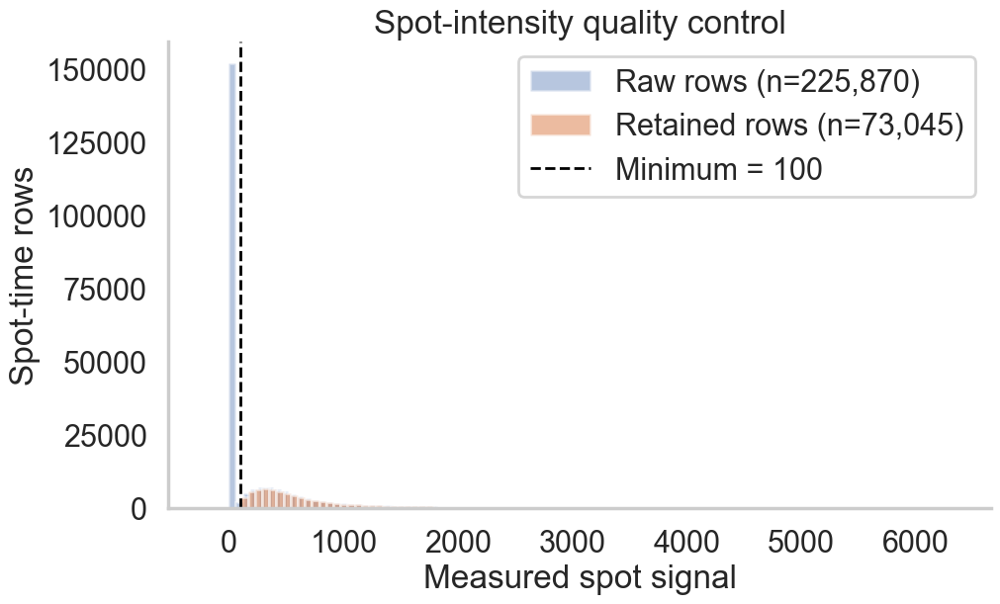

In [17]:
# CELL PURPOSE: Inspect the spot-intensity QC threshold and retained data.

# Match the plotting style used in the analysis notebook
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

if PLOT_SPOT_QC_HISTOGRAM:
    raw_signal = pd.to_numeric(
        spot_quant_df['signal'],
        errors='coerce',
    )
    raw_signal = raw_signal.loc[np.isfinite(raw_signal)]

    retained_signal = pd.to_numeric(
        spot_analysis_df['signal'],
        errors='coerce',
    )
    retained_signal = retained_signal.loc[np.isfinite(retained_signal)]

    fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)

    ax.hist(
        raw_signal,
        bins=SPOT_QC_HISTOGRAM_BINS,
        alpha=0.40,
        label=f'Raw rows (n={len(raw_signal):,})',
    )
    ax.hist(
        retained_signal,
        bins=SPOT_QC_HISTOGRAM_BINS,
        alpha=0.55,
        label=f'Retained rows (n={len(retained_signal):,})',
    )

    if SPOT_QC_MIN_SIGNAL is not None:
        ax.axvline(
            SPOT_QC_MIN_SIGNAL,
            color='black',
            linestyle='--',
            linewidth=2,
            label=f'Minimum = {SPOT_QC_MIN_SIGNAL:g}',
        )

    if SPOT_QC_MAX_SIGNAL is not None:
        ax.axvline(
            SPOT_QC_MAX_SIGNAL,
            color='black',
            linestyle=':',
            linewidth=2,
            label=f'Maximum = {SPOT_QC_MAX_SIGNAL:g}',
        )

    ax.set_xlabel('Measured spot signal')
    ax.set_ylabel('Spot-time rows')
    ax.set_title('Spot-intensity quality control')
    ax.legend(frameon=True)
    sns.despine(ax=ax)

    qc_figure_path = FIGURE_DIR / 'Spot_QC_Intensity_Histogram.png'
    fig.savefig(
        qc_figure_path,
        dpi=FIGURE_DPI,
        bbox_inches='tight',
    )
    print(f'Saved: {qc_figure_path}')
    plt.show()


## Part VII — Build per-cell HT runoff tables

For every cell and frame, the untracked data are summarized as spot count and total spot intensity:

\[
I_{\mathrm{total}}(t)=\sum_{i=1}^{N(t)} I_i(t).
\]


In [18]:
# CELL PURPOSE: Create per-cell spot-count and total-intensity curves.
CELL_KEYS = ['Experimental_Type', 'Replicate_Number', 'Experimental_Group', 'fov', 'Date', 'Cell_Number', 'Movie_ID']

def build_cell_time_runoff(frame: pd.DataFrame) -> pd.DataFrame:
    data = frame.copy()
    data['signal'] = pd.to_numeric(data['signal'], errors='coerce')
    data['t'] = pd.to_numeric(data['t'], errors='coerce')
    data = data.loc[np.isfinite(data['signal']) & (data['signal'] > 0)].copy()
    if 'n' not in data.columns:
        data['n'] = np.arange(len(data))
    return (data.groupby([*CELL_KEYS, 't'], dropna=False)
            .agg(spot_count=('n','nunique'), total_spot_intensity=('signal','sum'), mean_spot_intensity=('signal','mean'))
            .reset_index().sort_values([*CELL_KEYS,'t']).reset_index(drop=True))

cell_time_raw = build_cell_time_runoff(spot_analysis_df)
display(cell_time_raw.head())
print(f'Cell/time rows: {len(cell_time_raw):,}')


,Experimental_Type,Replicate_Number,Experimental_Group,fov,Date,Cell_Number,Movie_ID,t,spot_count,total_spot_intensity,mean_spot_intensity
0,No Nsp1,1,Control,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,2026-07-09,1,SARS_CTRL/20260709/20260709_3_1/Cell01_processed/Cell01_TRNL_Ch1.nc,0,54,15400.655172,285.197318
1,No Nsp1,1,Control,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,2026-07-09,1,SARS_CTRL/20260709/20260709_3_1/Cell01_processed/Cell01_TRNL_Ch1.nc,1,43,13700.517241,318.616680
2,No Nsp1,1,Control,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,2026-07-09,1,SARS_CTRL/20260709/20260709_3_1/Cell01_processed/Cell01_TRNL_Ch1.nc,2,50,15296.379310,305.927586
3,No Nsp1,1,Control,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,2026-07-09,1,SARS_CTRL/20260709/20260709_3_1/Cell01_processed/Cell01_TRNL_Ch1.nc,3,48,14148.103448,294.752155
4,No Nsp1,1,Control,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,2026-07-09,1,SARS_CTRL/20260709/20260709_3_1/Cell01_processed/Cell01_TRNL_Ch1.nc,4,60,16881.000000,281.350000


Cell/time rows: 2,544


In [19]:
# CELL PURPOSE:
# Detect and correct isolated catastrophic signal losses occurring only
# in the pre-HT baseline region.

def correct_isolated_baseline_dips_per_cell(
    frame: pd.DataFrame,
    metric: str = 'total_spot_intensity',
    baseline_end_exclusive_frame: int = BASELINE_END_EXCLUSIVE_FRAME,
    min_drop_fraction: float = 0.45,
    max_reference_relative_difference: float = 0.25,
    min_robust_z: float = 3.0,
    min_baseline_frames: int = 5,
    max_corrections_per_cell: int = 1,
    allow_edge_correction: bool = True,
    apply_correction: bool = True,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Detect and correct isolated catastrophic baseline dips per cell.

    Interior baseline frame
    -----------------------
    Expected value is the mean of the immediately preceding and
    immediately following baseline frames.

    First baseline frame
    --------------------
    When allow_edge_correction=True, expected value is the mean of
    the next two baseline frames.

    Last baseline frame
    -------------------
    When allow_edge_correction=True, expected value is the mean of
    the previous two baseline frames.

    A candidate is accepted only when:
      1. the target and reference frames are consecutive;
      2. both reference values are positive and finite;
      3. the two reference values agree;
      4. the target is substantially below their mean;
      5. the drop is large relative to robust baseline variability.

    Cells with more than max_corrections_per_cell candidates are not
    automatically modified and are flagged for manual review.
    """

    required_columns = {
        *CELL_KEYS,
        't',
        metric,
    }

    missing_columns = required_columns.difference(
        frame.columns
    )

    if missing_columns:
        raise KeyError(
            'Baseline-dip correction is missing columns:\n'
            f'{sorted(missing_columns)}'
        )

    # Baseline frames are t < baseline_end_exclusive_frame.
    corrected = frame.copy()

    corrected['t'] = pd.to_numeric(
        corrected['t'],
        errors='coerce',
    )

    corrected[metric] = pd.to_numeric(
        corrected[metric],
        errors='coerce',
    )

    # Preserve the value entering this correction step.
    before_column = (
        f'{metric}_before_baseline_dip_correction'
    )

    corrected[before_column] = corrected[metric]

    corrected['Baseline_Dip_Corrected'] = False
    corrected['Baseline_Dip_Correction_Method'] = ''
    corrected['Baseline_Dip_Original_Value'] = np.nan
    corrected['Baseline_Dip_Interpolated_Value'] = np.nan

    correction_records = []

    if not apply_correction:

        print(
            'Automatic baseline-dip correction is disabled.'
        )

        return (
            corrected,
            pd.DataFrame(),
        )

    for cell_keys, cell_group in corrected.groupby(
        CELL_KEYS,
        dropna=False,
    ):

        cell_metadata = dict(
            zip(
                CELL_KEYS,
                cell_keys,
            )
        )

        baseline = (
            cell_group.loc[
                (
                    cell_group['t']
                    < baseline_end_exclusive_frame
                )
                &
                np.isfinite(
                    cell_group[metric]
                )
            ]
            .sort_values('t')
            .copy()
        )

        if len(baseline) < min_baseline_frames:
            continue

        # One cell/time row is expected from build_cell_time_runoff().
        if baseline['t'].duplicated().any():

            correction_records.append({
                **cell_metadata,
                'Corrected_Frame': np.nan,
                'Reference_Frames': '',
                'Reference_Values': '',
                'Observed_Frame_Value': np.nan,
                'Interpolated_Frame_Value': np.nan,
                'Drop_Fraction': np.nan,
                'Reference_Relative_Difference': np.nan,
                'Robust_Z': np.nan,
                'Correction_Method': '',
                'Correction_Status': (
                    'Not corrected: duplicate baseline time points'
                ),
                'Needs_Manual_Review': True,
            })

            continue

        baseline_times = (
            baseline['t']
            .astype(int)
            .to_numpy()
        )

        baseline_values = (
            baseline[metric]
            .to_numpy(float)
        )

        candidates = []

        for position in range(
            len(baseline)
        ):

            target_frame = int(
                baseline_times[position]
            )

            target_value = float(
                baseline_values[position]
            )

            # ------------------------------------------------------
            # Select two nearby baseline reference frames.
            # ------------------------------------------------------

            if (
                position > 0
                and position < len(baseline) - 1
            ):

                reference_positions = (
                    position - 1,
                    position + 1,
                )

                correction_method = (
                    'Interior linear interpolation'
                )

                expected_reference_times = (
                    target_frame - 1,
                    target_frame + 1,
                )

            elif (
                position == 0
                and allow_edge_correction
                and len(baseline) >= 3
            ):

                reference_positions = (
                    1,
                    2,
                )

                correction_method = (
                    'First-frame two-point baseline mean'
                )

                expected_reference_times = (
                    target_frame + 1,
                    target_frame + 2,
                )

            elif (
                position == len(baseline) - 1
                and allow_edge_correction
                and len(baseline) >= 3
            ):

                reference_positions = (
                    len(baseline) - 3,
                    len(baseline) - 2,
                )

                correction_method = (
                    'Last-frame two-point baseline mean'
                )

                expected_reference_times = (
                    target_frame - 2,
                    target_frame - 1,
                )

            else:
                continue

            reference_times = tuple(
                int(
                    baseline_times[
                        reference_position
                    ]
                )
                for reference_position
                in reference_positions
            )

            # Do not bridge missing acquisition frames.
            if reference_times != expected_reference_times:
                continue

            reference_values = np.asarray(
                [
                    baseline_values[
                        reference_position
                    ]
                    for reference_position
                    in reference_positions
                ],
                dtype=float,
            )

            if (
                not np.all(
                    np.isfinite(
                        reference_values
                    )
                )
                or np.any(
                    reference_values <= 0
                )
                or not np.isfinite(
                    target_value
                )
            ):
                continue

            interpolated_value = float(
                reference_values.mean()
            )

            if interpolated_value <= 0:
                continue

            reference_relative_difference = (
                abs(
                    reference_values[0]
                    - reference_values[1]
                )
                / interpolated_value
            )

            # The two reference frames must look like two stable,
            # mutually consistent baseline measurements.
            if (
                reference_relative_difference
                > max_reference_relative_difference
            ):
                continue

            absolute_drop = (
                interpolated_value
                - target_value
            )

            drop_fraction = (
                absolute_drop
                / interpolated_value
            )

            if (
                absolute_drop <= 0
                or drop_fraction
                < min_drop_fraction
            ):
                continue

            # ------------------------------------------------------
            # Estimate ordinary baseline variability robustly.
            #
            # The candidate frame is omitted before calculating MAD.
            # ------------------------------------------------------

            comparison_values = np.delete(
                baseline_values,
                position,
            )

            comparison_values = comparison_values[
                np.isfinite(
                    comparison_values
                )
            ]

            baseline_median = float(
                np.median(
                    comparison_values
                )
            )

            baseline_mad = float(
                np.median(
                    np.abs(
                        comparison_values
                        - baseline_median
                    )
                )
            )

            robust_sigma = (
                1.4826
                * baseline_mad
            )

            if robust_sigma > 0:

                robust_z = (
                    absolute_drop
                    / robust_sigma
                )

            elif absolute_drop > 0:

                robust_z = np.inf

            else:

                robust_z = 0.0

            if robust_z < min_robust_z:
                continue

            candidates.append({
                'target_frame': target_frame,
                'target_value': target_value,
                'reference_frames': reference_times,
                'reference_values': tuple(
                    float(value)
                    for value in reference_values
                ),
                'interpolated_value': (
                    interpolated_value
                ),
                'drop_fraction': drop_fraction,
                'reference_relative_difference': (
                    reference_relative_difference
                ),
                'baseline_median': baseline_median,
                'baseline_mad': baseline_mad,
                'robust_z': robust_z,
                'correction_method': (
                    correction_method
                ),
            })

        # ----------------------------------------------------------
        # Multiple candidates are not automatically repaired.
        #
        # More than one bad baseline frame could represent a larger
        # acquisition failure rather than an isolated dropped frame.
        # ----------------------------------------------------------

        if (
            len(candidates)
            > max_corrections_per_cell
        ):

            for candidate in candidates:

                correction_records.append({
                    **cell_metadata,
                    'Corrected_Frame': (
                        candidate[
                            'target_frame'
                        ]
                    ),
                    'Reference_Frames': str(
                        candidate[
                            'reference_frames'
                        ]
                    ),
                    'Reference_Values': str(
                        candidate[
                            'reference_values'
                        ]
                    ),
                    'Observed_Frame_Value': (
                        candidate[
                            'target_value'
                        ]
                    ),
                    'Interpolated_Frame_Value': (
                        candidate[
                            'interpolated_value'
                        ]
                    ),
                    'Drop_Fraction': (
                        candidate[
                            'drop_fraction'
                        ]
                    ),
                    'Reference_Relative_Difference': (
                        candidate[
                            'reference_relative_difference'
                        ]
                    ),
                    'Robust_Z': (
                        candidate[
                            'robust_z'
                        ]
                    ),
                    'Correction_Method': (
                        candidate[
                            'correction_method'
                        ]
                    ),
                    'Correction_Status': (
                        'Not corrected: multiple candidate dips'
                    ),
                    'Needs_Manual_Review': True,
                })

            continue

        # ----------------------------------------------------------
        # Apply the isolated correction.
        # ----------------------------------------------------------

        for candidate in candidates:

            target_index = corrected.index[
                corrected.index.isin(
                    cell_group.index
                )
                &
                corrected['t'].eq(
                    candidate[
                        'target_frame'
                    ]
                )
            ]

            if len(target_index) != 1:

                correction_records.append({
                    **cell_metadata,
                    'Corrected_Frame': (
                        candidate[
                            'target_frame'
                        ]
                    ),
                    'Reference_Frames': str(
                        candidate[
                            'reference_frames'
                        ]
                    ),
                    'Reference_Values': str(
                        candidate[
                            'reference_values'
                        ]
                    ),
                    'Observed_Frame_Value': (
                        candidate[
                            'target_value'
                        ]
                    ),
                    'Interpolated_Frame_Value': (
                        candidate[
                            'interpolated_value'
                        ]
                    ),
                    'Drop_Fraction': (
                        candidate[
                            'drop_fraction'
                        ]
                    ),
                    'Reference_Relative_Difference': (
                        candidate[
                            'reference_relative_difference'
                        ]
                    ),
                    'Robust_Z': (
                        candidate[
                            'robust_z'
                        ]
                    ),
                    'Correction_Method': (
                        candidate[
                            'correction_method'
                        ]
                    ),
                    'Correction_Status': (
                        'Not corrected: target row was not unique'
                    ),
                    'Needs_Manual_Review': True,
                })

                continue

            corrected.loc[
                target_index,
                metric,
            ] = candidate[
                'interpolated_value'
            ]

            corrected.loc[
                target_index,
                'Baseline_Dip_Corrected',
            ] = True

            corrected.loc[
                target_index,
                'Baseline_Dip_Correction_Method',
            ] = candidate[
                'correction_method'
            ]

            corrected.loc[
                target_index,
                'Baseline_Dip_Original_Value',
            ] = candidate[
                'target_value'
            ]

            corrected.loc[
                target_index,
                'Baseline_Dip_Interpolated_Value',
            ] = candidate[
                'interpolated_value'
            ]

            correction_records.append({
                **cell_metadata,
                'Corrected_Frame': (
                    candidate[
                        'target_frame'
                    ]
                ),
                'Reference_Frames': str(
                    candidate[
                        'reference_frames'
                    ]
                ),
                'Reference_Values': str(
                    candidate[
                        'reference_values'
                    ]
                ),
                'Observed_Frame_Value': (
                    candidate[
                        'target_value'
                    ]
                ),
                'Interpolated_Frame_Value': (
                    candidate[
                        'interpolated_value'
                    ]
                ),
                'Drop_Fraction': (
                    candidate[
                        'drop_fraction'
                    ]
                ),
                'Reference_Relative_Difference': (
                    candidate[
                        'reference_relative_difference'
                    ]
                ),
                'Robust_Z': (
                    candidate[
                        'robust_z'
                    ]
                ),
                'Correction_Method': (
                    candidate[
                        'correction_method'
                    ]
                ),
                'Correction_Status': 'Corrected',
                'Needs_Manual_Review': False,
            })

    correction_log = pd.DataFrame(
        correction_records
    )

    return (
        corrected,
        correction_log,
    )
    


In [20]:
# CELL PURPOSE:
# Correct consecutive out-of-focus baseline frames specifically in
# Control +Nsp1 cells using reliable frames 0 and 4 as anchors.


def correct_control_nsp1_multiframe_baseline_dips(
    frame: pd.DataFrame,
    metric: str = 'total_spot_intensity',
    experimental_group: str = 'Control',
    experimental_type: str = 'Nsp1',
    reference_frames: tuple = (0, 4),
    interior_frames: tuple = (1, 2, 3),
    min_bad_interior_frames: int = 2,
    activation_drop_fraction: float = 0.20,
    correction_drop_fraction: float = 0.10,
    max_reference_relative_difference: float = 0.25,
    apply_correction: bool = True,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Correct multi-frame baseline signal loss only in Control +Nsp1 cells.

    Frames 0 and 4 are treated as protected reference anchors. Expected
    values for frames 1-3 are calculated by linear interpolation between
    those anchors.

    The correction is activated only when at least
    `min_bad_interior_frames` are lower than expectation by
    `activation_drop_fraction` or more.

    Once activated, every interior frame lower than expectation by
    `correction_drop_fraction` or more is replaced. This allows a third
    moderately affected frame to be corrected without making the event
    detection itself overly permissive.
    """

    required_columns = {
        *CELL_KEYS,
        'Experimental_Group',
        'Experimental_Type',
        't',
        metric,
    }

    missing_columns = required_columns.difference(
        frame.columns
    )

    if missing_columns:
        raise KeyError(
            'Control Nsp1 multi-frame correction is missing columns:\n'
            f'{sorted(missing_columns)}'
        )

    if not (
        0
        <= correction_drop_fraction
        <= activation_drop_fraction
    ):
        raise ValueError(
            'correction_drop_fraction must be between 0 and '
            'activation_drop_fraction.'
        )

    corrected = frame.copy()

    corrected['t'] = pd.to_numeric(
        corrected['t'],
        errors='coerce',
    )

    corrected[metric] = pd.to_numeric(
        corrected[metric],
        errors='coerce',
    ).astype(float)

    reference_frames = tuple(
        sorted(
            int(value)
            for value in reference_frames
        )
    )

    interior_frames = tuple(
        sorted(
            int(value)
            for value in interior_frames
        )
    )

    if len(reference_frames) != 2:
        raise ValueError(
            'CONTROL_NSP1_REFERENCE_FRAMES must contain exactly '
            'two frames.'
        )

    left_frame, right_frame = reference_frames

    invalid_interior_frames = [
        frame_number
        for frame_number in interior_frames
        if not (
            left_frame
            < frame_number
            < right_frame
        )
    ]

    if invalid_interior_frames:
        raise ValueError(
            'Interior frames must occur between the reference frames:\n'
            f'{invalid_interior_frames}'
        )

    # The general correction function stores the original values here.
    # Use those original measurements to determine whether a multi-frame
    # failure occurred, even if the general pass changed one interior frame.
    before_column = (
        f'{metric}_before_baseline_dip_correction'
    )

    detection_column = (
        before_column
        if before_column in corrected.columns
        else metric
    )

    correction_metadata_defaults = {
        'Baseline_Dip_Corrected': False,
        'Baseline_Dip_Correction_Method': '',
        'Baseline_Dip_Original_Value': np.nan,
        'Baseline_Dip_Interpolated_Value': np.nan,
        'Baseline_Dip_Correction_Pass': '',
    }

    for column, default_value in (
        correction_metadata_defaults.items()
    ):
        if column not in corrected.columns:
            corrected[column] = default_value

    records = []

    targeted_mask = (
        corrected[
            'Experimental_Group'
        ].astype(str).eq(
            str(experimental_group)
        )
        &
        corrected[
            'Experimental_Type'
        ].astype(str).eq(
            str(experimental_type)
        )
    )

    targeted_data = corrected.loc[
        targeted_mask
    ]

    if not apply_correction:
        print(
            'Targeted Control Nsp1 multi-frame correction is disabled.'
        )

        return (
            corrected,
            pd.DataFrame(),
        )

    for cell_keys, cell_group in targeted_data.groupby(
        CELL_KEYS,
        dropna=False,
    ):

        metadata = dict(
            zip(
                CELL_KEYS,
                cell_keys,
            )
        )

        relevant_frames = (
            cell_group.loc[
                cell_group['t'].isin(
                    [
                        *reference_frames,
                        *interior_frames,
                    ]
                )
            ]
            .sort_values('t')
            .copy()
        )

        base_record = {
            **metadata,
            'Reference_Frames': str(
                reference_frames
            ),
            'Correction_Method': (
                'Control Nsp1 frame-0-to-frame-4 interpolation'
            ),
            'Correction_Pass': (
                'Targeted Control Nsp1 multi-frame'
            ),
        }

        if relevant_frames['t'].duplicated().any():

            records.append({
                **base_record,
                'Corrected_Frame': np.nan,
                'Reference_Values': '',
                'Observed_Frame_Value': np.nan,
                'Interpolated_Frame_Value': np.nan,
                'Drop_Fraction': np.nan,
                'Reference_Relative_Difference': np.nan,
                'Primary_Bad_Frames': '',
                'Frames_Selected_For_Correction': '',
                'Interior_Drop_Fractions': '',
                'Correction_Status': (
                    'Not corrected: duplicate baseline time points'
                ),
                'Needs_Manual_Review': True,
            })

            continue

        value_by_time = (
            relevant_frames
            .set_index('t')[
                detection_column
            ]
            .to_dict()
        )

        required_frames = [
            *reference_frames,
            *interior_frames,
        ]

        missing_required_frames = [
            frame_number
            for frame_number in required_frames
            if frame_number not in value_by_time
        ]

        if missing_required_frames:

            records.append({
                **base_record,
                'Corrected_Frame': np.nan,
                'Reference_Values': '',
                'Observed_Frame_Value': np.nan,
                'Interpolated_Frame_Value': np.nan,
                'Drop_Fraction': np.nan,
                'Reference_Relative_Difference': np.nan,
                'Primary_Bad_Frames': '',
                'Frames_Selected_For_Correction': '',
                'Interior_Drop_Fractions': '',
                'Correction_Status': (
                    'Not corrected: missing required frames '
                    f'{missing_required_frames}'
                ),
                'Needs_Manual_Review': True,
            })

            continue

        left_value = float(
            value_by_time[
                left_frame
            ]
        )

        right_value = float(
            value_by_time[
                right_frame
            ]
        )

        reference_values = np.asarray(
            [
                left_value,
                right_value,
            ],
            dtype=float,
        )

        if (
            not np.all(
                np.isfinite(
                    reference_values
                )
            )
            or np.any(
                reference_values <= 0
            )
        ):

            records.append({
                **base_record,
                'Corrected_Frame': np.nan,
                'Reference_Values': str(
                    tuple(reference_values)
                ),
                'Observed_Frame_Value': np.nan,
                'Interpolated_Frame_Value': np.nan,
                'Drop_Fraction': np.nan,
                'Reference_Relative_Difference': np.nan,
                'Primary_Bad_Frames': '',
                'Frames_Selected_For_Correction': '',
                'Interior_Drop_Fractions': '',
                'Correction_Status': (
                    'Not corrected: invalid reference values'
                ),
                'Needs_Manual_Review': True,
            })

            continue

        reference_mean = float(
            reference_values.mean()
        )

        reference_relative_difference = (
            abs(
                left_value
                - right_value
            )
            / reference_mean
        )

        if (
            reference_relative_difference
            > max_reference_relative_difference
        ):

            records.append({
                **base_record,
                'Corrected_Frame': np.nan,
                'Reference_Values': str(
                    tuple(reference_values)
                ),
                'Observed_Frame_Value': np.nan,
                'Interpolated_Frame_Value': np.nan,
                'Drop_Fraction': np.nan,
                'Reference_Relative_Difference': (
                    reference_relative_difference
                ),
                'Primary_Bad_Frames': '',
                'Frames_Selected_For_Correction': '',
                'Interior_Drop_Fractions': '',
                'Correction_Status': (
                    'Not corrected: reference frames do not agree'
                ),
                'Needs_Manual_Review': True,
            })

            continue

        interior_diagnostics = []

        for target_frame in interior_frames:

            observed_value = float(
                value_by_time[
                    target_frame
                ]
            )

            interpolation_fraction = (
                (
                    target_frame
                    - left_frame
                )
                /
                (
                    right_frame
                    - left_frame
                )
            )

            expected_value = (
                left_value
                + interpolation_fraction
                * (
                    right_value
                    - left_value
                )
            )

            if (
                not np.isfinite(
                    observed_value
                )
                or not np.isfinite(
                    expected_value
                )
                or expected_value <= 0
            ):
                drop_fraction = np.nan

            else:
                drop_fraction = (
                    expected_value
                    - observed_value
                ) / expected_value

            interior_diagnostics.append({
                'target_frame': target_frame,
                'observed_value': observed_value,
                'expected_value': expected_value,
                'drop_fraction': drop_fraction,
            })

        # Frames that establish a clear multi-frame failure.
        primary_bad_frames = [
            item['target_frame']
            for item in interior_diagnostics
            if (
                np.isfinite(
                    item['drop_fraction']
                )
                and item['drop_fraction']
                >= activation_drop_fraction
            )
        ]

        # Frames corrected after the event is activated.
        correction_candidates = [
            item
            for item in interior_diagnostics
            if (
                np.isfinite(
                    item['drop_fraction']
                )
                and item['drop_fraction']
                >= correction_drop_fraction
            )
        ]

        drop_summary = {
            item['target_frame']: (
                None
                if not np.isfinite(
                    item['drop_fraction']
                )
                else round(
                    float(
                        item['drop_fraction']
                    ),
                    4,
                )
            )
            for item in interior_diagnostics
        }

        if (
            len(primary_bad_frames)
            < min_bad_interior_frames
        ):

            records.append({
                **base_record,
                'Corrected_Frame': np.nan,
                'Reference_Values': str(
                    tuple(reference_values)
                ),
                'Observed_Frame_Value': np.nan,
                'Interpolated_Frame_Value': np.nan,
                'Drop_Fraction': np.nan,
                'Reference_Relative_Difference': (
                    reference_relative_difference
                ),
                'Primary_Bad_Frames': str(
                    tuple(primary_bad_frames)
                ),
                'Frames_Selected_For_Correction': '',
                'Interior_Drop_Fractions': str(
                    drop_summary
                ),
                'Correction_Status': (
                    'No multi-frame event detected'
                ),
                'Needs_Manual_Review': False,
            })

            continue

        selected_frames = tuple(
            item['target_frame']
            for item in correction_candidates
        )

        for item in correction_candidates:

            target_indices = cell_group.index[
                cell_group['t'].eq(
                    item['target_frame']
                )
            ]

            if len(target_indices) != 1:

                records.append({
                    **base_record,
                    'Corrected_Frame': (
                        item[
                            'target_frame'
                        ]
                    ),
                    'Reference_Values': str(
                        tuple(reference_values)
                    ),
                    'Observed_Frame_Value': (
                        item[
                            'observed_value'
                        ]
                    ),
                    'Interpolated_Frame_Value': (
                        item[
                            'expected_value'
                        ]
                    ),
                    'Drop_Fraction': (
                        item[
                            'drop_fraction'
                        ]
                    ),
                    'Reference_Relative_Difference': (
                        reference_relative_difference
                    ),
                    'Primary_Bad_Frames': str(
                        tuple(
                            primary_bad_frames
                        )
                    ),
                    'Frames_Selected_For_Correction': str(
                        selected_frames
                    ),
                    'Interior_Drop_Fractions': str(
                        drop_summary
                    ),
                    'Correction_Status': (
                        'Not corrected: target row was not unique'
                    ),
                    'Needs_Manual_Review': True,
                })

                continue

            target_index = target_indices[0]

            corrected.loc[
                target_index,
                metric,
            ] = item[
                'expected_value'
            ]

            corrected.loc[
                target_index,
                'Baseline_Dip_Corrected',
            ] = True

            corrected.loc[
                target_index,
                'Baseline_Dip_Correction_Method',
            ] = base_record[
                'Correction_Method'
            ]

            corrected.loc[
                target_index,
                'Baseline_Dip_Correction_Pass',
            ] = base_record[
                'Correction_Pass'
            ]

            corrected.loc[
                target_index,
                'Baseline_Dip_Original_Value',
            ] = item[
                'observed_value'
            ]

            corrected.loc[
                target_index,
                'Baseline_Dip_Interpolated_Value',
            ] = item[
                'expected_value'
            ]

            records.append({
                **base_record,
                'Corrected_Frame': (
                    item[
                        'target_frame'
                    ]
                ),
                'Reference_Values': str(
                    tuple(reference_values)
                ),
                'Observed_Frame_Value': (
                    item[
                        'observed_value'
                    ]
                ),
                'Interpolated_Frame_Value': (
                    item[
                        'expected_value'
                    ]
                ),
                'Drop_Fraction': (
                    item[
                        'drop_fraction'
                    ]
                ),
                'Reference_Relative_Difference': (
                    reference_relative_difference
                ),
                'Primary_Bad_Frames': str(
                    tuple(
                        primary_bad_frames
                    )
                ),
                'Frames_Selected_For_Correction': str(
                    selected_frames
                ),
                'Interior_Drop_Fractions': str(
                    drop_summary
                ),
                'Correction_Status': 'Corrected',
                'Needs_Manual_Review': False,
            })

    return (
        corrected,
        pd.DataFrame(
            records
        ),
    )

In [21]:
# CELL PURPOSE:
# Apply the general isolated-dip correction, protect the Control +Nsp1
# reference anchors, and then apply the targeted multi-frame correction.


# Preserve the completely uncorrected cell/time table.
cell_time_uncorrected = (
    cell_time_raw.copy(
        deep=True
    )
)


# ------------------------------------------------------------------
# Pass 1: general isolated single-frame correction
# ------------------------------------------------------------------

(
    cell_time_after_isolated_correction,
    isolated_baseline_dip_log,
) = correct_isolated_baseline_dips_per_cell(
    frame=cell_time_raw,
    metric=BASELINE_DIP_METRIC,
    baseline_end_exclusive_frame=BASELINE_END_EXCLUSIVE_FRAME,
    min_drop_fraction=(
        BASELINE_DIP_MIN_DROP_FRACTION
    ),
    max_reference_relative_difference=(
        BASELINE_DIP_MAX_REFERENCE_RELATIVE_DIFFERENCE
    ),
    min_robust_z=(
        BASELINE_DIP_MIN_ROBUST_Z
    ),
    min_baseline_frames=(
        BASELINE_DIP_MIN_BASELINE_FRAMES
    ),
    max_corrections_per_cell=(
        BASELINE_DIP_MAX_CORRECTIONS_PER_CELL
    ),
    allow_edge_correction=(
        BASELINE_DIP_ALLOW_EDGE_CORRECTION
    ),
    apply_correction=(
        AUTO_CORRECT_BASELINE_DIPS
    ),
)


if (
    'Baseline_Dip_Correction_Pass'
    not in cell_time_after_isolated_correction.columns
):
    cell_time_after_isolated_correction[
        'Baseline_Dip_Correction_Pass'
    ] = ''


isolated_corrected_mask = (
    cell_time_after_isolated_correction[
        'Baseline_Dip_Corrected'
    ].fillna(False)
)


cell_time_after_isolated_correction.loc[
    isolated_corrected_mask,
    'Baseline_Dip_Correction_Pass',
] = 'General isolated baseline dip'


if isolated_baseline_dip_log is None:
    isolated_baseline_dip_log = pd.DataFrame()


if not isolated_baseline_dip_log.empty:

    isolated_baseline_dip_log = (
        isolated_baseline_dip_log.copy()
    )

    isolated_baseline_dip_log[
        'Correction_Pass'
    ] = 'General isolated baseline dip'


# ------------------------------------------------------------------
# Protect frames 0 and 4 in Control +Nsp1.
#
# The targeted correction assumes these frames are reliable anchors.
# If the general detector changed either anchor, restore its original
# value and mark that general-log entry as reverted.
# ------------------------------------------------------------------

control_nsp1_anchor_mask = (
    cell_time_after_isolated_correction[
        'Experimental_Group'
    ].astype(str).eq(
        str(
            CONTROL_NSP1_CORRECTION_GROUP
        )
    )
    &
    cell_time_after_isolated_correction[
        'Experimental_Type'
    ].astype(str).eq(
        str(
            CONTROL_NSP1_CORRECTION_TYPE
        )
    )
    &
    cell_time_after_isolated_correction[
        't'
    ].isin(
        CONTROL_NSP1_REFERENCE_FRAMES
    )
)


restored_anchor_count = int(
    (
        control_nsp1_anchor_mask
        &
        cell_time_after_isolated_correction[
            'Baseline_Dip_Corrected'
        ].fillna(False)
    ).sum()
)


cell_time_after_isolated_correction.loc[
    control_nsp1_anchor_mask,
    BASELINE_DIP_METRIC,
] = cell_time_uncorrected.loc[
    control_nsp1_anchor_mask,
    BASELINE_DIP_METRIC,
].to_numpy()


cell_time_after_isolated_correction.loc[
    control_nsp1_anchor_mask,
    'Baseline_Dip_Corrected',
] = False

cell_time_after_isolated_correction.loc[
    control_nsp1_anchor_mask,
    'Baseline_Dip_Correction_Method',
] = ''

cell_time_after_isolated_correction.loc[
    control_nsp1_anchor_mask,
    'Baseline_Dip_Correction_Pass',
] = ''

cell_time_after_isolated_correction.loc[
    control_nsp1_anchor_mask,
    'Baseline_Dip_Original_Value',
] = np.nan

cell_time_after_isolated_correction.loc[
    control_nsp1_anchor_mask,
    'Baseline_Dip_Interpolated_Value',
] = np.nan


if not isolated_baseline_dip_log.empty:

    reverted_anchor_log_mask = (
        isolated_baseline_dip_log[
            'Experimental_Group'
        ].astype(str).eq(
            str(
                CONTROL_NSP1_CORRECTION_GROUP
            )
        )
        &
        isolated_baseline_dip_log[
            'Experimental_Type'
        ].astype(str).eq(
            str(
                CONTROL_NSP1_CORRECTION_TYPE
            )
        )
        &
        pd.to_numeric(
            isolated_baseline_dip_log[
                'Corrected_Frame'
            ],
            errors='coerce',
        ).isin(
            CONTROL_NSP1_REFERENCE_FRAMES
        )
        &
        isolated_baseline_dip_log[
            'Correction_Status'
        ].eq('Corrected')
    )

    isolated_baseline_dip_log.loc[
        reverted_anchor_log_mask,
        'Correction_Status',
    ] = (
        'Reverted: protected Control Nsp1 reference frame'
    )

    isolated_baseline_dip_log.loc[
        reverted_anchor_log_mask,
        'Needs_Manual_Review',
    ] = False


# ------------------------------------------------------------------
# Pass 2: targeted Control +Nsp1 multi-frame correction
# ------------------------------------------------------------------

(
    cell_time_raw,
    control_nsp1_multiframe_log,
) = correct_control_nsp1_multiframe_baseline_dips(
    frame=cell_time_after_isolated_correction,
    metric=BASELINE_DIP_METRIC,
    experimental_group=(
        CONTROL_NSP1_CORRECTION_GROUP
    ),
    experimental_type=(
        CONTROL_NSP1_CORRECTION_TYPE
    ),
    reference_frames=(
        CONTROL_NSP1_REFERENCE_FRAMES
    ),
    interior_frames=(
        CONTROL_NSP1_INTERIOR_FRAMES
    ),
    min_bad_interior_frames=(
        CONTROL_NSP1_MIN_BAD_INTERIOR_FRAMES
    ),
    activation_drop_fraction=(
        CONTROL_NSP1_MIN_DROP_FRACTION
    ),
    correction_drop_fraction=(
        CONTROL_NSP1_SECONDARY_DROP_FRACTION
    ),
    max_reference_relative_difference=(
        CONTROL_NSP1_MAX_REFERENCE_RELATIVE_DIFFERENCE
    ),
    apply_correction=(
        CONTROL_NSP1_MULTI_FRAME_CORRECTION
    ),
)


if control_nsp1_multiframe_log is None:
    control_nsp1_multiframe_log = pd.DataFrame()


# ------------------------------------------------------------------
# Mark general corrections superseded by the targeted pass.
# ------------------------------------------------------------------

if (
    not isolated_baseline_dip_log.empty
    and not control_nsp1_multiframe_log.empty
):

    targeted_corrected_rows = (
        control_nsp1_multiframe_log.loc[
            control_nsp1_multiframe_log[
                'Correction_Status'
            ].eq('Corrected'),
            [
                'fov',
                'Corrected_Frame',
            ],
        ]
        .dropna()
        .copy()
    )

    targeted_corrected_pairs = {
        (
            str(row.fov),
            int(row.Corrected_Frame),
        )
        for row
        in targeted_corrected_rows.itertuples()
    }

    if targeted_corrected_pairs:

        def correction_was_superseded(
            row,
        ):
            """
            Test whether an earlier general correction was replaced by
            the targeted Control +Nsp1 correction.
            """

            corrected_frame = row.get(
                'Corrected_Frame',
                np.nan,
            )

            if pd.isna(corrected_frame):
                return False

            return (
                str(
                    row.get('fov')
                ),
                int(corrected_frame),
            ) in targeted_corrected_pairs


        superseded_mask = (
            isolated_baseline_dip_log.apply(
                correction_was_superseded,
                axis=1,
            )
            &
            isolated_baseline_dip_log[
                'Correction_Status'
            ].eq('Corrected')
        )

        isolated_baseline_dip_log.loc[
            superseded_mask,
            'Correction_Status',
        ] = (
            'Superseded by targeted Control Nsp1 correction'
        )

        isolated_baseline_dip_log.loc[
            superseded_mask,
            'Needs_Manual_Review',
        ] = False


# ------------------------------------------------------------------
# Validate that targeted corrections occurred only where intended.
# ------------------------------------------------------------------

targeted_corrected_row_mask = (
    cell_time_raw[
        'Baseline_Dip_Correction_Pass'
    ].eq(
        'Targeted Control Nsp1 multi-frame'
    )
    &
    cell_time_raw[
        'Baseline_Dip_Corrected'
    ].fillna(False)
)


if targeted_corrected_row_mask.any():

    invalid_targeted_rows = cell_time_raw.loc[
        targeted_corrected_row_mask
        &
        (
            ~cell_time_raw[
                'Experimental_Group'
            ].astype(str).eq(
                str(
                    CONTROL_NSP1_CORRECTION_GROUP
                )
            )
            |
            ~cell_time_raw[
                'Experimental_Type'
            ].astype(str).eq(
                str(
                    CONTROL_NSP1_CORRECTION_TYPE
                )
            )
            |
            ~cell_time_raw[
                't'
            ].isin(
                CONTROL_NSP1_INTERIOR_FRAMES
            )
        )
    ]

    if not invalid_targeted_rows.empty:
        raise RuntimeError(
            'The targeted multi-frame pass modified rows outside '
            'Control +Nsp1 frames 1-3.'
        )


# Confirm that Control +Nsp1 frames 0 and 4 remained unchanged.
protected_anchor_after = (
    cell_time_raw.loc[
        control_nsp1_anchor_mask,
        BASELINE_DIP_METRIC,
    ]
)

protected_anchor_before = (
    cell_time_uncorrected.loc[
        control_nsp1_anchor_mask,
        BASELINE_DIP_METRIC,
    ]
)


if not np.allclose(
    protected_anchor_after.to_numpy(
        dtype=float
    ),
    protected_anchor_before.to_numpy(
        dtype=float
    ),
    equal_nan=True,
):
    raise RuntimeError(
        'Protected Control +Nsp1 reference frames were modified.'
    )


# ------------------------------------------------------------------
# Combine both correction logs.
# ------------------------------------------------------------------

correction_log_parts = [
    log
    for log in [
        isolated_baseline_dip_log,
        control_nsp1_multiframe_log,
    ]
    if (
        log is not None
        and not log.empty
    )
]


if correction_log_parts:

    baseline_dip_correction_log = pd.concat(
        correction_log_parts,
        ignore_index=True,
        sort=False,
    )

else:

    baseline_dip_correction_log = pd.DataFrame()


# ------------------------------------------------------------------
# Recreate all downstream correction summaries in this run.
# ------------------------------------------------------------------

if baseline_dip_correction_log.empty:

    corrected_baseline_dips = pd.DataFrame()
    baseline_dip_manual_review = pd.DataFrame()

else:

    corrected_baseline_dips = (
        baseline_dip_correction_log.loc[
            baseline_dip_correction_log[
                'Correction_Status'
            ].eq('Corrected')
        ]
        .copy()
    )

    baseline_dip_manual_review = (
        baseline_dip_correction_log.loc[
            baseline_dip_correction_log[
                'Needs_Manual_Review'
            ].fillna(False)
        ]
        .copy()
    )


targeted_multiframe_corrections = (
    corrected_baseline_dips.loc[
        corrected_baseline_dips[
            'Correction_Pass'
        ].eq(
            'Targeted Control Nsp1 multi-frame'
        )
    ]
    .copy()
    if not corrected_baseline_dips.empty
    else pd.DataFrame()
)


targeted_multiframe_diagnostics = (
    control_nsp1_multiframe_log.copy()
)


# ------------------------------------------------------------------
# Confirm that final correction flags and final log entries agree.
# ------------------------------------------------------------------

final_corrected_rows = (
    cell_time_raw.loc[
        cell_time_raw[
            'Baseline_Dip_Corrected'
        ].fillna(False),
        [
            'fov',
            't',
        ],
    ]
    .copy()
)


final_corrected_pairs = {
    (
        str(row.fov),
        int(row.t),
    )
    for row
    in final_corrected_rows.itertuples()
}


if corrected_baseline_dips.empty:

    logged_corrected_pairs = set()

else:

    logged_corrected_pairs = {
        (
            str(row.fov),
            int(row.Corrected_Frame),
        )
        for row
        in corrected_baseline_dips[
            [
                'fov',
                'Corrected_Frame',
            ]
        ]
        .dropna()
        .itertuples()
    }


if final_corrected_pairs != logged_corrected_pairs:
    raise RuntimeError(
        'The correction flags in cell_time_raw do not match the '
        'final correction log.'
    )


# ------------------------------------------------------------------
# Report and save.
# ------------------------------------------------------------------

print('\nAutomatic baseline-dip correction')
print('---------------------------------')
print(
    f'Metric: {BASELINE_DIP_METRIC}'
)
print(
    f'Baseline frames: t < {BASELINE_END_EXCLUSIVE_FRAME} (frames 0-4)'
)
print(
    'General minimum drop: '
    f'{BASELINE_DIP_MIN_DROP_FRACTION:.0%}'
)
print(
    'Targeted Control +Nsp1 activation drop: '
    f'{CONTROL_NSP1_MIN_DROP_FRACTION:.0%}'
)
print(
    'Targeted Control +Nsp1 secondary correction drop: '
    f'{CONTROL_NSP1_SECONDARY_DROP_FRACTION:.0%}'
)
print(
    'Protected Control +Nsp1 anchors restored: '
    f'{restored_anchor_count:,}'
)
print(
    'Final corrected frames: '
    f'{len(corrected_baseline_dips):,}'
)
print(
    'Targeted Control +Nsp1 corrected frames: '
    f'{len(targeted_multiframe_corrections):,}'
)
print(
    'Rows requiring manual review: '
    f'{len(baseline_dip_manual_review):,}'
)


save_table(
    baseline_dip_correction_log,
    'tethered_ht_automatic_baseline_dip_correction_log',
)

save_table(
    corrected_baseline_dips,
    'tethered_ht_automatic_baseline_dips_corrected',
)

save_table(
    baseline_dip_manual_review,
    'tethered_ht_baseline_dips_needing_manual_review',
)

save_table(
    targeted_multiframe_diagnostics,
    'tethered_ht_control_nsp1_multiframe_diagnostics',
)


if not corrected_baseline_dips.empty:

    corrected_summary = (
        corrected_baseline_dips
        .groupby(
            [
                'Experimental_Group',
                'Experimental_Type',
                'Replicate_Number',
                'Correction_Pass',
            ],
            dropna=False,
        )
        .size()
        .rename(
            'n_corrected_frames'
        )
        .reset_index()
    )

    display(
        corrected_summary
    )


if not targeted_multiframe_diagnostics.empty:

    print(
        '\nControl +Nsp1 targeted diagnostic summary'
    )

    targeted_status_summary = (
        targeted_multiframe_diagnostics
        .groupby(
            'Correction_Status',
            dropna=False,
        )
        .size()
        .rename('n_rows')
        .reset_index()
    )

    display(
        targeted_status_summary
    )

    targeted_display_columns = [
        column
        for column in [
            'Replicate_Number',
            'Cell_Number',
            'fov',
            'Corrected_Frame',
            'Reference_Values',
            'Reference_Relative_Difference',
            'Primary_Bad_Frames',
            'Frames_Selected_For_Correction',
            'Interior_Drop_Fractions',
            'Correction_Status',
            'Needs_Manual_Review',
        ]
        if column
        in targeted_multiframe_diagnostics.columns
    ]

    display(
        targeted_multiframe_diagnostics[
            targeted_display_columns
        ]
        .sort_values(
            [
                'Replicate_Number',
                'Cell_Number',
                'Corrected_Frame',
            ],
            na_position='last',
        )
    )


if not baseline_dip_manual_review.empty:

    print(
        '\nThe following rows were not automatically corrected and '
        'should be examined in the manual cell-QC interface:'
    )

    display(
        baseline_dip_manual_review
    )


Automatic baseline-dip correction
---------------------------------
Metric: total_spot_intensity
Baseline frames: t < 5 (frames 0-4)
General minimum drop: 25%
Targeted Control +Nsp1 activation drop: 20%
Targeted Control +Nsp1 secondary correction drop: 10%
Protected Control +Nsp1 anchors restored: 1
Final corrected frames: 12
Targeted Control +Nsp1 corrected frames: 6
Rows requiring manual review: 5
Parquet unavailable for tethered_ht_automatic_baseline_dip_correction_log: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.
Saved: Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tether

,Experimental_Group,Experimental_Type,Replicate_Number,Correction_Pass,n_corrected_frames
0,Control,No Nsp1,1,General isolated baseline dip,1
1,Control,No Nsp1,2,General isolated baseline dip,1
2,Control,Nsp1,1,Targeted Control Nsp1 multi-frame,6
3,SARS_3'UTR,No Nsp1,2,General isolated baseline dip,1
4,SARS_5'UTR,No Nsp1,1,General isolated baseline dip,1
5,SARS_5'UTR,No Nsp1,2,General isolated baseline dip,1
6,SARS_5'UTR,Nsp1,1,General isolated baseline dip,1



Control +Nsp1 targeted diagnostic summary


,Correction_Status,n_rows
0,Corrected,6
1,No multi-frame event detected,4
2,Not corrected: reference frames do not agree,5


,Replicate_Number,Cell_Number,fov,Corrected_Frame,Reference_Values,Reference_Relative_Difference,Primary_Bad_Frames,Frames_Selected_For_Correction,Interior_Drop_Fractions,Correction_Status,Needs_Manual_Review
0,1,1,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell01_processed_Cell01_TRNL_Ch1_nc,NaN,"(88135.05172413793, 28449.46551724138)",1.023902,,,,Not corrected: reference frames do not agree,True
1,1,2,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell02_processed_Cell02_TRNL_Ch1_nc,1.0,"(22353.44827586207, 18053.06896551724)",0.212856,"(1, 2, 3)","(1, 2, 3)","{1: 0.409, 2: 0.8221, 3: 0.2794}",Corrected,False
2,1,2,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell02_processed_Cell02_TRNL_Ch1_nc,2.0,"(22353.44827586207, 18053.06896551724)",0.212856,"(1, 2, 3)","(1, 2, 3)","{1: 0.409, 2: 0.8221, 3: 0.2794}",Corrected,False
3,1,2,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell02_processed_Cell02_TRNL_Ch1_nc,3.0,"(22353.44827586207, 18053.06896551724)",0.212856,"(1, 2, 3)","(1, 2, 3)","{1: 0.409, 2: 0.8221, 3: 0.2794}",Corrected,False
4,1,3,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell03_processed_Cell03_TRNL_Ch1_nc,NaN,"(10816.706896551725, 33958.60344827586)",1.033690,,,,Not corrected: reference frames do not agree,True
5,1,4,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell04_processed_Cell04_TRNL_Ch1_nc,1.0,"(30456.689655172413, 26443.293103448275)",0.141068,"(1, 2, 3)","(1, 2, 3)","{1: 0.3045, 2: 0.7153, 3: 0.8223}",Corrected,False
6,1,4,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell04_processed_Cell04_TRNL_Ch1_nc,2.0,"(30456.689655172413, 26443.293103448275)",0.141068,"(1, 2, 3)","(1, 2, 3)","{1: 0.3045, 2: 0.7153, 3: 0.8223}",Corrected,False
7,1,4,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell04_processed_Cell04_TRNL_Ch1_nc,3.0,"(30456.689655172413, 26443.293103448275)",0.141068,"(1, 2, 3)","(1, 2, 3)","{1: 0.3045, 2: 0.7153, 3: 0.8223}",Corrected,False
8,1,5,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell05_processed_Cell05_TRNL_Ch1_nc,NaN,"(43071.91379310345, 26231.8275862069)",0.485979,,,,Not corrected: reference frames do not agree,True
9,2,1,Nsp1_SARS_CTRL_20260716_20260716_2_1_Cell01_processed_Cell01_TRNL_Ch1_nc,NaN,"(60923.8275862069, 74031.79310344828)",0.194256,(),,"{1: -0.322, 2: -0.2246, 3: -0.1936}",No multi-frame event detected,False



The following rows were not automatically corrected and should be examined in the manual cell-QC interface:


,Experimental_Type,Replicate_Number,Experimental_Group,fov,Date,Cell_Number,Movie_ID,Corrected_Frame,Reference_Frames,Reference_Values,Observed_Frame_Value,Interpolated_Frame_Value,Drop_Fraction,Reference_Relative_Difference,Robust_Z,Correction_Method,Correction_Status,Needs_Manual_Review,Correction_Pass,Primary_Bad_Frames,Frames_Selected_For_Correction,Interior_Drop_Fractions
7,Nsp1,1,Control,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell01_processed_Cell01_TRNL_Ch1_nc,2026-07-09,1,Nsp1_SARS_CTRL/20260709/20260709_2_1/Cell01_processed/Cell01_TRNL_Ch1.nc,NaN,"(0, 4)","(88135.05172413793, 28449.46551724138)",NaN,NaN,NaN,1.023902,NaN,Control Nsp1 frame-0-to-frame-4 interpolation,Not corrected: reference frames do not agree,True,Targeted Control Nsp1 multi-frame,,,
11,Nsp1,1,Control,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell03_processed_Cell03_TRNL_Ch1_nc,2026-07-09,3,Nsp1_SARS_CTRL/20260709/20260709_2_1/Cell03_processed/Cell03_TRNL_Ch1.nc,NaN,"(0, 4)","(10816.706896551725, 33958.60344827586)",NaN,NaN,NaN,1.033690,NaN,Control Nsp1 frame-0-to-frame-4 interpolation,Not corrected: reference frames do not agree,True,Targeted Control Nsp1 multi-frame,,,
15,Nsp1,1,Control,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell05_processed_Cell05_TRNL_Ch1_nc,2026-07-09,5,Nsp1_SARS_CTRL/20260709/20260709_2_1/Cell05_processed/Cell05_TRNL_Ch1.nc,NaN,"(0, 4)","(43071.91379310345, 26231.8275862069)",NaN,NaN,NaN,0.485979,NaN,Control Nsp1 frame-0-to-frame-4 interpolation,Not corrected: reference frames do not agree,True,Targeted Control Nsp1 multi-frame,,,
17,Nsp1,2,Control,Nsp1_SARS_CTRL_20260716_20260716_2_1_Cell02_processed_Cell02_TRNL_Ch1_nc,2026-07-16,2,Nsp1_SARS_CTRL/20260716/20260716_2_1/Cell02_processed/Cell02_TRNL_Ch1.nc,NaN,"(0, 4)","(42585.1551724138, 28711.827586206895)",NaN,NaN,NaN,0.389170,NaN,Control Nsp1 frame-0-to-frame-4 interpolation,Not corrected: reference frames do not agree,True,Targeted Control Nsp1 multi-frame,,,
20,Nsp1,2,Control,Nsp1_SARS_CTRL_20260716_20260716_2_1_Cell05_processed_Cell05_TRNL_Ch1_nc,2026-07-16,5,Nsp1_SARS_CTRL/20260716/20260716_2_1/Cell05_processed/Cell05_TRNL_Ch1.nc,NaN,"(0, 4)","(36512.637931034486, 27838.206896551725)",NaN,NaN,NaN,0.269598,NaN,Control Nsp1 frame-0-to-frame-4 interpolation,Not corrected: reference frames do not agree,True,Targeted Control Nsp1 multi-frame,,,


In [22]:
# CELL PURPOSE:
# Apply a special baseline correction to Control +Nsp1 replicate 1.
#
# Only raw time points 0 and 5 are used as anchors.
# Raw time points 1, 2, 3, and 4 are linearly interpolated between
# those two anchors.
#
# The same interpolation is applied independently to:
#     1. total translation signal
#     2. translation-site count
#
# PLACE THIS CELL:
# Immediately after the general baseline-dip correction cell and before
# the automatic correction-audit plotting cell.


# ============================================================
# Special-case configuration
# ============================================================

SPECIAL_GROUP = "Control"
SPECIAL_TYPE = "Nsp1"
SPECIAL_REPLICATE = 1

# Only these two frames define the correction.
SPECIAL_ANCHOR_FRAMES = (
    0,
    5,
)

# Every intermediate baseline frame is replaced by interpolation
# between frames 0 and 5.
SPECIAL_TARGET_FRAMES = (
    1,
    2,
    3,
    4,
)


# ============================================================
# Linear interpolation helper
# ============================================================

def interpolate_between_frames_0_and_5(
    cell,
    metric,
):
    """
    Use only raw frames 0 and 5 to calculate the expected value of
    frames 1 through 4.

    The interpolation is:

        expected(t) = y0 + (y5 - y0) * (t - 0) / (5 - 0)

    Returns None if either anchor is absent or invalid.
    """

    anchors = (
        cell.loc[
            cell["t"].isin(
                SPECIAL_ANCHOR_FRAMES
            ),
            [
                "t",
                metric,
            ],
        ]
        .dropna()
        .drop_duplicates(
            subset="t",
            keep="first",
        )
        .sort_values("t")
    )

    observed_frames = tuple(
        anchors["t"]
        .astype(int)
        .tolist()
    )

    if observed_frames != SPECIAL_ANCHOR_FRAMES:
        return None

    anchor_lookup = (
        anchors
        .set_index("t")[metric]
        .to_dict()
    )

    frame_0_value = float(
        anchor_lookup[0]
    )

    frame_5_value = float(
        anchor_lookup[5]
    )

    if not (
        np.isfinite(frame_0_value)
        and np.isfinite(frame_5_value)
    ):
        return None

    if (
        frame_0_value <= 0
        or frame_5_value <= 0
    ):
        return None

    slope = (
        frame_5_value
        - frame_0_value
    ) / 5.0

    expected_values = {
        frame_number: (
            frame_0_value
            + slope * frame_number
        )
        for frame_number
        in SPECIAL_TARGET_FRAMES
    }

    return {
        "frame_0_value": frame_0_value,
        "frame_5_value": frame_5_value,
        "slope": float(slope),
        "expected_values": expected_values,
    }


# ============================================================
# Use the completely uncorrected data as the correction source
# ============================================================

if "cell_time_uncorrected" not in globals():

    raise RuntimeError(
        "cell_time_uncorrected does not exist. Rerun the general "
        "baseline-correction cell before running this special correction."
    )


special_source = (
    cell_time_uncorrected
    .copy(deep=True)
)


special_source["t"] = pd.to_numeric(
    special_source["t"],
    errors="coerce",
)

special_source["Replicate_Number"] = pd.to_numeric(
    special_source["Replicate_Number"],
    errors="coerce",
)


cell_time_raw["t"] = pd.to_numeric(
    cell_time_raw["t"],
    errors="coerce",
)

cell_time_raw["Replicate_Number"] = pd.to_numeric(
    cell_time_raw["Replicate_Number"],
    errors="coerce",
)


for metric in (
    "total_spot_intensity",
    "spot_count",
):

    special_source[metric] = pd.to_numeric(
        special_source[metric],
        errors="coerce",
    ).astype(float)

    cell_time_raw[metric] = pd.to_numeric(
        cell_time_raw[metric],
        errors="coerce",
    ).astype(float)


# ============================================================
# Add audit columns when absent
# ============================================================

audit_column_defaults = {
    "Special_Nsp1_Rep1_Signal_Corrected": False,
    "Special_Nsp1_Rep1_Signal_Original_Value": np.nan,
    "Special_Nsp1_Rep1_Signal_Corrected_Value": np.nan,
    "Special_Nsp1_Rep1_Spot_Count_Corrected": False,
    "Special_Nsp1_Rep1_Spot_Count_Original_Value": np.nan,
    "Special_Nsp1_Rep1_Spot_Count_Corrected_Value": np.nan,
}


for column, default_value in audit_column_defaults.items():

    if column not in cell_time_raw.columns:

        cell_time_raw[column] = default_value


# ============================================================
# Select only Control +Nsp1 replicate 1
# ============================================================

special_target = special_source.loc[
    special_source[
        "Experimental_Group"
    ]
    .astype(str)
    .eq(SPECIAL_GROUP)
    &
    special_source[
        "Experimental_Type"
    ]
    .astype(str)
    .eq(SPECIAL_TYPE)
    &
    special_source[
        "Replicate_Number"
    ]
    .eq(SPECIAL_REPLICATE)
].copy()


special_records = []


# ============================================================
# Correct each eligible cell
# ============================================================

for cell_keys, cell in special_target.groupby(
    CELL_KEYS,
    dropna=False,
    sort=False,
):

    metadata = dict(
        zip(
            CELL_KEYS,
            cell_keys,
        )
    )


    # --------------------------------------------------------
    # Generate independent interpolations for signal and count
    # --------------------------------------------------------

    intensity_interpolation = (
        interpolate_between_frames_0_and_5(
            cell=cell,
            metric="total_spot_intensity",
        )
    )

    count_interpolation = (
        interpolate_between_frames_0_and_5(
            cell=cell,
            metric="spot_count",
        )
    )


    # Signal is required for the special correction.
    if intensity_interpolation is None:
        continue


    cell_by_time = (
        cell
        .drop_duplicates(
            subset="t",
            keep="first",
        )
        .set_index("t")
    )


    # All four intermediate time points must be present.
    if not all(
        frame_number in cell_by_time.index
        for frame_number in SPECIAL_TARGET_FRAMES
    ):
        continue


    # --------------------------------------------------------
    # Replace frames 1 through 4
    # --------------------------------------------------------

    for frame_number in SPECIAL_TARGET_FRAMES:

        original_intensity = float(
            cell_by_time.loc[
                frame_number,
                "total_spot_intensity",
            ]
        )

        corrected_intensity = float(
            intensity_interpolation[
                "expected_values"
            ][frame_number]
        )


        # Use all cell-identifying columns when locating the row.
        row_mask = pd.Series(
            True,
            index=cell_time_raw.index,
        )


        for key_column in CELL_KEYS:

            expected_key_value = metadata[
                key_column
            ]

            if pd.isna(expected_key_value):

                row_mask &= (
                    cell_time_raw[
                        key_column
                    ]
                    .isna()
                )

            else:

                row_mask &= (
                    cell_time_raw[
                        key_column
                    ]
                    .astype(str)
                    .eq(
                        str(expected_key_value)
                    )
                )


        row_mask &= (
            cell_time_raw["t"]
            .eq(frame_number)
        )


        if row_mask.sum() != 1:

            special_records.append(
                {
                    **metadata,
                    "Corrected_Frame": frame_number,
                    "Correction_Status": (
                        "Skipped: row match was not unique"
                    ),
                    "Matched_Rows": int(
                        row_mask.sum()
                    ),
                    "Needs_Manual_Review": True,
                }
            )

            continue


        row_index = (
            cell_time_raw.index[
                row_mask
            ][0]
        )


        # ----------------------------------------------------
        # Replace total translation signal
        # ----------------------------------------------------

        cell_time_raw.loc[
            row_index,
            "total_spot_intensity",
        ] = corrected_intensity

        cell_time_raw.loc[
            row_index,
            "Special_Nsp1_Rep1_Signal_Corrected",
        ] = True

        cell_time_raw.loc[
            row_index,
            "Special_Nsp1_Rep1_Signal_Original_Value",
        ] = original_intensity

        cell_time_raw.loc[
            row_index,
            "Special_Nsp1_Rep1_Signal_Corrected_Value",
        ] = corrected_intensity


        # Preserve compatibility with the existing correction audit.
        cell_time_raw.loc[
            row_index,
            "Baseline_Dip_Corrected",
        ] = True

        cell_time_raw.loc[
            row_index,
            "Baseline_Dip_Correction_Method",
        ] = (
            "Control +Nsp1 replicate-1 linear interpolation "
            "between frames 0 and 5"
        )

        cell_time_raw.loc[
            row_index,
            "Baseline_Dip_Correction_Pass",
        ] = (
            "Special Control +Nsp1 replicate 1 frames 0-5"
        )

        cell_time_raw.loc[
            row_index,
            "Baseline_Dip_Original_Value",
        ] = original_intensity

        cell_time_raw.loc[
            row_index,
            "Baseline_Dip_Interpolated_Value",
        ] = corrected_intensity


        # ----------------------------------------------------
        # Replace translation-site count
        # ----------------------------------------------------

        original_count = float(
            cell_by_time.loc[
                frame_number,
                "spot_count",
            ]
        )


        if count_interpolation is not None:

            corrected_count = float(
                count_interpolation[
                    "expected_values"
                ][frame_number]
            )

            cell_time_raw.loc[
                row_index,
                "spot_count",
            ] = corrected_count

            cell_time_raw.loc[
                row_index,
                "Special_Nsp1_Rep1_Spot_Count_Corrected",
            ] = True

            cell_time_raw.loc[
                row_index,
                "Special_Nsp1_Rep1_Spot_Count_Original_Value",
            ] = original_count

            cell_time_raw.loc[
                row_index,
                "Special_Nsp1_Rep1_Spot_Count_Corrected_Value",
            ] = corrected_count

        else:

            corrected_count = np.nan


        # ----------------------------------------------------
        # Add correction record
        # ----------------------------------------------------

        special_records.append(
            {
                **metadata,

                "Corrected_Frame": frame_number,

                "Reference_Frames": str(
                    SPECIAL_ANCHOR_FRAMES
                ),

                "Signal_Frame_0_Value": (
                    intensity_interpolation[
                        "frame_0_value"
                    ]
                ),

                "Signal_Frame_5_Value": (
                    intensity_interpolation[
                        "frame_5_value"
                    ]
                ),

                "Observed_Frame_Value": (
                    original_intensity
                ),

                "Interpolated_Frame_Value": (
                    corrected_intensity
                ),

                "Spot_Count_Original_Value": (
                    original_count
                ),

                "Spot_Count_Corrected_Value": (
                    corrected_count
                ),

                "Correction_Method": (
                    "Linear interpolation using only "
                    "frames 0 and 5"
                ),

                "Correction_Pass": (
                    "Special Control +Nsp1 replicate 1 "
                    "frames 0-5"
                ),

                "Correction_Status": "Corrected",

                "Needs_Manual_Review": (
                    count_interpolation is None
                ),
            }
        )


special_nsp1_rep1_log = pd.DataFrame(
    special_records
)


# ============================================================
# Mark earlier corrections for the same rows as superseded
# ============================================================

corrected_special_rows = (
    special_nsp1_rep1_log.loc[
        special_nsp1_rep1_log[
            "Correction_Status"
        ]
        .eq("Corrected")
    ]
    .copy()
    if (
        not special_nsp1_rep1_log.empty
        and "Correction_Status"
        in special_nsp1_rep1_log.columns
    )
    else pd.DataFrame()
)


if not corrected_special_rows.empty:

    special_pairs = {
        (
            str(row.fov),
            int(row.Corrected_Frame),
        )
        for row
        in corrected_special_rows.itertuples()
    }

else:

    special_pairs = set()


if (
    special_pairs
    and not baseline_dip_correction_log.empty
):

    superseded_mask = (
        baseline_dip_correction_log.apply(
            lambda row: (
                (
                    str(
                        row.get("fov")
                    ),
                    int(
                        row.get(
                            "Corrected_Frame"
                        )
                    ),
                )
                in special_pairs
            )
            if pd.notna(
                row.get(
                    "Corrected_Frame"
                )
            )
            else False,
            axis=1,
        )
        &
        baseline_dip_correction_log[
            "Correction_Status"
        ]
        .eq("Corrected")
    )


    baseline_dip_correction_log.loc[
        superseded_mask,
        "Correction_Status",
    ] = (
        "Superseded by special Control +Nsp1 "
        "frames 0-5 correction"
    )

    baseline_dip_correction_log.loc[
        superseded_mask,
        "Needs_Manual_Review",
    ] = False


# ============================================================
# Add the special corrections to the main correction log
# ============================================================

if not special_nsp1_rep1_log.empty:

    baseline_dip_correction_log = pd.concat(
        [
            baseline_dip_correction_log,
            special_nsp1_rep1_log,
        ],
        ignore_index=True,
        sort=False,
    )


# ============================================================
# Refresh downstream audit tables
# ============================================================

corrected_baseline_dips = (
    baseline_dip_correction_log.loc[
        baseline_dip_correction_log[
            "Correction_Status"
        ]
        .eq("Corrected")
    ]
    .copy()
)


baseline_dip_manual_review = (
    baseline_dip_correction_log.loc[
        baseline_dip_correction_log[
            "Needs_Manual_Review"
        ]
        .fillna(False)
    ]
    .copy()
)


# ============================================================
# Save updated correction tables
# ============================================================

save_table(
    baseline_dip_correction_log,
    "tethered_ht_automatic_baseline_dip_correction_log",
)

save_table(
    corrected_baseline_dips,
    "tethered_ht_automatic_baseline_dips_corrected",
)

save_table(
    baseline_dip_manual_review,
    "tethered_ht_baseline_dips_needing_manual_review",
)

save_table(
    special_nsp1_rep1_log,
    "tethered_ht_control_nsp1_replicate1_frames_0_5_correction",
)


# ============================================================
# Display correction summary
# ============================================================

print(
    "\nSpecial Control +Nsp1 replicate-1 correction"
)

print(
    "------------------------------------------------"
)

print(
    f"Anchor frames: {SPECIAL_ANCHOR_FRAMES}"
)

print(
    f"Interpolated frames: {SPECIAL_TARGET_FRAMES}"
)

print(
    "Only frames 0 and 5 contributed to the interpolation."
)

print(
    f"Corrected rows: "
    f"{len(corrected_special_rows):,}"
)


if not special_nsp1_rep1_log.empty:

    display_columns = [
        column
        for column in [
            "Experimental_Group",
            "Experimental_Type",
            "Replicate_Number",
            "Cell_Number",
            "fov",
            "Corrected_Frame",
            "Observed_Frame_Value",
            "Interpolated_Frame_Value",
            "Spot_Count_Original_Value",
            "Spot_Count_Corrected_Value",
            "Correction_Status",
        ]
        if column
        in special_nsp1_rep1_log.columns
    ]


    display(
        special_nsp1_rep1_log[
            display_columns
        ]
        .sort_values(
            [
                "Experimental_Group",
                "Cell_Number",
                "Corrected_Frame",
            ]
        )
    )

Parquet unavailable for tethered_ht_automatic_baseline_dip_correction_log: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.
Saved: Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT\Analysis_Output\Tethered_HT\Dataframes\tethered_ht_automatic_baseline_dip_correction_log.csv
Parquet unavailable for tethered_ht_automatic_baseline_dips_corrected: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency '

,Experimental_Group,Experimental_Type,Replicate_Number,Cell_Number,fov,Corrected_Frame,Observed_Frame_Value,Interpolated_Frame_Value,Spot_Count_Original_Value,Spot_Count_Corrected_Value,Correction_Status
0,Control,Nsp1,1,1,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell01_processed_Cell01_TRNL_Ch1_nc,1,78687.620690,86657.837931,87.0,89.2,Corrected
1,Control,Nsp1,1,1,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell01_processed_Cell01_TRNL_Ch1_nc,2,67277.844828,85180.624138,77.0,89.4,Corrected
2,Control,Nsp1,1,1,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell01_processed_Cell01_TRNL_Ch1_nc,3,22302.948276,83703.410345,26.0,89.6,Corrected
3,Control,Nsp1,1,1,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell01_processed_Cell01_TRNL_Ch1_nc,4,28449.465517,82226.196552,32.0,89.8,Corrected
4,Control,Nsp1,1,2,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell02_processed_Cell02_TRNL_Ch1_nc,1,12576.017241,22990.196552,29.0,47.4,Corrected
5,Control,Nsp1,1,2,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell02_processed_Cell02_TRNL_Ch1_nc,2,3593.827586,23626.944828,9.0,49.8,Corrected
6,Control,Nsp1,1,2,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell02_processed_Cell02_TRNL_Ch1_nc,3,13784.224138,24263.693103,32.0,52.2,Corrected
7,Control,Nsp1,1,2,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell02_processed_Cell02_TRNL_Ch1_nc,4,18053.068966,24900.441379,37.0,54.6,Corrected
8,Control,Nsp1,1,3,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell03_processed_Cell03_TRNL_Ch1_nc,1,9036.137931,14736.503448,19.0,24.4,Corrected
9,Control,Nsp1,1,3,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell03_processed_Cell03_TRNL_Ch1_nc,2,13151.344828,18656.300000,25.0,30.8,Corrected


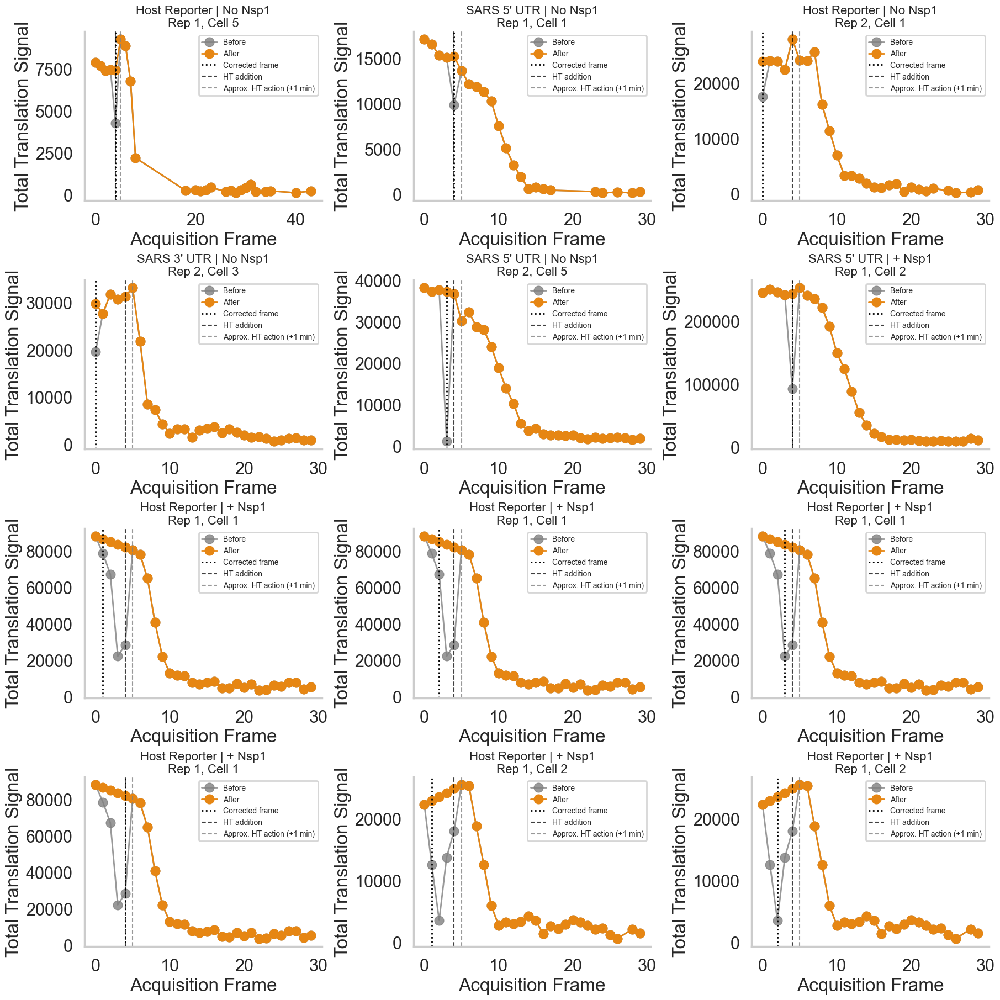

In [23]:
# CELL PURPOSE:
# Visually audit every automatically corrected baseline dip.
#
# This diagnostic figure is written explicitly rather than through a plotting
# helper so its formatting can be edited directly in this cell.

import seaborn as sns
import matplotlib.pyplot as plt

sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

corrected_log = baseline_dip_correction_log.loc[
    baseline_dip_correction_log["Correction_Status"].eq("Corrected")
].copy()

if corrected_log.empty:
    print("No automatically corrected baseline dips to plot.")
    baseline_dip_audit_figure = None

else:
    corrected_cells = (
        corrected_log[
            [
                "fov",
                "Corrected_Frame",
            ]
        ]
        .drop_duplicates()
        .head(12)
    )

    n_panels = len(corrected_cells)
    n_columns = 3
    n_rows = int(np.ceil(n_panels / n_columns))

    fig, axes = plt.subplots(
        n_rows,
        n_columns,
        figsize=(6 * n_columns, 4.5 * n_rows),
        squeeze=False,
        constrained_layout=True,
    )

    for ax, row in zip(
        axes.flat,
        corrected_cells.itertuples(),
    ):

        fov = str(row.fov)
        corrected_frame = int(row.Corrected_Frame)

        before = (
            cell_time_uncorrected.loc[
                cell_time_uncorrected["fov"].astype(str).eq(fov)
            ]
            .copy()
            .sort_values("t")
        )

        after = (
            cell_time_raw.loc[
                cell_time_raw["fov"].astype(str).eq(fov)
            ]
            .copy()
            .sort_values("t")
        )

        if before.empty or after.empty:
            ax.set_visible(False)
            continue

        metadata = after.iloc[0]

        ax.plot(
            before["t"],
            before[BASELINE_DIP_METRIC],
            marker="o",
            linewidth=2,
            color="gray",
            alpha=0.8,
            label="Before",
        )

        ax.plot(
            after["t"],
            after[BASELINE_DIP_METRIC],
            marker="o",
            linewidth=2,
            color="#E68613",
            label="After",
        )

        ax.axvline(
            corrected_frame,
            color="black",
            linestyle=":",
            linewidth=2,
            label="Corrected frame",
        )

        ax.axvline(
            HT_ADDITION_FRAME,
            color="black",
            linestyle="--",
            linewidth=1.5,
            alpha=0.75,
            label="HT addition",
        )

        ax.axvline(
            HT_ACTION_FRAME,
            color="gray",
            linestyle="--",
            linewidth=1.5,
            alpha=0.8,
            label="Approx. HT action (+1 min)",
        )

        ax.set_title(
            (
                f'{GROUP_LABELS.get(metadata["Experimental_Group"], metadata["Experimental_Group"])} | '
                f'{TYPE_LABELS.get(metadata["Experimental_Type"], metadata["Experimental_Type"])}\n'
                f'Rep {metadata["Replicate_Number"]}, '
                f'Cell {metadata["Cell_Number"]}'
            ),
            fontsize=16,
        )

        ax.set_xlabel("Acquisition Frame")
        ax.set_ylabel("Total Translation Signal")
        ax.legend(fontsize=10, frameon=True)

        sns.despine(ax=ax)

    for ax in axes.flat[n_panels:]:
        ax.set_visible(False)

    save_figure(
        fig,
        "HT_Automatic_Baseline_Dip_Correction_Audit",
    )

    plt.show()

    baseline_dip_audit_figure = fig


## Part VIII — Flatten and normalize the pre-HT baseline

Selected anchor frames are averaged independently for each cell. When anchors are `(0, 4)`, frames 0–4 are replaced by that average before endpoint normalization and fitting.


In [24]:
# CELL PURPOSE:
# Normalize each corrected cell curve independently to the mean of
# frames 2, 3, and 4 while retaining every measured pre-HT frame.


def normalize_corrected_cell_curve(
    group: pd.DataFrame,
    metric: str,
) -> pd.DataFrame:
    """
    Create endpoint-normalized and baseline-normalized versions of one
    corrected cell curve.

    The normalization denominator is calculated independently for every
    cell using NORMALIZATION_FRAMES. No measured baseline frame is
    removed, replaced, or flattened.
    """

    group = (
        group
        .sort_values('t')
        .copy()
    )

    group['t'] = pd.to_numeric(
        group['t'],
        errors='coerce',
    )

    group[metric] = pd.to_numeric(
        group[metric],
        errors='coerce',
    )

    normalization_frames = tuple(
        sorted(
            {
                int(frame_number)
                for frame_number
                in NORMALIZATION_FRAMES
            }
        )
    )

    normalization_rows = group.loc[
        group['t'].isin(
            normalization_frames
        ),
        [
            't',
            metric,
        ],
    ].copy()

    normalization_rows = (
        normalization_rows
        .dropna(
            subset=[
                't',
                metric,
            ]
        )
        .drop_duplicates(
            subset=['t'],
            keep='first',
        )
    )

    observed_normalization_frames = tuple(
        sorted(
            normalization_rows[
                't'
            ]
            .astype(int)
            .tolist()
        )
    )

    normalization_complete = (
        observed_normalization_frames
        == normalization_frames
    )

    if (
        REQUIRE_COMPLETE_NORMALIZATION_FRAMES
        and not normalization_complete
    ):

        normalization_mean = np.nan

    else:

        normalization_mean = (
            normalization_rows[
                metric
            ]
            .mean()
        )

    # Retain the older anchor_mean name for compatibility with existing
    # notebook cells.
    group[
        f'{metric}_anchor_mean'
    ] = normalization_mean

    group[
        f'{metric}_normalization_mean'
    ] = normalization_mean

    group[
        f'{metric}_normalization_frame_count'
    ] = len(
        observed_normalization_frames
    )

    group[
        f'{metric}_normalization_complete'
    ] = bool(
        normalization_complete
    )

    group[
        f'{metric}_normalization_frames'
    ] = str(
        normalization_frames
    )

    # --------------------------------------------------------------
    # Calculate the endpoint mean
    # --------------------------------------------------------------

    available_times = sorted(
        group[
            't'
        ]
        .dropna()
        .unique()
    )

    endpoint_times = available_times[
        -ENDPOINT_FRAME_COUNT:
    ]

    endpoint_mean = group.loc[
        group[
            't'
        ].isin(
            endpoint_times
        ),
        metric,
    ].mean()

    group[
        f'{metric}_endpoint_mean'
    ] = endpoint_mean

    # --------------------------------------------------------------
    # Endpoint-compressed normalization
    #
    # Baseline -> 1
    # Endpoint -> 0
    #
    # Retained for compatibility and diagnostic comparison.
    # --------------------------------------------------------------

    fitting_denominator = (
        normalization_mean
        - endpoint_mean
    )

    if (
        np.isfinite(
            fitting_denominator
        )
        and fitting_denominator != 0
    ):

        group[
            f'{metric}_endpoint_norm'
        ] = (
            group[
                metric
            ]
            - endpoint_mean
        ) / fitting_denominator

    else:

        group[
            f'{metric}_endpoint_norm'
        ] = np.nan

    # --------------------------------------------------------------
    # Baseline-only normalization
    #
    # The corrected mean of frames 2, 3, and 4 becomes 1.
    # The measured endpoint fraction remains present.
    # --------------------------------------------------------------

    if (
        np.isfinite(
            normalization_mean
        )
        and normalization_mean != 0
    ):

        group[
            f'{metric}_baseline_norm'
        ] = (
            group[
                metric
            ]
            / normalization_mean
        )

        group[
            f'{metric}_endpoint_fraction'
        ] = (
            endpoint_mean
            / normalization_mean
        )

    else:

        group[
            f'{metric}_baseline_norm'
        ] = np.nan

        group[
            f'{metric}_endpoint_fraction'
        ] = np.nan

    return group


# ------------------------------------------------------------------
# Apply the normalization independently to every corrected cell
# ------------------------------------------------------------------

cell_time_runoff = (
    cell_time_raw
    .copy()
)

for metric in (
    'spot_count',
    'total_spot_intensity',
):

    cell_time_runoff = (
        cell_time_runoff
        .groupby(
            CELL_KEYS,
            dropna=False,
            group_keys=False,
        )
        .apply(
            normalize_corrected_cell_curve,
            metric=metric,
        )
        .reset_index(
            drop=True
        )
    )


# ------------------------------------------------------------------
# Validate every cell's normalization
# ------------------------------------------------------------------

normalization_check = (
    cell_time_runoff.loc[
        cell_time_runoff[
            't'
        ].isin(
            NORMALIZATION_FRAMES
        )
    ]
    .groupby(
        CELL_KEYS,
        dropna=False,
    )
    .agg(
        observed_normalization_frames=(
            't',
            lambda values: tuple(
                sorted(
                    pd.to_numeric(
                        values,
                        errors='coerce',
                    )
                    .dropna()
                    .astype(int)
                    .unique()
                    .tolist()
                )
            ),
        ),

        normalized_baseline_mean=(
            'total_spot_intensity_baseline_norm',
            'mean',
        ),

        normalization_complete=(
            'total_spot_intensity_normalization_complete',
            'first',
        ),

        corrected_normalization_frames=(
            'Baseline_Dip_Corrected',
            lambda values: int(
                pd.Series(
                    values
                )
                .fillna(False)
                .astype(bool)
                .sum()
            ),
        ),
    )
    .reset_index()
)

normalization_check[
    'normalization_error'
] = (
    normalization_check[
        'normalized_baseline_mean'
    ]
    - 1.0
)

complete_normalization_check = (
    normalization_check.loc[
        normalization_check[
            'normalization_complete'
        ].fillna(False)
    ]
)

incomplete_normalization_check = (
    normalization_check.loc[
        ~normalization_check[
            'normalization_complete'
        ].fillna(False)
    ]
)

if not complete_normalization_check.empty:

    maximum_normalization_error = float(
        complete_normalization_check[
            'normalization_error'
        ]
        .abs()
        .max()
    )

else:

    maximum_normalization_error = np.nan


print('\nPer-cell normalization validation')
print('---------------------------------')
print(
    'Normalization frames: '
    f'{NORMALIZATION_FRAMES}'
)
print(
    'Cells with complete normalization frames: '
    f'{len(complete_normalization_check):,}'
)
print(
    'Cells missing one or more normalization frames: '
    f'{len(incomplete_normalization_check):,}'
)
print(
    'Maximum absolute normalization error: '
    f'{maximum_normalization_error:.3e}'
    if np.isfinite(
        maximum_normalization_error
    )
    else 'Maximum absolute normalization error: nan'
)
print(
    'Corrected measurements used within normalization frames: '
    f"{int(normalization_check['corrected_normalization_frames'].sum()):,}"
)

if (
    np.isfinite(
        maximum_normalization_error
    )
    and maximum_normalization_error
    > NORMALIZATION_VALIDATION_ATOL
):

    raise RuntimeError(
        'At least one complete cell did not normalize to a mean of 1 '
        'across frames 2, 3, and 4.'
    )

if (
    REQUIRE_COMPLETE_NORMALIZATION_FRAMES
    and not incomplete_normalization_check.empty
):

    print(
        '\nCells with incomplete normalization frames were retained '
        'in the audit table, but their normalized curves were set to NaN.'
    )

    display(
        incomplete_normalization_check
    )


# ------------------------------------------------------------------
# Validate normalization after group averaging
# ------------------------------------------------------------------

group_normalization_check = (
    cell_time_runoff.loc[
        cell_time_runoff[
            't'
        ].isin(
            NORMALIZATION_FRAMES
        )
    ]
    .groupby(
        [
            'Experimental_Group',
            'Experimental_Type',
            't',
        ],
        dropna=False,
    )[
        'total_spot_intensity_baseline_norm'
    ]
    .mean()
    .reset_index(
        name='group_mean_normalized_signal'
    )
    .groupby(
        [
            'Experimental_Group',
            'Experimental_Type',
        ],
        dropna=False,
    )[
        'group_mean_normalized_signal'
    ]
    .mean()
    .reset_index(
        name='mean_across_normalization_frames'
    )
)

group_normalization_check[
    'group_normalization_error'
] = (
    group_normalization_check[
        'mean_across_normalization_frames'
    ]
    - 1.0
)

print(
    'Maximum absolute group-level normalization error: '
    f"{group_normalization_check['group_normalization_error'].abs().max():.3e}"
)

display(
    group_normalization_check
)


# ------------------------------------------------------------------
# Refresh the complete pre-manual-QC source tables
# ------------------------------------------------------------------

spot_analysis_df_before_manual_cell_qc = (
    spot_analysis_df
    .copy(
        deep=True
    )
)

cell_time_raw_before_manual_cell_qc = (
    cell_time_raw
    .copy(
        deep=True
    )
)

cell_time_runoff_before_manual_cell_qc = (
    cell_time_runoff
    .copy(
        deep=True
    )
)

cell_time_uncorrected_before_manual_cell_qc = (
    cell_time_uncorrected
    .copy(
        deep=True
    )
)


# ------------------------------------------------------------------
# Confirm that correction metadata survived normalization
# ------------------------------------------------------------------

if (
    'Baseline_Dip_Corrected'
    in cell_time_raw.columns
):

    corrected_raw_count = int(
        cell_time_raw[
            'Baseline_Dip_Corrected'
        ]
        .fillna(False)
        .sum()
    )

    corrected_runoff_count = int(
        cell_time_runoff[
            'Baseline_Dip_Corrected'
        ]
        .fillna(False)
        .sum()
    )

    if (
        corrected_raw_count
        != corrected_runoff_count
    ):

        raise RuntimeError(
            'Baseline-correction metadata did not propagate through '
            'the normalization step.\n'
            f'Corrected rows in cell_time_raw: '
            f'{corrected_raw_count}\n'
            f'Corrected rows in cell_time_runoff: '
            f'{corrected_runoff_count}'
        )


save_table(
    cell_time_runoff,
    'tethered_ht_cell_time_runoff_tanh',
)

save_table(
    normalization_check,
    'tethered_ht_per_cell_normalization_check',
)

save_table(
    group_normalization_check,
    'tethered_ht_group_normalization_check',
)


display_columns = [
    column
    for column in [
        'Experimental_Group',
        'Experimental_Type',
        'Replicate_Number',
        'Cell_Number',
        'fov',
        't',
        'Baseline_Dip_Corrected',
        'total_spot_intensity',
        'total_spot_intensity_normalization_mean',
        'total_spot_intensity_baseline_norm',
        'total_spot_intensity_endpoint_fraction',
    ]
    if column
    in cell_time_runoff.columns
]

display(
    cell_time_runoff[
        display_columns
    ]
    .head(25)
)


Per-cell normalization validation
---------------------------------
Normalization frames: (2, 3, 4)
Cells with complete normalization frames: 88
Cells missing one or more normalization frames: 2
Maximum absolute normalization error: 3.331e-16
Corrected measurements used within normalization frames: 19

Cells with incomplete normalization frames were retained in the audit table, but their normalized curves were set to NaN.


,Experimental_Type,Replicate_Number,Experimental_Group,fov,Date,Cell_Number,Movie_ID,observed_normalization_frames,normalized_baseline_mean,normalization_complete,corrected_normalization_frames,normalization_error
34,No Nsp1,2,SARS_5'UTR,SARS_5_UTR_20260717_20260717_1_1_Cell02_processed_Cell02_TRNL_Ch1_nc,2026-07-17,2,SARS_5'UTR/20260717/20260717_1_1/Cell02_processed/Cell02_TRNL_Ch1.nc,"(2, 3)",NaN,False,0,NaN
65,Nsp1,1,SARS_5'_3'UTR,Nsp1_SARS_5_UTR_3_UTR_20260709_20260709_2_1_Cell05_processed_Cell05_TRNL_Ch1_nc,2026-07-09,5,Nsp1_SARS_5'UTR_3'UTR/20260709/20260709_2_1/Cell05_processed/Cell05_TRNL_Ch1.nc,"(2, 4)",NaN,False,0,NaN


Maximum absolute group-level normalization error: 0.000e+00


,Experimental_Group,Experimental_Type,mean_across_normalization_frames,group_normalization_error
0,Control,No Nsp1,1.0,0.0
1,Control,Nsp1,1.0,0.0
2,SARS_3'UTR,No Nsp1,1.0,0.0
3,SARS_3'UTR,Nsp1,1.0,0.0
4,SARS_5'UTR,No Nsp1,1.0,0.0
5,SARS_5'UTR,Nsp1,1.0,0.0
6,SARS_5'_3'UTR,No Nsp1,1.0,0.0
7,SARS_5'_3'UTR,Nsp1,1.0,0.0


Parquet unavailable for tethered_ht_cell_time_runoff_tanh: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.
Saved: Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT\Analysis_Output\Tethered_HT\Dataframes\tethered_ht_cell_time_runoff_tanh.csv
Parquet unavailable for tethered_ht_per_cell_normalization_check: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for par

,Experimental_Group,Experimental_Type,Replicate_Number,Cell_Number,fov,t,Baseline_Dip_Corrected,total_spot_intensity,total_spot_intensity_normalization_mean,total_spot_intensity_baseline_norm,total_spot_intensity_endpoint_fraction
0,Control,No Nsp1,1,1,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,0,False,15400.655172,15441.827586,0.997334,0.038293
1,Control,No Nsp1,1,1,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,1,False,13700.517241,15441.827586,0.887234,0.038293
2,Control,No Nsp1,1,1,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,2,False,15296.379310,15441.827586,0.990581,0.038293
3,Control,No Nsp1,1,1,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,3,False,14148.103448,15441.827586,0.916219,0.038293
4,Control,No Nsp1,1,1,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,4,False,16881.000000,15441.827586,1.093200,0.038293
5,Control,No Nsp1,1,1,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,5,False,13048.344828,15441.827586,0.845000,0.038293
6,Control,No Nsp1,1,1,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,6,False,13453.775862,15441.827586,0.871255,0.038293
7,Control,No Nsp1,1,1,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,7,False,9635.327586,15441.827586,0.623976,0.038293
8,Control,No Nsp1,1,1,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,8,False,6457.568966,15441.827586,0.418187,0.038293
9,Control,No Nsp1,1,1,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,9,False,2847.327586,15441.827586,0.184391,0.038293


## Part IX — Manual cell-level runoff quality control

Individual cell runoff curves are reviewed before calculating HT-resistant
fractions, group-average runoff curves, elongation rates, ribosome occupancy,
or initiation rates.

Manual exclusion should be limited to documented technical failures, such as:

- missing or incomplete acquisition frames;
- unstable pre-HT baselines;
- isolated acquisition spikes or drops;
- incorrect cell assignment or segmentation;
- failed normalization caused by invalid baseline measurements.

A cell should not be excluded solely because it has a slow runoff, a high
residual fraction, or another potentially biological phenotype.

Review decisions are saved persistently by the globally unique `fov`
identifier. Excluded cells are removed from both `spot_analysis_df` and
`cell_time_runoff`, ensuring that all downstream analyses use the same retained
cell population.

In [25]:
# CELL PURPOSE:
# Initialize persistent manual cell-level QC and preserve the complete
# pre-review source tables.

if widgets is None:
    raise ImportError(
        'ipywidgets is required for the manual cell-review interface.'
    )


# ------------------------------------------------------------------
# Persistent QC file
# ------------------------------------------------------------------

MANUAL_CELL_QC_FILE = (
    DATAFRAME_DIR
    / 'tethered_ht_manual_cell_qc_decisions.csv'
)


MANUAL_CELL_QC_COLUMNS = [
    'fov',
    'Manual_Cell_QC_Status',
    'Manual_Cell_QC_Reason',
    'Manual_Cell_QC_Notes',
    'Experimental_Group',
    'Experimental_Type',
    'Replicate_Number',
    'Date',
    'Cell_Number',
    'Movie_ID',
    'Reviewed_At',
]


MANUAL_CELL_QC_REASONS = [
    'Select a technical reason',
    'Missing or incomplete acquisition frames',
    'Unstable pre-HT baseline',
    'Isolated acquisition spike or drop',
    'Catastrophic signal discontinuity',
    'Incorrect cell assignment or segmentation',
    'Invalid baseline normalization',
    'Other documented technical issue',
]

# ------------------------------------------------------------------
# Confirm that Part VIII created fresh pre-manual-QC source tables.
# ------------------------------------------------------------------

required_manual_qc_source_tables = [
    'spot_analysis_df_before_manual_cell_qc',
    'cell_time_raw_before_manual_cell_qc',
    'cell_time_runoff_before_manual_cell_qc',
    'cell_time_uncorrected_before_manual_cell_qc',
]


missing_manual_qc_source_tables = [
    variable_name
    for variable_name in required_manual_qc_source_tables
    if variable_name not in globals()
]


if missing_manual_qc_source_tables:
    raise RuntimeError(
        'The pre-manual-QC source tables have not been created.\n'
        'Run Part VII and all of Part VIII before initializing '
        'the manual-QC interface.\n\n'
        f'Missing variables: {missing_manual_qc_source_tables}'
    )


if (
    'Baseline_Dip_Corrected'
    not in cell_time_runoff_before_manual_cell_qc.columns
):
    raise RuntimeError(
        'The manual-QC runoff source does not contain the baseline-'
        'correction metadata. Rerun Part VII and Part VIII.'
    )


print(
    'Manual-QC interface is using the corrected Part VIII runoff table.'
)

print(
    'Corrected frames available to manual QC: '
    f"{int(cell_time_runoff_before_manual_cell_qc['Baseline_Dip_Corrected'].fillna(False).sum()):,}"
)

# ------------------------------------------------------------------
# Build one metadata row per cell.
# ------------------------------------------------------------------

manual_cell_qc_metadata_columns = [
    column
    for column in [
        'fov',
        'Experimental_Group',
        'Experimental_Type',
        'Replicate_Number',
        'Date',
        'Cell_Number',
        'Movie_ID',
    ]
    if column
    in cell_time_runoff_before_manual_cell_qc.columns
]


manual_cell_qc_cells = (
    cell_time_runoff_before_manual_cell_qc[
        manual_cell_qc_metadata_columns
    ]
    .drop_duplicates(
        subset=['fov']
    )
    .copy()
)


if manual_cell_qc_cells['fov'].duplicated().any():
    raise ValueError(
        'The fov identifier is not unique in the cell-review table.'
    )


manual_cell_qc_cells['fov'] = (
    manual_cell_qc_cells['fov']
    .astype(str)
)


manual_cell_qc_cells.sort_values(
    [
        'Experimental_Group',
        'Experimental_Type',
        'Replicate_Number',
        'Cell_Number',
        'fov',
    ],
    inplace=True,
    na_position='last',
)

manual_cell_qc_cells.reset_index(
    drop=True,
    inplace=True,
)


# ------------------------------------------------------------------
# Load previously saved decisions.
# ------------------------------------------------------------------

def load_manual_cell_qc_decisions(
    path,
):
    """
    Load the persistent cell-level review table.
    """

    path = Path(path)

    if not path.exists():
        return pd.DataFrame(
            columns=MANUAL_CELL_QC_COLUMNS
        )

    decisions = pd.read_csv(
        path,
        dtype={
            'fov': str,
            'Manual_Cell_QC_Status': str,
            'Manual_Cell_QC_Reason': str,
            'Manual_Cell_QC_Notes': str,
        },
    )

    for column in MANUAL_CELL_QC_COLUMNS:

        if column not in decisions.columns:
            decisions[column] = pd.NA

    decisions['fov'] = decisions['fov'].astype(str)

    decisions[
        'Manual_Cell_QC_Status'
    ] = (
        decisions[
            'Manual_Cell_QC_Status'
        ]
        .fillna('Unreviewed')
        .astype(str)
    )

    valid_statuses = {
        'Unreviewed',
        'Keep',
        'Exclude',
    }

    invalid_status_mask = (
        ~decisions[
            'Manual_Cell_QC_Status'
        ].isin(valid_statuses)
    )

    decisions.loc[
        invalid_status_mask,
        'Manual_Cell_QC_Status',
    ] = 'Unreviewed'

    return (
        decisions[
            MANUAL_CELL_QC_COLUMNS
        ]
        .drop_duplicates(
            subset=['fov'],
            keep='last',
        )
        .reset_index(drop=True)
    )


def save_manual_cell_qc_decisions():
    """
    Save current review decisions immediately.
    """

    output = manual_cell_qc_decisions.copy()

    for column in MANUAL_CELL_QC_COLUMNS:

        if column not in output.columns:
            output[column] = pd.NA

    output[
        MANUAL_CELL_QC_COLUMNS
    ].to_csv(
        MANUAL_CELL_QC_FILE,
        index=False,
    )


manual_cell_qc_decisions = (
    load_manual_cell_qc_decisions(
        MANUAL_CELL_QC_FILE
    )
)


print(
    f'Cells available for review: '
    f'{len(manual_cell_qc_cells):,}'
)

print(
    f'Existing review decisions: '
    f'{len(manual_cell_qc_decisions):,}'
)

print(
    f'Decision file: '
    f'{MANUAL_CELL_QC_FILE}'
)

Manual-QC interface is using the corrected Part VIII runoff table.
Corrected frames available to manual QC: 26
Cells available for review: 90
Existing review decisions: 90
Decision file: Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT\Analysis_Output\Tethered_HT\Dataframes\tethered_ht_manual_cell_qc_decisions.csv


In [26]:
# CELL PURPOSE:
# Review individual cell runoff curves and persist Keep/Exclude decisions.

# ------------------------------------------------------------------
# Colors used only in the manual review interface
# ------------------------------------------------------------------

MANUAL_CELL_QC_TYPE_COLORS = {
    'No Nsp1': TYPE_COLORS.get(
        'No Nsp1',
        '#00A6A6',
    ),
    'Nsp1': '#E68613',
}


# ------------------------------------------------------------------
# Widgets
# ------------------------------------------------------------------

manual_qc_group_filter = widgets.Dropdown(
    description='Group:',
    layout=widgets.Layout(
        width='420px',
    ),
)

manual_qc_type_filter = widgets.Dropdown(
    description='Type:',
    layout=widgets.Layout(
        width='420px',
    ),
)

manual_qc_status_filter = widgets.Dropdown(
    description='Status:',
    options=[
        'All',
        'Unreviewed',
        'Keep',
        'Exclude',
    ],
    value='All',
    layout=widgets.Layout(
        width='420px',
    ),
)

manual_qc_cell_selector = widgets.Dropdown(
    description='Cell:',
    layout=widgets.Layout(
        width='900px',
    ),
)

manual_qc_reason = widgets.Dropdown(
    description='Reason:',
    options=MANUAL_CELL_QC_REASONS,
    value=MANUAL_CELL_QC_REASONS[0],
    layout=widgets.Layout(
        width='900px',
    ),
)

manual_qc_notes = widgets.Textarea(
    description='Notes:',
    placeholder=(
        'Optional details describing the technical problem'
    ),
    layout=widgets.Layout(
        width='900px',
        height='80px',
    ),
)

manual_qc_previous_button = widgets.Button(
    description='Previous',
    button_style='',
)

manual_qc_keep_button = widgets.Button(
    description='Keep',
    button_style='success',
)

manual_qc_exclude_button = widgets.Button(
    description='Exclude',
    button_style='danger',
)

manual_qc_clear_button = widgets.Button(
    description='Clear decision',
    button_style='warning',
)

manual_qc_next_button = widgets.Button(
    description='Next',
    button_style='',
)

manual_qc_progress = widgets.HTML()

manual_qc_message = widgets.HTML()

manual_qc_plot_output = widgets.Output()


# ------------------------------------------------------------------
# Widget option helpers
# ------------------------------------------------------------------

observed_manual_qc_groups = (
    manual_cell_qc_cells[
        'Experimental_Group'
    ]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)


ordered_manual_qc_groups = [
    group
    for group in GROUP_ORDER
    if group in observed_manual_qc_groups
]

ordered_manual_qc_groups.extend(
    [
        group
        for group in observed_manual_qc_groups
        if group not in ordered_manual_qc_groups
    ]
)


observed_manual_qc_types = (
    manual_cell_qc_cells[
        'Experimental_Type'
    ]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)


ordered_manual_qc_types = [
    experimental_type
    for experimental_type in TYPE_ORDER
    if experimental_type in observed_manual_qc_types
]

ordered_manual_qc_types.extend(
    [
        experimental_type
        for experimental_type in observed_manual_qc_types
        if experimental_type
        not in ordered_manual_qc_types
    ]
)


manual_qc_group_filter.options = [
    'All',
    *ordered_manual_qc_groups,
]

manual_qc_type_filter.options = [
    'All',
    *ordered_manual_qc_types,
]


# ------------------------------------------------------------------
# Decision lookup helpers
# ------------------------------------------------------------------

def get_manual_qc_decision(
    fov,
):
    """
    Return the latest decision row for one cell.
    """

    matching = manual_cell_qc_decisions.loc[
        manual_cell_qc_decisions[
            'fov'
        ].astype(str).eq(
            str(fov)
        )
    ]

    if matching.empty:
        return None

    return matching.iloc[-1]


def manual_qc_status_lookup():
    """
    Return a mapping from fov to current status.
    """

    if manual_cell_qc_decisions.empty:
        return {}

    return (
        manual_cell_qc_decisions
        .drop_duplicates(
            subset=['fov'],
            keep='last',
        )
        .set_index('fov')[
            'Manual_Cell_QC_Status'
        ]
        .astype(str)
        .to_dict()
    )


def get_filtered_manual_qc_cells():
    """
    Apply the current group, type, and review-status filters.
    """

    filtered = manual_cell_qc_cells.copy()

    if manual_qc_group_filter.value != 'All':

        filtered = filtered.loc[
            filtered[
                'Experimental_Group'
            ].astype(str).eq(
                str(
                    manual_qc_group_filter.value
                )
            )
        ]

    if manual_qc_type_filter.value != 'All':

        filtered = filtered.loc[
            filtered[
                'Experimental_Type'
            ].astype(str).eq(
                str(
                    manual_qc_type_filter.value
                )
            )
        ]

    status_lookup = manual_qc_status_lookup()

    filtered[
        'Current_QC_Status'
    ] = (
        filtered['fov']
        .astype(str)
        .map(status_lookup)
        .fillna('Unreviewed')
    )

    if manual_qc_status_filter.value != 'All':

        filtered = filtered.loc[
            filtered[
                'Current_QC_Status'
            ].eq(
                manual_qc_status_filter.value
            )
        ]

    return filtered.reset_index(drop=True)


def make_manual_qc_cell_label(
    row,
):
    """
    Create a readable dropdown label for one cell.
    """

    group_label = GROUP_LABELS.get(
        row.get(
            'Experimental_Group',
            '',
        ),
        row.get(
            'Experimental_Group',
            '',
        ),
    )

    type_label = TYPE_LABELS.get(
        row.get(
            'Experimental_Type',
            '',
        ),
        row.get(
            'Experimental_Type',
            '',
        ),
    )

    replicate = row.get(
        'Replicate_Number',
        '',
    )

    cell_number = row.get(
        'Cell_Number',
        '',
    )

    status = row.get(
        'Current_QC_Status',
        'Unreviewed',
    )

    return (
        f'{group_label} | '
        f'{type_label} | '
        f'Rep {replicate} | '
        f'Cell {cell_number} | '
        f'{status}'
    )


# ------------------------------------------------------------------
# Plot one cell
# ------------------------------------------------------------------

def render_manual_qc_cell(
    *_,
):
    """
    Display the currently selected cell without any fit.
    """

    with manual_qc_plot_output:

        clear_output(
            wait=True
        )

        selected_fov = (
            manual_qc_cell_selector.value
        )

        if selected_fov is None:

            print(
                'No cells match the current filters.'
            )
            return

        curve = (
            cell_time_runoff_before_manual_cell_qc
            .loc[
                cell_time_runoff_before_manual_cell_qc[
                    'fov'
                ].astype(str).eq(
                    str(selected_fov)
                )
            ]
            .sort_values('t')
            .copy()
        )

        if curve.empty:

            print(
                f'No runoff curve was found for '
                f'fov={selected_fov}.'
            )
            return

        metadata = curve.iloc[0]

        experimental_type = str(
            metadata[
                'Experimental_Type'
            ]
        )

        curve_color = (
            MANUAL_CELL_QC_TYPE_COLORS.get(
                experimental_type,
                'gray',
            )
        )

        curve[
            'time_relative_to_ht_addition_min'
        ] = (
            pd.to_numeric(
                curve['t'],
                errors='coerce',
            )
            - HT_ADDITION_FRAME
        ) * FRAME_INTERVAL_MIN

        current_decision = (
            get_manual_qc_decision(
                selected_fov
            )
        )

        if current_decision is None:

            current_status = 'Unreviewed'
            current_reason = ''
            current_notes = ''

        else:

            current_status = str(
                current_decision[
                    'Manual_Cell_QC_Status'
                ]
            )

            current_reason = (
                ''
                if pd.isna(
                    current_decision[
                        'Manual_Cell_QC_Reason'
                    ]
                )
                else str(
                    current_decision[
                        'Manual_Cell_QC_Reason'
                    ]
                )
            )

            current_notes = (
                ''
                if pd.isna(
                    current_decision[
                        'Manual_Cell_QC_Notes'
                    ]
                )
                else str(
                    current_decision[
                        'Manual_Cell_QC_Notes'
                    ]
                )
            )

        if (
            current_reason
            in MANUAL_CELL_QC_REASONS
        ):
            manual_qc_reason.value = (
                current_reason
            )
        else:
            manual_qc_reason.value = (
                MANUAL_CELL_QC_REASONS[0]
            )

        manual_qc_notes.value = current_notes

        figure, axes = plt.subplots(
            1,
            2,
            figsize=(
                16,
                6,
            ),
            constrained_layout=True,
        )

        plot_definitions = [
            (
                'total_spot_intensity_baseline_norm',
                'Baseline-Normalized\nTotal Translation Signal',
            ),
            (
                'spot_count_baseline_norm',
                'Baseline-Normalized\nTranslation-Site Count',
            ),
        ]

        for axis, (
            metric,
            ylabel,
        ) in zip(
            axes,
            plot_definitions,
        ):

            if metric not in curve.columns:

                axis.text(
                    0.5,
                    0.5,
                    f'{metric}\nnot available',
                    ha='center',
                    va='center',
                    transform=axis.transAxes,
                )

                continue

            axis.plot(
                curve[
                    'time_relative_to_ht_addition_min'
                ],
                curve[metric],
                marker='o',
                markersize=6,
                linewidth=2.5,
                color=curve_color,
            )

            # Actual HT addition occurs immediately after frame 4.
            axis.axvline(
                0,
                color='black',
                linestyle=':',
                linewidth=2,
            )

            # Approximate HT engagement after the ~1-minute action delay.
            axis.axvline(
                HT_ACTION_TIME_AFTER_ADDITION_MIN,
                color='gray',
                linestyle='--',
                linewidth=1.5,
                alpha=0.75,
            )

            axis.axhline(
                1,
                color='gray',
                linestyle='--',
                linewidth=1,
                alpha=0.6,
            )

            axis.axhline(
                0,
                color='gray',
                linewidth=1,
                alpha=0.6,
            )

            axis.set_xlabel(
                'Time Relative to HT Addition (min)'
            )

            axis.set_ylabel(
                ylabel
            )

            axis.grid(
                False
            )

            sns.despine(
                ax=axis
            )

        group_name = GROUP_LABELS.get(
            metadata[
                'Experimental_Group'
            ],
            metadata[
                'Experimental_Group'
            ],
        )

        type_name = TYPE_LABELS.get(
            metadata[
                'Experimental_Type'
            ],
            metadata[
                'Experimental_Type'
            ],
        )

        figure.suptitle(
            (
                f'{group_name} | {type_name} | '
                f'Replicate {metadata["Replicate_Number"]} | '
                f'Cell {metadata["Cell_Number"]}\n'
                f'QC status: {current_status}'
            ),
            fontsize=20,
            fontweight='bold',
        )

        plt.show()

        metadata_display = pd.DataFrame(
            {
                'Field': [
                    'QC status',
                    'Reason',
                    'fov',
                    'Movie ID',
                    'Experimental group',
                    'Experimental type',
                    'Replicate',
                    'Cell number',
                ],
                'Value': [
                    current_status,
                    current_reason,
                    selected_fov,
                    metadata.get(
                        'Movie_ID',
                        '',
                    ),
                    metadata.get(
                        'Experimental_Group',
                        '',
                    ),
                    metadata.get(
                        'Experimental_Type',
                        '',
                    ),
                    metadata.get(
                        'Replicate_Number',
                        '',
                    ),
                    metadata.get(
                        'Cell_Number',
                        '',
                    ),
                ],
            }
        )

        display(
            metadata_display
        )


# ------------------------------------------------------------------
# Refresh the cell dropdown
# ------------------------------------------------------------------

def refresh_manual_qc_cell_options(
    *_,
    preferred_fov=None,
):
    """
    Rebuild the cell dropdown after filters or decisions change.
    """

    filtered_cells = (
        get_filtered_manual_qc_cells()
    )

    options = [
        (
            make_manual_qc_cell_label(
                row
            ),
            str(row['fov']),
        )
        for _, row
        in filtered_cells.iterrows()
    ]

    manual_qc_cell_selector.options = (
        options
    )

    option_values = [
        value
        for _, value in options
    ]

    if (
        preferred_fov is not None
        and str(preferred_fov)
        in option_values
    ):

        manual_qc_cell_selector.value = (
            str(preferred_fov)
        )

    elif option_values:

        manual_qc_cell_selector.value = (
            option_values[0]
        )

    else:

        manual_qc_cell_selector.options = []
        manual_qc_cell_selector.value = None

    status_lookup = manual_qc_status_lookup()

    reviewed_count = sum(
        status_lookup.get(
            str(fov),
            'Unreviewed',
        )
        in {
            'Keep',
            'Exclude',
        }
        for fov
        in manual_cell_qc_cells['fov']
    )

    excluded_count = sum(
        status_lookup.get(
            str(fov),
            'Unreviewed',
        )
        == 'Exclude'
        for fov
        in manual_cell_qc_cells['fov']
    )

    manual_qc_progress.value = (
        '<b>Review progress:</b> '
        f'{reviewed_count:,} / '
        f'{len(manual_cell_qc_cells):,} reviewed; '
        f'{excluded_count:,} excluded; '
        f'{len(filtered_cells):,} shown by current filters'
    )

    render_manual_qc_cell()


# ------------------------------------------------------------------
# Navigation
# ------------------------------------------------------------------

def move_manual_qc_selection(
    step,
):
    """
    Move to the previous or next visible cell.
    """

    options = list(
        manual_qc_cell_selector.options
    )

    if not options:
        return

    values = [
        value
        for _, value in options
    ]

    current_value = (
        manual_qc_cell_selector.value
    )

    try:
        current_index = values.index(
            current_value
        )
    except ValueError:
        current_index = 0

    new_index = int(
        np.clip(
            current_index + step,
            0,
            len(values) - 1,
        )
    )

    manual_qc_cell_selector.value = (
        values[new_index]
    )


# ------------------------------------------------------------------
# Record decisions
# ------------------------------------------------------------------

def record_manual_qc_decision(
    status,
):
    """
    Save Keep, Exclude, or Unreviewed for the current cell.
    """

    global manual_cell_qc_decisions

    selected_fov = (
        manual_qc_cell_selector.value
    )

    if selected_fov is None:
        return

    visible_values = [
        value
        for _, value
        in manual_qc_cell_selector.options
    ]

    try:
        current_position = (
            visible_values.index(
                selected_fov
            )
        )
    except ValueError:
        current_position = 0

    next_fov = None

    if visible_values:

        next_index = min(
            current_position + 1,
            len(visible_values) - 1,
        )

        next_fov = visible_values[
            next_index
        ]

    metadata_match = (
        manual_cell_qc_cells.loc[
            manual_cell_qc_cells[
                'fov'
            ].astype(str).eq(
                str(selected_fov)
            )
        ]
    )

    if metadata_match.empty:
        raise KeyError(
            f'Could not locate metadata for '
            f'fov={selected_fov}.'
        )

    metadata = metadata_match.iloc[0]

    if status == 'Exclude':

        selected_reason = (
            manual_qc_reason.value
        )

        if (
            selected_reason
            == MANUAL_CELL_QC_REASONS[0]
        ):

            manual_qc_message.value = (
                '<span style="color:#B22222">'
                '<b>Select a technical exclusion reason first.</b>'
                '</span>'
            )

            return

    elif status == 'Keep':

        selected_reason = ''

    else:

        selected_reason = ''

    decision_row = {
        'fov': str(selected_fov),
        'Manual_Cell_QC_Status': status,
        'Manual_Cell_QC_Reason': selected_reason,
        'Manual_Cell_QC_Notes': (
            manual_qc_notes.value.strip()
        ),
        'Experimental_Group': metadata.get(
            'Experimental_Group',
            pd.NA,
        ),
        'Experimental_Type': metadata.get(
            'Experimental_Type',
            pd.NA,
        ),
        'Replicate_Number': metadata.get(
            'Replicate_Number',
            pd.NA,
        ),
        'Date': metadata.get(
            'Date',
            pd.NA,
        ),
        'Cell_Number': metadata.get(
            'Cell_Number',
            pd.NA,
        ),
        'Movie_ID': metadata.get(
            'Movie_ID',
            pd.NA,
        ),
        'Reviewed_At': (
            pd.Timestamp.now(
                tz='UTC'
            ).isoformat()
        ),
    }

    manual_cell_qc_decisions = (
        manual_cell_qc_decisions.loc[
            ~manual_cell_qc_decisions[
                'fov'
            ].astype(str).eq(
                str(selected_fov)
            )
        ]
        .copy()
    )

    manual_cell_qc_decisions = pd.concat(
        [
            manual_cell_qc_decisions,
            pd.DataFrame(
                [decision_row]
            ),
        ],
        ignore_index=True,
    )

    save_manual_cell_qc_decisions()

    manual_qc_message.value = (
        f'<b>Saved:</b> {status} — '
        f'fov={selected_fov}'
    )

    refresh_manual_qc_cell_options(
        preferred_fov=next_fov,
    )


# ------------------------------------------------------------------
# Event callbacks
# ------------------------------------------------------------------

manual_qc_group_filter.observe(
    refresh_manual_qc_cell_options,
    names='value',
)

manual_qc_type_filter.observe(
    refresh_manual_qc_cell_options,
    names='value',
)

manual_qc_status_filter.observe(
    refresh_manual_qc_cell_options,
    names='value',
)

manual_qc_cell_selector.observe(
    render_manual_qc_cell,
    names='value',
)

manual_qc_previous_button.on_click(
    lambda _:
    move_manual_qc_selection(-1)
)

manual_qc_next_button.on_click(
    lambda _:
    move_manual_qc_selection(1)
)

manual_qc_keep_button.on_click(
    lambda _:
    record_manual_qc_decision(
        'Keep'
    )
)

manual_qc_exclude_button.on_click(
    lambda _:
    record_manual_qc_decision(
        'Exclude'
    )
)

manual_qc_clear_button.on_click(
    lambda _:
    record_manual_qc_decision(
        'Unreviewed'
    )
)


# ------------------------------------------------------------------
# Display interface
# ------------------------------------------------------------------

manual_cell_qc_interface = widgets.VBox(
    [
        widgets.HBox(
            [
                manual_qc_group_filter,
                manual_qc_type_filter,
            ]
        ),
        widgets.HBox(
            [
                manual_qc_status_filter,
            ]
        ),
        manual_qc_progress,
        manual_qc_cell_selector,
        manual_qc_reason,
        manual_qc_notes,
        widgets.HBox(
            [
                manual_qc_previous_button,
                manual_qc_keep_button,
                manual_qc_exclude_button,
                manual_qc_clear_button,
                manual_qc_next_button,
            ]
        ),
        manual_qc_message,
        manual_qc_plot_output,
    ]
)


display(
    manual_cell_qc_interface
)


refresh_manual_qc_cell_options()

In [27]:
# CELL PURPOSE:
# Apply persistent manual exclusions to all canonical downstream
# analysis tables.

# ------------------------------------------------------------------
# Reload saved decisions in case the interface was used previously.
# ------------------------------------------------------------------

manual_cell_qc_decisions = (
    load_manual_cell_qc_decisions(
        MANUAL_CELL_QC_FILE
    )
)


manual_excluded_cells = (
    manual_cell_qc_decisions.loc[
        manual_cell_qc_decisions[
            'Manual_Cell_QC_Status'
        ].eq('Exclude')
    ]
    .drop_duplicates(
        subset=['fov'],
        keep='last',
    )
    .copy()
)


MANUAL_EXCLUDED_CELL_FOVS = sorted(
    manual_excluded_cells[
        'fov'
    ]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)


print(
    f'Manually excluded cells: '
    f'{len(MANUAL_EXCLUDED_CELL_FOVS):,}'
)


# ------------------------------------------------------------------
# Helper for filtering any table that contains fov.
# ------------------------------------------------------------------

def remove_manual_cell_qc_exclusions(
    dataframe,
    excluded_fovs,
):
    """
    Remove rows belonging to manually excluded cells.
    """

    if dataframe is None:
        return None

    if 'fov' not in dataframe.columns:
        raise KeyError(
            'The table cannot be filtered because it '
            'does not contain an fov column.'
        )

    output = dataframe.copy()

    output['fov'] = output['fov'].astype(str)

    return (
        output.loc[
            ~output['fov'].isin(
                excluded_fovs
            )
        ]
        .copy()
        .reset_index(drop=True)
    )


# ------------------------------------------------------------------
# Save rows removed by manual QC for auditing.
# ------------------------------------------------------------------

manual_qc_removed_spot_rows = (
    spot_analysis_df_before_manual_cell_qc.loc[
        spot_analysis_df_before_manual_cell_qc[
            'fov'
        ].astype(str).isin(
            MANUAL_EXCLUDED_CELL_FOVS
        )
    ]
    .copy()
)


manual_qc_removed_runoff_rows = (
    cell_time_runoff_before_manual_cell_qc.loc[
        cell_time_runoff_before_manual_cell_qc[
            'fov'
        ].astype(str).isin(
            MANUAL_EXCLUDED_CELL_FOVS
        )
    ]
    .copy()
)


# ------------------------------------------------------------------
# Replace canonical tables used by downstream cells.
# ------------------------------------------------------------------

spot_analysis_df = (
    remove_manual_cell_qc_exclusions(
        spot_analysis_df_before_manual_cell_qc,
        MANUAL_EXCLUDED_CELL_FOVS,
    )
)


cell_time_runoff = (
    remove_manual_cell_qc_exclusions(
        cell_time_runoff_before_manual_cell_qc,
        MANUAL_EXCLUDED_CELL_FOVS,
    )
)


cell_time_raw = (
    remove_manual_cell_qc_exclusions(
        cell_time_raw_before_manual_cell_qc,
        MANUAL_EXCLUDED_CELL_FOVS,
    )
)


if (
    'cell_time_uncorrected_before_manual_cell_qc'
    in globals()
):

    cell_time_uncorrected = (
        remove_manual_cell_qc_exclusions(
            cell_time_uncorrected_before_manual_cell_qc,
            MANUAL_EXCLUDED_CELL_FOVS,
        )
    )


# ------------------------------------------------------------------
# Save audit and filtered tables.
# ------------------------------------------------------------------

save_table(
    manual_cell_qc_decisions,
    'tethered_ht_manual_cell_qc_decisions',
)

save_table(
    manual_excluded_cells,
    'tethered_ht_manual_cell_qc_excluded_cells',
)

save_table(
    manual_qc_removed_spot_rows,
    'tethered_ht_manual_cell_qc_removed_spot_rows',
)

save_table(
    manual_qc_removed_runoff_rows,
    'tethered_ht_manual_cell_qc_removed_runoff_rows',
)

save_table(
    spot_analysis_df,
    'tethered_ht_untracked_translation_after_all_cell_qc',
)

save_table(
    cell_time_runoff,
    'tethered_ht_cell_time_runoff_after_manual_qc',
)


# ------------------------------------------------------------------
# Summary by group and type
# ------------------------------------------------------------------

manual_qc_exclusion_summary = (
    manual_excluded_cells
    .groupby(
        [
            'Experimental_Group',
            'Experimental_Type',
            'Replicate_Number',
        ],
        dropna=False,
    )
    .size()
    .rename(
        'n_manually_excluded_cells'
    )
    .reset_index()
)


print('\nManual cell-level QC applied')
print('----------------------------')
print(
    'Spot rows before manual QC: '
    f'{len(spot_analysis_df_before_manual_cell_qc):,}'
)
print(
    'Spot rows after manual QC:  '
    f'{len(spot_analysis_df):,}'
)
print(
    'Cells before manual QC:     '
    f'{cell_time_runoff_before_manual_cell_qc["fov"].nunique():,}'
)
print(
    'Cells after manual QC:      '
    f'{cell_time_runoff["fov"].nunique():,}'
)


if manual_qc_exclusion_summary.empty:

    print(
        'No cells are currently marked Exclude.'
    )

else:

    display(
        manual_qc_exclusion_summary
    )

    display_columns = [
        column
        for column in [
            'Experimental_Group',
            'Experimental_Type',
            'Replicate_Number',
            'Cell_Number',
            'fov',
            'Manual_Cell_QC_Reason',
            'Manual_Cell_QC_Notes',
            'Reviewed_At',
        ]
        if column
        in manual_excluded_cells.columns
    ]

    display(
        manual_excluded_cells[
            display_columns
        ]
        .sort_values(
            [
                'Experimental_Group',
                'Experimental_Type',
                'Replicate_Number',
                'Cell_Number',
            ]
        )
    )

Manually excluded cells: 7
Parquet unavailable for tethered_ht_manual_cell_qc_decisions: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.
Saved: Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT\Analysis_Output\Tethered_HT\Dataframes\tethered_ht_manual_cell_qc_decisions.csv
Parquet unavailable for tethered_ht_manual_cell_qc_excluded_cells: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pya

,Experimental_Group,Experimental_Type,Replicate_Number,n_manually_excluded_cells
0,Control,No Nsp1,1,1
1,Control,No Nsp1,2,2
2,Control,Nsp1,1,1
3,SARS_3'UTR,No Nsp1,2,1
4,SARS_3'UTR,Nsp1,1,1
5,SARS_5'UTR,Nsp1,1,1


,Experimental_Group,Experimental_Type,Replicate_Number,Cell_Number,fov,Manual_Cell_QC_Reason,Manual_Cell_QC_Notes,Reviewed_At
83,Control,No Nsp1,1,5,SARS_CTRL_20260709_20260709_3_1_Cell05_processed_Cell05_TRNL_Ch1_nc,Unstable pre-HT baseline,NaN,2026-07-27T19:59:29.891519+00:00
86,Control,No Nsp1,2,1,SARS_CTRL_20260716_20260716_1_1_Cell01_processed_Cell01_TRNL_Ch1_nc,Unstable pre-HT baseline,NaN,2026-07-31T20:33:42.857531+00:00
85,Control,No Nsp1,2,5,SARS_CTRL_20260716_20260716_1_1_Cell05_processed_Cell05_TRNL_Ch1_nc,Unstable pre-HT baseline,NaN,2026-07-31T20:33:18.999450+00:00
8,Control,Nsp1,1,3,Nsp1_SARS_CTRL_20260709_20260709_2_1_Cell03_processed_Cell03_TRNL_Ch1_nc,Unstable pre-HT baseline,NaN,2026-07-27T18:39:23.648298+00:00
34,SARS_3'UTR,No Nsp1,2,2,SARS_3_UTR_20260717_20260717_1_1_Cell02_processed_Cell02_TRNL_Ch1_nc,Missing or incomplete acquisition frames,NaN,2026-07-27T18:41:48.694372+00:00
30,SARS_3'UTR,Nsp1,1,6,Nsp1_SARS_3_UTR_20260713_20260713_2_1_Cell06_processed_Cell06_TRNL_Ch1_nc,Catastrophic signal discontinuity,NaN,2026-07-27T18:41:22.392624+00:00
82,SARS_5'UTR,Nsp1,1,4,Nsp1_SARS_5_UTR_20260713_20260713_3_1_Cell04_processed_Cell04_TRNL_Ch1_nc,Isolated acquisition spike or drop,NaN,2026-07-27T18:50:43.899732+00:00


## Part X — HT-resistant fraction calculation

In [28]:
# CELL PURPOSE: Calculate one HT-resistant fraction per cell.
def calculate_ht_resistant_fraction(frame: pd.DataFrame) -> pd.DataFrame:
    rows=[]
    data=frame.copy()
    data['signal']=pd.to_numeric(data['signal'],errors='coerce')
    data['t']=pd.to_numeric(data['t'],errors='coerce')
    data=data.loc[np.isfinite(data['signal']) & (data['signal']>0)].copy()
    for keys, group in data.groupby(CELL_KEYS, dropna=False):
        info=dict(zip(CELL_KEYS,keys))
        baseline=group.loc[group['t'].isin(RESISTANT_BASELINE_FRAMES)].copy()
        endpoint=group.loc[group['t'].isin(RESISTANT_END_FRAMES)].copy()
        if baseline.empty: continue
        base_int=baseline['signal'].mean()
        base_count=baseline.groupby('t')['n'].nunique().mean()
        threshold=RESISTANT_SIGNAL_FRACTION*base_int
        retained=endpoint.loc[endpoint['signal']>=threshold]
        end_count=0.0 if endpoint.empty else retained.groupby('t')['n'].nunique().mean()
        if pd.isna(end_count): end_count=0.0
        resistant=100*end_count/base_count if np.isfinite(base_count) and base_count>0 else np.nan
        rows.append({**info,'baseline_spot_count':base_count,'endpoint_retained_spot_count':end_count,
                     'baseline_mean_spot_intensity':base_int,'endpoint_signal_threshold':threshold,
                     'HT_resistant_fraction (%)':resistant})
    return pd.DataFrame(rows)

df_ht_resistant=calculate_ht_resistant_fraction(spot_analysis_df).dropna(subset=['HT_resistant_fraction (%)'])
resistant_replicate=(df_ht_resistant.groupby(['Experimental_Group','Experimental_Type','Replicate_Number'],dropna=False)
                     ['HT_resistant_fraction (%)'].mean().reset_index())
save_table(df_ht_resistant,'tethered_ht_resistant_fraction_cell')
save_table(resistant_replicate,'tethered_ht_resistant_fraction_replicate')
display(df_ht_resistant.head())


Parquet unavailable for tethered_ht_resistant_fraction_cell: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.
Saved: Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT\Analysis_Output\Tethered_HT\Dataframes\tethered_ht_resistant_fraction_cell.csv
Parquet unavailable for tethered_ht_resistant_fraction_replicate: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for

,Experimental_Type,Replicate_Number,Experimental_Group,fov,Date,Cell_Number,Movie_ID,baseline_spot_count,endpoint_retained_spot_count,baseline_mean_spot_intensity,endpoint_signal_threshold,HT_resistant_fraction (%)
0,No Nsp1,1,Control,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,2026-07-09,1,SARS_CTRL/20260709/20260709_3_1/Cell01_processed/Cell01_TRNL_Ch1.nc,51.0,1.0,295.790805,14.789540,1.960784
1,No Nsp1,1,Control,SARS_CTRL_20260709_20260709_3_1_Cell02_processed_Cell02_TRNL_Ch1_nc,2026-07-09,2,SARS_CTRL/20260709/20260709_3_1/Cell02_processed/Cell02_TRNL_Ch1.nc,32.0,0.0,389.096767,19.454838,0.000000
2,No Nsp1,1,Control,SARS_CTRL_20260709_20260709_3_1_Cell03_processed_Cell03_TRNL_Ch1_nc,2026-07-09,3,SARS_CTRL/20260709/20260709_3_1/Cell03_processed/Cell03_TRNL_Ch1.nc,43.8,0.0,229.887183,11.494359,0.000000
3,No Nsp1,1,Control,SARS_CTRL_20260709_20260709_3_1_Cell04_processed_Cell04_TRNL_Ch1_nc,2026-07-09,4,SARS_CTRL/20260709/20260709_3_1/Cell04_processed/Cell04_TRNL_Ch1.nc,141.0,6.0,456.463708,22.823185,4.255319
4,No Nsp1,1,SARS_3'UTR,SARS_3_UTR_20260713_20260713_1_1_Cell01_processed_Cell01_TRNL_Ch1_nc,2026-07-13,1,SARS_3'UTR/20260713/20260713_1_1/Cell01_processed/Cell01_TRNL_Ch1.nc,67.2,2.0,367.348317,18.367416,2.976190


## Part XI — Tanh runoff fitting

\[
I(t)=\frac{1-\tanh((t-t_{1/2})/[L/(2v\cdot60)])}{2}.
\]


In [29]:
# CELL PURPOSE:
# Fit baseline-normalized total translation intensity using a tanh model
# with an explicit nonzero residual/stalled fraction.

GROUP_FIT_KEYS = [
    'Experimental_Group',
    'Experimental_Type',
]

# The observed data used for fitting and plotting.
# The baseline is normalized to 1, but the endpoint remains at its
# experimentally measured residual fraction.
FIT_METRIC = 'total_spot_intensity_baseline_norm'

ENDPOINT_FRACTION_METRIC = (
    'total_spot_intensity_endpoint_fraction'
)


def tanh_ht_core(
    time_post_ht_min,
    t_half_min,
    rate_aa_sec,
    orf_length_aa=ORF_LENGTH_AA,
):
    """
    Original 0-to-1 tanh runoff function.

    Returns approximately:
        1 before runoff
        0 after runoff
    """
    width_min = (
        orf_length_aa
        / (
            2
            * np.maximum(rate_aa_sec, 1e-12)
            * 60
        )
    )

    return (
        1
        - np.tanh(
            (
                time_post_ht_min
                - t_half_min
            )
            / width_min
        )
    ) / 2


def tanh_ht_model_with_residual(
    time_post_ht_min,
    t_half_min,
    rate_aa_sec,
    residual_fraction,
    orf_length_aa=ORF_LENGTH_AA,
):
    """
    Residual-aware tanh runoff model.

    The curve begins near 1 and approaches residual_fraction rather than 0.

        y(t) = residual
             + (1 - residual) * tanh_core(t)
    """
    core = tanh_ht_core(
        time_post_ht_min,
        t_half_min,
        rate_aa_sec,
        orf_length_aa=orf_length_aa,
    )

    return (
        residual_fraction
        + (1 - residual_fraction) * core
    )


def make_group_average(
    runoff_df: pd.DataFrame,
    metric: str,
) -> pd.DataFrame:
    """
    Calculate the cell-level group mean and SEM at every time point.
    """
    return (
        runoff_df
        .groupby(
            [
                *GROUP_FIT_KEYS,
                't',
            ],
            dropna=False,
        )[metric]
        .agg(
            mean='mean',
            sem='sem',
            n_cells='count',
        )
        .reset_index()
        .sort_values(
            [
                *GROUP_FIT_KEYS,
                't',
            ]
        )
    )


# ------------------------------------------------------------------
# Calculate one endpoint fraction per cell.
#
# The endpoint fraction is repeated across every row belonging to a
# cell, so retain one copy per cell before calculating group averages.
# ------------------------------------------------------------------
cell_endpoint_fractions = (
    cell_time_runoff[
        [
            *CELL_KEYS,
            ENDPOINT_FRACTION_METRIC,
        ]
    ]
    .drop_duplicates(
        subset=CELL_KEYS
    )
    .copy()
)


group_endpoint_fractions = (
    cell_endpoint_fractions
    .groupby(
        GROUP_FIT_KEYS,
        dropna=False,
    )[ENDPOINT_FRACTION_METRIC]
    .agg(
        measured_endpoint_fraction='mean',
        endpoint_fraction_sem='sem',
        endpoint_fraction_n='count',
    )
    .reset_index()
)


def fit_residual_tanh_group_curves(
    runoff_df: pd.DataFrame,
    metric: str = FIT_METRIC,
):
    """
    Fit each group/type mean from the HT-addition frame onward using a
    continuous tanh model with a nonzero lower asymptote.

    The fitting x-axis is real time after HT addition (frame 4 = 0 min).
    The ~1 min HT-action delay is stored separately for interpretation of
    absolute timing; it is not subtracted from the tanh-width-derived rate.

    RESIDUAL_FIT_MODE = "fixed":
        The measured endpoint fraction is fixed during fitting.

    RESIDUAL_FIT_MODE = "fit":
        The endpoint fraction is an additional fitted parameter.
    """

    mean_table = make_group_average(
        runoff_df,
        metric=metric,
    )

    endpoint_lookup = (
        group_endpoint_fractions
        .set_index(GROUP_FIT_KEYS)[
            'measured_endpoint_fraction'
        ]
        .to_dict()
    )

    fit_rows = []
    curve_rows = []

    for keys, group in mean_table.groupby(
        GROUP_FIT_KEYS,
        dropna=False,
    ):

        group_info = dict(
            zip(
                GROUP_FIT_KEYS,
                keys,
            )
        )

        group = (
            group
            .dropna(
                subset=[
                    't',
                    'mean',
                ]
            )
            .sort_values('t')
        )

        fit_data = group.loc[
            group['t'] >= HT_FIT_START_FRAME
        ].copy()

        if len(fit_data) < MIN_POST_HT_FIT_POINTS:

            fit_rows.append({
                **group_info,
                'runoff rate (aa/sec)': np.nan,
                't_half_post_ht_min': np.nan,
                't_half_after_ht_action_min': np.nan,
                'runoff_time_min': np.nan,
                'ht_action_delay_min': HT_ACTION_DELAY_MIN,
                'fit_start_frame': HT_FIT_START_FRAME,
                'fit_convention': FIT_CONVENTION,
                'measured_residual_fraction': np.nan,
                'fitted_residual_fraction': np.nan,
                'R_squared': np.nan,
                'RMSE': np.nan,
                'residual_fit_mode': RESIDUAL_FIT_MODE,
                'fit_error': 'Too few full-runoff fit points',
            })

            continue

        # True experimental time: frame 4 is HT addition (t = 0).
        # Frame 5 therefore contributes the ~+1 min upper shoulder, rather
        # than being excluded from the nonlinear fit.
        x = (
            fit_data['t'].to_numpy(float)
            - HT_ADDITION_FRAME
        ) * FRAME_INTERVAL_MIN

        y = fit_data['mean'].to_numpy(float)

        measured_residual = endpoint_lookup.get(
            keys,
            np.nan,
        )

        # Fallback if the per-cell endpoint table is missing.
        if not np.isfinite(measured_residual):

            endpoint_times = (
                fit_data['t']
                .drop_duplicates()
                .sort_values()
                .tail(ENDPOINT_FRAME_COUNT)
            )

            measured_residual = fit_data.loc[
                fit_data['t'].isin(endpoint_times),
                'mean',
            ].mean()

        # Keep residual values in a biologically and mathematically
        # meaningful range.
        measured_residual = float(
            np.clip(
                measured_residual,
                0.0,
                0.95,
            )
        )

        # Optional SEM weighting.
        sigma = None

        if USE_SEM_WEIGHTING:

            sigma_values = (
                fit_data['sem']
                .fillna(MIN_FIT_SEM)
                .to_numpy(float)
            )

            sigma = np.maximum(
                sigma_values,
                MIN_FIT_SEM,
            )

        try:

            # ======================================================
            # OPTION A:
            # Fix the residual to the experimentally measured value.
            #
            # This is the recommended mode and is mathematically
            # closest to stretching the data from residual->1 into
            # 0->1 before fitting.
            # ======================================================
            if RESIDUAL_FIT_MODE == 'fixed':

                def fixed_residual_model(
                    time_values,
                    t_half_min,
                    rate_aa_sec,
                ):
                    return tanh_ht_model_with_residual(
                        time_values,
                        t_half_min,
                        rate_aa_sec,
                        residual_fraction=measured_residual,
                    )

                parameters, covariance = curve_fit(
                    fixed_residual_model,
                    x,
                    y,
                    p0=[
                        TANH_INITIAL_T_HALF_MIN,
                        TANH_INITIAL_RATE_AA_SEC,
                    ],
                    bounds=(
                        [
                            0.0,
                            TANH_RATE_BOUNDS_AA_SEC[0],
                        ],
                        [
                            np.inf,
                            TANH_RATE_BOUNDS_AA_SEC[1],
                        ],
                    ),
                    sigma=sigma,
                    absolute_sigma=False,
                    maxfev=30000,
                )

                t_half_min = parameters[0]
                rate_aa_sec = parameters[1]
                fitted_residual = measured_residual

                predicted = fixed_residual_model(
                    x,
                    *parameters,
                )

            # ======================================================
            # OPTION B:
            # Fit the residual fraction as a third parameter.
            # ======================================================
            elif RESIDUAL_FIT_MODE == 'fit':

                residual_lower = max(
                    RESIDUAL_FRACTION_BOUNDS[0],
                    measured_residual - RESIDUAL_FIT_MARGIN,
                )

                residual_upper = min(
                    RESIDUAL_FRACTION_BOUNDS[1],
                    measured_residual + RESIDUAL_FIT_MARGIN,
                )

                if residual_upper <= residual_lower:
                    residual_lower = (
                        RESIDUAL_FRACTION_BOUNDS[0]
                    )
                    residual_upper = (
                        RESIDUAL_FRACTION_BOUNDS[1]
                    )

                parameters, covariance = curve_fit(
                    tanh_ht_model_with_residual,
                    x,
                    y,
                    p0=[
                        TANH_INITIAL_T_HALF_MIN,
                        TANH_INITIAL_RATE_AA_SEC,
                        measured_residual,
                    ],
                    bounds=(
                        [
                            0.0,
                            TANH_RATE_BOUNDS_AA_SEC[0],
                            residual_lower,
                        ],
                        [
                            np.inf,
                            TANH_RATE_BOUNDS_AA_SEC[1],
                            residual_upper,
                        ],
                    ),
                    sigma=sigma,
                    absolute_sigma=False,
                    maxfev=30000,
                )

                t_half_min = parameters[0]
                rate_aa_sec = parameters[1]
                fitted_residual = parameters[2]

                predicted = tanh_ht_model_with_residual(
                    x,
                    *parameters,
                )

            else:
                raise ValueError(
                    'RESIDUAL_FIT_MODE must be either '
                    '"fixed" or "fit".'
                )

            # ------------------------------------------------------
            # Fit-quality statistics on the displayed scale.
            # ------------------------------------------------------
            residuals = y - predicted

            ss_residual = np.sum(
                residuals ** 2
            )

            ss_total = np.sum(
                (
                    y - np.mean(y)
                ) ** 2
            )

            r_squared = (
                1 - ss_residual / ss_total
                if ss_total > 0
                else np.nan
            )

            rmse = np.sqrt(
                np.mean(
                    residuals ** 2
                )
            )

            # ------------------------------------------------------
            # Create a smooth fitted curve.
            # ------------------------------------------------------
            dense_time = np.linspace(
                max(
                    float(group['t'].min()),
                    float(HT_FIT_START_FRAME),
                ),
                float(group['t'].max()),
                500,
            )

            dense_time_after_ht_addition = (
                dense_time
                - HT_ADDITION_FRAME
            ) * FRAME_INTERVAL_MIN

            dense_fit = tanh_ht_model_with_residual(
                dense_time_after_ht_addition,
                t_half_min,
                rate_aa_sec,
                fitted_residual,
            )

            fit_rows.append({
                **group_info,
                'runoff rate (aa/sec)': rate_aa_sec,
                # Absolute midpoint relative to physical HT addition.
                't_half_post_ht_min': t_half_min,
                # Same midpoint relative to the expected ~1 min HT-action time.
                't_half_after_ht_action_min': (
                    t_half_min - HT_ACTION_DELAY_MIN
                ),
                # Width-derived traversal time. A constant action delay does
                # not change this quantity and is therefore not subtracted.
                'runoff_time_min': (
                    ORF_LENGTH_AA
                    / (
                        rate_aa_sec
                        * 60
                    )
                ),
                'ht_action_delay_min': HT_ACTION_DELAY_MIN,
                'fit_start_frame': HT_FIT_START_FRAME,
                'fit_convention': FIT_CONVENTION,
                'measured_residual_fraction': measured_residual,
                'fitted_residual_fraction': fitted_residual,
                'R_squared': r_squared,
                'RMSE': rmse,
                'residual_fit_mode': RESIDUAL_FIT_MODE,
                'fit_error': '',
            })

            curve_rows.extend(
                {
                    **group_info,
                    't': time_value,
                    'time_relative_to_ht_addition_min': (
                        (time_value - HT_ADDITION_FRAME)
                        * FRAME_INTERVAL_MIN
                    ),
                    'time_relative_to_ht_action_min': (
                        (time_value - HT_ADDITION_FRAME)
                        * FRAME_INTERVAL_MIN
                        - HT_ACTION_DELAY_MIN
                    ),
                    'fit_value_display': fit_value,

                    'measured_residual_fraction': measured_residual,
                    'fitted_residual_fraction': fitted_residual,
                }
                for time_value, fit_value
                in zip(
                    dense_time,
                    dense_fit,
                )
            )

        except Exception as exc:

            fit_rows.append({
                **group_info,
                'runoff rate (aa/sec)': np.nan,
                't_half_post_ht_min': np.nan,
                't_half_after_ht_action_min': np.nan,
                'runoff_time_min': np.nan,
                'ht_action_delay_min': HT_ACTION_DELAY_MIN,
                'fit_start_frame': HT_FIT_START_FRAME,
                'fit_convention': FIT_CONVENTION,
                'measured_residual_fraction': measured_residual,
                'fitted_residual_fraction': np.nan,
                'R_squared': np.nan,
                'RMSE': np.nan,
                'residual_fit_mode': RESIDUAL_FIT_MODE,
                'fit_error': str(exc),
            })

    return (
        pd.DataFrame(fit_rows),
        pd.DataFrame(curve_rows),
        mean_table,
    )


# ------------------------------------------------------------------
# Fit the baseline-normalized data using the residual-aware model.
# ------------------------------------------------------------------
(
    tanh_group_fits,
    tanh_group_curves_display,
    group_mean_display,
) = fit_residual_tanh_group_curves(
    cell_time_runoff,
    metric=FIT_METRIC,
)


save_table(
    tanh_group_fits,
    'tethered_ht_residual_tanh_group_fits',
)

save_table(
    tanh_group_curves_display,
    'tethered_ht_residual_tanh_fit_curves',
)

save_table(
    group_mean_display,
    'tethered_ht_group_mean_baseline_normalized',
)

save_table(
    group_endpoint_fractions,
    'tethered_ht_group_endpoint_fractions',
)


display(
    tanh_group_fits[
        [
            'Experimental_Group',
            'Experimental_Type',
            'runoff rate (aa/sec)',
            't_half_post_ht_min',
            't_half_after_ht_action_min',
            'measured_residual_fraction',
            'fitted_residual_fraction',
            'R_squared',
            'RMSE',
            'residual_fit_mode',
            'fit_error',
        ]
    ]
)

display(
    group_endpoint_fractions
)

Parquet unavailable for tethered_ht_residual_tanh_group_fits: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.
Saved: Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT\Analysis_Output\Tethered_HT\Dataframes\tethered_ht_residual_tanh_group_fits.csv
Parquet unavailable for tethered_ht_residual_tanh_fit_curves: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for p

,Experimental_Group,Experimental_Type,runoff rate (aa/sec),t_half_post_ht_min,t_half_after_ht_action_min,measured_residual_fraction,fitted_residual_fraction,R_squared,RMSE,residual_fit_mode,fit_error
0,Control,No Nsp1,4.030330,3.299774,2.299774,0.039653,0.046098,0.996146,0.015420,fit,
1,Control,Nsp1,3.947312,3.145626,2.145626,0.073767,0.099480,0.994843,0.019566,fit,
2,SARS_3'UTR,No Nsp1,4.055935,2.967042,1.967042,0.031619,0.062415,0.993654,0.022054,fit,
3,SARS_3'UTR,Nsp1,3.451322,3.435412,2.435412,0.053571,0.074298,0.994637,0.020961,fit,
4,SARS_5'UTR,No Nsp1,2.015748,6.244955,5.244955,0.038627,0.031757,0.998524,0.013438,fit,
5,SARS_5'UTR,Nsp1,2.226769,6.373151,5.373151,0.047399,0.046931,0.998469,0.013883,fit,
6,SARS_5'_3'UTR,No Nsp1,1.911313,5.731512,4.731512,0.046632,0.054979,0.996370,0.020088,fit,
7,SARS_5'_3'UTR,Nsp1,2.200469,5.883559,4.883559,0.035169,0.034038,0.998169,0.014852,fit,


,Experimental_Group,Experimental_Type,measured_endpoint_fraction,endpoint_fraction_sem,endpoint_fraction_n
0,Control,No Nsp1,0.039653,0.005165,8
1,Control,Nsp1,0.073767,0.010018,10
2,SARS_3'UTR,No Nsp1,0.031619,0.007341,10
3,SARS_3'UTR,Nsp1,0.053571,0.009948,11
4,SARS_5'UTR,No Nsp1,0.038627,0.010502,10
5,SARS_5'UTR,Nsp1,0.047399,0.009383,10
6,SARS_5'_3'UTR,No Nsp1,0.046632,0.013415,12
7,SARS_5'_3'UTR,Nsp1,0.035169,0.005078,10


In [30]:
# CELL PURPOSE:
# Define reusable residual-aware tanh fitting functions for individual
# cells and biological-replicate mean curves.


def parameter_is_near_bound(
    value,
    lower_bound,
    upper_bound,
    tolerance_fraction=(
        PER_CELL_BOUNDARY_TOLERANCE_FRACTION
    ),
):
    """
    Return True when a fitted parameter is close to a finite bound.
    """

    if not np.isfinite(
        value
    ):
        return False

    finite_lower = np.isfinite(
        lower_bound
    )

    finite_upper = np.isfinite(
        upper_bound
    )

    if (
        finite_lower
        and finite_upper
    ):

        parameter_range = (
            upper_bound
            - lower_bound
        )

        tolerance = max(
            1e-12,
            tolerance_fraction
            * parameter_range,
        )

    else:

        tolerance = max(
            1e-12,
            tolerance_fraction
            * max(
                abs(
                    value
                ),
                1.0,
            ),
        )

    near_lower = (
        finite_lower
        and abs(
            value
            - lower_bound
        )
        <= tolerance
    )

    near_upper = (
        finite_upper
        and abs(
            value
            - upper_bound
        )
        <= tolerance
    )

    return bool(
        near_lower
        or near_upper
    )


def fit_one_residual_tanh_curve(
    frame,
    metric,
    measured_residual_fraction,
    sem_column=None,
):
    """
    Fit one cell curve or one replicate-mean curve with the same
    residual-aware tanh model used for the group-average fits.

    Measurements from the HT-addition reference frame (frame 4) onward are
    included in one continuous nonlinear fit. Frame 5 therefore contributes
    the ~1-minute upper shoulder instead of being discarded. The fitted tanh
    width determines elongation rate; the fixed ~1-minute HT-action delay is
    used only to interpret absolute timing parameters such as t_half.
    """

    working = frame.copy()

    working['t'] = pd.to_numeric(
        working['t'],
        errors='coerce',
    )

    working[metric] = pd.to_numeric(
        working[metric],
        errors='coerce',
    )

    working = (
        working
        .dropna(
            subset=[
                't',
                metric,
            ]
        )
        .sort_values('t')
    )

    fit_data = working.loc[
        working[
            't'
        ]
        >= HT_FIT_START_FRAME
    ].copy()

    base_result = {
        'elongation_rate_aa_per_sec': np.nan,
        'elongation_rate_se': np.nan,
        't_half_post_ht_min': np.nan,
        't_half_after_ht_action_min': np.nan,
        't_half_se': np.nan,
        'runoff_time_sec': np.nan,
        'measured_residual_fraction': np.nan,
        'fitted_residual_fraction': np.nan,
        'fitted_residual_fraction_se': np.nan,
        'R_squared': np.nan,
        'RMSE': np.nan,
        'n_post_ht_points': int(
            len(
                fit_data
            )
        ),
        'n_fit_points': int(
            len(
                fit_data
            )
        ),
        'ht_action_delay_min': HT_ACTION_DELAY_MIN,
        'fit_start_frame': HT_FIT_START_FRAME,
        'fit_convention': FIT_CONVENTION,
        'residual_fit_mode': (
            RESIDUAL_FIT_MODE
        ),
        'rate_at_boundary': False,
        'residual_at_boundary': False,
        'fit_success': False,
        'fit_usable': False,
        'fit_error': '',
        'fit_exclusion_reason': '',
    }

    if (
        len(
            fit_data
        )
        < PER_CELL_MIN_POST_HT_FIT_POINTS
    ):

        base_result[
            'fit_error'
        ] = (
            'Too few full-runoff fit points'
        )

        base_result[
            'fit_exclusion_reason'
        ] = (
            'Too few full-runoff fit points'
        )

        return (
            base_result,
            pd.DataFrame(),
        )

    x = (
        fit_data[
            't'
        ]
        .to_numpy(
            dtype=float
        )
        - HT_ADDITION_FRAME
    ) * FRAME_INTERVAL_MIN

    y = fit_data[
        metric
    ].to_numpy(
        dtype=float
    )

    measured_residual = pd.to_numeric(
        pd.Series(
            [
                measured_residual_fraction
            ]
        ),
        errors='coerce',
    ).iloc[0]

    if not np.isfinite(
        measured_residual
    ):

        measured_residual = (
            fit_data
            .tail(
                ENDPOINT_FRAME_COUNT
            )[
                metric
            ]
            .mean()
        )

    measured_residual = float(
        np.clip(
            measured_residual,
            0.0,
            0.95,
        )
    )

    base_result[
        'measured_residual_fraction'
    ] = measured_residual

    sigma = None

    if (
        sem_column is not None
        and sem_column in fit_data.columns
        and USE_SEM_WEIGHTING
    ):

        sigma_values = pd.to_numeric(
            fit_data[
                sem_column
            ],
            errors='coerce',
        ).to_numpy(
            dtype=float
        )

        sigma_values = np.where(
            np.isfinite(
                sigma_values
            ),
            sigma_values,
            MIN_FIT_SEM,
        )

        sigma = np.maximum(
            sigma_values,
            MIN_FIT_SEM,
        )

    try:

        if (
            RESIDUAL_FIT_MODE
            == 'fixed'
        ):

            def fixed_residual_model(
                time_values,
                t_half_min,
                rate_aa_sec,
            ):

                return (
                    tanh_ht_model_with_residual(
                        time_values,
                        t_half_min,
                        rate_aa_sec,
                        residual_fraction=(
                            measured_residual
                        ),
                    )
                )

            lower_bounds = np.asarray(
                [
                    0.0,
                    TANH_RATE_BOUNDS_AA_SEC[0],
                ],
                dtype=float,
            )

            upper_bounds = np.asarray(
                [
                    np.inf,
                    TANH_RATE_BOUNDS_AA_SEC[1],
                ],
                dtype=float,
            )

            initial_parameters = np.asarray(
                [
                    TANH_INITIAL_T_HALF_MIN,
                    TANH_INITIAL_RATE_AA_SEC,
                ],
                dtype=float,
            )

            parameters, covariance = curve_fit(
                fixed_residual_model,
                x,
                y,
                p0=initial_parameters,
                bounds=(
                    lower_bounds,
                    upper_bounds,
                ),
                sigma=sigma,
                absolute_sigma=False,
                maxfev=30000,
            )

            t_half_min = float(
                parameters[0]
            )

            rate_aa_sec = float(
                parameters[1]
            )

            fitted_residual = (
                measured_residual
            )

            predicted = (
                fixed_residual_model(
                    x,
                    *parameters,
                )
            )

            residual_lower = (
                measured_residual
            )

            residual_upper = (
                measured_residual
            )

        elif (
            RESIDUAL_FIT_MODE
            == 'fit'
        ):

            residual_lower = max(
                RESIDUAL_FRACTION_BOUNDS[0],
                (
                    measured_residual
                    - RESIDUAL_FIT_MARGIN
                ),
            )

            residual_upper = min(
                RESIDUAL_FRACTION_BOUNDS[1],
                (
                    measured_residual
                    + RESIDUAL_FIT_MARGIN
                ),
            )

            if (
                residual_upper
                <= residual_lower
            ):

                residual_lower = (
                    RESIDUAL_FRACTION_BOUNDS[0]
                )

                residual_upper = (
                    RESIDUAL_FRACTION_BOUNDS[1]
                )

            initial_residual = float(
                np.clip(
                    measured_residual,
                    (
                        residual_lower
                        + 1e-8
                    ),
                    (
                        residual_upper
                        - 1e-8
                    ),
                )
            )

            lower_bounds = np.asarray(
                [
                    0.0,
                    TANH_RATE_BOUNDS_AA_SEC[0],
                    residual_lower,
                ],
                dtype=float,
            )

            upper_bounds = np.asarray(
                [
                    np.inf,
                    TANH_RATE_BOUNDS_AA_SEC[1],
                    residual_upper,
                ],
                dtype=float,
            )

            initial_parameters = np.asarray(
                [
                    TANH_INITIAL_T_HALF_MIN,
                    TANH_INITIAL_RATE_AA_SEC,
                    initial_residual,
                ],
                dtype=float,
            )

            parameters, covariance = curve_fit(
                tanh_ht_model_with_residual,
                x,
                y,
                p0=initial_parameters,
                bounds=(
                    lower_bounds,
                    upper_bounds,
                ),
                sigma=sigma,
                absolute_sigma=False,
                maxfev=30000,
            )

            t_half_min = float(
                parameters[0]
            )

            rate_aa_sec = float(
                parameters[1]
            )

            fitted_residual = float(
                parameters[2]
            )

            predicted = (
                tanh_ht_model_with_residual(
                    x,
                    *parameters,
                )
            )

        else:

            raise ValueError(
                'RESIDUAL_FIT_MODE must be '
                '"fixed" or "fit".'
            )

        parameter_standard_errors = np.full(
            len(
                parameters
            ),
            np.nan,
            dtype=float,
        )

        if (
            covariance is not None
            and np.ndim(
                covariance
            )
            == 2
            and covariance.shape[
                0
            ]
            == len(
                parameters
            )
        ):

            covariance_diagonal = np.diag(
                covariance
            )

            valid_covariance = (
                np.isfinite(
                    covariance_diagonal
                )
                &
                (
                    covariance_diagonal
                    >= 0
                )
            )

            parameter_standard_errors[
                valid_covariance
            ] = np.sqrt(
                covariance_diagonal[
                    valid_covariance
                ]
            )

        residuals = (
            y
            - predicted
        )

        ss_residual = float(
            np.sum(
                residuals ** 2
            )
        )

        ss_total = float(
            np.sum(
                (
                    y
                    - np.mean(
                        y
                    )
                ) ** 2
            )
        )

        r_squared = (
            1.0
            - ss_residual
            / ss_total
            if ss_total > 0
            else np.nan
        )

        rmse = float(
            np.sqrt(
                np.mean(
                    residuals ** 2
                )
            )
        )

        rate_at_boundary = (
            parameter_is_near_bound(
                rate_aa_sec,
                TANH_RATE_BOUNDS_AA_SEC[0],
                TANH_RATE_BOUNDS_AA_SEC[1],
            )
        )

        residual_at_boundary = False

        if (
            RESIDUAL_FIT_MODE
            == 'fit'
        ):

            residual_at_boundary = (
                parameter_is_near_bound(
                    fitted_residual,
                    residual_lower,
                    residual_upper,
                )
            )

        exclusion_reasons = []

        if (
            not np.isfinite(
                rate_aa_sec
            )
            or rate_aa_sec <= 0
        ):

            exclusion_reasons.append(
                'Invalid elongation rate'
            )

        if (
            PER_CELL_EXCLUDE_RATE_BOUNDARY
            and rate_at_boundary
        ):

            exclusion_reasons.append(
                'Elongation rate at fit boundary'
            )

        if (
            PER_CELL_EXCLUDE_RESIDUAL_BOUNDARY
            and residual_at_boundary
        ):

            exclusion_reasons.append(
                'Residual fraction at fit boundary'
            )

        fit_usable = (
            len(
                exclusion_reasons
            )
            == 0
        )

        base_result.update({
            'elongation_rate_aa_per_sec': (
                rate_aa_sec
            ),

            'elongation_rate_se': (
                float(
                    parameter_standard_errors[1]
                )
                if len(
                    parameter_standard_errors
                )
                > 1
                else np.nan
            ),

            't_half_post_ht_min': (
                t_half_min
            ),

            't_half_after_ht_action_min': (
                t_half_min
                - HT_ACTION_DELAY_MIN
            ),

            't_half_se': (
                float(
                    parameter_standard_errors[0]
                )
                if len(
                    parameter_standard_errors
                )
                > 0
                else np.nan
            ),

            'runoff_time_sec': (
                ORF_LENGTH_AA
                / rate_aa_sec
            ),

            'fitted_residual_fraction': (
                fitted_residual
            ),

            'fitted_residual_fraction_se': (
                float(
                    parameter_standard_errors[2]
                )
                if (
                    RESIDUAL_FIT_MODE
                    == 'fit'
                    and len(
                        parameter_standard_errors
                    )
                    > 2
                )
                else 0.0
                if (
                    RESIDUAL_FIT_MODE
                    == 'fixed'
                )
                else np.nan
            ),

            'R_squared': (
                r_squared
            ),

            'RMSE': (
                rmse
            ),

            'rate_at_boundary': bool(
                rate_at_boundary
            ),

            'residual_at_boundary': bool(
                residual_at_boundary
            ),

            'fit_success': True,

            'fit_usable': bool(
                fit_usable
            ),

            'fit_error': '',

            'fit_exclusion_reason': (
                '; '.join(
                    exclusion_reasons
                )
            ),
        })

        dense_frame_values = np.linspace(
            max(
                float(working['t'].min()),
                float(HT_FIT_START_FRAME),
            ),
            float(working['t'].max()),
            500,
        )

        dense_time_after_ht_addition_min = (
            dense_frame_values
            - HT_ADDITION_FRAME
        ) * FRAME_INTERVAL_MIN

        dense_fit_values = (
            tanh_ht_model_with_residual(
                dense_time_after_ht_addition_min,
                t_half_min,
                rate_aa_sec,
                fitted_residual,
            )
        )

        dense_curve = pd.DataFrame({
            't': (
                dense_frame_values
            ),

            # Backward-compatible name; this now means true time after HT
            # addition because the fit itself begins at the addition reference.
            'time_relative_to_ht_min': (
                dense_time_after_ht_addition_min
            ),

            'time_relative_to_fit_start_min': (
                dense_time_after_ht_addition_min
            ),

            'time_relative_to_ht_addition_min': (
                dense_time_after_ht_addition_min
            ),

            'time_relative_to_ht_action_min': (
                dense_time_after_ht_addition_min
                - HT_ACTION_DELAY_MIN
            ),

            'fit_value_display': (
                dense_fit_values
            ),
        })

        return (
            base_result,
            dense_curve,
        )

    except Exception as exc:

        base_result[
            'fit_error'
        ] = str(
            exc
        )

        base_result[
            'fit_exclusion_reason'
        ] = (
            'Fit failed'
        )

        return (
            base_result,
            pd.DataFrame(),
        )

## Part XII — Plotting and statistical helpers

### Plotting convention

Publication-style HT figures below are intentionally explicit and
figure-specific, matching the structure of `crop_array_analysis(8).ipynb`.

Only the analysis notebook's own small shared utilities are retained:
`calculate_grouped_average()` and `plot_open_circles_with_hue()`.


In [77]:
# CELL PURPOSE:
# Keep only the same small plotting utilities used by crop_array_analysis(8).
#
# IMPORTANT:
# The two functions below are copied directly from the analysis notebook.
# HT-specific figure-builder helpers have intentionally been removed so every
# downstream figure contains its own Seaborn/Matplotlib plotting code.

from matplotlib.ticker import MaxNLocator
from matplotlib.lines import Line2D

import pandas as pd

def calculate_grouped_average(df, average_column, group_by_columns):
    """
    Calculate the average of a specified column in a dataframe based on grouping columns.

    Parameters:
        df (pd.DataFrame): The input dataframe.
        average_column (str): The name of the column to calculate the average for.
        group_by_columns (list of str): The column names to group by.

    Returns:
        pd.DataFrame: A new dataframe containing the grouping columns and the calculated average.
    """
    # Group by the specified columns and calculate the mean
    grouped_df = (
        df.groupby(group_by_columns, as_index=False)
        .agg({average_column: 'mean'})
        .rename(columns={average_column: f'Super {average_column}'})
    )
    return grouped_df

def plot_open_circles_with_hue(ax, data, x, y, hue, order=None, hue_order=None,
                               size=20, linewidth=2, dodge=True,
                               marker='o', edgecolor='black', zorder=8,
                               jitter=False, jitter_strength=0.06, random_state=None):
    """
    Plot open circle markers on a categorical axis with hue and dodge, aligned with a seaborn plot.

    Parameters:
    - ax: Matplotlib axes object
    - data: DataFrame with the data to plot
    - x: Column name for x-axis
    - y: Column name for y-axis
    - hue: Column name for hue
    - order: List of x-axis categories
    - hue_order: List of hue categories
    - size: Marker size
    - linewidth: Outline thickness
    - dodge: Boolean to separate points by hue
    - marker: Marker style
    - edgecolor: Outline color
    - zorder: Plotting order
    - jitter: Whether to add x-axis jitter
    - jitter_strength: Magnitude of horizontal jitter
    - random_state: Seed for reproducibility
    """
    rng = np.random.default_rng(random_state)

    # Filter data to only include x values in order
    if order is not None:
        data = data[data[x].isin(order)].copy()

    # Set defaults
    if order is None:
        order = list(data[x].dropna().unique())
    if hue_order is None:
        hue_order = list(data[hue].dropna().unique())

    n_hue = len(hue_order)
    bar_width = 0.8 / n_hue if n_hue > 1 and dodge else 0.8

    for i, x_cat in enumerate(order):
        for j, hue_cat in enumerate(hue_order):
            subset = data[(data[x] == x_cat) & (data[hue] == hue_cat)]
            if subset.empty:
                continue

            # Base x-position with dodge
            if dodge and n_hue > 1:
                x_pos = i + (j - (n_hue - 1) / 2) * bar_width
            else:
                x_pos = i

            y_vals = subset[y].values

            # Add optional jitter
            if jitter:
                x_vals = x_pos + rng.uniform(-jitter_strength, jitter_strength, size=len(y_vals))
            else:
                x_vals = np.full(len(y_vals), x_pos)

            ax.scatter(
                x_vals,
                y_vals,
                facecolors='gainsboro',
                edgecolors=edgecolor,
                s=size**2,
                linewidths=linewidth,
                marker=marker,
                zorder=zorder,
                label=hue_cat if i == 0 else None
            )

    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, fontsize=40, rotation=75)
    
blue_palette = sns.color_palette(["#00D8D8", "#029090", "#67FFFF"])
magenta_palette = sns.color_palette(["#Ef1EEF", "#B700B7", "#FF99FF"])


### Statistical framework

#### Why this is not a simple all-cell t-test

A simple t-test that treats every cell as unrelated would make the nominal sample size equal to the number of cells but would ignore shared variation among cells collected in the same experiment. The mixed model uses the requested cell-level averages while retaining replicate structure. On log-transformed positive metrics, `model_effect` is the estimated comparison/reference ratio; on `log1p` HT-resistant fractions, it is the ratio of `(fraction + 1)` values.


In [32]:
# CELL PURPOSE: Cell-level, replicate-aware inferential statistics.

from scipy.stats import ttest_ind

CELL_STATS_REFERENCE_TYPE = 'No Nsp1'
CELL_STATS_COMPARISON_TYPE = 'Nsp1'
CELL_STATS_REPLICATE_CANDIDATES = ('Replicate_Number', 'Date')
CELL_STATS_USE_HOLM_FOR_STARS = True

SIGNIFICANCE_THRESHOLDS = (
    (1e-4, '****'),
    (1e-3, '***'),
    (1e-2, '**'),
    (5e-2, '*'),
)


def pvalue_to_stars(pvalue):
    if not np.isfinite(pvalue):
        return 'nan'
    for threshold, label in SIGNIFICANCE_THRESHOLDS:
        if pvalue < threshold:
            return label
    return 'ns'


def holm_adjust_pvalues(pvalues):
    values = np.asarray(pvalues, dtype=float)
    adjusted = np.full(values.shape, np.nan, dtype=float)
    finite = np.flatnonzero(np.isfinite(values))
    if finite.size == 0:
        return adjusted

    ordered = finite[np.argsort(values[finite])]
    running_maximum = 0.0
    number_of_tests = len(ordered)
    for rank, original_index in enumerate(ordered):
        candidate = min(1.0, (number_of_tests - rank) * values[original_index])
        running_maximum = max(running_maximum, candidate)
        adjusted[original_index] = running_maximum
    return adjusted


def choose_replicate_column(dataframe):
    for column in CELL_STATS_REPLICATE_CANDIDATES:
        if column in dataframe.columns and dataframe[column].notna().any():
            return column
    return None


def collapse_to_one_value_per_cell(dataframe, value_column, extra_columns=()):
    """Defensively collapse duplicate rows so each cell contributes once."""

    required = ['Experimental_Group', 'Experimental_Type', value_column]
    missing = [column for column in required if column not in dataframe.columns]
    if missing:
        raise KeyError(f'Cell-level table is missing columns: {missing}')

    replicate_column = choose_replicate_column(dataframe)
    identifier_candidates = ['fov', 'Movie_ID', 'Cell_Number']
    cell_identifier = next(
        (column for column in identifier_candidates if column in dataframe.columns),
        None,
    )

    keep_columns = list(dict.fromkeys(
        required
        + ([replicate_column] if replicate_column else [])
        + ([cell_identifier] if cell_identifier else [])
        + [column for column in extra_columns if column in dataframe.columns]
    ))

    output = dataframe[keep_columns].copy()
    output[value_column] = pd.to_numeric(output[value_column], errors='coerce')
    output = output.loc[np.isfinite(output[value_column])].copy()

    if cell_identifier is None:
        output['_Cell_ID'] = np.arange(len(output)).astype(str)
        cell_identifier = '_Cell_ID'

    group_columns = [
        'Experimental_Group',
        'Experimental_Type',
        cell_identifier,
    ]
    if replicate_column:
        group_columns.append(replicate_column)

    duplicate_count = int(output.duplicated(group_columns, keep=False).sum())
    if duplicate_count:
        output = (
            output.groupby(group_columns, dropna=False, as_index=False)[value_column]
            .mean()
        )

    output = output.rename(columns={cell_identifier: '_Cell_ID'})
    if replicate_column:
        output = output.rename(columns={replicate_column: '_Replicate_ID'})
    else:
        output['_Replicate_ID'] = 'single_replicate'
        replicate_column = 'not_available'

    output['_Replicate_ID'] = output['_Replicate_ID'].astype(str)
    output['_Cell_ID'] = output['_Cell_ID'].astype(str)
    output.attrs['replicate_source_column'] = replicate_column
    output.attrs['duplicate_rows_collapsed'] = duplicate_count
    return output


def transform_cell_metric(values, transform):
    values = pd.to_numeric(values, errors='coerce').astype(float)

    if transform == 'raw':
        transformed = values
        effect_scale = 'raw difference'
    elif transform == 'log':
        transformed = np.log(values.where(values > 0))
        effect_scale = 'ratio (comparison/reference)'
    elif transform == 'log1p':
        transformed = np.log1p(values.where(values >= 0))
        effect_scale = 'ratio of (value + 1)'
    elif transform == 'logit_percent':
        fraction = (values / 100.0).clip(1e-4, 1 - 1e-4)
        transformed = np.log(fraction / (1 - fraction))
        effect_scale = 'odds ratio'
    else:
        raise ValueError("transform must be 'raw', 'log', 'log1p', or 'logit_percent'.")

    return transformed, effect_scale


def fit_one_cell_level_comparison(
    dataframe,
    value_column,
    comparison_column,
    reference_level,
    comparison_level,
    analysis_name,
    transform='raw',
):
    """Fit one two-level comparison using cells with replicate adjustment."""

    data = dataframe.loc[
        dataframe[comparison_column].astype(str).isin(
            [str(reference_level), str(comparison_level)]
        )
    ].copy()

    data['_Comparison'] = data[comparison_column].astype(str)
    data['_Condition_Code'] = (
        data['_Comparison'].eq(str(comparison_level)).astype(float)
    )
    data['_Raw_Value'] = pd.to_numeric(data[value_column], errors='coerce')
    data['_Response'], effect_scale = transform_cell_metric(
        data['_Raw_Value'], transform
    )
    data = data.dropna(
        subset=['_Raw_Value', '_Response', '_Condition_Code', '_Replicate_ID']
    ).copy()

    reference_data = data.loc[data['_Condition_Code'].eq(0)]
    comparison_data = data.loc[data['_Condition_Code'].eq(1)]

    n_reference = len(reference_data)
    n_comparison = len(comparison_data)
    reference_replicates = set(reference_data['_Replicate_ID'])
    comparison_replicates = set(comparison_data['_Replicate_ID'])
    matched_replicates = reference_replicates.intersection(comparison_replicates)

    result = {
        'analysis': analysis_name,
        'value_column': value_column,
        'comparison_column': comparison_column,
        'reference_level': reference_level,
        'comparison_level': comparison_level,
        'transform': transform,
        'effect_scale': effect_scale,
        'n_reference_cells': int(n_reference),
        'n_comparison_cells': int(n_comparison),
        'n_cells_total': int(n_reference + n_comparison),
        'n_reference_replicates': int(len(reference_replicates)),
        'n_comparison_replicates': int(len(comparison_replicates)),
        'n_matched_replicates': int(len(matched_replicates)),
        'reference_mean_raw': float(reference_data['_Raw_Value'].mean()) if n_reference else np.nan,
        'comparison_mean_raw': float(comparison_data['_Raw_Value'].mean()) if n_comparison else np.nan,
        'reference_median_raw': float(reference_data['_Raw_Value'].median()) if n_reference else np.nan,
        'comparison_median_raw': float(comparison_data['_Raw_Value'].median()) if n_comparison else np.nan,
        'raw_mean_difference_comparison_minus_reference': (
            float(comparison_data['_Raw_Value'].mean() - reference_data['_Raw_Value'].mean())
            if n_reference and n_comparison else np.nan
        ),
        'model_effect': np.nan,
        'model_effect_ci_low': np.nan,
        'model_effect_ci_high': np.nan,
        'standard_error': np.nan,
        'test_statistic': np.nan,
        'pvalue': np.nan,
        'model': '',
        'replicate_adjustment': '',
        'status': '',
    }

    if n_reference < 2 or n_comparison < 2:
        result['status'] = 'Fewer than two cells in one or both conditions'
        return result

    estimate = standard_error = statistic = pvalue = ci_low = ci_high = np.nan
    fit_status = []

    # Primary model: random intercept for biological replicate.
    if data['_Replicate_ID'].nunique() >= 2:
        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                mixed_model = smf.mixedlm(
                    '_Response ~ _Condition_Code',
                    data=data,
                    groups=data['_Replicate_ID'],
                    re_formula='1',
                )
                mixed_result = mixed_model.fit(
                    reml=False,
                    method='lbfgs',
                    maxiter=1000,
                    disp=False,
                )

            estimate = float(mixed_result.params['_Condition_Code'])
            standard_error = float(mixed_result.bse['_Condition_Code'])
            statistic = float(mixed_result.tvalues['_Condition_Code'])
            pvalue = float(mixed_result.pvalues['_Condition_Code'])
            confidence = mixed_result.conf_int().loc['_Condition_Code']
            ci_low, ci_high = map(float, confidence)
            result['model'] = 'Linear mixed-effects model'
            result['replicate_adjustment'] = 'Random intercept for biological replicate'
            fit_status.extend(str(item.message) for item in caught)
        except Exception as exc:
            fit_status.append(f'MixedLM failed: {exc}')

    # Fallback: include replicate as a blocking fixed effect and use HC3 SEs.
    if not np.isfinite(pvalue):
        try:
            blocked_formula = '_Response ~ _Condition_Code'
            if data['_Replicate_ID'].nunique() >= 2:
                blocked_formula += ' + C(_Replicate_ID)'
            blocked_result = smf.ols(blocked_formula, data=data).fit(cov_type='HC3')
            estimate = float(blocked_result.params['_Condition_Code'])
            standard_error = float(blocked_result.bse['_Condition_Code'])
            statistic = float(blocked_result.tvalues['_Condition_Code'])
            pvalue = float(blocked_result.pvalues['_Condition_Code'])
            confidence = blocked_result.conf_int().loc['_Condition_Code']
            ci_low, ci_high = map(float, confidence)
            result['model'] = 'Replicate-blocked linear model (fallback)'
            result['replicate_adjustment'] = 'Replicate included as a fixed blocking factor; HC3 SE'
        except Exception as exc:
            fit_status.append(f'Blocked OLS failed: {exc}')

    # Last-resort diagnostic only, used when replicate information/modeling fails.
    if not np.isfinite(pvalue):
        welch = ttest_ind(
            reference_data['_Response'],
            comparison_data['_Response'],
            equal_var=False,
            nan_policy='omit',
        )
        estimate = float(comparison_data['_Response'].mean() - reference_data['_Response'].mean())
        standard_error = np.nan
        statistic = float(welch.statistic)
        pvalue = float(welch.pvalue)
        result['model'] = 'Welch cell-level t-test (last-resort fallback)'
        result['replicate_adjustment'] = 'None; interpret as exploratory'
        fit_status.append('Replicate-aware models could not be estimated.')

    # Convert the modeled coefficient to an interpretable effect scale.
    if transform == 'raw':
        model_effect, effect_low, effect_high = estimate, ci_low, ci_high
    else:
        model_effect = float(np.exp(estimate)) if np.isfinite(estimate) else np.nan
        effect_low = float(np.exp(ci_low)) if np.isfinite(ci_low) else np.nan
        effect_high = float(np.exp(ci_high)) if np.isfinite(ci_high) else np.nan

    result.update({
        'model_effect': model_effect,
        'model_effect_ci_low': effect_low,
        'model_effect_ci_high': effect_high,
        'standard_error': standard_error,
        'test_statistic': statistic,
        'pvalue': pvalue,
        'status': 'Test completed' + (f"; {' | '.join(fit_status)}" if fit_status else ''),
    })
    return result


def finalize_cell_statistics(results):
    results = pd.DataFrame(results)
    if results.empty:
        return results
    results['pvalue_holm'] = holm_adjust_pvalues(results['pvalue'])
    results['stars_raw'] = results['pvalue'].map(pvalue_to_stars)
    results['stars_holm'] = results['pvalue_holm'].map(pvalue_to_stars)
    results['stars'] = (
        results['stars_holm']
        if CELL_STATS_USE_HOLM_FOR_STARS
        else results['stars_raw']
    )
    return results


def run_within_reporter_cell_tests(
    dataframe,
    value_column,
    analysis_name,
    group_order=None,
    reference_type=CELL_STATS_REFERENCE_TYPE,
    comparison_type=CELL_STATS_COMPARISON_TYPE,
    transform='raw',
):
    cell_data = collapse_to_one_value_per_cell(dataframe, value_column)
    observed = cell_data['Experimental_Group'].dropna().astype(str).unique().tolist()
    groups = [str(group) for group in (group_order or observed) if str(group) in observed]
    groups.extend(group for group in observed if group not in groups)

    rows = []
    for experimental_group in groups:
        group_data = cell_data.loc[
            cell_data['Experimental_Group'].astype(str).eq(experimental_group)
        ].copy()
        row = fit_one_cell_level_comparison(
            dataframe=group_data,
            value_column=value_column,
            comparison_column='Experimental_Type',
            reference_level=reference_type,
            comparison_level=comparison_type,
            analysis_name=analysis_name,
            transform=transform,
        )
        row['Experimental_Group'] = experimental_group
        rows.append(row)
    return finalize_cell_statistics(rows)


def run_cross_reporter_cell_tests(
    dataframe,
    value_column,
    analysis_name,
    experimental_type='No Nsp1',
    reference_group=CONTROL_GROUP,
    group_order=None,
    transform='raw',
):
    cell_data = collapse_to_one_value_per_cell(dataframe, value_column)
    cell_data = cell_data.loc[
        cell_data['Experimental_Type'].astype(str).eq(str(experimental_type))
    ].copy()

    observed = cell_data['Experimental_Group'].dropna().astype(str).unique().tolist()
    comparisons = [
        str(group)
        for group in (group_order or observed)
        if str(group) in observed and str(group) != str(reference_group)
    ]

    rows = []
    for comparison_group in comparisons:
        comparison_data = cell_data.loc[
            cell_data['Experimental_Group'].astype(str).isin(
                [str(reference_group), comparison_group]
            )
        ].copy()
        row = fit_one_cell_level_comparison(
            dataframe=comparison_data,
            value_column=value_column,
            comparison_column='Experimental_Group',
            reference_level=str(reference_group),
            comparison_level=comparison_group,
            analysis_name=analysis_name,
            transform=transform,
        )
        row['Experimental_Type'] = experimental_type
        row['reference_group'] = str(reference_group)
        row['comparison_group'] = comparison_group
        rows.append(row)
    return finalize_cell_statistics(rows)


def print_cell_level_statistics(results, title):
    print(f'\n{title}')
    print('-' * len(title))
    print('Observation level: one averaged value per cell')
    print('Replicate handling: random intercept; blocked-model fallback if needed')
    print(
        'Significance stars: '
        + ('Holm-adjusted p-values' if CELL_STATS_USE_HOLM_FOR_STARS else 'raw p-values')
    )

    if results.empty:
        print('No comparisons were available.')
        return

    for row in results.itertuples(index=False):
        label = getattr(row, 'Experimental_Group', None)
        if label is None or pd.isna(label):
            label = getattr(row, 'comparison_group', 'comparison')
        label = GROUP_LABELS.get(label, label)

        print(
            f'{label}: n={row.n_reference_cells}/{row.n_comparison_cells} cells; '
            f'{row.n_matched_replicates} matched replicates; '
            f'mean={row.reference_mean_raw:.4g}/{row.comparison_mean_raw:.4g}; '
            f'effect={row.model_effect:.4g} ({row.effect_scale}); '
            f'p={row.pvalue:.4g}; Holm p={row.pvalue_holm:.4g}; '
            f'{row.stars}; {row.model}'
        )


def save_and_display_statistics(results, stem, title):
    print_cell_level_statistics(results, title)
    save_table(results, stem)
    display(results)


## Part XIII — Ribosome occupancy and initiation metrics

    Translation-site brightness is measured directly from `best_z` at time point 0.
    For each retained translation site, pixel intensity is integrated within a
    central disk matching the radius used for the existing crop-array signal
    measurement.

    The mean Control/No Nsp1 translation-site brightness is calibrated to an
    independently measured average occupancy of 10.32 ribosomes per active
    translation site:

    \[
    N_{\mathrm{rib},i}
    =
    10.32
    \left(
    \frac{I_i}{I_{\mathrm{Control,\ No\ Nsp1}}}
    \right)
    \]

    The translation time for each experimental group and type is calculated from
    its fitted HT runoff rate:

    \[
    T_{\mathrm{translation}}
    =
    \frac{L_{\mathrm{ORF}}}{v_{\mathrm{elongation}}}
    \]

    The initiation rate is then estimated under a steady-state translation model:

    \[
    k_{\mathrm{init}}
    =
    \frac{N_{\mathrm{rib}}}{T_{\mathrm{translation}}}
    =
    \frac{N_{\mathrm{rib}}v_{\mathrm{elongation}}}{L_{\mathrm{ORF}}}
    \]

In [33]:
# CELL PURPOSE:
# Measure time-point-0 translation-site brightness directly from best_z
# for all translation sites retained by the existing spot-level QC.

# ------------------------------------------------------------------
# Ribosome-occupancy calibration settings
# ------------------------------------------------------------------

REFERENCE_RIBOSOME_OCCUPANCY = 8.59
REFERENCE_RIBOSOME_OCCUPANCY_SEM = 0.94

REFERENCE_EXPERIMENTAL_GROUP = 'Control'
REFERENCE_EXPERIMENTAL_TYPE = 'No Nsp1'

# Time point 0 is the first pre-HT acquisition frame.
OCCUPANCY_TIMEPOINT = 0

# Translation is channel 1 in this notebook.
OCCUPANCY_TRANSLATION_CHANNEL = 1

# Match the radius used by ca.measure_signal in the configuration cell.
BEST_Z_BRIGHTNESS_DISK_RADIUS = 3

# A nonpositive integrated signal cannot yield a meaningful
# positive ribosome-occupancy estimate.
REQUIRE_POSITIVE_BEST_Z_BRIGHTNESS = True

# Use the untracked crop-array dataset and the QC-retained spot table.
OCCUPANCY_DATASET = spot_ds
OCCUPANCY_SPOT_TABLE = spot_analysis_df


def validate_occupancy_inputs(
    dataset: xr.Dataset,
    retained_spot_rows: pd.DataFrame,
    timepoint: int,
    channel: int,
) -> None:
    """
    Validate the dataset and spot table before extracting best_z brightness.
    """

    if not isinstance(dataset, xr.Dataset):
        raise TypeError(
            'OCCUPANCY_DATASET must be an xarray Dataset.'
        )

    if 'best_z' not in dataset:
        raise KeyError(
            "The supplied dataset does not contain a 'best_z' variable."
        )

    required_best_z_dimensions = {
        'fov',
        'ch',
        'n',
        't',
        'y',
        'x',
    }

    missing_dimensions = (
        required_best_z_dimensions
        .difference(dataset['best_z'].dims)
    )

    if missing_dimensions:
        raise ValueError(
            "best_z does not have the dimensions expected from this notebook.\n"
            f"Observed dimensions: {dataset['best_z'].dims}\n"
            f"Missing dimensions: {sorted(missing_dimensions)}"
        )

    required_table_columns = {
        'fov',
        'n',
        't',
        'Experimental_Group',
        'Experimental_Type',
    }

    missing_columns = (
        required_table_columns
        .difference(retained_spot_rows.columns)
    )

    if missing_columns:
        raise KeyError(
            'spot_analysis_df is missing required columns:\n'
            f'{sorted(missing_columns)}'
        )

    available_channels = np.asarray(
        dataset['best_z']['ch'].values
    )

    if channel not in available_channels:
        raise ValueError(
            f'Translation channel {channel} is not present in best_z.\n'
            f'Available channels: {available_channels.tolist()}'
        )

    available_times = np.asarray(
        dataset['best_z']['t'].values
    )

    if timepoint not in available_times:
        raise ValueError(
            f'Time point {timepoint} is not present in best_z.\n'
            f'Available time points: {available_times.tolist()}'
        )


def make_centered_disk_mask(
    image_data: xr.DataArray,
    disk_radius: int,
) -> xr.DataArray:
    """
    Create a circular Y/X mask centered at coordinate 0,0.

    The crop-array coordinates in this notebook are centered:
        y = -5 ... 5
        x = -5 ... 5
    """

    y_values = np.asarray(
        image_data['y'].values,
        dtype=float,
    )

    x_values = np.asarray(
        image_data['x'].values,
        dtype=float,
    )

    disk_mask_values = (
        y_values[:, np.newaxis] ** 2
        + x_values[np.newaxis, :] ** 2
        <= float(disk_radius) ** 2
    )

    return xr.DataArray(
        disk_mask_values,
        dims=[
            'y',
            'x',
        ],
        coords={
            'y': image_data['y'],
            'x': image_data['x'],
        },
        name='best_z_brightness_disk',
    )


def extract_timepoint_best_z_brightness(
    dataset: xr.Dataset,
    retained_spot_rows: pd.DataFrame,
    timepoint: int = 0,
    channel: int = 1,
    disk_radius: int = 3,
    require_positive_brightness: bool = True,
) -> pd.DataFrame:
    """
    Extract integrated best_z brightness for QC-retained translation sites.

    Only sites present in spot_analysis_df at the selected time point
    and channel are extracted. Xarray vectorized indexing is used so
    padded or unused fov/n positions are never converted to pandas.

    Brightness is the integrated pixel intensity within a centered disk:

        sum(best_z[y, x]) for y² + x² <= radius²
    """

    validate_occupancy_inputs(
        dataset=dataset,
        retained_spot_rows=retained_spot_rows,
        timepoint=timepoint,
        channel=channel,
    )

    # --------------------------------------------------------------
    # Select QC-retained rows from the requested time point.
    # --------------------------------------------------------------

    retained_rows = retained_spot_rows.copy()

    retained_rows['t'] = pd.to_numeric(
        retained_rows['t'],
        errors='coerce',
    )

    retained_rows['n'] = pd.to_numeric(
        retained_rows['n'],
        errors='coerce',
    )

    retained_rows = retained_rows.loc[
        retained_rows['t'].eq(timepoint)
        & retained_rows['n'].notna()
    ].copy()

    if 'ch' in retained_rows.columns:

        retained_rows['ch'] = pd.to_numeric(
            retained_rows['ch'],
            errors='coerce',
        )

        retained_rows = retained_rows.loc[
            retained_rows['ch'].eq(channel)
        ].copy()

    if retained_rows.empty:
        raise ValueError(
            f'No QC-retained translation sites were found at '
            f't={timepoint}, ch={channel}.'
        )

    # Ensure the identifiers use the same data types as the dataset.
    retained_rows['fov'] = (
        retained_rows['fov']
        .astype(str)
    )

    retained_rows['n'] = retained_rows['n'].astype(
        dataset['best_z']['n'].dtype
    )

    # --------------------------------------------------------------
    # Verify that every requested fov and n exists in the dataset.
    # --------------------------------------------------------------

    available_fovs = set(
        dataset['best_z']['fov']
        .values
        .astype(str)
        .tolist()
    )

    requested_fovs = set(
        retained_rows['fov'].unique()
    )

    missing_fovs = sorted(
        requested_fovs - available_fovs
    )

    if missing_fovs:
        raise KeyError(
            'Some fov identifiers in spot_analysis_df are not present '
            'in spot_ds:\n'
            f'{missing_fovs[:20]}'
        )

    available_n_values = set(
        dataset['best_z']['n']
        .values
        .tolist()
    )

    missing_n_values = sorted(
        set(retained_rows['n'].tolist())
        - available_n_values
    )

    if missing_n_values:
        raise KeyError(
            'Some n coordinates in spot_analysis_df are not present '
            'in spot_ds:\n'
            f'{missing_n_values[:20]}'
        )

    # --------------------------------------------------------------
    # At one time point and one channel, each fov/n pair should
    # represent one translation site.
    # --------------------------------------------------------------

    duplicate_mask = retained_rows.duplicated(
        subset=[
            'fov',
            'n',
        ],
        keep=False,
    )

    if duplicate_mask.any():

        duplicate_pair_count = (
            retained_rows.loc[
                duplicate_mask,
                [
                    'fov',
                    'n',
                ],
            ]
            .drop_duplicates()
            .shape[0]
        )

        print(
            f'Warning: {duplicate_pair_count:,} duplicate fov/n '
            'pairs were present at the selected time point. '
            'Only one copy of each translation site will be retained.'
        )

        retained_rows = (
            retained_rows
            .drop_duplicates(
                subset=[
                    'fov',
                    'n',
                ],
                keep='first',
            )
            .copy()
        )

    retained_rows.reset_index(
        drop=True,
        inplace=True,
    )

    # --------------------------------------------------------------
    # Retain only the metadata needed downstream.
    # --------------------------------------------------------------

    metadata_columns = [
        'fov',
        'n',
        't',
        'ch',
        'Movie_ID',
        'Experimental_Group',
        'Exp_G',
        'Experimental_Type',
        'Is_Control',
        'Replicate_Number',
        'Date',
        'Cell_Number',
        'Assignment_Key',
        'signal',
    ]

    retained_columns = [
        column
        for column in metadata_columns
        if column in retained_rows.columns
    ]

    retained_rows = retained_rows[
        retained_columns
    ].copy()

    if 'signal' in retained_rows.columns:
        retained_rows.rename(
            columns={
                'signal': 'spot_qc_signal',
            },
            inplace=True,
        )

    # --------------------------------------------------------------
    # Select ch=1 and t=0 from best_z.
    # Result before vectorized indexing:
    #
    #     fov × n × y × x
    # --------------------------------------------------------------

    best_z_timepoint = (
        dataset['best_z']
        .sel(
            ch=channel,
            t=timepoint,
            drop=True,
        )
    )

    # --------------------------------------------------------------
    # Vectorized fov/n indexing.
    #
    # Both indexers share the dimension "site", so xarray extracts
    # matching fov/n pairs rather than their Cartesian product.
    #
    # Result:
    #
    #     site × y × x
    # --------------------------------------------------------------

    site_coordinate = np.arange(
        len(retained_rows),
        dtype=np.int64,
    )

    fov_indexer = xr.DataArray(
        retained_rows['fov'].to_numpy(),
        dims='site',
        coords={
            'site': site_coordinate,
        },
    )

    n_indexer = xr.DataArray(
        retained_rows['n'].to_numpy(),
        dims='site',
        coords={
            'site': site_coordinate,
        },
    )

    retained_best_z_crops = best_z_timepoint.sel(
        fov=fov_indexer,
        n=n_indexer,
    )

    # --------------------------------------------------------------
    # Integrate the centered radius-3 disk.
    # --------------------------------------------------------------

    disk_mask = make_centered_disk_mask(
        retained_best_z_crops,
        disk_radius=disk_radius,
    )

    masked_best_z = retained_best_z_crops.where(
        disk_mask
    )

    # Count finite pixels so an entirely missing crop remains NaN
    # rather than being converted to zero by sum(skipna=True).
    finite_pixel_count = (
        masked_best_z
        .notnull()
        .sum(
            dim=[
                'y',
                'x',
            ]
        )
    )

    integrated_brightness = (
        masked_best_z
        .sum(
            dim=[
                'y',
                'x',
            ],
            skipna=True,
        )
        .where(
            finite_pixel_count > 0
        )
    )

    retained_rows[
        'best_z_translation_brightness'
    ] = np.asarray(
        integrated_brightness.values,
        dtype=float,
    )

    retained_rows[
        'brightness_disk_radius_pixels'
    ] = int(disk_radius)

    retained_rows[
        'brightness_disk_pixel_count'
    ] = int(
        disk_mask.values.sum()
    )

    # --------------------------------------------------------------
    # Remove invalid brightness values.
    # --------------------------------------------------------------

    finite_brightness_mask = np.isfinite(
        retained_rows[
            'best_z_translation_brightness'
        ]
    )

    missing_brightness_count = int(
        (~finite_brightness_mask).sum()
    )

    if missing_brightness_count:
        print(
            f'Warning: {missing_brightness_count:,} retained sites '
            'had no finite best_z brightness and were removed.'
        )

    retained_rows = retained_rows.loc[
        finite_brightness_mask
    ].copy()

    nonpositive_mask = (
        retained_rows[
            'best_z_translation_brightness'
        ]
        <= 0
    )

    nonpositive_count = int(
        nonpositive_mask.sum()
    )

    if nonpositive_count:

        if require_positive_brightness:

            print(
                f'Warning: {nonpositive_count:,} retained sites had '
                'nonpositive integrated best_z brightness and were removed.'
            )

            retained_rows = retained_rows.loc[
                ~nonpositive_mask
            ].copy()

        else:

            print(
                f'Warning: {nonpositive_count:,} retained sites have '
                'nonpositive best_z brightness and were retained.'
            )

    if retained_rows.empty:
        raise ValueError(
            'No valid translation sites remained after best_z '
            'brightness extraction.'
        )

    retained_rows.reset_index(
        drop=True,
        inplace=True,
    )

    return retained_rows


translation_brightness_spot_t0 = (
    extract_timepoint_best_z_brightness(
        dataset=OCCUPANCY_DATASET,
        retained_spot_rows=OCCUPANCY_SPOT_TABLE,
        timepoint=OCCUPANCY_TIMEPOINT,
        channel=OCCUPANCY_TRANSLATION_CHANNEL,
        disk_radius=BEST_Z_BRIGHTNESS_DISK_RADIUS,
        require_positive_brightness=(
            REQUIRE_POSITIVE_BEST_Z_BRIGHTNESS
        ),
    )
)


# ------------------------------------------------------------------
# Validation summaries
# ------------------------------------------------------------------

print('\nTime-0 best_z brightness extraction')
print('------------------------------------')
print(
    'Translation sites retained: '
    f'{len(translation_brightness_spot_t0):,}'
)
print(
    'Translation channel: '
    f'{OCCUPANCY_TRANSLATION_CHANNEL}'
)
print(
    'Acquisition time point: '
    f'{OCCUPANCY_TIMEPOINT}'
)
print(
    'Disk radius: '
    f'{BEST_Z_BRIGHTNESS_DISK_RADIUS} pixels'
)
print(
    'Pixels in disk: '
    f"{translation_brightness_spot_t0['brightness_disk_pixel_count'].iloc[0]}"
)


# Compare the new best_z measurement with the signal value used for QC.
if 'spot_qc_signal' in translation_brightness_spot_t0.columns:

    correlation_rows = translation_brightness_spot_t0[
        [
            'spot_qc_signal',
            'best_z_translation_brightness',
        ]
    ].dropna()

    if len(correlation_rows) >= 3:

        signal_correlation = correlation_rows[
            'spot_qc_signal'
        ].corr(
            correlation_rows[
                'best_z_translation_brightness'
            ]
        )

        print(
            'Correlation with existing QC signal: '
            f'{signal_correlation:.4f}'
        )


brightness_condition_check = (
    translation_brightness_spot_t0
    .groupby(
        [
            'Experimental_Group',
            'Experimental_Type',
        ],
        dropna=False,
    )
    .agg(
        n_translation_sites=(
            'n',
            'count',
        ),
        mean_best_z_brightness=(
            'best_z_translation_brightness',
            'mean',
        ),
        median_best_z_brightness=(
            'best_z_translation_brightness',
            'median',
        ),
    )
    .reset_index()
)


reference_check = brightness_condition_check.loc[
    (
        brightness_condition_check[
            'Experimental_Group'
        ].astype(str)
        == REFERENCE_EXPERIMENTAL_GROUP
    )
    &
    (
        brightness_condition_check[
            'Experimental_Type'
        ].astype(str)
        == REFERENCE_EXPERIMENTAL_TYPE
    )
]


if reference_check.empty:
    raise ValueError(
        'The configured reference condition was not found after '
        'best_z extraction:\n'
        f'{REFERENCE_EXPERIMENTAL_GROUP} / '
        f'{REFERENCE_EXPERIMENTAL_TYPE}'
    )


display(
    brightness_condition_check.sort_values(
        [
            'Experimental_Group',
            'Experimental_Type',
        ]
    )
)

display(
    translation_brightness_spot_t0.head()
)


Time-0 best_z brightness extraction
------------------------------------
Translation sites retained: 6,537
Translation channel: 1
Acquisition time point: 0
Disk radius: 3 pixels
Pixels in disk: 29
Correlation with existing QC signal: 1.0000


,Experimental_Group,Experimental_Type,n_translation_sites,mean_best_z_brightness,median_best_z_brightness
0,Control,No Nsp1,486,10700.792181,9814.75
1,Control,Nsp1,744,16948.987903,14855.25
2,SARS_3'UTR,No Nsp1,776,11377.037371,9538.75
3,SARS_3'UTR,Nsp1,602,12378.215116,10835.00
4,SARS_5'UTR,No Nsp1,1034,18677.779014,14729.75
5,SARS_5'UTR,Nsp1,1427,17133.664681,15015.50
6,SARS_5'_3'UTR,No Nsp1,848,33439.594340,28872.75
7,SARS_5'_3'UTR,Nsp1,620,48228.285484,46895.00


,fov,n,t,ch,Movie_ID,Experimental_Group,Exp_G,Experimental_Type,Is_Control,Replicate_Number,Date,Cell_Number,Assignment_Key,spot_qc_signal,best_z_translation_brightness,brightness_disk_radius_pixels,brightness_disk_pixel_count
0,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,0,0,1,SARS_CTRL/20260709/20260709_3_1/Cell01_processed/Cell01_TRNL_Ch1.nc,Control,Control,No Nsp1,True,1,2026-07-09,1,Source_Folder=SARS_CTRL || Acquisition_Subpath=20260709_3_1,259.500000,7525.5,3,29
1,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,1,0,1,SARS_CTRL/20260709/20260709_3_1/Cell01_processed/Cell01_TRNL_Ch1.nc,Control,Control,No Nsp1,True,1,2026-07-09,1,Source_Folder=SARS_CTRL || Acquisition_Subpath=20260709_3_1,281.086207,8151.5,3,29
2,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,2,0,1,SARS_CTRL/20260709/20260709_3_1/Cell01_processed/Cell01_TRNL_Ch1.nc,Control,Control,No Nsp1,True,1,2026-07-09,1,Source_Folder=SARS_CTRL || Acquisition_Subpath=20260709_3_1,155.431034,4507.5,3,29
3,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,3,0,1,SARS_CTRL/20260709/20260709_3_1/Cell01_processed/Cell01_TRNL_Ch1.nc,Control,Control,No Nsp1,True,1,2026-07-09,1,Source_Folder=SARS_CTRL || Acquisition_Subpath=20260709_3_1,186.827586,5418.0,3,29
4,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,4,0,1,SARS_CTRL/20260709/20260709_3_1/Cell01_processed/Cell01_TRNL_Ch1.nc,Control,Control,No Nsp1,True,1,2026-07-09,1,Source_Folder=SARS_CTRL || Acquisition_Subpath=20260709_3_1,622.396552,18049.5,3,29


In [34]:
# CELL PURPOSE:
# Calibrate time-point-0 best_z translation brightness to ribosome
# occupancy and calculate both:
#
#     1. initiation rate: ribosomes per second
#     2. initiation interval: seconds per ribosome
#
# The initiation interval is the primary, more intuitive representation.

import numpy as np
import pandas as pd


# ============================================================
# Validate required upstream results
# ============================================================

if 'translation_brightness_spot_t0' not in globals():
    raise NameError(
        "translation_brightness_spot_t0 is not defined.\n"
        "Run Cell 1 after spot_ds and spot_analysis_df have been created."
    )

if 'tanh_group_fits' not in globals():
    raise NameError(
        "tanh_group_fits is not defined.\n"
        "Run the group-level tanh HT-fitting section before this cell."
    )


required_brightness_columns = {
    'fov',
    'n',
    'Experimental_Group',
    'Experimental_Type',
    'best_z_translation_brightness',
}

missing_brightness_columns = (
    required_brightness_columns
    .difference(
        translation_brightness_spot_t0.columns
    )
)

if missing_brightness_columns:
    raise KeyError(
        "translation_brightness_spot_t0 is missing required columns:\n"
        f"{sorted(missing_brightness_columns)}"
    )


# ============================================================
# ORF length used to calculate translation transit time
# ============================================================

# Use the value already defined in the notebook when available.
# The current reporter ORF is 780 amino acids.
if 'ORF_LENGTH_AA' in globals():

    OCCUPANCY_ORF_LENGTH_AA = float(
        ORF_LENGTH_AA
    )

else:

    OCCUPANCY_ORF_LENGTH_AA = 780.0

    print(
        "ORF_LENGTH_AA was not found. "
        "Using OCCUPANCY_ORF_LENGTH_AA = 780 amino acids."
    )


if (
    not np.isfinite(
        OCCUPANCY_ORF_LENGTH_AA
    )
    or OCCUPANCY_ORF_LENGTH_AA <= 0
):
    raise ValueError(
        f"Invalid ORF length: "
        f"{OCCUPANCY_ORF_LENGTH_AA}"
    )


# ============================================================
# Prepare the spot-level brightness table
# ============================================================

translation_brightness_spot_t0 = (
    translation_brightness_spot_t0.copy()
)


translation_brightness_spot_t0[
    'best_z_translation_brightness'
] = pd.to_numeric(
    translation_brightness_spot_t0[
        'best_z_translation_brightness'
    ],
    errors='coerce',
)


translation_brightness_spot_t0 = (
    translation_brightness_spot_t0.loc[
        np.isfinite(
            translation_brightness_spot_t0[
                'best_z_translation_brightness'
            ]
        )
        &
        (
            translation_brightness_spot_t0[
                'best_z_translation_brightness'
            ]
            > 0
        )
    ]
    .copy()
)


if translation_brightness_spot_t0.empty:
    raise ValueError(
        "No positive, finite best_z brightness values remained."
    )


# ============================================================
# Calculate one mean translation-site brightness per cell
# ============================================================

# fov is the primary cell identifier in this notebook.
# Additional metadata are retained when present.

cell_group_columns = [
    'Experimental_Group',
    'Experimental_Type',
    'fov',
]


optional_cell_columns = [
    'Exp_G',
    'Movie_ID',
    'Replicate_Number',
    'Date',
    'Cell_Number',
    'Assignment_Key',
]


for column in optional_cell_columns:

    if column in translation_brightness_spot_t0.columns:

        cell_group_columns.append(
            column
        )


translation_brightness_cell_t0 = (
    translation_brightness_spot_t0
    .groupby(
        cell_group_columns,
        dropna=False,
    )
    .agg(
        mean_best_z_translation_brightness=(
            'best_z_translation_brightness',
            'mean',
        ),
        median_best_z_translation_brightness=(
            'best_z_translation_brightness',
            'median',
        ),
        best_z_translation_brightness_sd=(
            'best_z_translation_brightness',
            'std',
        ),
        n_translation_sites=(
            'n',
            'nunique',
        ),
    )
    .reset_index()
)


print(
    "Cells represented in brightness table: "
    f"{translation_brightness_cell_t0['fov'].nunique():,}"
)


# ============================================================
# Establish the absolute occupancy calibration
# ============================================================

reference_cell_mask = (
    (
        translation_brightness_cell_t0[
            'Experimental_Group'
        ]
        .astype(str)
        .eq(
            str(
                REFERENCE_EXPERIMENTAL_GROUP
            )
        )
    )
    &
    (
        translation_brightness_cell_t0[
            'Experimental_Type'
        ]
        .astype(str)
        .eq(
            str(
                REFERENCE_EXPERIMENTAL_TYPE
            )
        )
    )
)


reference_cell_brightness = (
    translation_brightness_cell_t0.loc[
        reference_cell_mask,
        'mean_best_z_translation_brightness',
    ]
)


if reference_cell_brightness.empty:

    available_conditions = (
        translation_brightness_cell_t0[
            [
                'Experimental_Group',
                'Experimental_Type',
            ]
        ]
        .drop_duplicates()
        .sort_values(
            [
                'Experimental_Group',
                'Experimental_Type',
            ]
        )
    )

    display(
        available_conditions
    )

    raise ValueError(
        "The reference condition was not found:\n"
        f"Experimental_Group = "
        f"{REFERENCE_EXPERIMENTAL_GROUP!r}\n"
        f"Experimental_Type = "
        f"{REFERENCE_EXPERIMENTAL_TYPE!r}\n\n"
        "The available conditions are displayed above."
    )


reference_mean_best_z_brightness = float(
    reference_cell_brightness.mean()
)


if (
    not np.isfinite(
        reference_mean_best_z_brightness
    )
    or reference_mean_best_z_brightness <= 0
):
    raise ValueError(
        "The reference mean best_z brightness is invalid:\n"
        f"{reference_mean_best_z_brightness}"
    )


best_z_brightness_per_ribosome = (
    reference_mean_best_z_brightness
    / float(
        REFERENCE_RIBOSOME_OCCUPANCY
    )
)


# ============================================================
# Convert brightness to ribosome occupancy
# ============================================================

# Spot-level occupancy is retained for distributions and QC.

translation_brightness_spot_t0[
    'estimated_ribosome_occupancy'
] = (
    translation_brightness_spot_t0[
        'best_z_translation_brightness'
    ]
    / best_z_brightness_per_ribosome
)


# Cell-level occupancy is used for statistical summaries.

translation_brightness_cell_t0[
    'average_ribosome_occupancy'
] = (
    translation_brightness_cell_t0[
        'mean_best_z_translation_brightness'
    ]
    / best_z_brightness_per_ribosome
)


translation_brightness_cell_t0[
    'brightness_relative_to_reference'
] = (
    translation_brightness_cell_t0[
        'mean_best_z_translation_brightness'
    ]
    / reference_mean_best_z_brightness
)


# ============================================================
# Identify columns in tanh_group_fits
# ============================================================

def find_first_existing_column(
    dataframe,
    candidates,
    description,
):
    """
    Return the first matching column name from a list of candidates.
    """

    for candidate in candidates:

        if candidate in dataframe.columns:

            return candidate

    raise KeyError(
        f"Could not find the {description} column in tanh_group_fits.\n"
        f"Checked: {candidates}\n"
        f"Available columns: {list(dataframe.columns)}"
    )


fit_group_column = find_first_existing_column(
    tanh_group_fits,
    [
        'Experimental_Group',
        'Experimental Group',
    ],
    'experimental-group',
)


fit_type_column = find_first_existing_column(
    tanh_group_fits,
    [
        'Experimental_Type',
        'Experimental Type',
    ],
    'experimental-type',
)


fit_rate_column = find_first_existing_column(
    tanh_group_fits,
    [
        'runoff rate (aa/sec)',
        'runoff_rate_aa_per_sec',
        'runoff rate (codons/sec)',
        'runoff_rate_codons_per_sec',
        'elongation_rate_aa_per_sec',
        'elongation rate (aa/sec)',
    ],
    'elongation-rate',
)


# ============================================================
# Create one elongation-rate row per condition
# ============================================================

elongation_lookup = (
    tanh_group_fits.copy()
)


elongation_lookup.rename(
    columns={
        fit_group_column:
            'Experimental_Group',

        fit_type_column:
            'Experimental_Type',

        fit_rate_column:
            'elongation_rate_aa_per_sec',
    },
    inplace=True,
)


elongation_lookup[
    'Experimental_Group'
] = (
    elongation_lookup[
        'Experimental_Group'
    ]
    .astype(str)
)


elongation_lookup[
    'Experimental_Type'
] = (
    elongation_lookup[
        'Experimental_Type'
    ]
    .astype(str)
)


elongation_lookup[
    'elongation_rate_aa_per_sec'
] = pd.to_numeric(
    elongation_lookup[
        'elongation_rate_aa_per_sec'
    ],
    errors='coerce',
)


# Check whether duplicate condition rows contain different rates.

rate_counts = (
    elongation_lookup
    .groupby(
        [
            'Experimental_Group',
            'Experimental_Type',
        ],
        dropna=False,
    )[
        'elongation_rate_aa_per_sec'
    ]
    .nunique(
        dropna=True
    )
)


conflicting_rate_conditions = (
    rate_counts.loc[
        rate_counts > 1
    ]
)


if not conflicting_rate_conditions.empty:

    display(
        elongation_lookup.merge(
            conflicting_rate_conditions
            .rename(
                'n_unique_rates'
            )
            .reset_index(),
            on=[
                'Experimental_Group',
                'Experimental_Type',
            ],
            how='inner',
        )
    )

    raise ValueError(
        "Multiple different elongation rates were found for one or "
        "more experimental group/type combinations."
    )


# Identical duplicate rows are safe to reduce to one row.

elongation_lookup = (
    elongation_lookup
    .sort_values(
        [
            'Experimental_Group',
            'Experimental_Type',
        ]
    )
    .drop_duplicates(
        subset=[
            'Experimental_Group',
            'Experimental_Type',
        ],
        keep='first',
    )
)


# Retain useful fit-quality columns when available.

optional_fit_columns = [
    'R_squared',
    'R_squared_adjusted',
    'RMSE',
    'fit_error',
    'residual_fraction',
    'stalled_fraction',
    'delta_t_sec',
]


elongation_output_columns = [
    'Experimental_Group',
    'Experimental_Type',
    'elongation_rate_aa_per_sec',
]


elongation_output_columns.extend(
    [
        column
        for column in optional_fit_columns
        if column in elongation_lookup.columns
    ]
)


elongation_lookup = (
    elongation_lookup[
        elongation_output_columns
    ]
    .copy()
)


# ============================================================
# Merge occupancy with condition-specific elongation rates
# ============================================================

cell_ribosome_kinetics_t0 = (
    translation_brightness_cell_t0
    .merge(
        elongation_lookup,
        on=[
            'Experimental_Group',
            'Experimental_Type',
        ],
        how='left',
        validate='many_to_one',
    )
)


valid_elongation_rate = (
    np.isfinite(
        cell_ribosome_kinetics_t0[
            'elongation_rate_aa_per_sec'
        ]
    )
    &
    (
        cell_ribosome_kinetics_t0[
            'elongation_rate_aa_per_sec'
        ]
        > 0
    )
)


# ============================================================
# Translation transit time
# ============================================================

#     translation time = ORF length / elongation rate
#
# Units:
#
#     seconds

cell_ribosome_kinetics_t0[
    'translation_time_sec'
] = np.where(
    valid_elongation_rate,
    (
        OCCUPANCY_ORF_LENGTH_AA
        / cell_ribosome_kinetics_t0[
            'elongation_rate_aa_per_sec'
        ]
    ),
    np.nan,
)


# ============================================================
# Initiation rate
# ============================================================

#     occupancy = initiation rate × translation time
#
# Therefore:
#
#     initiation rate = occupancy / translation time
#
# Equivalent:
#
#     initiation rate =
#         occupancy × elongation rate / ORF length
#
# Units:
#
#     ribosomes per second

cell_ribosome_kinetics_t0[
    'initiation_rate_ribosomes_per_sec'
] = np.where(
    (
        valid_elongation_rate
        &
        (
            cell_ribosome_kinetics_t0[
                'translation_time_sec'
            ]
            > 0
        )
    ),
    (
        cell_ribosome_kinetics_t0[
            'average_ribosome_occupancy'
        ]
        / cell_ribosome_kinetics_t0[
            'translation_time_sec'
        ]
    ),
    np.nan,
)


# ============================================================
# Initiation interval
# ============================================================

#     initiation interval = 1 / initiation rate
#
# Equivalent:
#
#     initiation interval =
#         translation time / occupancy
#
# This is the estimated average waiting time between successive
# productive ribosome-initiation events.
#
# Units:
#
#     seconds per ribosome

cell_ribosome_kinetics_t0[
    'initiation_interval_sec_per_ribosome'
] = np.where(
    (
        np.isfinite(
            cell_ribosome_kinetics_t0[
                'initiation_rate_ribosomes_per_sec'
            ]
        )
        &
        (
            cell_ribosome_kinetics_t0[
                'initiation_rate_ribosomes_per_sec'
            ]
            > 0
        )
    ),
    (
        1.0
        / cell_ribosome_kinetics_t0[
            'initiation_rate_ribosomes_per_sec'
        ]
    ),
    np.nan,
)


# ============================================================
# Validate the reciprocal calculation
# ============================================================

direct_initiation_interval = np.where(
    (
        np.isfinite(
            cell_ribosome_kinetics_t0[
                'translation_time_sec'
            ]
        )
        &
        np.isfinite(
            cell_ribosome_kinetics_t0[
                'average_ribosome_occupancy'
            ]
        )
        &
        (
            cell_ribosome_kinetics_t0[
                'average_ribosome_occupancy'
            ]
            > 0
        )
    ),
    (
        cell_ribosome_kinetics_t0[
            'translation_time_sec'
        ]
        / cell_ribosome_kinetics_t0[
            'average_ribosome_occupancy'
        ]
    ),
    np.nan,
)


valid_interval_check = (
    np.isfinite(
        cell_ribosome_kinetics_t0[
            'initiation_interval_sec_per_ribosome'
        ]
    )
    &
    np.isfinite(
        direct_initiation_interval
    )
)


if valid_interval_check.any():

    if not np.allclose(
        cell_ribosome_kinetics_t0.loc[
            valid_interval_check,
            'initiation_interval_sec_per_ribosome',
        ],
        direct_initiation_interval[
            valid_interval_check
        ],
        rtol=1e-10,
        atol=1e-10,
    ):
        raise RuntimeError(
            'The reciprocal-rate and direct initiation-interval '
            'calculations do not agree.'
        )


# ============================================================
# Report missing elongation rates
# ============================================================

missing_rate_conditions = (
    cell_ribosome_kinetics_t0.loc[
        ~valid_elongation_rate,
        [
            'Experimental_Group',
            'Experimental_Type',
        ],
    ]
    .drop_duplicates()
    .sort_values(
        [
            'Experimental_Group',
            'Experimental_Type',
        ]
    )
)


if not missing_rate_conditions.empty:

    print(
        "\nWarning: no valid elongation rate was found for the "
        "following conditions:"
    )

    display(
        missing_rate_conditions
    )


# ============================================================
# Calibration summary
# ============================================================

print(
    "\nRibosome-occupancy calibration"
)

print(
    "------------------------------"
)

print(
    "Reference condition: "
    f"{REFERENCE_EXPERIMENTAL_GROUP} / "
    f"{REFERENCE_EXPERIMENTAL_TYPE}"
)

print(
    "Reference cells: "
    f"{len(reference_cell_brightness):,}"
)

print(
    "Reference mean best_z brightness: "
    f"{reference_mean_best_z_brightness:.4f}"
)

print(
    "Reference occupancy: "
    f"{REFERENCE_RIBOSOME_OCCUPANCY:.2f} ribosomes/site"
)

print(
    "Best_z brightness per ribosome: "
    f"{best_z_brightness_per_ribosome:.4f}"
)

print(
    "ORF length used: "
    f"{OCCUPANCY_ORF_LENGTH_AA:.0f} amino acids"
)


valid_interval_values = (
    cell_ribosome_kinetics_t0[
        'initiation_interval_sec_per_ribosome'
    ]
    .dropna()
)


if not valid_interval_values.empty:

    print(
        "Median initiation interval across cells: "
        f"{valid_interval_values.median():.2f} "
        "seconds per ribosome"
    )

Cells represented in brightness table: 83

Ribosome-occupancy calibration
------------------------------
Reference condition: Control / No Nsp1
Reference cells: 8
Reference mean best_z brightness: 9978.9374
Reference occupancy: 8.59 ribosomes/site
Best_z brightness per ribosome: 1161.6924
ORF length used: 780 amino acids
Median initiation interval across cells: 19.42 seconds per ribosome


In [35]:
# CELL PURPOSE:
# Summarize cell-level ribosome occupancy, initiation rate,
# and initiation interval by replicate and experimental condition.


def summarize_ribosome_kinetics(
    dataframe,
    group_columns,
):
    """
    Summarize cell-level brightness, occupancy, and initiation results.

    Initiation rates and initiation intervals are both calculated at the
    cell level before group summaries are generated.

    This is important because:

        mean(1 / rate) is not equal to 1 / mean(rate)
    """

    return (
        dataframe
        .groupby(
            group_columns,
            dropna=False,
        )
        .agg(
            mean_best_z_translation_brightness=(
                'mean_best_z_translation_brightness',
                'mean',
            ),

            median_best_z_translation_brightness=(
                'mean_best_z_translation_brightness',
                'median',
            ),

            best_z_brightness_sem=(
                'mean_best_z_translation_brightness',
                'sem',
            ),

            average_ribosome_occupancy=(
                'average_ribosome_occupancy',
                'mean',
            ),

            median_ribosome_occupancy=(
                'average_ribosome_occupancy',
                'median',
            ),

            ribosome_occupancy_sem=(
                'average_ribosome_occupancy',
                'sem',
            ),

            elongation_rate_aa_per_sec=(
                'elongation_rate_aa_per_sec',
                'first',
            ),

            translation_time_sec=(
                'translation_time_sec',
                'first',
            ),

            mean_initiation_rate_ribosomes_per_sec=(
                'initiation_rate_ribosomes_per_sec',
                'mean',
            ),

            median_initiation_rate_ribosomes_per_sec=(
                'initiation_rate_ribosomes_per_sec',
                'median',
            ),

            initiation_rate_sem=(
                'initiation_rate_ribosomes_per_sec',
                'sem',
            ),

            mean_initiation_interval_sec_per_ribosome=(
                'initiation_interval_sec_per_ribosome',
                'mean',
            ),

            median_initiation_interval_sec_per_ribosome=(
                'initiation_interval_sec_per_ribosome',
                'median',
            ),

            initiation_interval_sem=(
                'initiation_interval_sec_per_ribosome',
                'sem',
            ),

            n_cells=(
                'fov',
                'nunique',
            ),

            total_translation_sites=(
                'n_translation_sites',
                'sum',
            ),
        )
        .reset_index()
    )


# ============================================================
# Group/type summary
# ============================================================

occupancy_initiation_group_summary_t0 = (
    summarize_ribosome_kinetics(
        dataframe=cell_ribosome_kinetics_t0,
        group_columns=[
            'Experimental_Group',
            'Experimental_Type',
        ],
    )
)


# ============================================================
# Replicate summary
# ============================================================

if (
    'Replicate_Number'
    in cell_ribosome_kinetics_t0.columns
):

    occupancy_initiation_replicate_summary_t0 = (
        summarize_ribosome_kinetics(
            dataframe=cell_ribosome_kinetics_t0,
            group_columns=[
                'Experimental_Group',
                'Experimental_Type',
                'Replicate_Number',
            ],
        )
    )

else:

    print(
        "Replicate_Number was not present. "
        "A replicate-level table was not created."
    )

    occupancy_initiation_replicate_summary_t0 = (
        pd.DataFrame()
    )


# ============================================================
# Confirm that the reference average equals 10.32
# ============================================================

reference_summary = (
    occupancy_initiation_group_summary_t0.loc[
        (
            occupancy_initiation_group_summary_t0[
                'Experimental_Group'
            ]
            .astype(str)
            .eq(
                str(
                    REFERENCE_EXPERIMENTAL_GROUP
                )
            )
        )
        &
        (
            occupancy_initiation_group_summary_t0[
                'Experimental_Type'
            ]
            .astype(str)
            .eq(
                str(
                    REFERENCE_EXPERIMENTAL_TYPE
                )
            )
        )
    ]
)


if reference_summary.empty:
    raise ValueError(
        "The reference condition disappeared during group summarization."
    )


calculated_reference_occupancy = float(
    reference_summary[
        'average_ribosome_occupancy'
    ]
    .iloc[0]
)


if not np.isclose(
    calculated_reference_occupancy,
    REFERENCE_RIBOSOME_OCCUPANCY,
    rtol=1e-8,
    atol=1e-8,
):
    raise RuntimeError(
        "Reference occupancy calibration failed.\n"
        f"Expected: {REFERENCE_RIBOSOME_OCCUPANCY}\n"
        f"Observed: {calculated_reference_occupancy}"
    )


# ============================================================
# Display primary result table
# ============================================================

display_columns = [
    'Experimental_Group',
    'Experimental_Type',
    'mean_best_z_translation_brightness',
    'average_ribosome_occupancy',
    'ribosome_occupancy_sem',
    'elongation_rate_aa_per_sec',
    'translation_time_sec',
    'mean_initiation_rate_ribosomes_per_sec',
    'initiation_rate_sem',
    'mean_initiation_interval_sec_per_ribosome',
    'median_initiation_interval_sec_per_ribosome',
    'initiation_interval_sem',
    'n_cells',
    'total_translation_sites',
]


display(
    occupancy_initiation_group_summary_t0[
        display_columns
    ]
    .sort_values(
        [
            'Experimental_Group',
            'Experimental_Type',
        ]
    )
    .reset_index(
        drop=True
    )
)

,Experimental_Group,Experimental_Type,mean_best_z_translation_brightness,average_ribosome_occupancy,ribosome_occupancy_sem,elongation_rate_aa_per_sec,translation_time_sec,mean_initiation_rate_ribosomes_per_sec,initiation_rate_sem,mean_initiation_interval_sec_per_ribosome,median_initiation_interval_sec_per_ribosome,initiation_interval_sem,n_cells,total_translation_sites
0,Control,No Nsp1,9978.937434,8.590000,0.727241,4.030330,193.532521,0.044385,0.003758,23.703127,23.722274,2.002889,8,486
1,Control,Nsp1,16498.993787,14.202550,1.427416,3.947312,197.602805,0.071874,0.007224,15.112942,14.517500,1.450399,10,744
2,SARS_3'UTR,No Nsp1,10512.648620,9.049426,1.197780,4.055935,192.310786,0.047056,0.006228,24.281720,24.323323,3.011046,10,776
3,SARS_3'UTR,Nsp1,12086.669343,10.404363,0.986591,3.451322,226.000335,0.046037,0.004365,24.582571,22.804208,3.405784,11,602
4,SARS_5'UTR,No Nsp1,15170.707179,13.059143,2.541661,2.015748,386.953203,0.033749,0.006568,38.752499,37.337366,5.815642,11,1034
5,SARS_5'UTR,Nsp1,15614.584627,13.441239,1.880321,2.226769,350.283376,0.038372,0.005368,34.379931,23.606135,7.114271,10,1427
6,SARS_5'_3'UTR,No Nsp1,32344.063292,27.842193,3.025347,1.911313,408.096367,0.068225,0.007413,16.755216,16.366320,1.927400,12,848
7,SARS_5'_3'UTR,Nsp1,44377.806695,38.200997,3.428462,2.200469,354.469880,0.107769,0.009672,10.211660,8.569853,1.082538,11,620


In [36]:
# CELL PURPOSE:
# Save spot-level, cell-level, replicate-level, and group-level
# ribosome occupancy, initiation-rate, and initiation-interval results.

from pathlib import Path


occupancy_calibration_table = pd.DataFrame(
    {
        'Reference_Experimental_Group': [
            REFERENCE_EXPERIMENTAL_GROUP
        ],

        'Reference_Experimental_Type': [
            REFERENCE_EXPERIMENTAL_TYPE
        ],

        'Reference_Ribosome_Occupancy': [
            REFERENCE_RIBOSOME_OCCUPANCY
        ],

        'Reference_Mean_Best_Z_Brightness': [
            reference_mean_best_z_brightness
        ],

        'Best_Z_Brightness_Per_Ribosome': [
            best_z_brightness_per_ribosome
        ],

        'Timepoint': [
            OCCUPANCY_TIMEPOINT
        ],

        'Translation_Channel': [
            OCCUPANCY_TRANSLATION_CHANNEL
        ],

        'Brightness_Disk_Radius_Pixels': [
            BEST_Z_BRIGHTNESS_DISK_RADIUS
        ],

        'ORF_Length_AA': [
            OCCUPANCY_ORF_LENGTH_AA
        ],

        'Occupancy_Formula': [
            (
                'brightness / reference brightness '
                '* reference ribosome occupancy'
            )
        ],

        'Occupancy_Units': [
            'ribosomes per translation site'
        ],

        'Translation_Time_Formula': [
            'ORF length / elongation rate'
        ],

        'Translation_Time_Units': [
            'seconds'
        ],

        'Initiation_Rate_Formula': [
            (
                'occupancy * elongation rate '
                '/ ORF length'
            )
        ],

        'Initiation_Rate_Units': [
            'ribosomes per second'
        ],

        'Initiation_Interval_Formula': [
            (
                'ORF length / '
                '(occupancy * elongation rate)'
            )
        ],

        'Initiation_Interval_Equivalent_Formula': [
            'translation time / occupancy'
        ],

        'Initiation_Interval_Units': [
            'seconds per ribosome'
        ],

        'Primary_Initiation_Output': [
            'initiation interval'
        ],
    }
)


tables_to_save = {
    'tethered_ht_ribosome_occupancy_calibration':
        occupancy_calibration_table,

    'tethered_ht_t0_best_z_spot_brightness':
        translation_brightness_spot_t0,

    'tethered_ht_t0_cell_ribosome_kinetics':
        cell_ribosome_kinetics_t0,

    'tethered_ht_t0_replicate_ribosome_kinetics':
        occupancy_initiation_replicate_summary_t0,

    'tethered_ht_t0_group_ribosome_kinetics':
        occupancy_initiation_group_summary_t0,
}


# Use the notebook's save_table helper when it exists.

if 'save_table' in globals():

    for table_name, table in tables_to_save.items():

        if table is None or table.empty:
            continue

        save_table(
            table,
            table_name,
        )

else:

    # Standalone fallback when save_table is unavailable.

    occupancy_output_dir = Path(
        'ribosome_occupancy_outputs'
    )

    occupancy_output_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    for table_name, table in tables_to_save.items():

        if table is None or table.empty:
            continue

        output_path = (
            occupancy_output_dir
            / f'{table_name}.csv'
        )

        table.to_csv(
            output_path,
            index=False,
        )

        print(
            f'Saved: {output_path.resolve()}'
        )

Parquet unavailable for tethered_ht_ribosome_occupancy_calibration: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.
Saved: Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT\Analysis_Output\Tethered_HT\Dataframes\tethered_ht_ribosome_occupancy_calibration.csv
Parquet unavailable for tethered_ht_t0_best_z_spot_brightness: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is r

### Plot — Ribosome occupancy

C:\Users\AdamC\AppData\Local\Temp\ipykernel_8044\2077886442.py:67: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


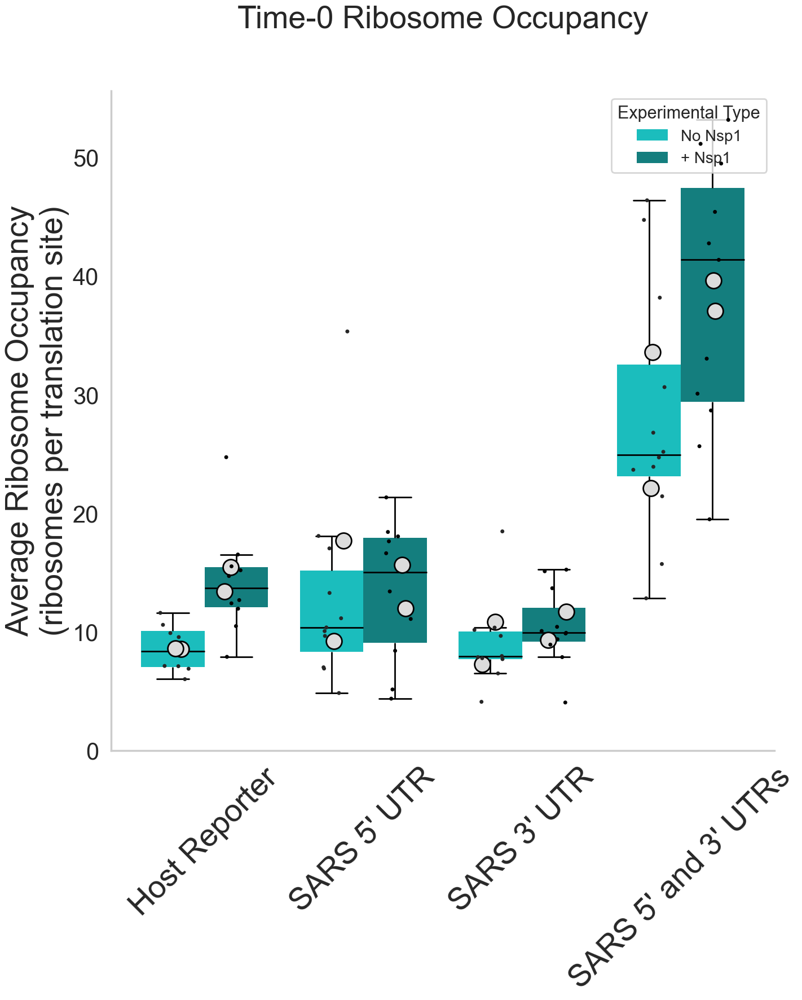

In [37]:
# CELL PURPOSE:
# Plot time-0 ribosome occupancy with the same explicit plotting structure
# used in crop_array_analysis(8).ipynb.

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# One value per cell
data = collapse_to_one_value_per_cell(
    cell_ribosome_kinetics_t0,
    "average_ribosome_occupancy",
).rename(
    columns={
        "_Replicate_ID": "Replicate_Number",
        "_Cell_ID": "Cell_ID",
    }
)

# Replicate-level averages, using the exact analysis-notebook helper
superplot = calculate_grouped_average(
    data,
    "average_ribosome_occupancy",
    ["Experimental_Group", "Experimental_Type", "Replicate_Number"],
)

# Plot order
order = [
    group for group in GROUP_ORDER
    if group in data["Experimental_Group"].astype(str).unique()
]
hue_order = [
    experimental_type for experimental_type in TYPE_ORDER
    if experimental_type in data["Experimental_Type"].astype(str).unique()
]

new_labels = [GROUP_LABELS.get(group, group) for group in order]

# Create the figure
fig, ax = plt.subplots(figsize=(16, 16), constrained_layout=True)

sns.despine(fig=fig, top=True, right=True, left=False, bottom=False)

# Individual-cell distribution
sns.boxplot(
    x="Experimental_Group",
    y="average_ribosome_occupancy",
    hue="Experimental_Type",
    data=data,
    order=order,
    hue_order=hue_order,
    ax=ax,
    palette=blue_palette,
    boxprops=dict(linewidth=0),
    whiskerprops=dict(color="black", linewidth=2),
    capprops=dict(color="black", linewidth=2),
    medianprops=dict(color="black", linewidth=2),
    showfliers=False,
)

# Individual cells
sns.stripplot(
    x="Experimental_Group",
    y="average_ribosome_occupancy",
    hue="Experimental_Type",
    data=data,
    order=order,
    hue_order=hue_order,
    color="black",
    alpha=1,
    size=5,
    jitter=0.2,
    dodge=True,
    ax=ax,
    zorder=9,
)

# Biological-replicate means
plot_open_circles_with_hue(
    ax,
    superplot,
    order=order,
    x="Experimental_Group",
    y="Super average_ribosome_occupancy",
    hue="Experimental_Type",
    hue_order=hue_order,
    jitter=True,
    jitter_strength=0.08,
    random_state=100,
)

ax.set_title("Time-0 Ribosome Occupancy", fontsize=40, pad=80)
ax.set_ylabel(
    "Average Ribosome Occupancy\n(ribosomes per translation site)",
    fontsize=40,
)
ax.set_xlabel("")
ax.set_ylim(bottom=0)
ax.tick_params(axis="both", which="major", labelsize=30)
ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))

# Keep one clean experimental-type legend
handles, labels = ax.get_legend_handles_labels()
legend_lookup = {}
for handle, label in zip(handles, labels):
    if label in hue_order and label not in legend_lookup:
        legend_lookup[label] = handle

if legend_lookup:
    ax.legend(
        [legend_lookup[label] for label in hue_order if label in legend_lookup],
        [TYPE_LABELS.get(label, label) for label in hue_order if label in legend_lookup],
        title="Experimental Type",
        fontsize=20,
        title_fontsize=22,
        loc="upper right",
    )
elif ax.get_legend() is not None:
    ax.get_legend().remove()

save_figure(fig, "tethered_ht_t0_ribosome_occupancy")

plt.tight_layout()
plt.show()

ribosome_occupancy_figure = fig
ribosome_occupancy_axis = ax
ribosome_occupancy_plot_data = data
ribosome_occupancy_replicate_means = superplot


### Statistics — Ribosome occupancy

In [38]:
# CELL PURPOSE: Cell-level statistics corresponding to the ribosome-occupancy plot.

ribosome_occupancy_cell_statistics = run_within_reporter_cell_tests(
    dataframe=cell_ribosome_kinetics_t0,
    value_column='average_ribosome_occupancy',
    analysis_name='Cell-level ribosome occupancy',
    group_order=GROUP_ORDER,
    transform='log',
)

save_and_display_statistics(
    ribosome_occupancy_cell_statistics,
    'tethered_ht_t0_ribosome_occupancy_cell_level_mixed_models',
    'Cell-level mixed models: ribosome occupancy',
)



Cell-level mixed models: ribosome occupancy
-------------------------------------------
Observation level: one averaged value per cell
Replicate handling: random intercept; blocked-model fallback if needed
Significance stars: Holm-adjusted p-values
Host Reporter: n=8/10 cells; 2 matched replicates; mean=8.59/14.2; effect=1.636 (ratio (comparison/reference)); p=7.276e-05; Holm p=0.000291; ***; Linear mixed-effects model
SARS 5' UTR: n=11/10 cells; 2 matched replicates; mean=13.06/13.44; effect=1.084 (ratio (comparison/reference)); p=0.6954; Holm p=0.6954; ns; Linear mixed-effects model
SARS 3' UTR: n=10/11 cells; 2 matched replicates; mean=9.049/10.4; effect=1.183 (ratio (comparison/reference)); p=0.2265; Holm p=0.453; ns; Linear mixed-effects model
SARS 5' and 3' UTRs: n=12/11 cells; 2 matched replicates; mean=27.84/38.2; effect=1.389 (ratio (comparison/reference)); p=0.0171; Holm p=0.0513; ns; Linear mixed-effects model
Parquet unavailable for tethered_ht_t0_ribosome_occupancy_cell_l

,analysis,value_column,comparison_column,reference_level,comparison_level,transform,effect_scale,n_reference_cells,n_comparison_cells,n_cells_total,n_reference_replicates,n_comparison_replicates,n_matched_replicates,reference_mean_raw,comparison_mean_raw,reference_median_raw,comparison_median_raw,raw_mean_difference_comparison_minus_reference,model_effect,model_effect_ci_low,model_effect_ci_high,standard_error,test_statistic,pvalue,model,replicate_adjustment,status,Experimental_Group,pvalue_holm,stars_raw,stars_holm,stars
0,Cell-level ribosome occupancy,average_ribosome_occupancy,Experimental_Type,No Nsp1,Nsp1,log,ratio (comparison/reference),8,10,18,2,2,2,8.590000,14.202550,8.335693,13.686595,5.612550,1.635847,1.282749,2.086141,0.124061,3.967079,0.000073,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,Control,0.000291,****,***,***
1,Cell-level ribosome occupancy,average_ribosome_occupancy,Experimental_Type,No Nsp1,Nsp1,log,ratio (comparison/reference),11,10,21,2,2,2,13.059143,13.441239,10.363698,15.011205,0.382096,1.083934,0.724087,1.622611,0.205841,0.391549,0.695392,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,SARS_5'UTR,0.695392,ns,ns,ns
2,Cell-level ribosome occupancy,average_ribosome_occupancy,Experimental_Type,No Nsp1,Nsp1,log,ratio (comparison/reference),10,11,21,2,2,2,9.049426,10.404363,7.906714,9.910466,1.354938,1.183362,0.900786,1.554582,0.139210,1.209392,0.226512,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,SARS_3'UTR,0.453025,ns,ns,ns
3,Cell-level ribosome occupancy,average_ribosome_occupancy,Experimental_Type,No Nsp1,Nsp1,log,ratio (comparison/reference),12,11,23,2,2,2,27.842193,38.200997,24.937357,41.362423,10.358804,1.389491,1.060315,1.820860,0.137947,2.384515,0.017102,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,SARS_5'_3'UTR,0.051305,*,ns,ns


### Plot — Initiation interval

C:\Users\AdamC\AppData\Local\Temp\ipykernel_8044\907211044.py:64: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


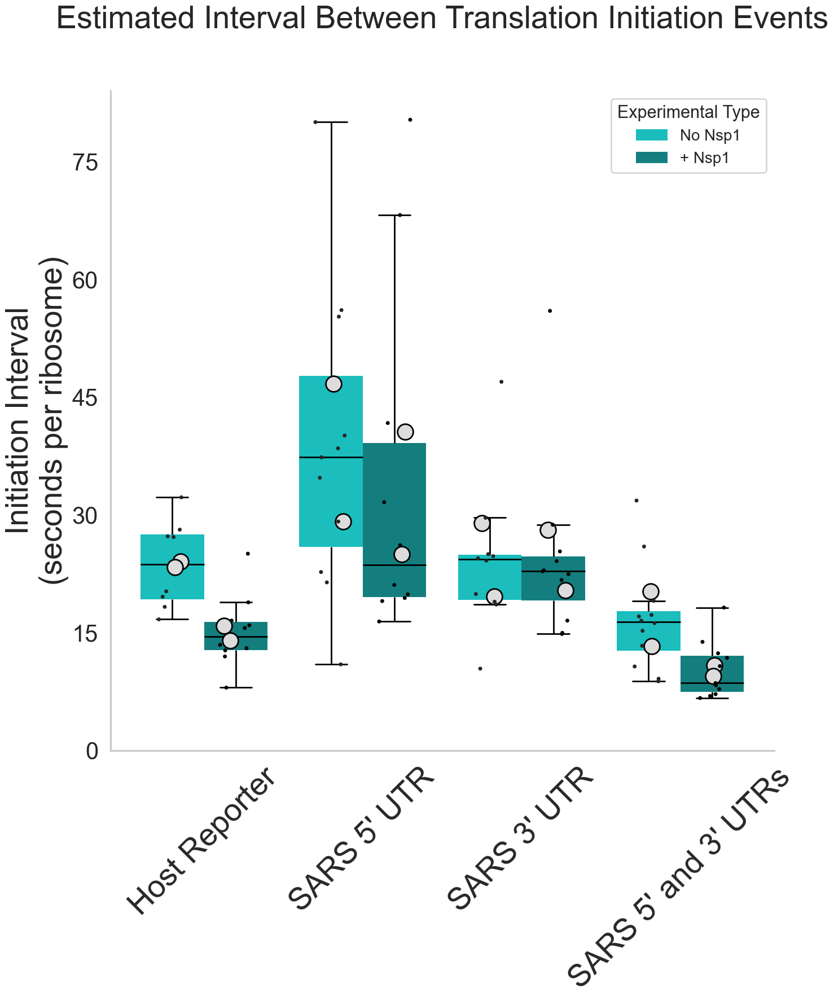

In [39]:
# CELL PURPOSE:
# Plot the estimated initiation interval with the same explicit plotting
# structure used in crop_array_analysis(8).ipynb.

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# One value per cell
data = collapse_to_one_value_per_cell(
    cell_ribosome_kinetics_t0,
    "initiation_interval_sec_per_ribosome",
).rename(
    columns={
        "_Replicate_ID": "Replicate_Number",
        "_Cell_ID": "Cell_ID",
    }
)

# Replicate-level averages
superplot = calculate_grouped_average(
    data,
    "initiation_interval_sec_per_ribosome",
    ["Experimental_Group", "Experimental_Type", "Replicate_Number"],
)

# Plot order
order = [
    group for group in GROUP_ORDER
    if group in data["Experimental_Group"].astype(str).unique()
]
hue_order = [
    experimental_type for experimental_type in TYPE_ORDER
    if experimental_type in data["Experimental_Type"].astype(str).unique()
]
new_labels = [GROUP_LABELS.get(group, group) for group in order]

# Create the figure
fig, ax = plt.subplots(figsize=(16, 16), constrained_layout=True)

sns.despine(fig=fig, top=True, right=True, left=False, bottom=False)

sns.boxplot(
    x="Experimental_Group",
    y="initiation_interval_sec_per_ribosome",
    hue="Experimental_Type",
    data=data,
    order=order,
    hue_order=hue_order,
    ax=ax,
    palette=blue_palette,
    boxprops=dict(linewidth=0),
    whiskerprops=dict(color="black", linewidth=2),
    capprops=dict(color="black", linewidth=2),
    medianprops=dict(color="black", linewidth=2),
    showfliers=False,
)

sns.stripplot(
    x="Experimental_Group",
    y="initiation_interval_sec_per_ribosome",
    hue="Experimental_Type",
    data=data,
    order=order,
    hue_order=hue_order,
    color="black",
    alpha=1,
    size=5,
    jitter=0.2,
    dodge=True,
    ax=ax,
    zorder=9,
)

plot_open_circles_with_hue(
    ax,
    superplot,
    order=order,
    x="Experimental_Group",
    y="Super initiation_interval_sec_per_ribosome",
    hue="Experimental_Type",
    hue_order=hue_order,
    jitter=True,
    jitter_strength=0.08,
    random_state=100,
)

ax.set_title(
    "Estimated Interval Between Translation Initiation Events",
    fontsize=40,
    pad=80,
)
ax.set_ylabel("Initiation Interval\n(seconds per ribosome)", fontsize=40)
ax.set_xlabel("")
ax.set_ylim(bottom=0)
ax.tick_params(axis="both", which="major", labelsize=30)
ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))

handles, labels = ax.get_legend_handles_labels()
legend_lookup = {}
for handle, label in zip(handles, labels):
    if label in hue_order and label not in legend_lookup:
        legend_lookup[label] = handle

if legend_lookup:
    ax.legend(
        [legend_lookup[label] for label in hue_order if label in legend_lookup],
        [TYPE_LABELS.get(label, label) for label in hue_order if label in legend_lookup],
        title="Experimental Type",
        fontsize=20,
        title_fontsize=22,
        loc="upper right",
    )
elif ax.get_legend() is not None:
    ax.get_legend().remove()

save_figure(fig, "tethered_ht_t0_initiation_interval")

plt.tight_layout()
plt.show()

initiation_interval_figure = fig
initiation_interval_axis = ax
initiation_interval_plot_data = data
initiation_interval_replicate_means = superplot


### Statistics — Initiation interval

In [40]:
# CELL PURPOSE: Cell-level statistics corresponding to the initiation-interval plot.

initiation_interval_cell_statistics = run_within_reporter_cell_tests(
    dataframe=cell_ribosome_kinetics_t0,
    value_column='initiation_interval_sec_per_ribosome',
    analysis_name='Cell-level initiation interval',
    group_order=GROUP_ORDER,
    transform='log',
)

save_and_display_statistics(
    initiation_interval_cell_statistics,
    'tethered_ht_t0_initiation_interval_cell_level_mixed_models',
    'Cell-level mixed models: initiation interval',
)



Cell-level mixed models: initiation interval
--------------------------------------------
Observation level: one averaged value per cell
Replicate handling: random intercept; blocked-model fallback if needed
Significance stars: Holm-adjusted p-values
Host Reporter: n=8/10 cells; 2 matched replicates; mean=23.7/15.11; effect=0.6242 (ratio (comparison/reference)); p=0.0001451; Holm p=0.0005804; ***; Linear mixed-effects model
SARS 5' UTR: n=11/10 cells; 2 matched replicates; mean=38.75/34.38; effect=0.8351 (ratio (comparison/reference)); p=0.3814; Holm p=0.7629; ns; Linear mixed-effects model
SARS 3' UTR: n=10/11 cells; 2 matched replicates; mean=24.28/24.58; effect=0.9931 (ratio (comparison/reference)); p=0.9603; Holm p=0.9603; ns; Linear mixed-effects model
SARS 5' and 3' UTRs: n=12/11 cells; 2 matched replicates; mean=16.76/10.21; effect=0.6251 (ratio (comparison/reference)); p=0.0006598; Holm p=0.001979; **; Linear mixed-effects model
Parquet unavailable for tethered_ht_t0_initiatio

,analysis,value_column,comparison_column,reference_level,comparison_level,transform,effect_scale,n_reference_cells,n_comparison_cells,n_cells_total,n_reference_replicates,n_comparison_replicates,n_matched_replicates,reference_mean_raw,comparison_mean_raw,reference_median_raw,comparison_median_raw,raw_mean_difference_comparison_minus_reference,model_effect,model_effect_ci_low,model_effect_ci_high,standard_error,test_statistic,pvalue,model,replicate_adjustment,status,Experimental_Group,pvalue_holm,stars_raw,stars_holm,stars
0,Cell-level initiation interval,initiation_interval_sec_per_ribosome,Experimental_Type,No Nsp1,Nsp1,log,ratio (comparison/reference),8,10,18,2,2,2,23.703127,15.112942,23.722274,14.517500,-8.590185,0.624161,0.489435,0.795972,0.124061,-3.799312,0.000145,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,Control,0.000580,***,***,***
1,Cell-level initiation interval,initiation_interval_sec_per_ribosome,Experimental_Type,No Nsp1,Nsp1,log,ratio (comparison/reference),11,10,21,2,2,2,38.752499,34.379931,37.337366,23.606135,-4.372568,0.835138,0.557888,1.250173,0.205841,-0.875230,0.381449,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,SARS_5'UTR,0.762897,ns,ns,ns
2,Cell-level initiation interval,initiation_interval_sec_per_ribosome,Experimental_Type,No Nsp1,Nsp1,log,ratio (comparison/reference),10,11,21,2,2,2,24.281720,24.582571,24.323323,22.804208,0.300852,0.993088,0.755948,1.304619,0.139210,-0.049824,0.960262,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,SARS_3'UTR,0.960262,ns,ns,ns
3,Cell-level initiation interval,initiation_interval_sec_per_ribosome,Experimental_Type,No Nsp1,Nsp1,log,ratio (comparison/reference),12,11,23,2,2,2,16.755216,10.211660,16.366320,8.569853,-6.543556,0.625116,0.477024,0.819185,0.137947,-3.405775,0.000660,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,SARS_5'_3'UTR,0.001979,***,**,**


## Part XIV — HT-resistant fraction plots and statistics

In [41]:
# CELL PURPOSE:
# Identify cell-level outliers in the HT-resistant fraction before plotting.
#
# Outliers are evaluated independently within each:
#     Experimental Group × Experimental Type × Replicate
#
# This preserves biological replicate differences and prevents a shifted
# replicate from being incorrectly treated as a collection of outlier cells.

# ------------------------------------------------------------------
# Outlier settings
# ------------------------------------------------------------------

REMOVE_HT_RESISTANT_OUTLIERS = True

HT_RESISTANT_OUTLIER_METHOD = 'iqr'

HT_RESISTANT_IQR_MULTIPLIER = 1.5

# Do not automatically screen very small groups.
HT_RESISTANT_MIN_GROUP_SIZE = 4

HT_RESISTANT_VALUE_COLUMN = (
    'HT_resistant_fraction (%)'
)

HT_RESISTANT_OUTLIER_GROUP_COLUMNS = [
    'Experimental_Group',
    'Experimental_Type',
    'Replicate_Number',
]

# Optional manual exclusions by fov.
# Leave empty unless a cell has an independently documented technical problem.
MANUAL_HT_RESISTANT_EXCLUDE_FOVS = [
    # 'movie_identifier_or_fov_here',
]


def flag_groupwise_outliers(
    dataframe,
    value_column,
    group_columns,
    method='iqr',
    iqr_multiplier=1.5,
    min_group_size=4,
    manual_exclude_fovs=None,
):
    """
    Flag cell-level outliers independently within each biological replicate.

    Supported methods
    -----------------
    iqr:
        Tukey fences:
            lower = Q1 - multiplier × IQR
            upper = Q3 + multiplier × IQR

    none:
        Disable automatic outlier detection while retaining manual exclusions.

    Notes
    -----
    - The input DataFrame is not modified.
    - Groups smaller than min_group_size are not automatically screened.
    - IQR = 0 does not trigger automatic exclusion.
    """

    flagged = dataframe.copy()

    if value_column not in flagged.columns:
        raise KeyError(
            f'Outlier value column not found: {value_column}'
        )

    missing_group_columns = [
        column
        for column in group_columns
        if column not in flagged.columns
    ]

    if missing_group_columns:
        raise KeyError(
            'Outlier grouping columns are missing:\n'
            f'{missing_group_columns}'
        )

    flagged[value_column] = pd.to_numeric(
        flagged[value_column],
        errors='coerce',
    )

    flagged['HT_resistant_outlier'] = False
    flagged['HT_resistant_outlier_reason'] = ''
    flagged['HT_resistant_group_n'] = 0

    flagged['HT_resistant_outlier_Q1'] = np.nan
    flagged['HT_resistant_outlier_Q3'] = np.nan
    flagged['HT_resistant_outlier_IQR'] = np.nan
    flagged['HT_resistant_outlier_lower_bound'] = np.nan
    flagged['HT_resistant_outlier_upper_bound'] = np.nan

    method = str(method).lower().strip()

    if method not in {
        'iqr',
        'none',
    }:
        raise ValueError(
            "HT_RESISTANT_OUTLIER_METHOD must be 'iqr' or 'none'."
        )

    for group_keys, group_index in flagged.groupby(
        group_columns,
        dropna=False,
    ).groups.items():

        group_values = flagged.loc[
            group_index,
            value_column,
        ]

        finite_mask = np.isfinite(
            group_values
        )

        finite_values = group_values.loc[
            finite_mask
        ]

        group_n = len(finite_values)

        flagged.loc[
            group_index,
            'HT_resistant_group_n',
        ] = group_n

        if (
            method == 'none'
            or group_n < min_group_size
        ):
            continue

        q1 = finite_values.quantile(
            0.25
        )

        q3 = finite_values.quantile(
            0.75
        )

        iqr = q3 - q1

        flagged.loc[
            group_index,
            'HT_resistant_outlier_Q1',
        ] = q1

        flagged.loc[
            group_index,
            'HT_resistant_outlier_Q3',
        ] = q3

        flagged.loc[
            group_index,
            'HT_resistant_outlier_IQR',
        ] = iqr

        # If all or most values are identical, do not automatically
        # classify small deviations using a zero-width interval.
        if (
            not np.isfinite(iqr)
            or iqr <= 0
        ):
            continue

        lower_bound = (
            q1
            - iqr_multiplier * iqr
        )

        upper_bound = (
            q3
            + iqr_multiplier * iqr
        )

        flagged.loc[
            group_index,
            'HT_resistant_outlier_lower_bound',
        ] = lower_bound

        flagged.loc[
            group_index,
            'HT_resistant_outlier_upper_bound',
        ] = upper_bound

        group_outlier_mask = (
            (
                flagged.loc[
                    group_index,
                    value_column,
                ]
                < lower_bound
            )
            |
            (
                flagged.loc[
                    group_index,
                    value_column,
                ]
                > upper_bound
            )
        )

        outlier_indices = group_outlier_mask.index[
            group_outlier_mask.fillna(False)
        ]

        flagged.loc[
            outlier_indices,
            'HT_resistant_outlier',
        ] = True

        flagged.loc[
            outlier_indices,
            'HT_resistant_outlier_reason',
        ] = (
            f'Tukey {iqr_multiplier:g}×IQR'
        )

    # --------------------------------------------------------------
    # Optional documented manual exclusions
    # --------------------------------------------------------------

    manual_exclude_fovs = (
        []
        if manual_exclude_fovs is None
        else list(manual_exclude_fovs)
    )

    if manual_exclude_fovs:

        if 'fov' not in flagged.columns:
            raise KeyError(
                'Manual fov exclusions were requested, but the '
                'DataFrame does not contain an fov column.'
            )

        manual_mask = (
            flagged['fov']
            .astype(str)
            .isin(
                [
                    str(value)
                    for value in manual_exclude_fovs
                ]
            )
        )

        flagged.loc[
            manual_mask,
            'HT_resistant_outlier',
        ] = True

        flagged.loc[
            manual_mask,
            'HT_resistant_outlier_reason',
        ] = flagged.loc[
            manual_mask,
            'HT_resistant_outlier_reason',
        ].apply(
            lambda current_reason:
            (
                f'{current_reason}; manual exclusion'
                if current_reason
                else 'Manual exclusion'
            )
        )

    return flagged


# ------------------------------------------------------------------
# Flag and separate the data
# ------------------------------------------------------------------

df_ht_resistant_flagged = (
    flag_groupwise_outliers(
        dataframe=df_ht_resistant,
        value_column=HT_RESISTANT_VALUE_COLUMN,
        group_columns=(
            HT_RESISTANT_OUTLIER_GROUP_COLUMNS
        ),
        method=HT_RESISTANT_OUTLIER_METHOD,
        iqr_multiplier=(
            HT_RESISTANT_IQR_MULTIPLIER
        ),
        min_group_size=(
            HT_RESISTANT_MIN_GROUP_SIZE
        ),
        manual_exclude_fovs=(
            MANUAL_HT_RESISTANT_EXCLUDE_FOVS
        ),
    )
)


ht_resistant_outliers = (
    df_ht_resistant_flagged.loc[
        df_ht_resistant_flagged[
            'HT_resistant_outlier'
        ]
    ]
    .copy()
)


if REMOVE_HT_RESISTANT_OUTLIERS:

    df_ht_resistant_plot = (
        df_ht_resistant_flagged.loc[
            ~df_ht_resistant_flagged[
                'HT_resistant_outlier'
            ]
        ]
        .copy()
    )

else:

    df_ht_resistant_plot = (
        df_ht_resistant_flagged.copy()
    )


# Recalculate replicate means from the retained cell values.
resistant_replicate_filtered = (
    df_ht_resistant_plot
    .groupby(
        [
            'Experimental_Group',
            'Experimental_Type',
            'Replicate_Number',
        ],
        dropna=False,
    )[
        HT_RESISTANT_VALUE_COLUMN
    ]
    .mean()
    .reset_index()
)


# ------------------------------------------------------------------
# Create an auditable summary
# ------------------------------------------------------------------

ht_resistant_outlier_summary = (
    df_ht_resistant_flagged
    .groupby(
        HT_RESISTANT_OUTLIER_GROUP_COLUMNS,
        dropna=False,
    )
    .agg(
        n_cells=(
            HT_RESISTANT_VALUE_COLUMN,
            'count',
        ),
        n_outliers=(
            'HT_resistant_outlier',
            'sum',
        ),
        lower_bound=(
            'HT_resistant_outlier_lower_bound',
            'first',
        ),
        upper_bound=(
            'HT_resistant_outlier_upper_bound',
            'first',
        ),
    )
    .reset_index()
)

ht_resistant_outlier_summary[
    'n_retained'
] = (
    ht_resistant_outlier_summary[
        'n_cells'
    ]
    - ht_resistant_outlier_summary[
        'n_outliers'
    ]
)


print('\nHT-resistant-fraction outlier screening')
print('----------------------------------------')
print(
    f'Method: {HT_RESISTANT_OUTLIER_METHOD}'
)
print(
    'Grouping: '
    + ' × '.join(
        HT_RESISTANT_OUTLIER_GROUP_COLUMNS
    )
)
print(
    f'IQR multiplier: '
    f'{HT_RESISTANT_IQR_MULTIPLIER:g}'
)
print(
    f'Minimum group size: '
    f'{HT_RESISTANT_MIN_GROUP_SIZE}'
)
print(
    f'Total cells: '
    f'{len(df_ht_resistant_flagged):,}'
)
print(
    f'Outliers flagged: '
    f'{len(ht_resistant_outliers):,}'
)
print(
    f'Cells plotted: '
    f'{len(df_ht_resistant_plot):,}'
)


save_table(
    df_ht_resistant_flagged,
    'tethered_ht_resistant_fraction_cell_outlier_flags',
)

save_table(
    ht_resistant_outliers,
    'tethered_ht_resistant_fraction_excluded_outliers',
)

save_table(
    df_ht_resistant_plot,
    'tethered_ht_resistant_fraction_cell_filtered',
)

save_table(
    resistant_replicate_filtered,
    'tethered_ht_resistant_fraction_replicate_filtered',
)

save_table(
    ht_resistant_outlier_summary,
    'tethered_ht_resistant_fraction_outlier_summary',
)


display(
    ht_resistant_outlier_summary
)

if not ht_resistant_outliers.empty:

    display_columns = [
        column
        for column in [
            'Experimental_Group',
            'Experimental_Type',
            'Replicate_Number',
            'fov',
            'Cell_Number',
            HT_RESISTANT_VALUE_COLUMN,
            'HT_resistant_outlier_lower_bound',
            'HT_resistant_outlier_upper_bound',
            'HT_resistant_outlier_reason',
        ]
        if column in ht_resistant_outliers.columns
    ]

    display(
        ht_resistant_outliers[
            display_columns
        ].sort_values(
            [
                'Experimental_Group',
                'Experimental_Type',
                'Replicate_Number',
                HT_RESISTANT_VALUE_COLUMN,
            ]
        )
    )


HT-resistant-fraction outlier screening
----------------------------------------
Method: iqr
Grouping: Experimental_Group × Experimental_Type × Replicate_Number
IQR multiplier: 1.5
Minimum group size: 4
Total cells: 83
Outliers flagged: 1
Cells plotted: 82
Parquet unavailable for tethered_ht_resistant_fraction_cell_outlier_flags: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.
Saved: Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT\Analysis_Output\Tethered_HT\Dataframes\tethered_ht_resistant_fraction_cell_outlier_flags.csv
Parquet unavailable for tethered_ht_resistant_f

,Experimental_Group,Experimental_Type,Replicate_Number,n_cells,n_outliers,lower_bound,upper_bound,n_retained
0,Control,No Nsp1,1,4,0,-3.801627,6.336045,4
1,Control,No Nsp1,2,4,0,-1.711617,8.007384,4
2,Control,Nsp1,1,4,0,1.860716,22.130154,4
3,Control,Nsp1,2,6,0,-6.340110,18.475196,6
4,SARS_3'UTR,No Nsp1,1,5,0,-2.833496,12.659002,5
5,SARS_3'UTR,No Nsp1,2,5,0,-1.963351,3.272251,5
6,SARS_3'UTR,Nsp1,1,5,0,-9.946950,16.578249,5
7,SARS_3'UTR,Nsp1,2,6,0,-4.902227,13.126626,6
8,SARS_5'UTR,No Nsp1,1,5,0,-2.880184,4.800307,5
9,SARS_5'UTR,No Nsp1,2,6,0,-0.251003,10.024702,6


,Experimental_Group,Experimental_Type,Replicate_Number,fov,Cell_Number,HT_resistant_fraction (%),HT_resistant_outlier_lower_bound,HT_resistant_outlier_upper_bound,HT_resistant_outlier_reason
55,SARS_5'_3'UTR,Nsp1,1,Nsp1_SARS_5_UTR_3_UTR_20260709_20260709_2_1_Cell02_processed_Cell02_TRNL_Ch1_nc,2,11.061947,-5.151119,10.476451,Tukey 1.5×IQR


### HT-resistant-fraction plotting convention

The previous HT-specific resistant-fraction plotting helpers have been removed.

The figures below now follow the same structure as the main analysis notebook:
individual-cell boxplot → individual-cell stripplot → replicate means from
`calculate_grouped_average()` → replicate open circles from
`plot_open_circles_with_hue()`. Each figure contains its own formatting code.


### Plot — Host Reporter HT-resistant fraction

C:\Users\AdamC\AppData\Local\Temp\ipykernel_8044\700676660.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


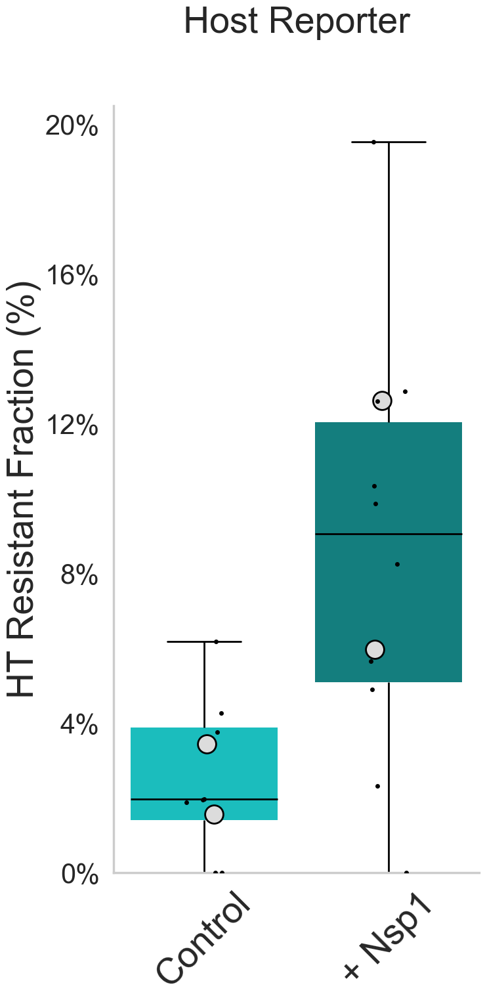

In [42]:
# CELL PURPOSE:
# Plot the Host Reporter HT-resistant fraction with explicit plot code matching
# the Host Reporter plotting style in crop_array_analysis(8).ipynb.

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Host Reporter only
data = df_ht_resistant_plot.loc[
    df_ht_resistant_plot["Experimental_Group"].astype(str).eq(str(CONTROL_GROUP))
    & df_ht_resistant_plot["Experimental_Type"].isin(TYPE_ORDER)
].copy()

control_resistant_outliers = ht_resistant_outliers.loc[
    ht_resistant_outliers["Experimental_Group"].astype(str).eq(str(CONTROL_GROUP))
    & ht_resistant_outliers["Experimental_Type"].isin(TYPE_ORDER)
].copy()

# Replicate-level averages
superplot = calculate_grouped_average(
    data,
    HT_RESISTANT_VALUE_COLUMN,
    ["Experimental_Group", "Experimental_Type", "Replicate_Number"],
)

# Define the order for the x-axis categories
order = [
    experimental_type for experimental_type in TYPE_ORDER
    if experimental_type in data["Experimental_Type"].astype(str).unique()
]

# Match the main analysis notebook display labels
type_label_map = {
    "No Nsp1": "Control",
    "Nsp1": "+ Nsp1",
    "NoCTD Nsp1": "+ Nsp1ΔC",
}
new_labels = [type_label_map.get(experimental_type, experimental_type) for experimental_type in order]

# Create a figure
fig, ax = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig, top=True, right=True, left=False, bottom=False)

# Individual-cell distribution
sns.boxplot(
    x="Experimental_Type",
    y=HT_RESISTANT_VALUE_COLUMN,
    data=data,
    order=order,
    ax=ax,
    palette=blue_palette,
    boxprops=dict(linewidth=0),
    whiskerprops=dict(color="black", linewidth=2),
    capprops=dict(color="black", linewidth=2),
    medianprops=dict(color="black", linewidth=2),
    showfliers=False,
)

# Individual cells
sns.stripplot(
    x="Experimental_Type",
    y=HT_RESISTANT_VALUE_COLUMN,
    data=data,
    order=order,
    color="black",
    alpha=1,
    size=5,
    jitter=True,
    dodge=True,
    ax=ax,
    zorder=9,
)

# Biological-replicate means
plot_open_circles_with_hue(
    ax,
    superplot,
    order=order,
    x="Experimental_Type",
    y=f"Super {HT_RESISTANT_VALUE_COLUMN}",
    hue="Experimental_Group",
    jitter=True,
    jitter_strength=0.08,
    random_state=100,
)

ax.set_title(GROUP_LABELS.get(CONTROL_GROUP, CONTROL_GROUP), fontsize=40, pad=80)
ax.set_ylabel("HT Resistant Fraction (%)", fontsize=40)
ax.set_xlabel("")
ax.set_ylim(bottom=0)
ax.tick_params(axis="both", which="major", labelsize=30)
ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0f}%"))

# No legend is needed because experimental type is on the x-axis
if ax.get_legend() is not None:
    ax.get_legend().remove()

save_figure(
    fig,
    "HT_Resistant_Fraction_Host_Reporter_Paired_Outliers_Removed",
)

plt.tight_layout()
plt.show()

control_resistant = data
control_resistant_figure = fig
control_resistant_axis = ax
control_resistant_replicate_means = superplot


### Statistics — Host Reporter HT-resistant fraction

In [85]:
# CELL PURPOSE: Cell-level statistics corresponding to the Host Reporter resistant-fraction plot.

control_resistant_cell_statistics = run_within_reporter_cell_tests(
    dataframe=control_resistant,
    value_column=HT_RESISTANT_VALUE_COLUMN,
    analysis_name='Host Reporter cell-level HT-resistant fraction',
    group_order=[CONTROL_GROUP],
    transform='log1p',
)

save_and_display_statistics(
    control_resistant_cell_statistics,
    'tethered_ht_host_resistant_fraction_cell_level_mixed_model',
    'Cell-level mixed model: Host Reporter HT-resistant fraction',
)



Cell-level mixed model: Host Reporter HT-resistant fraction
-----------------------------------------------------------
Observation level: one averaged value per cell
Replicate handling: random intercept; blocked-model fallback if needed
Significance stars: Holm-adjusted p-values
Host Reporter: n=10/7 cells; 2 matched replicates; mean=2.345/6.293; effect=1.983 (ratio of (value + 1)); p=0.1518; Holm p=0.1518; ns; Replicate-blocked linear model (fallback)
Parquet unavailable for tethered_ht_host_resistant_fraction_cell_level_mixed_model: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.
Sav

,analysis,value_column,comparison_column,reference_level,comparison_level,transform,effect_scale,n_reference_cells,n_comparison_cells,n_cells_total,n_reference_replicates,n_comparison_replicates,n_matched_replicates,reference_mean_raw,comparison_mean_raw,reference_median_raw,comparison_median_raw,raw_mean_difference_comparison_minus_reference,model_effect,model_effect_ci_low,model_effect_ci_high,standard_error,test_statistic,pvalue,model,replicate_adjustment,status,Experimental_Group,pvalue_holm,stars_raw,stars_holm,stars
0,Host Reporter cell-level HT-resistant fraction,HT_resistant_fraction (%),Experimental_Type,No Nsp1,Nsp1,log1p,ratio of (value + 1),10,7,17,2,2,2,2.344635,6.292928,1.956955,5.643341,3.948294,1.98255,0.77757,5.054861,0.477543,1.433137,0.151819,Replicate-blocked linear model (fallback),Replicate included as a fixed blocking factor; HC3 SE,Test completed; MixedLM failed: Singular matrix,Control,0.151819,ns,ns,ns


### Plot — HT-resistant fraction across all reporters

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30524\460444822.py:63: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


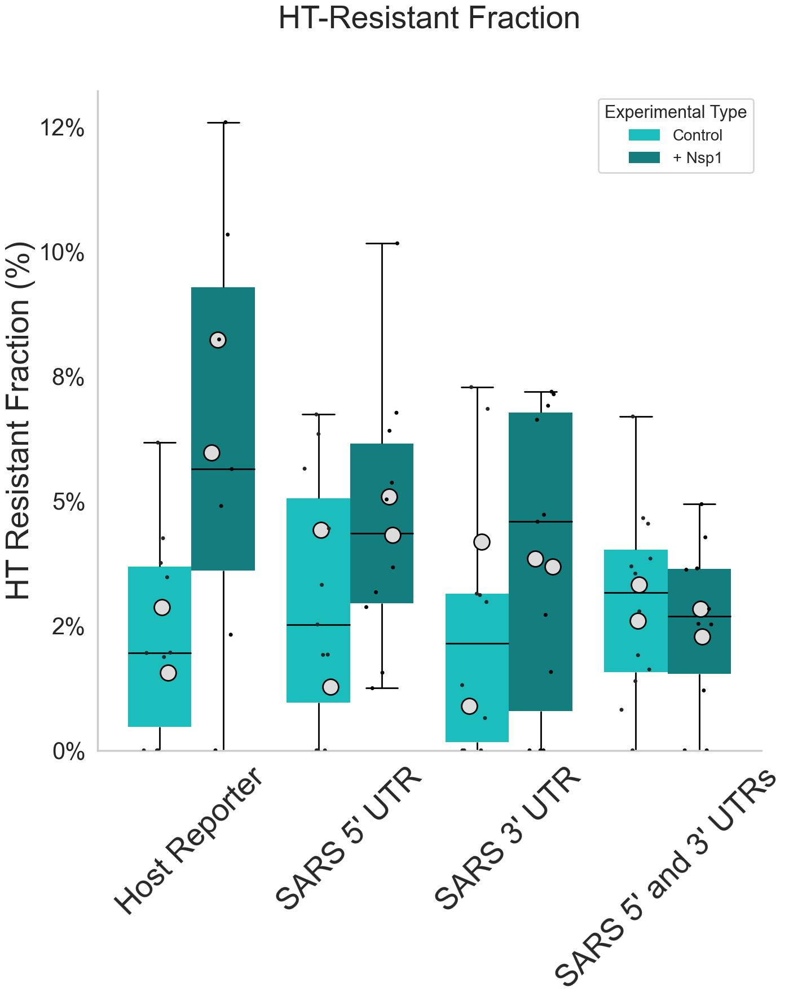

In [86]:
# CELL PURPOSE:
# Plot the HT-resistant fraction across all reporter groups with explicit code
# and the same replicate-average overlay used in crop_array_analysis(8).ipynb.

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

all_resistant = df_ht_resistant_plot.loc[
    df_ht_resistant_plot["Experimental_Group"].isin(GROUP_ORDER)
    & df_ht_resistant_plot["Experimental_Type"].isin(TYPE_ORDER)
].copy()

all_resistant_outliers = ht_resistant_outliers.loc[
    ht_resistant_outliers["Experimental_Group"].isin(GROUP_ORDER)
    & ht_resistant_outliers["Experimental_Type"].isin(TYPE_ORDER)
].copy()

# Replicate-level averages
superplot = calculate_grouped_average(
    all_resistant,
    HT_RESISTANT_VALUE_COLUMN,
    ["Experimental_Group", "Experimental_Type", "Replicate_Number"],
)

# Plot order
order = [
    group for group in GROUP_ORDER
    if group in all_resistant["Experimental_Group"].astype(str).unique()
]
hue_order = [
    experimental_type for experimental_type in TYPE_ORDER
    if experimental_type in all_resistant["Experimental_Type"].astype(str).unique()
]
new_labels = [GROUP_LABELS.get(group, group) for group in order]

# Create a figure
fig, ax = plt.subplots(figsize=(16, 16), constrained_layout=True)

sns.despine(fig=fig, top=True, right=True, left=False, bottom=False)

sns.boxplot(
    x="Experimental_Group",
    y=HT_RESISTANT_VALUE_COLUMN,
    hue="Experimental_Type",
    data=all_resistant,
    order=order,
    hue_order=hue_order,
    ax=ax,
    palette=blue_palette,
    boxprops=dict(linewidth=0),
    whiskerprops=dict(color="black", linewidth=2),
    capprops=dict(color="black", linewidth=2),
    medianprops=dict(color="black", linewidth=2),
    showfliers=False,
)

sns.stripplot(
    x="Experimental_Group",
    y=HT_RESISTANT_VALUE_COLUMN,
    hue="Experimental_Type",
    data=all_resistant,
    order=order,
    hue_order=hue_order,
    color="black",
    alpha=1,
    size=5,
    jitter=0.2,
    dodge=True,
    ax=ax,
    zorder=9,
)

plot_open_circles_with_hue(
    ax,
    superplot,
    order=order,
    x="Experimental_Group",
    y=f"Super {HT_RESISTANT_VALUE_COLUMN}",
    hue="Experimental_Type",
    hue_order=hue_order,
    jitter=True,
    jitter_strength=0.08,
    random_state=100,
)

ax.set_title("HT-Resistant Fraction", fontsize=40, pad=80)
ax.set_ylabel("HT Resistant Fraction (%)", fontsize=40)
ax.set_xlabel("")
ax.set_ylim(bottom=0)
ax.tick_params(axis="both", which="major", labelsize=30)
ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0f}%"))

# Keep one clean experimental-type legend
handles, labels = ax.get_legend_handles_labels()
legend_lookup = {}
for handle, label in zip(handles, labels):
    if label in hue_order and label not in legend_lookup:
        legend_lookup[label] = handle

if legend_lookup:
    ax.legend(
        [legend_lookup[label] for label in hue_order if label in legend_lookup],
        [
            {"No Nsp1": "Control", "Nsp1": "+ Nsp1", "NoCTD Nsp1": "+ Nsp1ΔC"}.get(label, label)
            for label in hue_order if label in legend_lookup
        ],
        title="Experimental Type",
        fontsize=20,
        title_fontsize=22,
        loc="upper right",
    )
elif ax.get_legend() is not None:
    ax.get_legend().remove()

save_figure(
    fig,
    "HT_Resistant_Fraction_All_Groups_Paired_Outliers_Removed",
)

plt.tight_layout()
plt.show()

all_resistant_figure = fig
all_resistant_axis = ax
all_resistant_replicate_means = superplot


### Statistics — HT-resistant fraction across all reporters

In [44]:
# CELL PURPOSE: Cell-level statistics corresponding to the all-reporter resistant-fraction plot.

all_resistant_cell_statistics = run_within_reporter_cell_tests(
    dataframe=all_resistant,
    value_column=HT_RESISTANT_VALUE_COLUMN,
    analysis_name='Cell-level HT-resistant fraction',
    group_order=GROUP_ORDER,
    transform='log1p',
)

save_and_display_statistics(
    all_resistant_cell_statistics,
    'tethered_ht_all_resistant_fraction_cell_level_mixed_models',
    'Cell-level mixed models: HT-resistant fraction',
)



Cell-level mixed models: HT-resistant fraction
----------------------------------------------
Observation level: one averaged value per cell
Replicate handling: random intercept; blocked-model fallback if needed
Significance stars: Holm-adjusted p-values
Host Reporter: n=10/6 cells; 1 matched replicates; mean=2.345/5.968; effect=1.579 (ratio of (value + 1)); p=0.3815; Holm p=1; ns; Replicate-blocked linear model (fallback)
SARS 5' UTR: n=11/10 cells; 2 matched replicates; mean=2.988/4.627; effect=1.593 (ratio of (value + 1)); p=0.08909; Holm p=0.3564; ns; Linear mixed-effects model
SARS 3' UTR: n=10/11 cells; 2 matched replicates; mean=2.533/3.771; effect=1.353 (ratio of (value + 1)); p=0.4017; Holm p=1; ns; Linear mixed-effects model
SARS 5' and 3' UTRs: n=12/10 cells; 2 matched replicates; mean=2.959/2.559; effect=0.8787 (ratio of (value + 1)); p=0.6016; Holm p=1; ns; Linear mixed-effects model
Parquet unavailable for tethered_ht_all_resistant_fraction_cell_level_mixed_models: Unabl

,analysis,value_column,comparison_column,reference_level,comparison_level,transform,effect_scale,n_reference_cells,n_comparison_cells,n_cells_total,n_reference_replicates,n_comparison_replicates,n_matched_replicates,reference_mean_raw,comparison_mean_raw,reference_median_raw,comparison_median_raw,raw_mean_difference_comparison_minus_reference,model_effect,model_effect_ci_low,model_effect_ci_high,standard_error,test_statistic,pvalue,model,replicate_adjustment,status,Experimental_Group,pvalue_holm,stars_raw,stars_holm,stars
0,Cell-level HT-resistant fraction,HT_resistant_fraction (%),Experimental_Type,No Nsp1,Nsp1,log1p,ratio of (value + 1),10,6,16,2,1,1,2.344635,5.968123,1.956955,5.272651,3.623489,1.579125,0.567569,4.393541,0.522083,0.875092,0.381524,Replicate-blocked linear model (fallback),Replicate included as a fixed blocking factor; HC3 SE,Test completed; MixedLM failed: Singular matrix,Control,1.000000,ns,ns,ns
1,Cell-level HT-resistant fraction,HT_resistant_fraction (%),Experimental_Type,No Nsp1,Nsp1,log1p,ratio of (value + 1),11,10,21,2,2,2,2.987733,4.627301,2.525253,4.351641,1.639568,1.592806,0.931348,2.724041,0.273790,1.700194,0.089094,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,SARS_5'UTR,0.356377,ns,ns,ns
2,Cell-level HT-resistant fraction,HT_resistant_fraction (%),Experimental_Type,No Nsp1,Nsp1,log1p,ratio of (value + 1),10,11,21,2,2,2,2.532797,3.771238,2.142545,4.587156,1.238441,1.352783,0.667555,2.741380,0.360362,0.838500,0.401750,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | Random effects covariance is singular | Random effects covariance is singular | ...,SARS_3'UTR,1.000000,ns,ns,ns
3,Cell-level HT-resistant fraction,HT_resistant_fraction (%),Experimental_Type,No Nsp1,Nsp1,log1p,ratio of (value + 1),12,10,22,2,2,2,2.958805,2.558673,3.167102,2.687475,-0.400132,0.878693,0.540787,1.427738,0.247663,-0.522158,0.601560,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,SARS_5'_3'UTR,1.000000,ns,ns,ns


### Statistics — Cross-reporter No Nsp1 comparison

In [45]:
# CELL PURPOSE: Cross-reporter cell-level comparisons for No Nsp1 HT-resistant fraction.

no_nsp1_resistant_cross_reporter_cell_statistics = run_cross_reporter_cell_tests(
    dataframe=all_resistant,
    value_column=HT_RESISTANT_VALUE_COLUMN,
    analysis_name='No Nsp1 HT-resistant fraction versus Host Reporter',
    experimental_type='No Nsp1',
    reference_group=CONTROL_GROUP,
    group_order=GROUP_ORDER,
    transform='log1p',
)

save_and_display_statistics(
    no_nsp1_resistant_cross_reporter_cell_statistics,
    'tethered_ht_no_nsp1_resistant_fraction_cross_reporter_cell_level_mixed_models',
    'Cell-level mixed models: No Nsp1 resistant fraction versus Host Reporter',
)



Cell-level mixed models: No Nsp1 resistant fraction versus Host Reporter
------------------------------------------------------------------------
Observation level: one averaged value per cell
Replicate handling: random intercept; blocked-model fallback if needed
Significance stars: Holm-adjusted p-values
SARS 5' UTR: n=10/11 cells; 2 matched replicates; mean=2.345/2.988; effect=1.2 (ratio of (value + 1)); p=0.5257; Holm p=1; ns; Linear mixed-effects model
SARS 3' UTR: n=10/10 cells; 2 matched replicates; mean=2.345/2.533; effect=0.9543 (ratio of (value + 1)); p=0.8869; Holm p=1; ns; Linear mixed-effects model
SARS 5' and 3' UTRs: n=10/12 cells; 2 matched replicates; mean=2.345/2.959; effect=1.305 (ratio of (value + 1)); p=0.319; Holm p=0.9569; ns; Linear mixed-effects model
Parquet unavailable for tethered_ht_no_nsp1_resistant_fraction_cross_reporter_cell_level_mixed_models: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastpa

,analysis,value_column,comparison_column,reference_level,comparison_level,transform,effect_scale,n_reference_cells,n_comparison_cells,n_cells_total,n_reference_replicates,n_comparison_replicates,n_matched_replicates,reference_mean_raw,comparison_mean_raw,reference_median_raw,comparison_median_raw,raw_mean_difference_comparison_minus_reference,model_effect,model_effect_ci_low,model_effect_ci_high,standard_error,test_statistic,pvalue,model,replicate_adjustment,status,Experimental_Type,reference_group,comparison_group,pvalue_holm,stars_raw,stars_holm,stars
0,No Nsp1 HT-resistant fraction versus Host Reporter,HT_resistant_fraction (%),Experimental_Group,Control,SARS_5'UTR,log1p,ratio of (value + 1),10,11,21,2,2,2,2.344635,2.987733,1.956955,2.525253,0.643098,1.199677,0.683746,2.104909,0.286852,0.634654,0.525654,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,No Nsp1,Control,SARS_5'UTR,1.000000,ns,ns,ns
1,No Nsp1 HT-resistant fraction versus Host Reporter,HT_resistant_fraction (%),Experimental_Group,Control,SARS_3'UTR,log1p,ratio of (value + 1),10,10,20,2,2,2,2.344635,2.532797,1.956955,2.142545,0.188162,0.954338,0.501173,1.817258,0.328611,-0.142227,0.886901,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,No Nsp1,Control,SARS_3'UTR,1.000000,ns,ns,ns
2,No Nsp1 HT-resistant fraction versus Host Reporter,HT_resistant_fraction (%),Experimental_Group,Control,SARS_5'_3'UTR,log1p,ratio of (value + 1),10,12,22,2,2,2,2.344635,2.958805,1.956955,3.167102,0.614170,1.305083,0.773049,2.203280,0.267189,0.996550,0.318983,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,No Nsp1,Control,SARS_5'_3'UTR,0.956949,ns,ns,ns


## Part XV — Fitted HT runoff plots

The residual-aware tanh is fit continuously from **frame 4 (HT addition, 0 min)**
through the complete runoff trajectory. Frame 5 (~+1 min) is included, allowing
the upper shoulder of the runoff to constrain the fitted transition width.

The ~1-minute HT-action delay is displayed/interpreted separately; it is not
implemented by forcing a flat fitted segment and it is not subtracted from the
tanh-width-derived elongation rate.


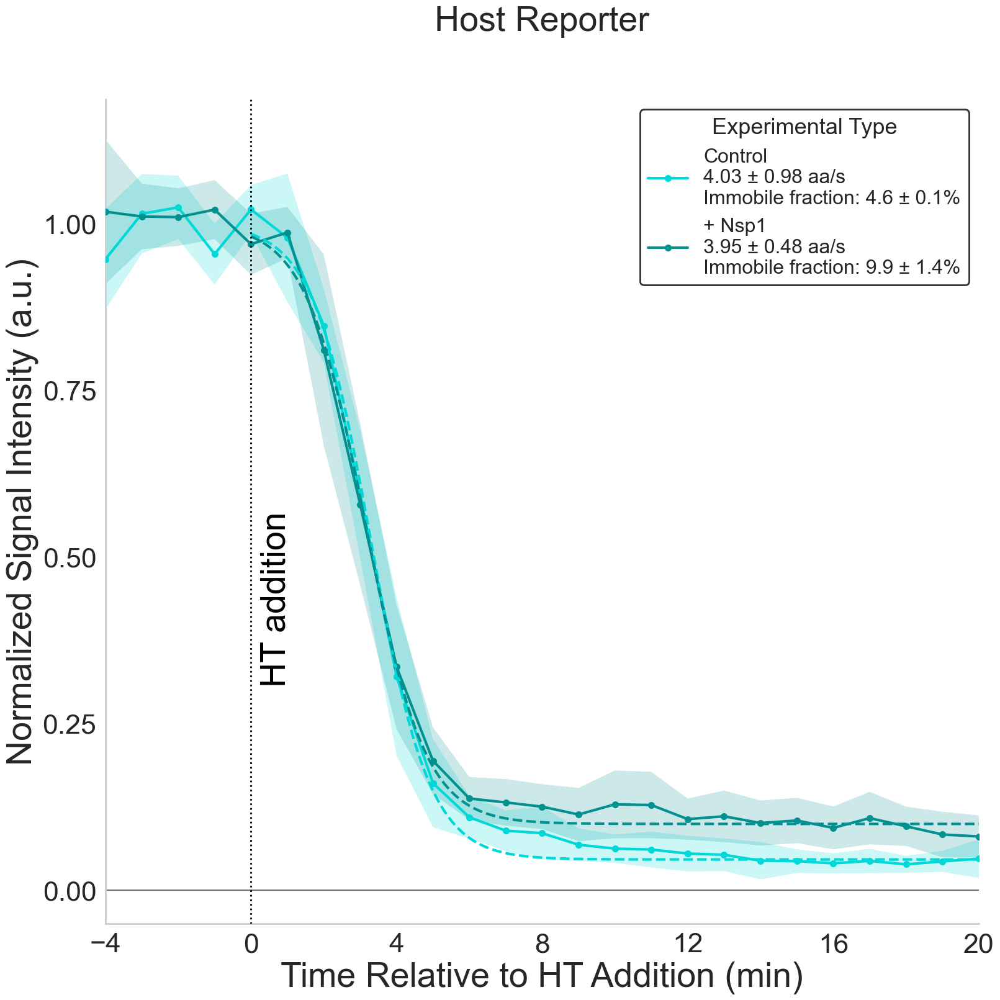

In [69]:
# CELL PURPOSE:
# Plot the fitted HT runoff curves for the Host Reporter.
#
# Main envelope:
#     Two-sided 95% CI across individual cells at each time point.
#
# Parameter uncertainty:
#     SEM across biological-replicate mean-curve fits.
#
# Dashed curves:
#     Fits to the complete group-average curves.
#
# Dotted horizontal lines:
#     Fitted immobile fraction with replicate-level SEM bands.

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import t as student_t
from matplotlib.ticker import MaxNLocator


# ============================================================
# Figure-specific formatting controls
# ============================================================

sns.set(font_scale=1.9)
sns.set_style(
    "whitegrid",
    {"grid.linestyle": ""},
)
sns.set_context("poster")

FIGURE_WIDTH = 16
FIGURE_HEIGHT = 16

TITLE_SIZE = 40
AXIS_LABEL_SIZE = 40
X_TICK_SIZE = 32
Y_TICK_SIZE = 32

LEGEND_SIZE = 23
LEGEND_TITLE_SIZE = 26

AXIS_LINE_WIDTH = 2.0
TICK_WIDTH = 2.0
TICK_LENGTH = 7

HT_ADDITION_TEXT_X = 0.25
HT_ADDITION_TEXT_Y = 0.5

X_LIMITS = (-4, 20)
Y_LIMITS = None

# Opacity of the cell-level 95% CI envelope.
CI_ALPHA = 0.20

# ============================================================
# Fit each biological-replicate mean curve
#
# These replicate-level fits are used only to estimate the SEM
# of the elongation rate and fitted immobile fraction.
# ============================================================

host_cell_data = cell_time_runoff.loc[
    cell_time_runoff[
        "Experimental_Group"
    ]
    .astype(str)
    .eq(str(CONTROL_GROUP))
    &
    cell_time_runoff[
        "Experimental_Type"
    ]
    .isin(TYPE_ORDER)
].copy()


replicate_fit_rows = []


for (
    experimental_type,
    replicate_number,
), replicate_data in host_cell_data.groupby(
    [
        "Experimental_Type",
        "Replicate_Number",
    ],
    dropna=False,
    sort=False,
):

    # --------------------------------------------------------
    # Calculate the mean runoff curve for this replicate.
    # --------------------------------------------------------

    replicate_curve = (
        replicate_data
        .groupby(
            "t",
            dropna=False,
        )[FIT_METRIC]
        .agg(
            mean="mean",
            sem="sem",
            n_cells="count",
        )
        .reset_index()
        .sort_values("t")
    )


    # --------------------------------------------------------
    # Calculate the measured endpoint fraction for this
    # biological replicate.
    # --------------------------------------------------------

    endpoint_keys = [
        column
        for column in CELL_KEYS
        if column in replicate_data.columns
    ]

    endpoint_values = (
        replicate_data[
            [
                *endpoint_keys,
                ENDPOINT_FRACTION_METRIC,
            ]
        ]
        .drop_duplicates(
            subset=endpoint_keys
        )[ENDPOINT_FRACTION_METRIC]
        .dropna()
    )


    if not endpoint_values.empty:

        measured_immobile_fraction = (
            endpoint_values.mean()
        )

    else:

        measured_immobile_fraction = np.nan


    # --------------------------------------------------------
    # Fit this replicate's mean curve using the same residual-
    # aware tanh model as the complete group-average curve.
    # --------------------------------------------------------

    fit_result, _ = fit_one_residual_tanh_curve(
        frame=replicate_curve.rename(
            columns={
                "mean": FIT_METRIC,
            }
        ),
        metric=FIT_METRIC,
        measured_residual_fraction=measured_immobile_fraction,
        sem_column="sem",
    )


    replicate_fit_rows.append(
        {
            "Experimental_Type": experimental_type,
            "Replicate_Number": replicate_number,
            **fit_result,
        }
    )


host_replicate_fits_for_plot = pd.DataFrame(
    replicate_fit_rows
)


# ============================================================
# Keep only usable replicate fits
# ============================================================

if not host_replicate_fits_for_plot.empty:

    usable_replicate_fits = (
        host_replicate_fits_for_plot.loc[
            host_replicate_fits_for_plot[
                "fit_usable"
            ]
            .fillna(False)
        ]
        .copy()
    )

else:

    usable_replicate_fits = pd.DataFrame()


# ============================================================
# Calculate SEM across biological-replicate fitted parameters
# ============================================================

if not usable_replicate_fits.empty:

    host_parameter_sem = (
        usable_replicate_fits
        .groupby(
            "Experimental_Type",
            dropna=False,
        )
        .agg(
            elongation_rate_sem=(
                "elongation_rate_aa_per_sec",
                "sem",
            ),
            immobile_fraction_sem=(
                "fitted_residual_fraction",
                "sem",
            ),
        )
        .reset_index()
    )

else:

    host_parameter_sem = pd.DataFrame(
        columns=[
            "Experimental_Type",
            "elongation_rate_sem",
            "immobile_fraction_sem",
        ]
    )


parameter_sem_lookup = (
    host_parameter_sem
    .set_index(
        "Experimental_Type"
    )
    .to_dict(
        orient="index"
    )
    if not host_parameter_sem.empty
    else {}
)


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        FIGURE_WIDTH,
        FIGURE_HEIGHT,
    ),
    constrained_layout=True,
)


for experimental_type in TYPE_ORDER:

    # --------------------------------------------------------
    # Select all individual-cell data for this condition.
    # --------------------------------------------------------

    cell_curve_data = host_cell_data.loc[
        host_cell_data[
            "Experimental_Type"
        ]
        .astype(str)
        .eq(str(experimental_type))
    ].copy()


    # --------------------------------------------------------
    # Calculate the complete cell-level mean curve and 95% CI.
    # --------------------------------------------------------

    curve = (
        cell_curve_data
        .groupby(
            "t",
            dropna=False,
        )[FIT_METRIC]
        .agg(
            mean="mean",
            sem="sem",
            n_cells="count",
        )
        .reset_index()
        .sort_values("t")
    )


    # Student's t critical value for a two-sided 95% CI.
    curve["t_critical_95"] = student_t.ppf(
        0.975,
        curve["n_cells"] - 1,
    )

    curve["ci95_half_width"] = (
        curve["t_critical_95"]
        * curve["sem"]
    )

    curve["ci95_lower"] = (
        curve["mean"]
        - curve["ci95_half_width"]
    )

    curve["ci95_upper"] = (
        curve["mean"]
        + curve["ci95_half_width"]
    )


    # --------------------------------------------------------
    # Complete group-average fitted curve.
    # --------------------------------------------------------

    fit_curve = (
        tanh_group_curves_display.loc[
            tanh_group_curves_display[
                "Experimental_Group"
            ]
            .astype(str)
            .eq(str(CONTROL_GROUP))
            &
            tanh_group_curves_display[
                "Experimental_Type"
            ]
            .astype(str)
            .eq(str(experimental_type))
        ]
        .copy()
        .sort_values("t")
    )


    # --------------------------------------------------------
    # Complete group-average fitted parameters.
    # --------------------------------------------------------

    fit_information = (
        tanh_group_fits.loc[
            tanh_group_fits[
                "Experimental_Group"
            ]
            .astype(str)
            .eq(str(CONTROL_GROUP))
            &
            tanh_group_fits[
                "Experimental_Type"
            ]
            .astype(str)
            .eq(str(experimental_type))
        ]
        .copy()
    )


    # --------------------------------------------------------
    # Plot appearance
    # --------------------------------------------------------

    color = TYPE_COLORS.get(
        experimental_type,
        "gray",
    )

    display_name = {
        "No Nsp1": "Control",
        "Nsp1": "+ Nsp1",
        "NoCTD Nsp1": "+ Nsp1ΔC",
    }.get(
        experimental_type,
        TYPE_LABELS.get(
            experimental_type,
            experimental_type,
        ),
    )


    # --------------------------------------------------------
    # Read the complete-data fitted parameters.
    # --------------------------------------------------------

    group_rate = np.nan
    group_immobile_fraction = np.nan


    if not fit_information.empty:

        group_rate = pd.to_numeric(
            fit_information.iloc[0][
                "runoff rate (aa/sec)"
            ],
            errors="coerce",
        )

        group_immobile_fraction = pd.to_numeric(
            fit_information.iloc[0][
                "fitted_residual_fraction"
            ],
            errors="coerce",
        )


    # --------------------------------------------------------
    # Read the biological-replicate SEM values.
    # --------------------------------------------------------

    sem_info = parameter_sem_lookup.get(
        experimental_type,
        {},
    )

    rate_sem = sem_info.get(
        "elongation_rate_sem",
        np.nan,
    )

    immobile_fraction_sem = sem_info.get(
        "immobile_fraction_sem",
        np.nan,
    )


    # --------------------------------------------------------
    # Format elongation-rate label.
    # --------------------------------------------------------

    if np.isfinite(group_rate):

        if np.isfinite(rate_sem):

            rate_label = (
                f"{group_rate:.2f} ± "
                f"{rate_sem:.2f} aa/s"
            )

        else:

            rate_label = (
                f"{group_rate:.2f} aa/s"
            )

    else:

        rate_label = "Elongation rate unavailable"


    # --------------------------------------------------------
    # Format immobile-fraction label.
    # --------------------------------------------------------

    if np.isfinite(group_immobile_fraction):

        if np.isfinite(immobile_fraction_sem):

            immobile_label = (
                f"Immobile fraction: "
                f"{100 * group_immobile_fraction:.1f} "
                f"± "
                f"{100 * immobile_fraction_sem:.1f}%"
            )

        else:

            immobile_label = (
                f"Immobile fraction: "
                f"{100 * group_immobile_fraction:.1f}%"
            )

    else:

        immobile_label = (
            "Immobile fraction unavailable"
        )


    legend_label = (
        f"{display_name}\n"
        f"{rate_label}\n"
        f"{immobile_label}"
    )


    # --------------------------------------------------------
    # Plot measured mean with cell-level 95% CI.
    # --------------------------------------------------------

    if not curve.empty:

        display_time = (
            curve["t"]
            - HT_ADDITION_FRAME
        ) * FRAME_INTERVAL_MIN


        ax.fill_between(
            display_time,
            curve["ci95_lower"],
            curve["ci95_upper"],
            color=color,
            alpha=CI_ALPHA,
            linewidth=0,
            zorder=1,
        )


        ax.plot(
            display_time,
            curve["mean"],
            marker="o",
            markersize=8,
            markeredgewidth=0,
            linewidth=3,
            color=color,
            label=legend_label,
            zorder=3,
        )


    # --------------------------------------------------------
    # Plot the complete group-average tanh fit.
    # --------------------------------------------------------

    if not fit_curve.empty:

        fit_display_time = (
            fit_curve["t"]
            - HT_ADDITION_FRAME
        ) * FRAME_INTERVAL_MIN


        ax.plot(
            fit_display_time,
            fit_curve[
                "fit_value_display"
            ],
            linestyle="--",
            linewidth=3,
            color=color,
            label="_nolegend_",
            zorder=4,
        )



# ============================================================
# Zero reference and HT addition marker
# ============================================================

ax.axhline(
    0,
    color="black",
    linewidth=1.5,
    alpha=0.55,
    label="_nolegend_",
    zorder=0,
)


ax.axvline(
    0,
    color="black",
    linestyle=":",
    linewidth=2,
    label="_nolegend_",
    zorder=5,
)


ax.text(
    HT_ADDITION_TEXT_X,
    HT_ADDITION_TEXT_Y,
    "HT addition",
    transform=ax.get_xaxis_transform(),
    rotation=90,
    verticalalignment="top",
    horizontalalignment="left",
    fontsize=40,
    color="black",
)


# ============================================================
# Figure-specific formatting
# ============================================================

ax.set_title(
    GROUP_LABELS.get(
        CONTROL_GROUP,
        CONTROL_GROUP,
    ),
    fontsize=TITLE_SIZE,
    pad=80,
)


ax.set_xlabel(
    "Time Relative to HT Addition (min)",
    fontsize=AXIS_LABEL_SIZE,
)


ax.set_ylabel(
    "Normalized Signal Intensity (a.u.)",
    fontsize=AXIS_LABEL_SIZE,
)


plt.setp(
    ax.get_xticklabels(),
    fontsize=X_TICK_SIZE,
)


plt.setp(
    ax.get_yticklabels(),
    fontsize=Y_TICK_SIZE,
)


ax.tick_params(
    axis="both",
    which="major",
    width=TICK_WIDTH,
    length=TICK_LENGTH,
)


for spine in ax.spines.values():

    spine.set_linewidth(
        AXIS_LINE_WIDTH
    )


ax.xaxis.set_major_locator(
    MaxNLocator(
        integer=True,
        nbins=7,
    )
)


ax.yaxis.set_major_locator(
    MaxNLocator(
        nbins=6,
    )
)


if X_LIMITS is not None:

    ax.set_xlim(
        X_LIMITS
    )


if Y_LIMITS is not None:

    ax.set_ylim(
        Y_LIMITS
    )

else:

    ax.set_ylim(
        bottom=-0.05
    )


ax.legend(
    title="Experimental Type",
    fontsize=LEGEND_SIZE,
    title_fontsize=LEGEND_TITLE_SIZE,
    frameon=True,
    facecolor="white",
    edgecolor="black",
    loc="upper right",
)


sns.despine(
    fig=fig,
    top=True,
    right=True,
    left=False,
    bottom=False,
)


save_figure(
    fig,
    "HT_Runoff_Host_Reporter_Paired_Tanh_Fit",
)


plt.show()


host_reporter_runoff_figure = fig
host_reporter_runoff_axis = ax

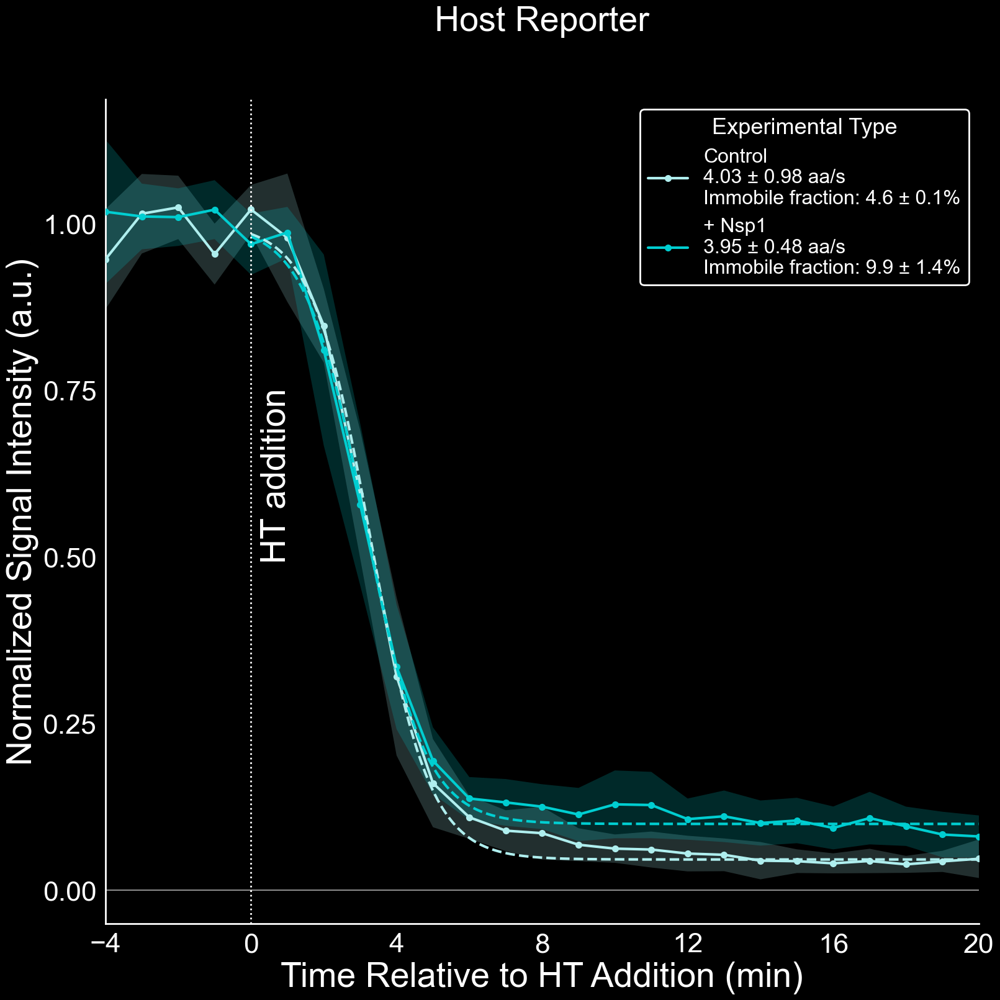

In [90]:
# CELL PURPOSE:
# Plot the fitted HT runoff curves for the Host Reporter.
#
# Main envelope:
#     Two-sided 95% CI across individual cells at each time point.
#
# Parameter uncertainty:
#     SEM across biological-replicate mean-curve fits.
#
# Dashed curves:
#     Fits to the complete group-average curves.
#
# Dotted horizontal lines:
#     Fitted immobile fraction with replicate-level SEM bands.
#
# BLACK-BACKGROUND VERSION
#
# COLOR SCHEME:
#     Control = cyan
#     + Nsp1  = darkcyan


import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

from scipy.stats import t as student_t
from matplotlib.ticker import MaxNLocator
from matplotlib.colors import to_rgba


# ============================================================
# BLACK-BACKGROUND FORMATTING
# ============================================================

mpl.rcParams.update(
    {
        "figure.facecolor": "black",
        "axes.facecolor": "black",
        "savefig.facecolor": "black",
        "text.color": "white",
        "axes.labelcolor": "white",
        "axes.edgecolor": "white",
        "xtick.color": "white",
        "ytick.color": "white",
    }
)


def _is_dark_color(
    color,
    threshold=0.28,
):
    """
    Identify black / very-dark plot elements that need to
    become white on a black background.
    """

    try:

        r, g, b, a = to_rgba(
            color
        )

    except Exception:

        return False

    return (
        a > 0.05
        and
        max(
            r,
            g,
            b,
        ) < threshold
    )


def finalize_black_axes(
    ax
):
    """
    Convert an existing Matplotlib axis for presentation
    on a black background without altering colored data.
    """

    ax.set_facecolor(
        "black"
    )


    # --------------------------------------------------------
    # Titles / labels / ticks
    # --------------------------------------------------------

    ax.title.set_color(
        "white"
    )

    ax.xaxis.label.set_color(
        "white"
    )

    ax.yaxis.label.set_color(
        "white"
    )

    ax.tick_params(
        axis="both",
        which="both",
        colors="white",
    )

    for label in (
        ax.get_xticklabels()
        +
        ax.get_yticklabels()
    ):

        label.set_color(
            "white"
        )


    # --------------------------------------------------------
    # Visible spines
    # --------------------------------------------------------

    for spine in ax.spines.values():

        if spine.get_visible():

            spine.set_color(
                "white"
            )


    # --------------------------------------------------------
    # Convert dark line objects to white.
    #
    # Colored experimental curves remain unchanged.
    # --------------------------------------------------------

    for line in ax.lines:

        try:

            if _is_dark_color(
                line.get_color()
            ):

                line.set_color(
                    "white"
                )

        except Exception:

            pass


    # --------------------------------------------------------
    # Convert dark annotations to white.
    # --------------------------------------------------------

    for text in ax.texts:

        try:

            if _is_dark_color(
                text.get_color()
            ):

                text.set_color(
                    "white"
                )

        except Exception:

            pass


    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------

    legend = ax.get_legend()

    if legend is not None:

        frame = legend.get_frame()

        frame.set_facecolor(
            "black"
        )

        frame.set_edgecolor(
            "white"
        )

        for text in legend.get_texts():

            text.set_color(
                "white"
            )

        if legend.get_title() is not None:

            legend.get_title().set_color(
                "white"
            )


    return ax


def finalize_black_figure(
    fig
):
    """
    Convert complete figure to black-background presentation
    formatting.
    """

    fig.patch.set_facecolor(
        "black"
    )

    for axis in fig.axes:

        finalize_black_axes(
            axis
        )

    return fig


# ============================================================
# Figure-specific formatting controls
# ============================================================

sns.set(
    font_scale=1.9
)

sns.set_context(
    "poster"
)

sns.set_style(
    "dark",
    {
        "axes.facecolor":
            "black",

        "figure.facecolor":
            "black",

        "axes.edgecolor":
            "white",

        "axes.labelcolor":
            "white",

        "xtick.color":
            "white",

        "ytick.color":
            "white",

        "text.color":
            "white",

        "grid.linestyle":
            "",
    },
)


FIGURE_WIDTH = 16
FIGURE_HEIGHT = 16

TITLE_SIZE = 40
AXIS_LABEL_SIZE = 40
X_TICK_SIZE = 32
Y_TICK_SIZE = 32

LEGEND_SIZE = 23
LEGEND_TITLE_SIZE = 26

AXIS_LINE_WIDTH = 2.0
TICK_WIDTH = 2.0
TICK_LENGTH = 7

HT_ADDITION_TEXT_X = 0.25
HT_ADDITION_TEXT_Y = 0.65

X_LIMITS = (-4, 20)
Y_LIMITS = None

# Opacity of the cell-level 95% CI envelope.
CI_ALPHA = 0.20


# ============================================================
# FIGURE-SPECIFIC COLORS FOR BLACK BACKGROUND
# ============================================================

PLOT_TYPE_COLORS = {

    "No Nsp1":
        "paleturquoise",

    "Nsp1":
        "darkturquoise",

    # Included in case this condition is plotted later.
    "NoCTD Nsp1":
        "deepskyblue",
}


# ============================================================
# Fit each biological-replicate mean curve
#
# These replicate-level fits are used only to estimate the SEM
# of the elongation rate and fitted immobile fraction.
# ============================================================

host_cell_data = cell_time_runoff.loc[
    cell_time_runoff[
        "Experimental_Group"
    ]
    .astype(str)
    .eq(str(CONTROL_GROUP))
    &
    cell_time_runoff[
        "Experimental_Type"
    ]
    .isin(TYPE_ORDER)
].copy()


replicate_fit_rows = []


for (
    experimental_type,
    replicate_number,
), replicate_data in host_cell_data.groupby(
    [
        "Experimental_Type",
        "Replicate_Number",
    ],
    dropna=False,
    sort=False,
):

    # --------------------------------------------------------
    # Calculate the mean runoff curve for this replicate.
    # --------------------------------------------------------

    replicate_curve = (
        replicate_data
        .groupby(
            "t",
            dropna=False,
        )[FIT_METRIC]
        .agg(
            mean="mean",
            sem="sem",
            n_cells="count",
        )
        .reset_index()
        .sort_values("t")
    )


    # --------------------------------------------------------
    # Calculate the measured endpoint fraction for this
    # biological replicate.
    # --------------------------------------------------------

    endpoint_keys = [
        column
        for column in CELL_KEYS
        if column in replicate_data.columns
    ]


    endpoint_values = (
        replicate_data[
            [
                *endpoint_keys,
                ENDPOINT_FRACTION_METRIC,
            ]
        ]
        .drop_duplicates(
            subset=endpoint_keys
        )[ENDPOINT_FRACTION_METRIC]
        .dropna()
    )


    if not endpoint_values.empty:

        measured_immobile_fraction = (
            endpoint_values.mean()
        )

    else:

        measured_immobile_fraction = np.nan


    # --------------------------------------------------------
    # Fit this replicate's mean curve using the same residual-
    # aware tanh model as the complete group-average curve.
    # --------------------------------------------------------

    fit_result, _ = fit_one_residual_tanh_curve(
        frame=replicate_curve.rename(
            columns={
                "mean": FIT_METRIC,
            }
        ),
        metric=FIT_METRIC,
        measured_residual_fraction=measured_immobile_fraction,
        sem_column="sem",
    )


    replicate_fit_rows.append(
        {
            "Experimental_Type":
                experimental_type,

            "Replicate_Number":
                replicate_number,

            **fit_result,
        }
    )


host_replicate_fits_for_plot = pd.DataFrame(
    replicate_fit_rows
)


# ============================================================
# Keep only usable replicate fits
# ============================================================

if not host_replicate_fits_for_plot.empty:

    usable_replicate_fits = (
        host_replicate_fits_for_plot.loc[
            host_replicate_fits_for_plot[
                "fit_usable"
            ]
            .fillna(False)
        ]
        .copy()
    )

else:

    usable_replicate_fits = pd.DataFrame()


# ============================================================
# Calculate SEM across biological-replicate fitted parameters
# ============================================================

if not usable_replicate_fits.empty:

    host_parameter_sem = (
        usable_replicate_fits
        .groupby(
            "Experimental_Type",
            dropna=False,
        )
        .agg(

            elongation_rate_sem=(
                "elongation_rate_aa_per_sec",
                "sem",
            ),

            immobile_fraction_sem=(
                "fitted_residual_fraction",
                "sem",
            ),

        )
        .reset_index()
    )

else:

    host_parameter_sem = pd.DataFrame(
        columns=[
            "Experimental_Type",
            "elongation_rate_sem",
            "immobile_fraction_sem",
        ]
    )


parameter_sem_lookup = (
    host_parameter_sem
    .set_index(
        "Experimental_Type"
    )
    .to_dict(
        orient="index"
    )
    if not host_parameter_sem.empty
    else {}
)


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        FIGURE_WIDTH,
        FIGURE_HEIGHT,
    ),
    constrained_layout=True,
)


# Explicit black backgrounds from the start.
fig.patch.set_facecolor(
    "black"
)

ax.set_facecolor(
    "black"
)


for experimental_type in TYPE_ORDER:

    # --------------------------------------------------------
    # Select all individual-cell data for this condition.
    # --------------------------------------------------------

    cell_curve_data = host_cell_data.loc[
        host_cell_data[
            "Experimental_Type"
        ]
        .astype(str)
        .eq(str(experimental_type))
    ].copy()


    # --------------------------------------------------------
    # Calculate complete cell-level mean curve and 95% CI.
    # --------------------------------------------------------

    curve = (
        cell_curve_data
        .groupby(
            "t",
            dropna=False,
        )[FIT_METRIC]
        .agg(
            mean="mean",
            sem="sem",
            n_cells="count",
        )
        .reset_index()
        .sort_values("t")
    )


    # Student's t critical value for a two-sided 95% CI.
    curve[
        "t_critical_95"
    ] = student_t.ppf(
        0.975,
        curve[
            "n_cells"
        ] - 1,
    )


    curve[
        "ci95_half_width"
    ] = (
        curve[
            "t_critical_95"
        ]
        *
        curve[
            "sem"
        ]
    )


    curve[
        "ci95_lower"
    ] = (
        curve[
            "mean"
        ]
        -
        curve[
            "ci95_half_width"
        ]
    )


    curve[
        "ci95_upper"
    ] = (
        curve[
            "mean"
        ]
        +
        curve[
            "ci95_half_width"
        ]
    )


    # --------------------------------------------------------
    # Complete group-average fitted curve.
    # --------------------------------------------------------

    fit_curve = (
        tanh_group_curves_display.loc[
            tanh_group_curves_display[
                "Experimental_Group"
            ]
            .astype(str)
            .eq(str(CONTROL_GROUP))
            &
            tanh_group_curves_display[
                "Experimental_Type"
            ]
            .astype(str)
            .eq(str(experimental_type))
        ]
        .copy()
        .sort_values("t")
    )


    # --------------------------------------------------------
    # Complete group-average fitted parameters.
    # --------------------------------------------------------

    fit_information = (
        tanh_group_fits.loc[
            tanh_group_fits[
                "Experimental_Group"
            ]
            .astype(str)
            .eq(str(CONTROL_GROUP))
            &
            tanh_group_fits[
                "Experimental_Type"
            ]
            .astype(str)
            .eq(str(experimental_type))
        ]
        .copy()
    )


    # --------------------------------------------------------
    # Plot appearance
    # --------------------------------------------------------

    color = PLOT_TYPE_COLORS.get(
        experimental_type,
        "gray",
    )


    display_name = {

        "No Nsp1":
            "Control",

        "Nsp1":
            "+ Nsp1",

        "NoCTD Nsp1":
            "+ Nsp1ΔC",

    }.get(
        experimental_type,

        TYPE_LABELS.get(
            experimental_type,
            experimental_type,
        ),
    )


    # --------------------------------------------------------
    # Read complete-data fitted parameters.
    # --------------------------------------------------------

    group_rate = np.nan

    group_immobile_fraction = np.nan


    if not fit_information.empty:

        group_rate = pd.to_numeric(
            fit_information.iloc[
                0
            ][
                "runoff rate (aa/sec)"
            ],
            errors="coerce",
        )


        group_immobile_fraction = pd.to_numeric(
            fit_information.iloc[
                0
            ][
                "fitted_residual_fraction"
            ],
            errors="coerce",
        )


    # --------------------------------------------------------
    # Biological-replicate SEM.
    # --------------------------------------------------------

    sem_info = parameter_sem_lookup.get(
        experimental_type,
        {},
    )


    rate_sem = sem_info.get(
        "elongation_rate_sem",
        np.nan,
    )


    immobile_fraction_sem = sem_info.get(
        "immobile_fraction_sem",
        np.nan,
    )


    # --------------------------------------------------------
    # Elongation-rate label.
    # --------------------------------------------------------

    if np.isfinite(
        group_rate
    ):

        if np.isfinite(
            rate_sem
        ):

            rate_label = (
                f"{group_rate:.2f} ± "
                f"{rate_sem:.2f} aa/s"
            )

        else:

            rate_label = (
                f"{group_rate:.2f} aa/s"
            )

    else:

        rate_label = (
            "Elongation rate unavailable"
        )


    # --------------------------------------------------------
    # Immobile-fraction label.
    # --------------------------------------------------------

    if np.isfinite(
        group_immobile_fraction
    ):

        if np.isfinite(
            immobile_fraction_sem
        ):

            immobile_label = (
                f"Immobile fraction: "
                f"{100 * group_immobile_fraction:.1f} "
                f"± "
                f"{100 * immobile_fraction_sem:.1f}%"
            )

        else:

            immobile_label = (
                f"Immobile fraction: "
                f"{100 * group_immobile_fraction:.1f}%"
            )

    else:

        immobile_label = (
            "Immobile fraction unavailable"
        )


    legend_label = (
        f"{display_name}\n"
        f"{rate_label}\n"
        f"{immobile_label}"
    )


    # --------------------------------------------------------
    # Plot measured mean with cell-level 95% CI.
    # --------------------------------------------------------

    if not curve.empty:

        display_time = (
            curve[
                "t"
            ]
            -
            HT_ADDITION_FRAME
        ) * FRAME_INTERVAL_MIN


        ax.fill_between(
            display_time,
            curve[
                "ci95_lower"
            ],
            curve[
                "ci95_upper"
            ],
            color=color,
            alpha=CI_ALPHA,
            linewidth=0,
            zorder=1,
        )


        ax.plot(
            display_time,
            curve[
                "mean"
            ],
            marker="o",
            markersize=8,
            markeredgewidth=0,
            linewidth=3,
            color=color,
            label=legend_label,
            zorder=3,
        )


    # --------------------------------------------------------
    # Plot complete group-average tanh fit.
    # --------------------------------------------------------

    if not fit_curve.empty:

        fit_display_time = (
            fit_curve[
                "t"
            ]
            -
            HT_ADDITION_FRAME
        ) * FRAME_INTERVAL_MIN


        ax.plot(
            fit_display_time,
            fit_curve[
                "fit_value_display"
            ],
            linestyle="--",
            linewidth=3,
            color=color,
            label="_nolegend_",
            zorder=4,
        )


# ============================================================
# Zero reference and HT addition marker
# ============================================================

ax.axhline(
    0,
    color="white",
    linewidth=1.5,
    alpha=0.55,
    label="_nolegend_",
    zorder=0,
)


ax.axvline(
    0,
    color="white",
    linestyle=":",
    linewidth=2,
    label="_nolegend_",
    zorder=5,
)


ax.text(
    HT_ADDITION_TEXT_X,
    HT_ADDITION_TEXT_Y,
    "HT addition",
    transform=ax.get_xaxis_transform(),
    rotation=90,
    verticalalignment="top",
    horizontalalignment="left",
    fontsize=40,
    color="white",
)


# ============================================================
# Figure-specific formatting
# ============================================================

ax.set_title(
    GROUP_LABELS.get(
        CONTROL_GROUP,
        CONTROL_GROUP,
    ),
    fontsize=TITLE_SIZE,
    pad=80,
    color="white",
)


ax.set_xlabel(
    "Time Relative to HT Addition (min)",
    fontsize=AXIS_LABEL_SIZE,
    color="white",
)


ax.set_ylabel(
    "Normalized Signal Intensity (a.u.)",
    fontsize=AXIS_LABEL_SIZE,
    color="white",
)


plt.setp(
    ax.get_xticklabels(),
    fontsize=X_TICK_SIZE,
    color="white",
)


plt.setp(
    ax.get_yticklabels(),
    fontsize=Y_TICK_SIZE,
    color="white",
)


ax.tick_params(
    axis="both",
    which="major",
    width=TICK_WIDTH,
    length=TICK_LENGTH,
    colors="white",
)


for spine in ax.spines.values():

    spine.set_linewidth(
        AXIS_LINE_WIDTH
    )

    spine.set_color(
        "white"
    )


ax.xaxis.set_major_locator(
    MaxNLocator(
        integer=True,
        nbins=7,
    )
)


ax.yaxis.set_major_locator(
    MaxNLocator(
        nbins=6,
    )
)


if X_LIMITS is not None:

    ax.set_xlim(
        X_LIMITS
    )


if Y_LIMITS is not None:

    ax.set_ylim(
        Y_LIMITS
    )

else:

    ax.set_ylim(
        bottom=-0.05
    )


# ============================================================
# Black-background legend
# ============================================================

legend = ax.legend(
    title="Experimental Type",
    fontsize=LEGEND_SIZE,
    title_fontsize=LEGEND_TITLE_SIZE,
    frameon=True,
    facecolor="black",
    edgecolor="white",
    labelcolor="white",
    loc="upper right",
)


legend.get_frame().set_alpha(
    1
)


legend.get_title().set_color(
    "white"
)


for legend_text in legend.get_texts():

    legend_text.set_color(
        "white"
    )


# ============================================================
# Remove top/right spines while retaining white left/bottom
# ============================================================

sns.despine(
    fig=fig,
    top=True,
    right=True,
    left=False,
    bottom=False,
)


# ============================================================
# FINAL BLACK-BACKGROUND PASS
#
# Must occur BEFORE save_figure() and plt.show().
# ============================================================

finalize_black_figure(
    fig
)


save_figure(
    fig,
    "HT_Runoff_Host_Reporter_Paired_Tanh_Fit",
)


plt.show()


host_reporter_runoff_figure = fig
host_reporter_runoff_axis = ax

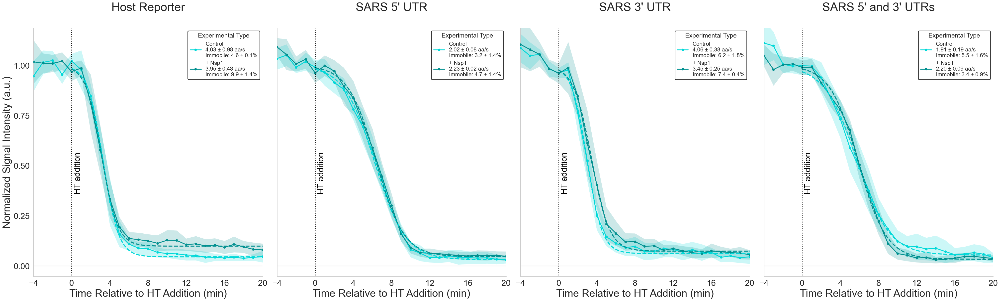

In [58]:
# CELL PURPOSE:
# Create the 1×4 fitted HT runoff panel using the same plotting and
# uncertainty workflow as the single-group Host Reporter plot.
#
# Main envelope:
#     Two-sided 95% CI across individual cells at each time point.
#
# Parameter uncertainty:
#     SEM across biological-replicate mean-curve fits.
#
# Dashed curves:
#     Fits to the complete group-average curves.
#
# Legend:
#     Runoff rate ± replicate-fit SEM
#     Immobile fraction ± replicate-fit SEM
# ============================================================

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import t as student_t
from matplotlib.ticker import MaxNLocator


# ============================================================
# FIGURE-SPECIFIC FORMATTING
# ============================================================

sns.set(font_scale=1.9)

sns.set_style(
    "whitegrid",
    {
        "grid.linestyle": ""
    }
)

sns.set_context(
    "poster"
)


# Four reporter groups
groups_to_plot = list(
    GROUP_ORDER[:4]
)


# ------------------------------------------------------------
# Figure dimensions
#
# Wide figure because all four panels are on one row.
# ------------------------------------------------------------

FIGURE_WIDTH = 40
FIGURE_HEIGHT = 12


TITLE_SIZE = 34

AXIS_LABEL_SIZE = 30

X_TICK_SIZE = 24
Y_TICK_SIZE = 24


LEGEND_SIZE = 16
LEGEND_TITLE_SIZE = 18


AXIS_LINE_WIDTH = 2.0
TICK_WIDTH = 2.0
TICK_LENGTH = 7


HT_ADDITION_TEXT_X = 0.25
HT_ADDITION_TEXT_Y = 0.50


X_LIMITS = (
    -4,
    20,
)


Y_LIMITS = None


# Opacity of the cell-level 95% CI envelope.
CI_ALPHA = 0.20


# ============================================================
# DISPLAY LABELS
# ============================================================

type_display_names = {

    "No Nsp1":
        "Control",

    "Nsp1":
        "+ Nsp1",

    "NoCTD Nsp1":
        "+ Nsp1ΔC",
}


# ============================================================
# FIT EACH BIOLOGICAL-REPLICATE MEAN CURVE
#
# These replicate-level fits are used ONLY to calculate the SEM
# of:
#
#     runoff rate
#     fitted immobile fraction
#
# The plotted dashed fit remains the fit to the complete
# group-average curve.
# ============================================================

multi_replicate_fit_rows = []


for group_name in groups_to_plot:


    # --------------------------------------------------------
    # Individual-cell runoff data for this reporter.
    # --------------------------------------------------------

    group_cell_data = (

        cell_time_runoff.loc[

            cell_time_runoff[
                "Experimental_Group"
            ]
            .astype(str)
            .eq(
                str(
                    group_name
                )
            )

            &

            cell_time_runoff[
                "Experimental_Type"
            ]
            .isin(
                TYPE_ORDER
            )

        ]

        .copy()
    )


    if group_cell_data.empty:

        continue


    # --------------------------------------------------------
    # Biological replicates within each Experimental Type.
    # --------------------------------------------------------

    for (
        experimental_type,
        replicate_number,
    ), replicate_data in group_cell_data.groupby(

        [
            "Experimental_Type",
            "Replicate_Number",
        ],

        dropna=False,
        sort=False,
    ):


        # ====================================================
        # MEAN RUNOFF CURVE FOR THIS BIOLOGICAL REPLICATE
        # ====================================================

        replicate_curve = (

            replicate_data

            .groupby(
                "t",
                dropna=False,
            )[
                FIT_METRIC
            ]

            .agg(
                mean="mean",
                sem="sem",
                n_cells="count",
            )

            .reset_index()

            .sort_values(
                "t"
            )
        )


        # ====================================================
        # MEASURED ENDPOINT FRACTION FOR THIS REPLICATE
        # ====================================================

        endpoint_keys = [

            column

            for column in CELL_KEYS

            if column
            in replicate_data.columns
        ]


        endpoint_values = (

            replicate_data[
                [
                    *endpoint_keys,
                    ENDPOINT_FRACTION_METRIC,
                ]
            ]

            .drop_duplicates(
                subset=
                    endpoint_keys
            )[
                ENDPOINT_FRACTION_METRIC
            ]

            .dropna()
        )


        if not endpoint_values.empty:

            measured_immobile_fraction = (
                endpoint_values.mean()
            )

        else:

            measured_immobile_fraction = (
                np.nan
            )


        # ====================================================
        # FIT BIOLOGICAL-REPLICATE MEAN CURVE
        # ====================================================

        fit_result, _ = (
            fit_one_residual_tanh_curve(

                frame=
                    replicate_curve.rename(
                        columns={
                            "mean":
                                FIT_METRIC,
                        }
                    ),

                metric=
                    FIT_METRIC,

                measured_residual_fraction=
                    measured_immobile_fraction,

                sem_column=
                    "sem",
            )
        )


        multi_replicate_fit_rows.append(
            {

                "Experimental_Group":
                    group_name,

                "Experimental_Type":
                    experimental_type,

                "Replicate_Number":
                    replicate_number,

                **fit_result,
            }
        )


# ============================================================
# REPLICATE-FIT DATAFRAME
# ============================================================

multi_replicate_fits_for_plot = (
    pd.DataFrame(
        multi_replicate_fit_rows
    )
)


# ============================================================
# KEEP ONLY USABLE BIOLOGICAL-REPLICATE FITS
# ============================================================

if not multi_replicate_fits_for_plot.empty:

    usable_multi_replicate_fits = (

        multi_replicate_fits_for_plot.loc[

            multi_replicate_fits_for_plot[
                "fit_usable"
            ]
            .fillna(
                False
            )

        ]

        .copy()
    )

else:

    usable_multi_replicate_fits = (
        pd.DataFrame()
    )


# ============================================================
# SEM ACROSS BIOLOGICAL-REPLICATE FITTED PARAMETERS
# ============================================================

if not usable_multi_replicate_fits.empty:

    multi_parameter_sem = (

        usable_multi_replicate_fits

        .groupby(
            [
                "Experimental_Group",
                "Experimental_Type",
            ],
            dropna=False,
        )

        .agg(

            elongation_rate_sem=(
                "elongation_rate_aa_per_sec",
                "sem",
            ),

            immobile_fraction_sem=(
                "fitted_residual_fraction",
                "sem",
            ),

            n_replicate_fits=(
                "Replicate_Number",
                "count",
            ),
        )

        .reset_index()
    )

else:

    multi_parameter_sem = (
        pd.DataFrame(
            columns=[
                "Experimental_Group",
                "Experimental_Type",
                "elongation_rate_sem",
                "immobile_fraction_sem",
                "n_replicate_fits",
            ]
        )
    )


# ============================================================
# PARAMETER SEM LOOKUP
# ============================================================

parameter_sem_lookup = {}


for _, row in multi_parameter_sem.iterrows():

    parameter_sem_lookup[
        (
            str(
                row[
                    "Experimental_Group"
                ]
            ),
            str(
                row[
                    "Experimental_Type"
                ]
            ),
        )
    ] = {

        "elongation_rate_sem":
            row[
                "elongation_rate_sem"
            ],

        "immobile_fraction_sem":
            row[
                "immobile_fraction_sem"
            ],

        "n_replicate_fits":
            row[
                "n_replicate_fits"
            ],
    }


# ============================================================
# FIGURE
# ============================================================

fig, axes = plt.subplots(

    1,

    4,

    figsize=(
        FIGURE_WIDTH,
        FIGURE_HEIGHT,
    ),

    sharex=True,

    sharey=True,

    constrained_layout=True,
)


# Ensure axes is always iterable.
axes = np.atleast_1d(
    axes
)


# ============================================================
# PLOT EACH REPORTER
# ============================================================

for panel_index, (
    ax,
    group_name,
) in enumerate(

    zip(
        axes,
        groups_to_plot,
    )
):


    # ========================================================
    # INDIVIDUAL-CELL DATA FOR THIS REPORTER
    # ========================================================

    group_cell_data = (

        cell_time_runoff.loc[

            cell_time_runoff[
                "Experimental_Group"
            ]
            .astype(str)
            .eq(
                str(
                    group_name
                )
            )

            &

            cell_time_runoff[
                "Experimental_Type"
            ]
            .isin(
                TYPE_ORDER
            )

        ]

        .copy()
    )


    # ========================================================
    # EXPERIMENTAL TYPES
    # ========================================================

    for experimental_type in TYPE_ORDER:


        # ----------------------------------------------------
        # Individual-cell data for this condition.
        # ----------------------------------------------------

        cell_curve_data = (

            group_cell_data.loc[

                group_cell_data[
                    "Experimental_Type"
                ]
                .astype(str)
                .eq(
                    str(
                        experimental_type
                    )
                )

            ]

            .copy()
        )


        # ----------------------------------------------------
        # Calculate complete cell-level mean curve and 95% CI.
        # ----------------------------------------------------

        curve = (

            cell_curve_data

            .groupby(
                "t",
                dropna=False,
            )[
                FIT_METRIC
            ]

            .agg(
                mean="mean",
                sem="sem",
                n_cells="count",
            )

            .reset_index()

            .sort_values(
                "t"
            )
        )


        # ----------------------------------------------------
        # Student's t 95% CI.
        # ----------------------------------------------------

        if not curve.empty:

            curve[
                "t_critical_95"
            ] = student_t.ppf(

                0.975,

                curve[
                    "n_cells"
                ]
                - 1
            )


            curve[
                "ci95_half_width"
            ] = (

                curve[
                    "t_critical_95"
                ]

                *

                curve[
                    "sem"
                ]
            )


            curve[
                "ci95_lower"
            ] = (

                curve[
                    "mean"
                ]

                -

                curve[
                    "ci95_half_width"
                ]
            )


            curve[
                "ci95_upper"
            ] = (

                curve[
                    "mean"
                ]

                +

                curve[
                    "ci95_half_width"
                ]
            )


        # ====================================================
        # COMPLETE GROUP-AVERAGE FIT CURVE
        # ====================================================

        fit_curve = (

            tanh_group_curves_display.loc[

                tanh_group_curves_display[
                    "Experimental_Group"
                ]
                .astype(str)
                .eq(
                    str(
                        group_name
                    )
                )

                &

                tanh_group_curves_display[
                    "Experimental_Type"
                ]
                .astype(str)
                .eq(
                    str(
                        experimental_type
                    )
                )

            ]

            .copy()

            .sort_values(
                "t"
            )
        )


        # ====================================================
        # COMPLETE GROUP-AVERAGE FIT PARAMETERS
        # ====================================================

        fit_information = (

            tanh_group_fits.loc[

                tanh_group_fits[
                    "Experimental_Group"
                ]
                .astype(str)
                .eq(
                    str(
                        group_name
                    )
                )

                &

                tanh_group_fits[
                    "Experimental_Type"
                ]
                .astype(str)
                .eq(
                    str(
                        experimental_type
                    )
                )

            ]

            .copy()
        )


        # ====================================================
        # APPEARANCE
        # ====================================================

        color = TYPE_COLORS.get(
            experimental_type,
            "gray",
        )


        display_name = (

            type_display_names.get(
                experimental_type,
                TYPE_LABELS.get(
                    experimental_type,
                    experimental_type,
                ),
            )
        )


        # ====================================================
        # GROUP-AVERAGE FITTED PARAMETERS
        # ====================================================

        group_rate = np.nan

        group_immobile_fraction = (
            np.nan
        )


        if not fit_information.empty:


            group_rate = pd.to_numeric(

                fit_information.iloc[0][
                    "runoff rate (aa/sec)"
                ],

                errors="coerce",
            )


            group_immobile_fraction = (
                pd.to_numeric(

                    fit_information.iloc[0][
                        "fitted_residual_fraction"
                    ],

                    errors="coerce",
                )
            )


        # ====================================================
        # BIOLOGICAL-REPLICATE PARAMETER SEM
        # ====================================================

        sem_info = (

            parameter_sem_lookup.get(

                (
                    str(
                        group_name
                    ),
                    str(
                        experimental_type
                    ),
                ),

                {},
            )
        )


        rate_sem = sem_info.get(
            "elongation_rate_sem",
            np.nan,
        )


        immobile_fraction_sem = (
            sem_info.get(
                "immobile_fraction_sem",
                np.nan,
            )
        )


        # ====================================================
        # FORMAT RUNOFF RATE
        # ====================================================

        if np.isfinite(
            group_rate
        ):


            if np.isfinite(
                rate_sem
            ):

                rate_label = (

                    f"{group_rate:.2f} "
                    f"± {rate_sem:.2f} aa/s"
                )

            else:

                rate_label = (

                    f"{group_rate:.2f} aa/s"
                )


        else:

            rate_label = (
                "Rate unavailable"
            )


        # ====================================================
        # FORMAT IMMOBILE FRACTION
        # ====================================================

        if np.isfinite(
            group_immobile_fraction
        ):


            if np.isfinite(
                immobile_fraction_sem
            ):

                immobile_label = (

                    f"Immobile: "
                    f"{100 * group_immobile_fraction:.1f} "
                    f"± "
                    f"{100 * immobile_fraction_sem:.1f}%"
                )

            else:

                immobile_label = (

                    f"Immobile: "
                    f"{100 * group_immobile_fraction:.1f}%"
                )


        else:

            immobile_label = (
                "Immobile unavailable"
            )


        # ====================================================
        # LEGEND LABEL
        # ====================================================

        legend_label = (

            f"{display_name}\n"

            f"{rate_label}\n"

            f"{immobile_label}"
        )


        # ====================================================
        # MEASURED CURVE + CELL-LEVEL 95% CI
        # ====================================================

        if not curve.empty:


            display_time = (

                curve[
                    "t"
                ]

                -

                HT_ADDITION_FRAME

            ) * FRAME_INTERVAL_MIN


            # 95% confidence interval across cells.
            ax.fill_between(

                display_time,

                curve[
                    "ci95_lower"
                ],

                curve[
                    "ci95_upper"
                ],

                color=color,

                alpha=
                    CI_ALPHA,

                linewidth=0,

                zorder=1,
            )


            # Mean measured curve.
            ax.plot(

                display_time,

                curve[
                    "mean"
                ],

                marker="o",

                markersize=7,

                markeredgewidth=0,

                linewidth=2.5,

                color=color,

                label=
                    legend_label,

                zorder=3,
            )


        # ====================================================
        # GROUP-AVERAGE TANH FIT
        # ====================================================

        if not fit_curve.empty:


            fit_display_time = (

                fit_curve[
                    "t"
                ]

                -

                HT_ADDITION_FRAME

            ) * FRAME_INTERVAL_MIN


            ax.plot(

                fit_display_time,

                fit_curve[
                    "fit_value_display"
                ],

                linestyle="--",

                linewidth=3,

                color=color,

                label="_nolegend_",

                zorder=4,
            )


    # ========================================================
    # ZERO REFERENCE
    # ========================================================

    ax.axhline(

        0,

        color="black",

        linewidth=1.5,

        alpha=0.55,

        label="_nolegend_",

        zorder=0,
    )


    # ========================================================
    # HT ADDITION
    # ========================================================

    ax.axvline(

        0,

        color="black",

        linestyle=":",

        linewidth=2,

        label="_nolegend_",

        zorder=5,
    )


    ax.text(

        HT_ADDITION_TEXT_X,

        HT_ADDITION_TEXT_Y,

        "HT addition",

        transform=
            ax.get_xaxis_transform(),

        rotation=90,

        verticalalignment="top",

        horizontalalignment="left",

        fontsize=24,

        color="black",
    )


    # ========================================================
    # TITLE
    # ========================================================

    ax.set_title(

        GROUP_LABELS.get(
            group_name,
            group_name,
        ),

        fontsize=
            TITLE_SIZE,

        pad=50,
    )


    # ========================================================
    # AXIS LABELS
    # ========================================================

    ax.set_xlabel(

        "Time Relative to HT Addition (min)",

        fontsize=
            AXIS_LABEL_SIZE,
    )


    if panel_index == 0:

        ax.set_ylabel(

            "Normalized Signal Intensity (a.u.)",

            fontsize=
                AXIS_LABEL_SIZE,
        )

    else:

        ax.set_ylabel(
            ""
        )


    # ========================================================
    # TICKS
    # ========================================================

    plt.setp(

        ax.get_xticklabels(),

        fontsize=
            X_TICK_SIZE,
    )


    plt.setp(

        ax.get_yticklabels(),

        fontsize=
            Y_TICK_SIZE,
    )


    ax.tick_params(

        axis="both",

        which="major",

        width=
            TICK_WIDTH,

        length=
            TICK_LENGTH,
    )


    for spine in ax.spines.values():

        spine.set_linewidth(
            AXIS_LINE_WIDTH
        )


    ax.xaxis.set_major_locator(

        MaxNLocator(
            integer=True,
            nbins=6,
        )
    )


    ax.yaxis.set_major_locator(

        MaxNLocator(
            nbins=6,
        )
    )


    # ========================================================
    # AXIS LIMITS
    # ========================================================

    if X_LIMITS is not None:

        ax.set_xlim(
            X_LIMITS
        )


    if Y_LIMITS is not None:

        ax.set_ylim(
            Y_LIMITS
        )

    else:

        ax.set_ylim(
            bottom=-0.05
        )


    # ========================================================
    # LEGEND
    #
    # Each panel needs its own legend because each reporter has
    # different rate and immobile-fraction values.
    # ========================================================

    ax.legend(

        title=
            "Experimental Type",

        fontsize=
            LEGEND_SIZE,

        title_fontsize=
            LEGEND_TITLE_SIZE,

        frameon=True,

        facecolor="white",

        edgecolor="black",

        loc="upper right",
    )


    # ========================================================
    # DESPINE
    # ========================================================

    sns.despine(

        ax=ax,

        top=True,

        right=True,

        left=False,

        bottom=False,
    )


# ============================================================
# HIDE UNUSED PANELS IF FEWER THAN FOUR GROUPS EXIST
# ============================================================

for ax in axes[
    len(
        groups_to_plot
    ):
]:

    ax.set_visible(
        False
    )


# ============================================================
# SAVE
# ============================================================

save_figure(

    fig,

    "HT_Runoff_All_Groups_1x4_Paired_Tanh_Fit",
)


plt.show()


# ============================================================
# STORE RESULTS
# ============================================================

all_groups_runoff_figure = fig

all_groups_runoff_axes = axes

all_groups_replicate_fits_for_plot = (
    multi_replicate_fits_for_plot
)

all_groups_parameter_sem = (
    multi_parameter_sem
)

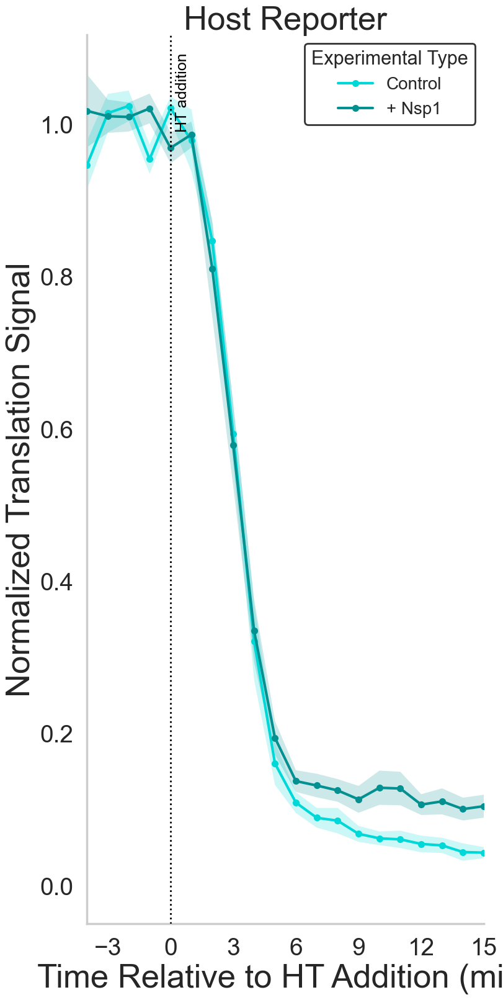

In [44]:
# CELL PURPOSE:
# Plot the average normalized HT runoff curves for the Host Reporter
# without displaying the fitted tanh curves.
#
# This uses the same observed group-average data as plot_runoff_axis():
#
#     group_mean_display['mean']
#     group_mean_display['sem']
#
# Figure dimensions match the Host Reporter boxplots.

sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")


# ============================================================
# Validate the required averaged runoff table
# ============================================================

if 'group_mean_display' not in globals():
    raise NameError(
        'group_mean_display is not defined. '
        'Run the group-average runoff calculation section first.'
    )


required_columns = {
    'Experimental_Group',
    'Experimental_Type',
    't',
    'mean',
    'sem',
}

missing_columns = required_columns.difference(
    group_mean_display.columns
)

if missing_columns:
    raise KeyError(
        'group_mean_display is missing required columns:\n'
        f'{sorted(missing_columns)}'
    )


# ============================================================
# Select the frame used as time zero on the displayed x-axis
# ============================================================

# Experimental display time zero is the actual HT-addition event:
# HT is added immediately after frame 4.
DISPLAY_HT_ADDITION_FRAME = globals().get(
    'HT_ADDITION_FRAME',
    4,
)

DISPLAY_HT_ACTION_TIME_MIN = HT_ACTION_TIME_AFTER_ADDITION_MIN


# ============================================================
# Create the tall Host Reporter figure
# ============================================================

host_reporter_average_runoff_figure, (
    host_reporter_average_runoff_axis
) = plt.subplots(
    figsize=(
        8,
        16,
    ),
    constrained_layout=True,
)


# ============================================================
# Plot the measured average curves and SEM
# ============================================================

host_reporter_curve_count = 0


for experimental_type in TYPE_ORDER:

    curve = (
        group_mean_display.loc[
            (
                group_mean_display[
                    'Experimental_Group'
                ]
                .astype(str)
                .eq(
                    str(
                        CONTROL_GROUP
                    )
                )
            )
            &
            (
                group_mean_display[
                    'Experimental_Type'
                ]
                .astype(str)
                .eq(
                    str(
                        experimental_type
                    )
                )
            )
        ]
        .copy()
        .sort_values(
            't'
        )
    )

    if curve.empty:
        print(
            'No Host Reporter average runoff data were found for '
            f'{experimental_type!r}.'
        )
        continue

    host_reporter_curve_count += 1

    curve[
        't'
    ] = pd.to_numeric(
        curve[
            't'
        ],
        errors='coerce',
    )

    curve[
        'mean'
    ] = pd.to_numeric(
        curve[
            'mean'
        ],
        errors='coerce',
    )

    curve[
        'sem'
    ] = pd.to_numeric(
        curve[
            'sem'
        ],
        errors='coerce',
    )

    curve = curve.dropna(
        subset=[
            't',
            'mean',
        ]
    )

    if curve.empty:
        continue

    display_time = (
        curve[
            't'
        ]
        - DISPLAY_HT_ADDITION_FRAME
    )

    curve_sem = (
        curve[
            'sem'
        ]
        .fillna(
            0
        )
    )

    lower_bound = (
        curve[
            'mean'
        ]
        - curve_sem
    )

    upper_bound = (
        curve[
            'mean'
        ]
        + curve_sem
    )

    curve_color = TYPE_COLORS.get(
        experimental_type,
        'gray',
    )

    display_label = {
        "No Nsp1": "Control",
        "Nsp1": "+ Nsp1",
        "NoCTD Nsp1": "+ Nsp1ΔC",
    }.get(experimental_type, TYPE_LABELS.get(experimental_type, experimental_type))

    # SEM envelope
    host_reporter_average_runoff_axis.fill_between(
        display_time,
        lower_bound,
        upper_bound,
        color=curve_color,
        alpha=0.20,
        linewidth=0,
        zorder=1,
    )

    # Observed group-average runoff curve
    host_reporter_average_runoff_axis.plot(
        display_time,
        curve[
            'mean'
        ],
        marker='o',
        markersize=8,
        markeredgewidth=0,
        linewidth=3,
        color=curve_color,
        label=display_label,
        zorder=3,
    )


if host_reporter_curve_count == 0:
    raise ValueError(
        'No Host Reporter runoff curves were available for plotting.'
    )


# ============================================================
# Reference lines and labels
# ============================================================

host_reporter_average_runoff_axis.axvline(
    0,
    color='black',
    linestyle=':',
    linewidth=2,
    label='_nolegend_',
    zorder=4,
)


host_reporter_average_runoff_axis.text(
    0.25,
    0.98,
    'HT addition',
    transform=(
        host_reporter_average_runoff_axis
        .get_xaxis_transform()
    ),
    rotation=90,
    verticalalignment='top',
    horizontalalignment='left',
    fontsize=18,
    color='black',
)



# Optional reference at the normalized baseline.
#
# Leave this commented if you want the appearance to match the current
# fitted-runoff plot exactly.
#
# host_reporter_average_runoff_axis.axhline(
#     1,
#     color='gray',
#     linestyle='--',
#     linewidth=1.5,
#     alpha=0.5,
#     zorder=0,
# )


# ============================================================
# Axis formatting
# ============================================================

host_reporter_average_runoff_axis.set_title(
    GROUP_LABELS.get(
        CONTROL_GROUP,
        CONTROL_GROUP,
    ),
    fontsize=38,
    fontweight='normal',
)


host_reporter_average_runoff_axis.set_xlabel(
    'Time Relative to HT Addition (min)',
    fontsize=38,
)


host_reporter_average_runoff_axis.set_ylabel(
    'Normalized Translation Signal',
    fontsize=38,
)


host_reporter_average_runoff_axis.tick_params(
    axis='both',
    labelsize=28,
)


# Show every available pre-HT and post-HT frame.
host_reporter_data = (
    group_mean_display.loc[
        group_mean_display[
            'Experimental_Group'
        ]
        .astype(str)
        .eq(
            str(
                CONTROL_GROUP
            )
        )
    ]
    .copy()
)


minimum_display_time = (
    pd.to_numeric(
        host_reporter_data[
            't'
        ],
        errors='coerce',
    )
    .min()
    - DISPLAY_HT_ADDITION_FRAME
)


maximum_display_time = (
    pd.to_numeric(
        host_reporter_data[
            't'
        ],
        errors='coerce',
    )
    .max()
    - DISPLAY_HT_ADDITION_FRAME
)


host_reporter_average_runoff_axis.set_xlim(
    -4,
    15,
)


host_reporter_average_runoff_axis.set_ylim(
    bottom=-0.05,
)


# Use integer frame labels.
host_reporter_average_runoff_axis.xaxis.set_major_locator(
    MaxNLocator(
        integer=True,
        nbins=7,
    )
)


host_reporter_average_runoff_axis.yaxis.set_major_locator(
    MaxNLocator(
        nbins=6,
    )
)


# ============================================================
# Legend and final formatting
# ============================================================

host_reporter_average_runoff_axis.legend(
    title='Experimental Type',
    fontsize=20,
    title_fontsize=22,
    frameon=True,
    facecolor='white',
    edgecolor='black',
    loc='upper right',
)


sns.despine(
    ax=host_reporter_average_runoff_axis,
)


save_figure(
    host_reporter_average_runoff_figure,
    'HT_Runoff_Host_Reporter_Average_No_Fit',
)


plt.show()


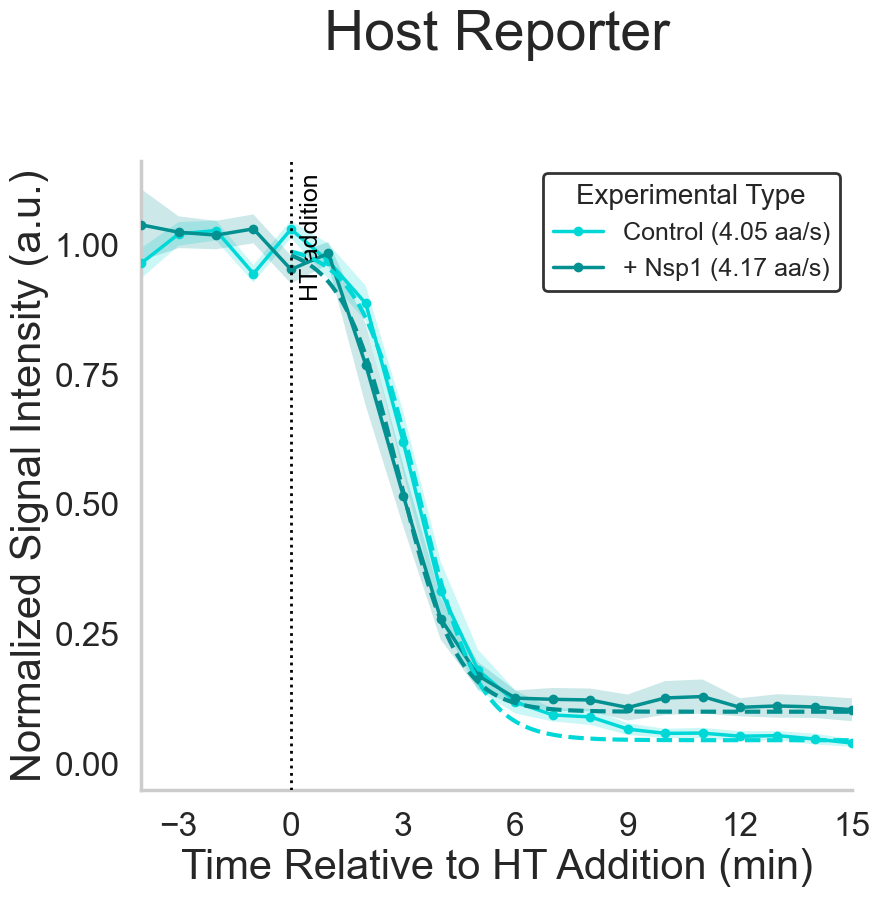

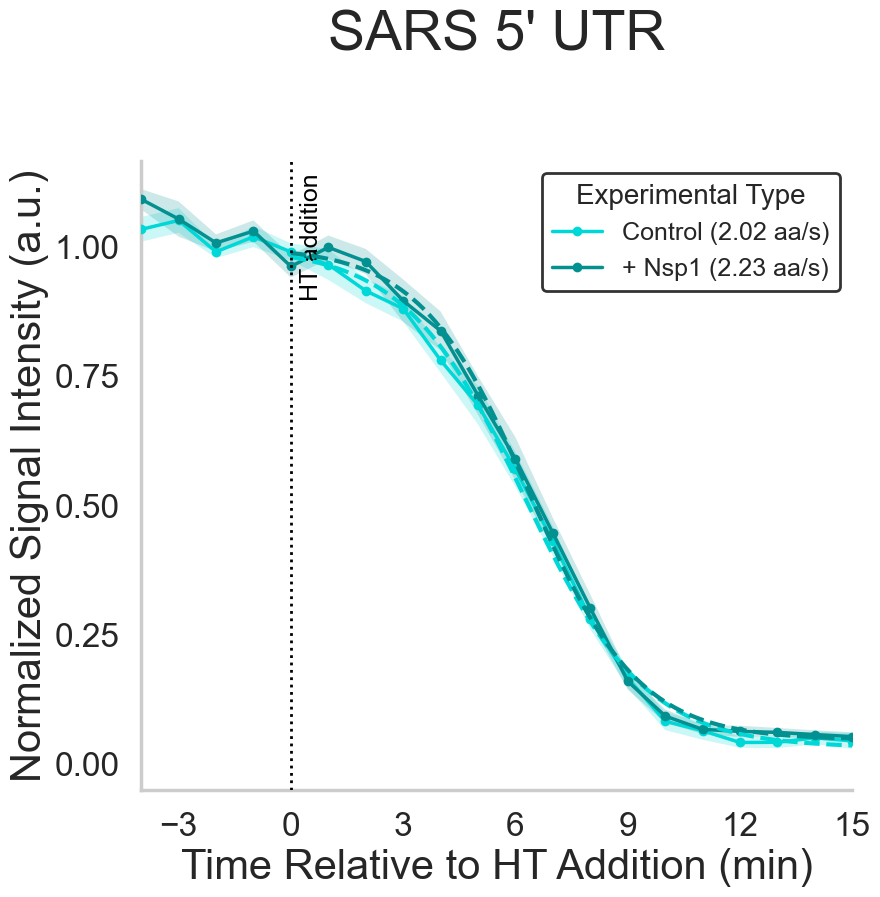

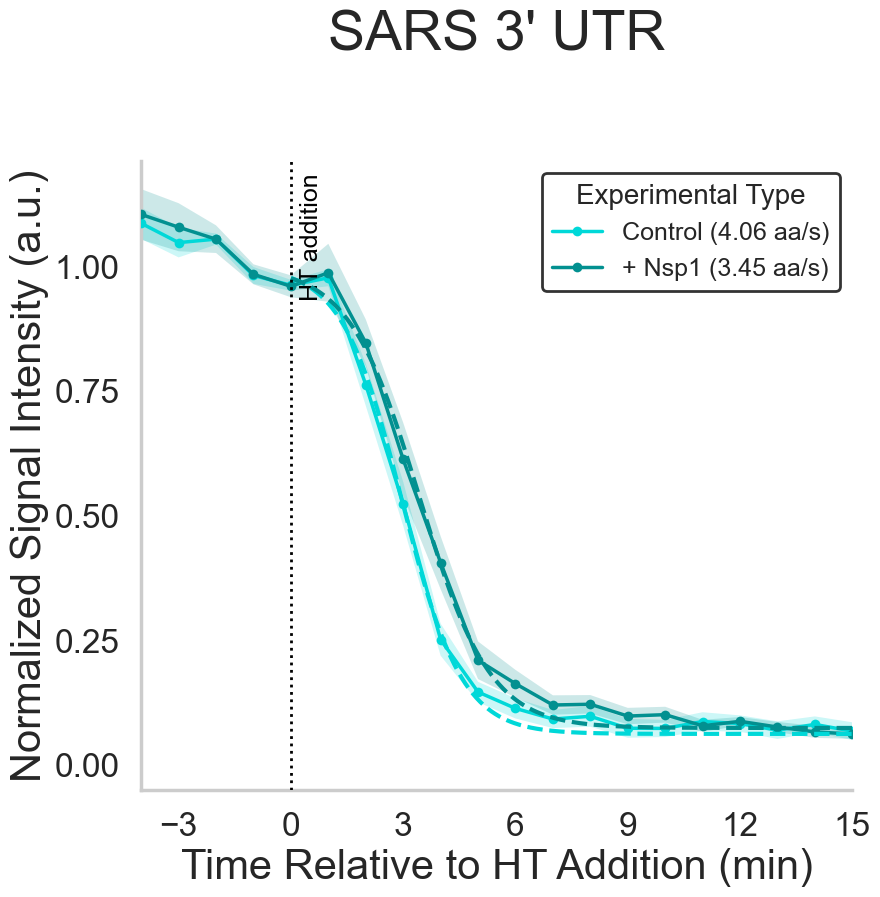

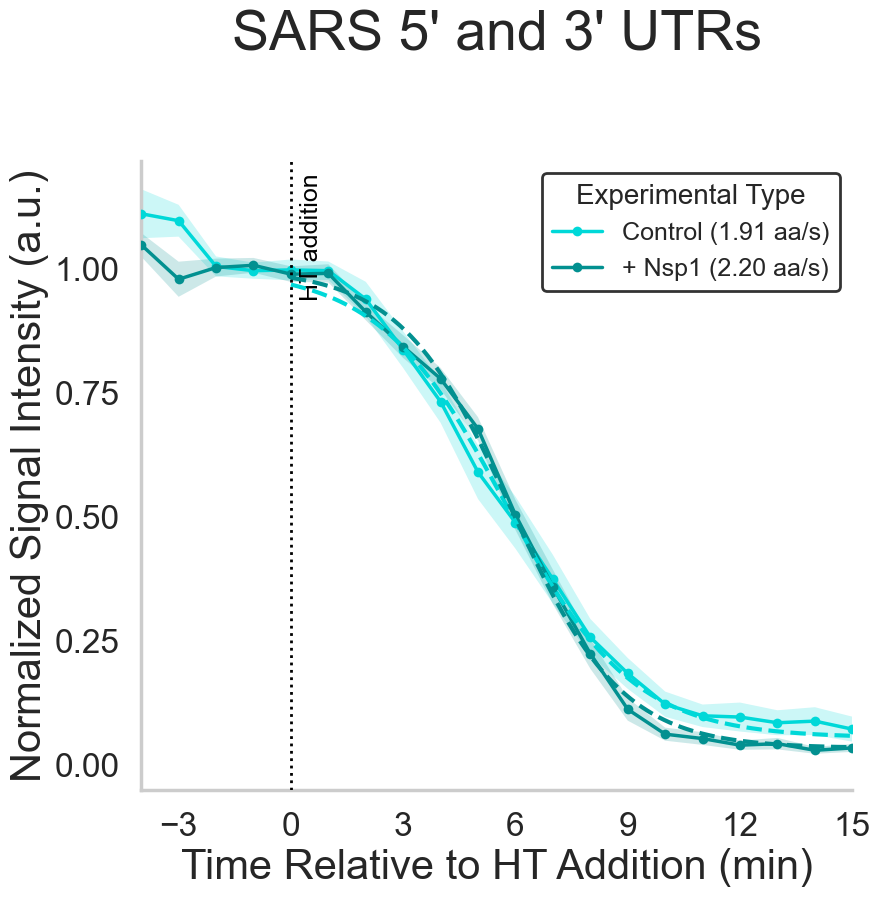

In [89]:
# CELL PURPOSE:
# Create one fitted HT runoff figure per reporter group.
#
# The plotting code is explicit in this cell rather than routed through a
# shared HT runoff helper.

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

individual_group_figures = {}

for group_name in GROUP_ORDER:

    fig, ax = plt.subplots(figsize=(10, 9), constrained_layout=True)

    for experimental_type in TYPE_ORDER:

        curve = (
            group_mean_display.loc[
                group_mean_display["Experimental_Group"].astype(str).eq(str(group_name))
                & group_mean_display["Experimental_Type"].astype(str).eq(str(experimental_type))
            ]
            .copy()
            .sort_values("t")
        )

        fit_curve = (
            tanh_group_curves_display.loc[
                tanh_group_curves_display["Experimental_Group"].astype(str).eq(str(group_name))
                & tanh_group_curves_display["Experimental_Type"].astype(str).eq(str(experimental_type))
            ]
            .copy()
            .sort_values("t")
        )

        fit_information = tanh_group_fits.loc[
            tanh_group_fits["Experimental_Group"].astype(str).eq(str(group_name))
            & tanh_group_fits["Experimental_Type"].astype(str).eq(str(experimental_type))
        ].copy()

        color = TYPE_COLORS.get(experimental_type, "gray")
        display_name = {
            "No Nsp1": "Control",
            "Nsp1": "+ Nsp1",
            "NoCTD Nsp1": "+ Nsp1ΔC",
        }.get(experimental_type, experimental_type)

        if (
            not fit_information.empty
            and np.isfinite(fit_information.iloc[0]["runoff rate (aa/sec)"])
        ):
            rate = fit_information.iloc[0]["runoff rate (aa/sec)"]
            legend_label = f"{display_name} ({rate:.2f} aa/s)"
        else:
            legend_label = display_name

        if not curve.empty:
            display_time = (curve["t"] - HT_ADDITION_FRAME) * FRAME_INTERVAL_MIN
            sem = curve["sem"].fillna(0)

            ax.fill_between(
                display_time,
                curve["mean"] - sem,
                curve["mean"] + sem,
                color=color,
                alpha=0.20,
                linewidth=0,
                zorder=1,
            )

            ax.plot(
                display_time,
                curve["mean"],
                marker="o",
                markersize=7,
                markeredgewidth=0,
                linewidth=2.5,
                color=color,
                label=legend_label,
                zorder=3,
            )

        if not fit_curve.empty:
            fit_display_time = (
                fit_curve["t"] - HT_ADDITION_FRAME
            ) * FRAME_INTERVAL_MIN

            ax.plot(
                fit_display_time,
                fit_curve["fit_value_display"],
                linestyle="--",
                linewidth=3,
                color=color,
                label="_nolegend_",
                zorder=4,
            )

    ax.axvline(
        0,
        color="black",
        linestyle=":",
        linewidth=2,
        label="_nolegend_",
        zorder=5,
    )

    ax.text(
        0.25,
        0.98,
        "HT addition",
        transform=ax.get_xaxis_transform(),
        rotation=90,
        verticalalignment="top",
        horizontalalignment="left",
        fontsize=18,
        color="black",
    )

    ax.set_title(
        GROUP_LABELS.get(group_name, group_name),
        fontsize=40,
        pad=80,
    )
    ax.set_xlabel("Time Relative to HT Addition (min)", fontsize=30)
    ax.set_ylabel("Normalized Signal Intensity (a.u.)", fontsize=30)
    ax.tick_params(axis="both", which="major", labelsize=24)
    ax.set_xlim(-4, 15)
    ax.set_ylim(bottom=-0.05)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=7))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))

    ax.legend(
        title="Experimental Type",
        fontsize=18,
        title_fontsize=20,
        frameon=True,
        facecolor="white",
        edgecolor="black",
        loc="upper right",
    )

    sns.despine(fig=fig, top=True, right=True, left=False, bottom=False)

    safe = re.sub(r"[^A-Za-z0-9_-]+", "_", group_name)
    save_figure(fig, f"HT_Runoff_{safe}_Paired_Tanh_Fit")

    plt.tight_layout()
    plt.show()

    individual_group_figures[group_name] = fig


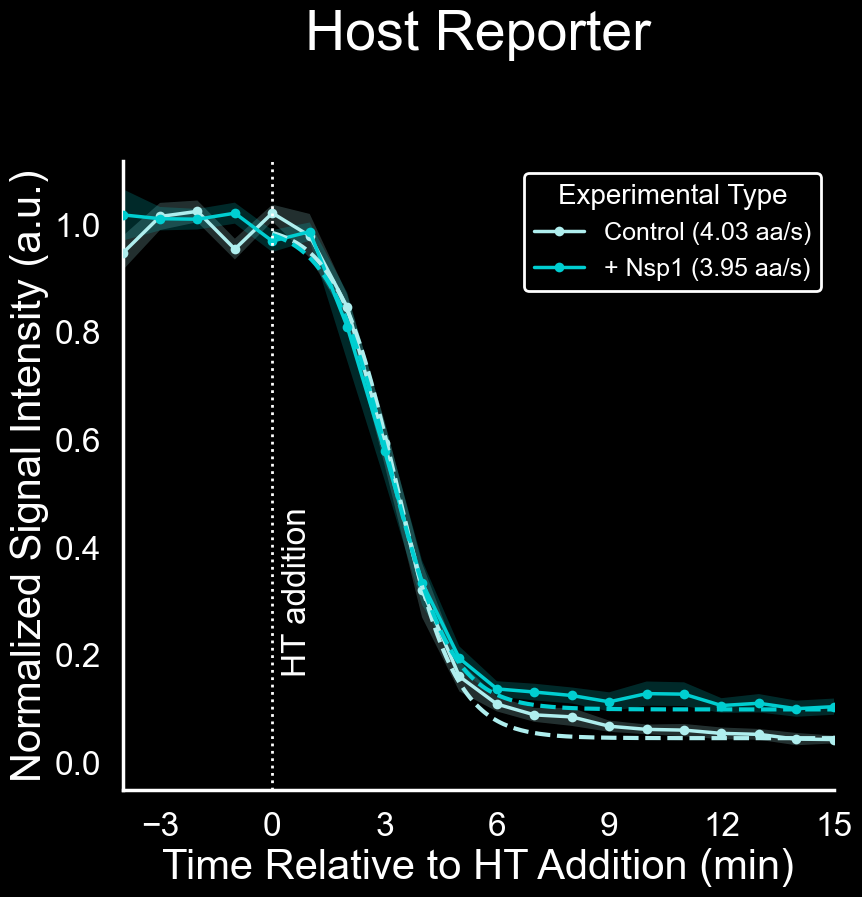

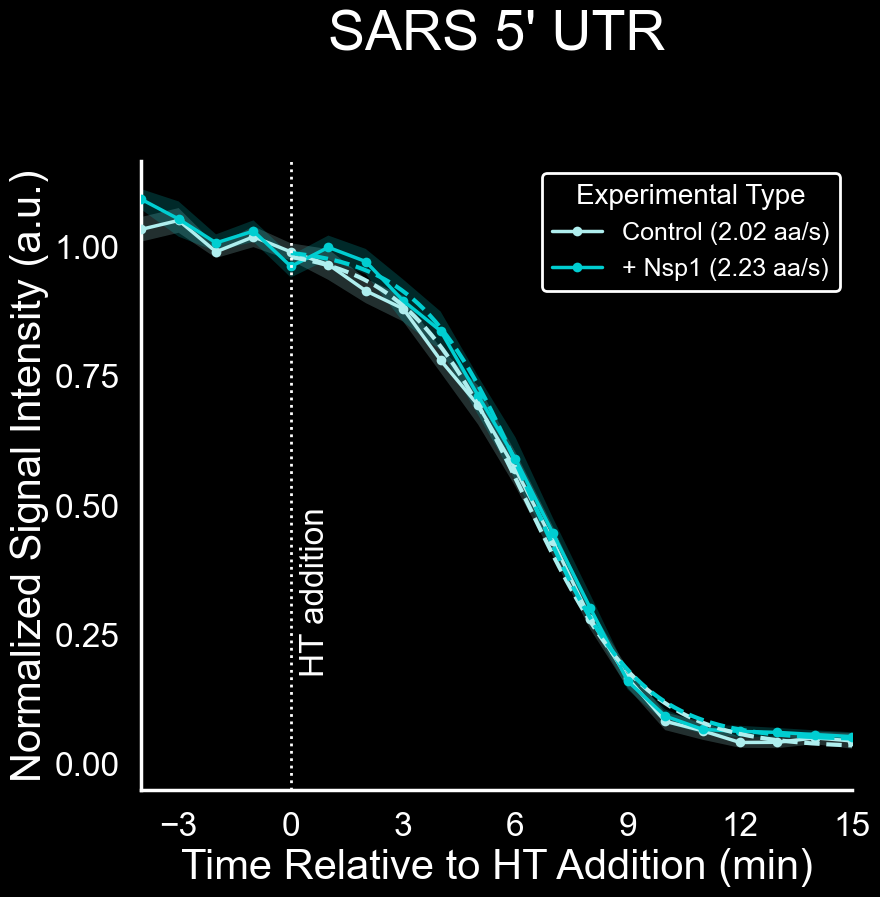

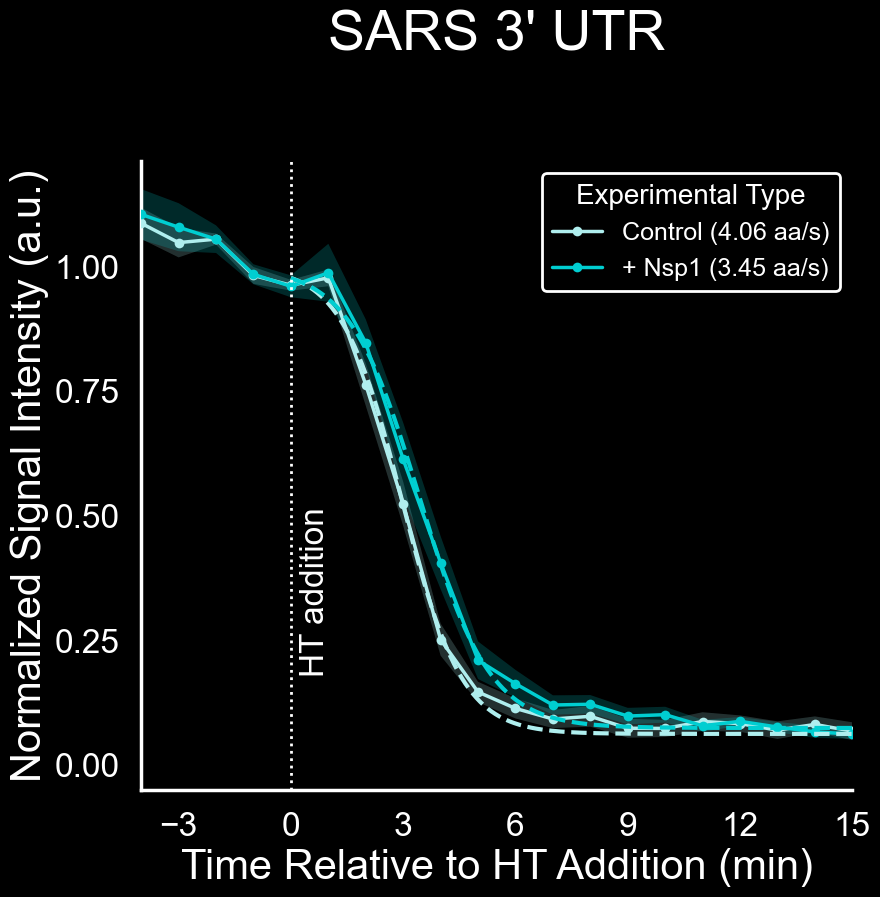

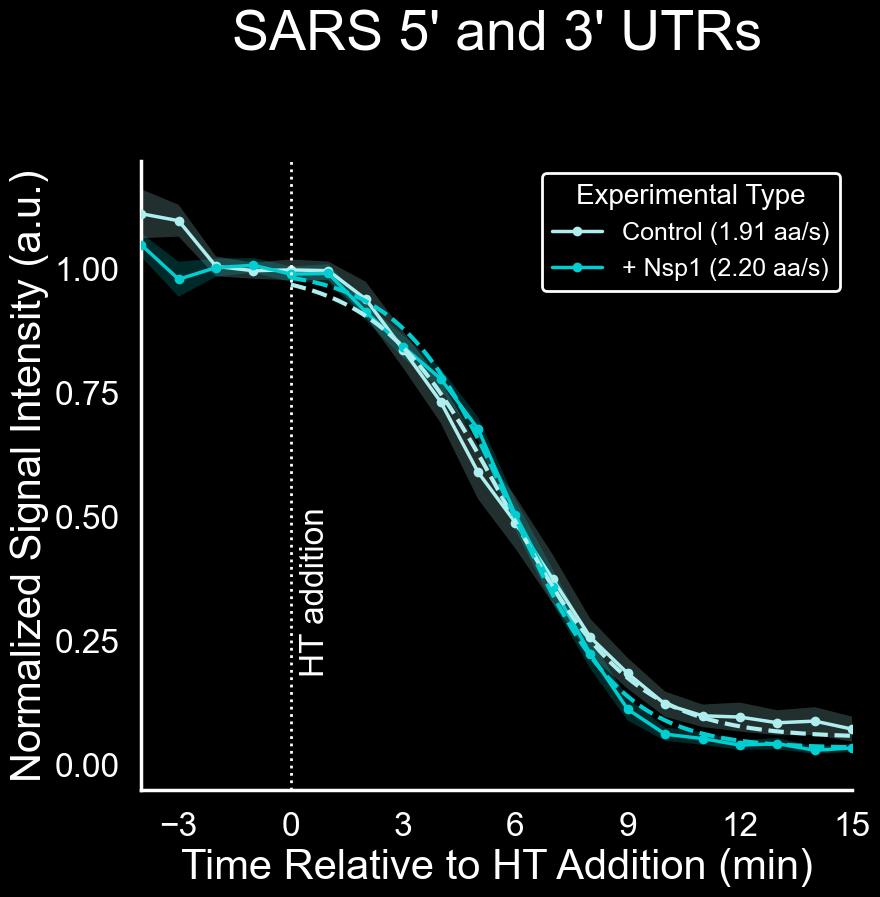

In [92]:
# CELL PURPOSE:
# Create one fitted HT runoff figure per reporter group.
#
# The plotting code is explicit in this cell rather than routed through a
# shared HT runoff helper.
#
# BLACK-BACKGROUND VERSION
#
# COLOR SCHEME:
#     Control / No Nsp1 = paleturquoise
#     + Nsp1            = darkturquoise
#
# Any other Experimental Type retains its existing TYPE_COLORS value.


import re
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

from matplotlib.ticker import MaxNLocator
from matplotlib.colors import to_rgba


# ============================================================
# BLACK-BACKGROUND FORMATTING
# ============================================================

mpl.rcParams.update(
    {
        "figure.facecolor": "black",
        "axes.facecolor": "black",
        "savefig.facecolor": "black",
        "text.color": "white",
        "axes.labelcolor": "white",
        "axes.edgecolor": "white",
        "xtick.color": "white",
        "ytick.color": "white",
    }
)


def _is_dark_color(
    color,
    threshold=0.28,
):
    """
    Identify black / very-dark plot elements that need to
    become white on a black background.
    """

    try:

        r, g, b, a = to_rgba(
            color
        )

    except Exception:

        return False

    return (
        a > 0.05
        and
        max(
            r,
            g,
            b,
        ) < threshold
    )


def finalize_black_axes(
    ax
):
    """
    Convert existing plot formatting for black-background
    presentation without altering colored data curves.
    """

    ax.set_facecolor(
        "black"
    )


    # --------------------------------------------------------
    # Titles / labels / ticks
    # --------------------------------------------------------

    ax.title.set_color(
        "white"
    )

    ax.xaxis.label.set_color(
        "white"
    )

    ax.yaxis.label.set_color(
        "white"
    )

    ax.tick_params(
        axis="both",
        which="both",
        colors="white",
    )


    for label in (
        ax.get_xticklabels()
        +
        ax.get_yticklabels()
    ):

        label.set_color(
            "white"
        )


    # --------------------------------------------------------
    # Visible axis spines
    # --------------------------------------------------------

    for spine in ax.spines.values():

        if spine.get_visible():

            spine.set_color(
                "white"
            )


    # --------------------------------------------------------
    # Convert only dark line objects to white.
    #
    # paleturquoise / darkturquoise / other condition colors
    # remain unchanged.
    # --------------------------------------------------------

    for line in ax.lines:

        try:

            if _is_dark_color(
                line.get_color()
            ):

                line.set_color(
                    "white"
                )

        except Exception:

            pass


    # --------------------------------------------------------
    # Convert dark annotations to white.
    # --------------------------------------------------------

    for text in ax.texts:

        try:

            if _is_dark_color(
                text.get_color()
            ):

                text.set_color(
                    "white"
                )

        except Exception:

            pass


    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------

    legend = ax.get_legend()

    if legend is not None:

        frame = legend.get_frame()

        frame.set_facecolor(
            "black"
        )

        frame.set_edgecolor(
            "white"
        )

        frame.set_alpha(
            1
        )


        for text in legend.get_texts():

            text.set_color(
                "white"
            )


        if legend.get_title() is not None:

            legend.get_title().set_color(
                "white"
            )


    return ax


def finalize_black_figure(
    fig
):
    """
    Apply the final black-background conversion to a complete
    Matplotlib figure.
    """

    fig.patch.set_facecolor(
        "black"
    )


    for axis in fig.axes:

        finalize_black_axes(
            axis
        )


    return fig


# ============================================================
# Seaborn formatting
# ============================================================

sns.set(
    font_scale=1.9
)

sns.set_context(
    "poster"
)

sns.set_style(
    "dark",
    {
        "axes.facecolor":
            "black",

        "figure.facecolor":
            "black",

        "axes.edgecolor":
            "white",

        "axes.labelcolor":
            "white",

        "xtick.color":
            "white",

        "ytick.color":
            "white",

        "text.color":
            "white",

        "grid.linestyle":
            "",
    },
)


# ============================================================
# FIGURE-SPECIFIC COLOR OVERRIDES
# ============================================================

# Override only the two conditions requested here.
#
# Other Experimental Types continue to use TYPE_COLORS.

PLOT_TYPE_COLOR_OVERRIDES = {

    "No Nsp1":
        "paleturquoise",

    "Nsp1":
        "darkturquoise",
}


# ============================================================
# CREATE INDIVIDUAL REPORTER-GROUP FIGURES
# ============================================================

individual_group_figures = {}


for group_name in GROUP_ORDER:

    fig, ax = plt.subplots(
        figsize=(
            10,
            9,
        ),
        constrained_layout=True,
    )


    # Explicitly establish black background immediately.
    fig.patch.set_facecolor(
        "black"
    )

    ax.set_facecolor(
        "black"
    )


    for experimental_type in TYPE_ORDER:

        # ----------------------------------------------------
        # Measured mean curve
        # ----------------------------------------------------

        curve = (
            group_mean_display.loc[
                group_mean_display[
                    "Experimental_Group"
                ]
                .astype(str)
                .eq(
                    str(
                        group_name
                    )
                )
                &
                group_mean_display[
                    "Experimental_Type"
                ]
                .astype(str)
                .eq(
                    str(
                        experimental_type
                    )
                )
            ]
            .copy()
            .sort_values(
                "t"
            )
        )


        # ----------------------------------------------------
        # Fitted tanh curve
        # ----------------------------------------------------

        fit_curve = (
            tanh_group_curves_display.loc[
                tanh_group_curves_display[
                    "Experimental_Group"
                ]
                .astype(str)
                .eq(
                    str(
                        group_name
                    )
                )
                &
                tanh_group_curves_display[
                    "Experimental_Type"
                ]
                .astype(str)
                .eq(
                    str(
                        experimental_type
                    )
                )
            ]
            .copy()
            .sort_values(
                "t"
            )
        )


        # ----------------------------------------------------
        # Fit information
        # ----------------------------------------------------

        fit_information = (
            tanh_group_fits.loc[
                tanh_group_fits[
                    "Experimental_Group"
                ]
                .astype(str)
                .eq(
                    str(
                        group_name
                    )
                )
                &
                tanh_group_fits[
                    "Experimental_Type"
                ]
                .astype(str)
                .eq(
                    str(
                        experimental_type
                    )
                )
            ]
            .copy()
        )


        # ====================================================
        # CONDITION COLOR
        # ====================================================

        # Use the black-background color override when defined.
        #
        # Otherwise retain the original TYPE_COLORS value.

        color = PLOT_TYPE_COLOR_OVERRIDES.get(

            experimental_type,

            TYPE_COLORS.get(
                experimental_type,
                "gray",
            ),
        )


        # ----------------------------------------------------
        # Condition display label
        # ----------------------------------------------------

        display_name = {

            "No Nsp1":
                "Control",

            "Nsp1":
                "+ Nsp1",

            "NoCTD Nsp1":
                "+ Nsp1ΔC",

        }.get(
            experimental_type,
            experimental_type,
        )


        # ----------------------------------------------------
        # Elongation-rate legend label
        # ----------------------------------------------------

        if (
            not fit_information.empty
            and
            np.isfinite(
                fit_information.iloc[
                    0
                ][
                    "runoff rate (aa/sec)"
                ]
            )
        ):

            rate = (
                fit_information.iloc[
                    0
                ][
                    "runoff rate (aa/sec)"
                ]
            )


            legend_label = (
                f"{display_name} "
                f"({rate:.2f} aa/s)"
            )

        else:

            legend_label = (
                display_name
            )


        # ====================================================
        # MEASURED MEAN ± SEM
        # ====================================================

        if not curve.empty:

            display_time = (
                curve[
                    "t"
                ]
                -
                HT_ADDITION_FRAME
            ) * FRAME_INTERVAL_MIN


            sem = (
                curve[
                    "sem"
                ]
                .fillna(
                    0
                )
            )


            # ------------------------------------------------
            # SEM envelope
            # ------------------------------------------------

            ax.fill_between(
                display_time,

                curve[
                    "mean"
                ]
                -
                sem,

                curve[
                    "mean"
                ]
                +
                sem,

                color=color,

                alpha=0.20,

                linewidth=0,

                zorder=1,
            )


            # ------------------------------------------------
            # Measured mean
            # ------------------------------------------------

            ax.plot(
                display_time,

                curve[
                    "mean"
                ],

                marker="o",

                markersize=7,

                markeredgewidth=0,

                linewidth=2.5,

                color=color,

                label=legend_label,

                zorder=3,
            )


        # ====================================================
        # FITTED TANH CURVE
        # ====================================================

        if not fit_curve.empty:

            fit_display_time = (
                fit_curve[
                    "t"
                ]
                -
                HT_ADDITION_FRAME
            ) * FRAME_INTERVAL_MIN


            ax.plot(
                fit_display_time,

                fit_curve[
                    "fit_value_display"
                ],

                linestyle="--",

                linewidth=3,

                color=color,

                label="_nolegend_",

                zorder=4,
            )


    # ========================================================
    # HT ADDITION MARKER
    # ========================================================

    ax.axvline(
        0,

        color="white",

        linestyle=":",

        linewidth=2,

        label="_nolegend_",

        zorder=5,
    )


    ax.text(
        0.25,
        0.45,
        "HT addition",

        transform=
            ax.get_xaxis_transform(),

        rotation=90,

        verticalalignment=
            "top",

        horizontalalignment=
            "left",

        fontsize=24,

        color="white",
    )


    # ========================================================
    # TITLES AND AXES
    # ========================================================

    ax.set_title(
        GROUP_LABELS.get(
            group_name,
            group_name,
        ),

        fontsize=40,

        pad=80,

        color="white",
    )


    ax.set_xlabel(
        "Time Relative to HT Addition (min)",

        fontsize=30,

        color="white",
    )


    ax.set_ylabel(
        "Normalized Signal Intensity (a.u.)",

        fontsize=30,

        color="white",
    )


    ax.tick_params(
        axis="both",

        which="major",

        labelsize=24,

        colors="white",
    )


    # --------------------------------------------------------
    # Limits
    # --------------------------------------------------------

    ax.set_xlim(
        -4,
        15,
    )


    ax.set_ylim(
        bottom=-0.05
    )


    # --------------------------------------------------------
    # Tick locations
    # --------------------------------------------------------

    ax.xaxis.set_major_locator(
        MaxNLocator(
            integer=True,
            nbins=7,
        )
    )


    ax.yaxis.set_major_locator(
        MaxNLocator(
            nbins=6
        )
    )


    # ========================================================
    # WHITE AXIS SPINES
    # ========================================================

    for spine in ax.spines.values():

        spine.set_color(
            "white"
        )


    # ========================================================
    # BLACK-BACKGROUND LEGEND
    # ========================================================

    legend = ax.legend(
        title="Experimental Type",

        fontsize=18,

        title_fontsize=20,

        frameon=True,

        facecolor="black",

        edgecolor="white",

        labelcolor="white",

        loc="upper right",
    )


    legend.get_frame().set_alpha(
        1
    )


    legend.get_title().set_color(
        "white"
    )


    for legend_text in legend.get_texts():

        legend_text.set_color(
            "white"
        )


    # ========================================================
    # DESPINE
    #
    # Remove top/right but retain white left/bottom axes.
    # ========================================================

    sns.despine(
        fig=fig,

        top=True,

        right=True,

        left=False,

        bottom=False,
    )


    # ========================================================
    # FINAL BLACK-BACKGROUND PASS
    # ========================================================

    finalize_black_figure(
        fig
    )


    # ========================================================
    # SAVE FIGURE
    # ========================================================

    safe = re.sub(
        r"[^A-Za-z0-9_-]+",
        "_",
        str(
            group_name
        ),
    )


    save_figure(
        fig,
        f"HT_Runoff_{safe}_Paired_Tanh_Fit",
    )


    # ========================================================
    # DISPLAY
    # ========================================================

    plt.tight_layout()

    plt.show()


    individual_group_figures[
        group_name
    ] = fig

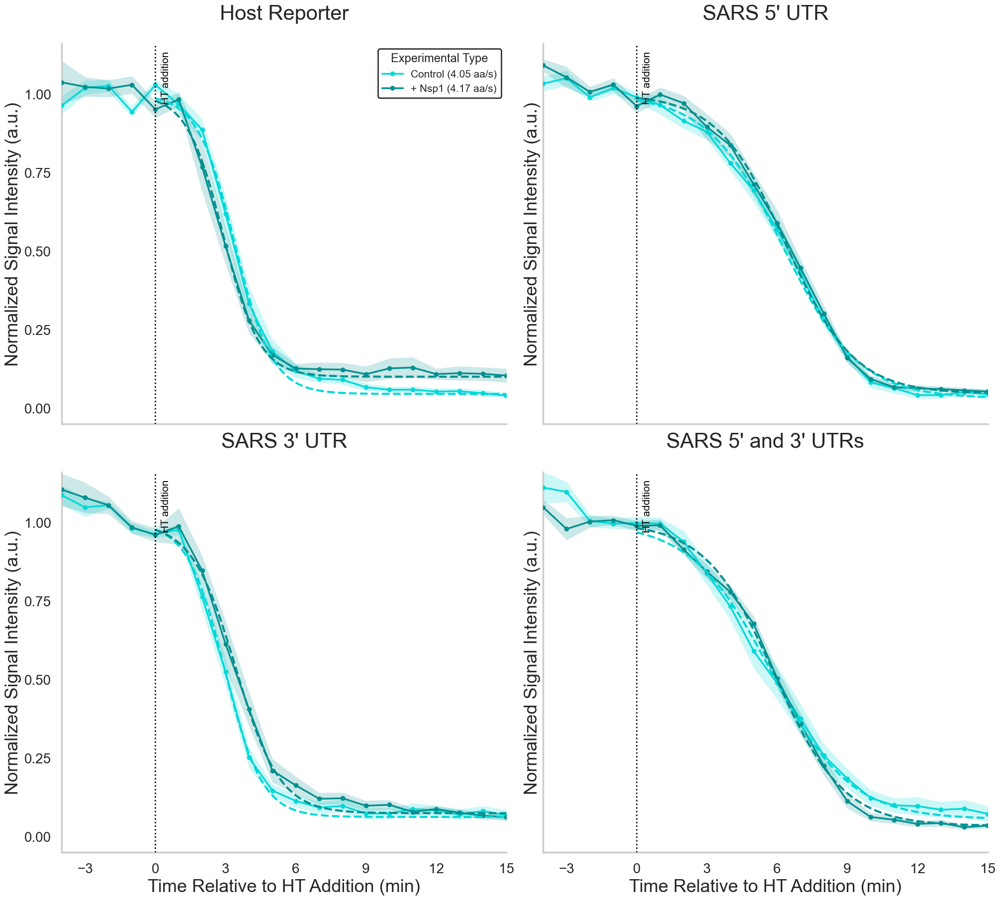

In [90]:
# CELL PURPOSE:
# Create the 2×2 fitted HT runoff panel with explicit plotting code.

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

groups_to_plot = list(GROUP_ORDER[:4])

fig, axes = plt.subplots(
    2,
    2,
    figsize=(20, 18),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for panel_index, (ax, group_name) in enumerate(
    zip(axes.flat, groups_to_plot)
):

    for experimental_type in TYPE_ORDER:

        curve = (
            group_mean_display.loc[
                group_mean_display["Experimental_Group"].astype(str).eq(str(group_name))
                & group_mean_display["Experimental_Type"].astype(str).eq(str(experimental_type))
            ]
            .copy()
            .sort_values("t")
        )

        fit_curve = (
            tanh_group_curves_display.loc[
                tanh_group_curves_display["Experimental_Group"].astype(str).eq(str(group_name))
                & tanh_group_curves_display["Experimental_Type"].astype(str).eq(str(experimental_type))
            ]
            .copy()
            .sort_values("t")
        )

        fit_information = tanh_group_fits.loc[
            tanh_group_fits["Experimental_Group"].astype(str).eq(str(group_name))
            & tanh_group_fits["Experimental_Type"].astype(str).eq(str(experimental_type))
        ].copy()

        color = TYPE_COLORS.get(experimental_type, "gray")
        display_name = {
            "No Nsp1": "Control",
            "Nsp1": "+ Nsp1",
            "NoCTD Nsp1": "+ Nsp1ΔC",
        }.get(experimental_type, experimental_type)

        if (
            not fit_information.empty
            and np.isfinite(fit_information.iloc[0]["runoff rate (aa/sec)"])
        ):
            rate = fit_information.iloc[0]["runoff rate (aa/sec)"]
            legend_label = f"{display_name} ({rate:.2f} aa/s)"
        else:
            legend_label = display_name

        if not curve.empty:
            display_time = (curve["t"] - HT_ADDITION_FRAME) * FRAME_INTERVAL_MIN
            sem = curve["sem"].fillna(0)

            ax.fill_between(
                display_time,
                curve["mean"] - sem,
                curve["mean"] + sem,
                color=color,
                alpha=0.20,
                linewidth=0,
                zorder=1,
            )

            ax.plot(
                display_time,
                curve["mean"],
                marker="o",
                markersize=7,
                markeredgewidth=0,
                linewidth=2.5,
                color=color,
                label=legend_label,
                zorder=3,
            )

        if not fit_curve.empty:
            fit_display_time = (
                fit_curve["t"] - HT_ADDITION_FRAME
            ) * FRAME_INTERVAL_MIN

            ax.plot(
                fit_display_time,
                fit_curve["fit_value_display"],
                linestyle="--",
                linewidth=3,
                color=color,
                label="_nolegend_",
                zorder=4,
            )

    ax.axvline(
        0,
        color="black",
        linestyle=":",
        linewidth=2,
        label="_nolegend_",
        zorder=5,
    )

    ax.text(
        0.25,
        0.98,
        "HT addition",
        transform=ax.get_xaxis_transform(),
        rotation=90,
        verticalalignment="top",
        horizontalalignment="left",
        fontsize=15,
        color="black",
    )

    ax.set_title(
        GROUP_LABELS.get(group_name, group_name),
        fontsize=30,
        pad=35,
    )
    ax.set_xlabel("")
    ax.set_ylabel("Normalized Signal Intensity (a.u.)", fontsize=26)
    ax.tick_params(axis="both", which="major", labelsize=20)
    ax.set_xlim(-4, 15)
    ax.set_ylim(bottom=-0.05)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=7))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))

    if panel_index == 0:
        ax.legend(
            title="Experimental Type",
            fontsize=15,
            title_fontsize=17,
            frameon=True,
            facecolor="white",
            edgecolor="black",
            loc="upper right",
        )
    elif ax.get_legend() is not None:
        ax.get_legend().remove()

    sns.despine(ax=ax)

for ax in axes[0, :]:
    ax.set_xlabel("")

for ax in axes[1, :]:
    ax.set_xlabel("Time Relative to HT Addition (min)", fontsize=26)

for ax in axes.flat[len(groups_to_plot):]:
    ax.set_visible(False)

save_figure(fig, "HT_Runoff_All_Groups_2x2_Tanh_Fit")

plt.show()


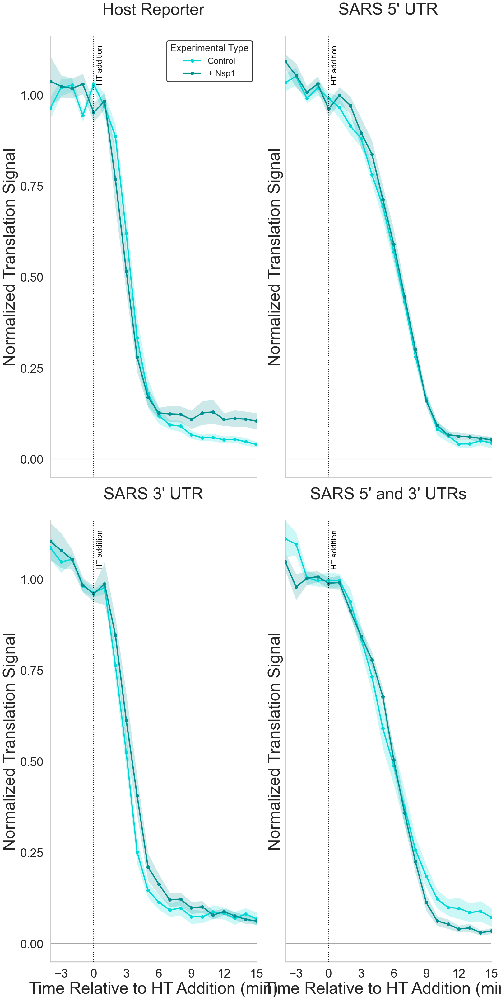

In [91]:
# CELL PURPOSE:
# Plot the average normalized HT runoff curves for all reporter groups in a
# 2×2 panel without fitted tanh curves.
#
# This cell contains the complete plotting code for the figure.

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

if "group_mean_display" not in globals():
    raise NameError(
        "group_mean_display is not defined. "
        "Run the group-average runoff calculation section first."
    )

required_columns = {
    "Experimental_Group",
    "Experimental_Type",
    "t",
    "mean",
    "sem",
}
missing_columns = required_columns.difference(group_mean_display.columns)
if missing_columns:
    raise KeyError(
        "group_mean_display is missing required columns:\n"
        f"{sorted(missing_columns)}"
    )

DISPLAY_HT_ADDITION_FRAME = globals().get("HT_ADDITION_FRAME", 4)

groups_to_plot = list(GROUP_ORDER[:4])

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 32),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for panel_index, (ax, group_name) in enumerate(
    zip(axes.flat, groups_to_plot)
):

    curve_count = 0

    for experimental_type in TYPE_ORDER:

        curve = (
            group_mean_display.loc[
                group_mean_display["Experimental_Group"].astype(str).eq(str(group_name))
                & group_mean_display["Experimental_Type"].astype(str).eq(str(experimental_type))
            ]
            .copy()
            .sort_values("t")
        )

        if curve.empty:
            continue

        curve["t"] = pd.to_numeric(curve["t"], errors="coerce")
        curve["mean"] = pd.to_numeric(curve["mean"], errors="coerce")
        curve["sem"] = pd.to_numeric(curve["sem"], errors="coerce")
        curve = curve.dropna(subset=["t", "mean"])

        if curve.empty:
            continue

        curve_count += 1

        display_time = curve["t"] - DISPLAY_HT_ADDITION_FRAME
        sem = curve["sem"].fillna(0)

        color = TYPE_COLORS.get(experimental_type, "gray")
        label = {
            "No Nsp1": "Control",
            "Nsp1": "+ Nsp1",
            "NoCTD Nsp1": "+ Nsp1ΔC",
        }.get(experimental_type, experimental_type)

        ax.fill_between(
            display_time,
            curve["mean"] - sem,
            curve["mean"] + sem,
            color=color,
            alpha=0.20,
            linewidth=0,
            zorder=1,
        )

        ax.plot(
            display_time,
            curve["mean"],
            marker="o",
            markersize=8,
            markeredgewidth=0,
            linewidth=3,
            color=color,
            label=label,
            zorder=3,
        )

    if curve_count == 0:
        ax.text(
            0.5,
            0.5,
            "No data",
            transform=ax.transAxes,
            horizontalalignment="center",
            verticalalignment="center",
            fontsize=24,
        )

    ax.axvline(
        0,
        color="black",
        linestyle=":",
        linewidth=2,
        label="_nolegend_",
        zorder=4,
    )

    ax.text(
        0.25,
        0.98,
        "HT addition",
        transform=ax.get_xaxis_transform(),
        rotation=90,
        verticalalignment="top",
        horizontalalignment="left",
        fontsize=18,
        color="black",
    )

    ax.axhline(
        0,
        color="gray",
        linewidth=1.5,
        alpha=0.7,
        zorder=0,
    )

    ax.set_title(
        GROUP_LABELS.get(group_name, group_name),
        fontsize=38,
        fontweight="normal",
        pad=50,
    )
    ax.set_xlabel("")
    ax.set_ylabel("Normalized Translation Signal", fontsize=38)
    ax.tick_params(axis="both", which="major", labelsize=28)
    ax.set_xlim(-4, 15)
    ax.set_ylim(bottom=-0.05)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=7))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))

    if panel_index == 0:
        ax.legend(
            title="Experimental Type",
            fontsize=20,
            title_fontsize=22,
            frameon=True,
            facecolor="white",
            edgecolor="black",
            loc="upper right",
        )
    elif ax.get_legend() is not None:
        ax.get_legend().remove()

    sns.despine(ax=ax)

for ax in axes[0, :]:
    ax.set_xlabel("")

for ax in axes[1, :]:
    ax.set_xlabel(
        "Time Relative to HT Addition (min)",
        fontsize=38,
    )

for ax in axes.flat[len(groups_to_plot):]:
    ax.set_visible(False)

save_figure(
    fig,
    "HT_Runoff_All_Groups_Average_No_Fit_2x2",
)

plt.show()

all_groups_average_runoff_figure = fig
all_groups_average_runoff_axes = axes


## Part XVI — Individual-cell runoff curves

Each line represents the baseline-normalized total translation signal from one
cell. Curves are separated into one panel per reporter and colored according to
experimental type. No group average, error interval, smoothing, or fitted curve
is shown.

### Individual-cell runoff plotting convention

The previous individual-cell runoff plotting helpers have been removed. The
2×2 individual-cell runoff figure in the next cell now contains its own data
preparation, curve plotting, axes, legend, and formatting code.


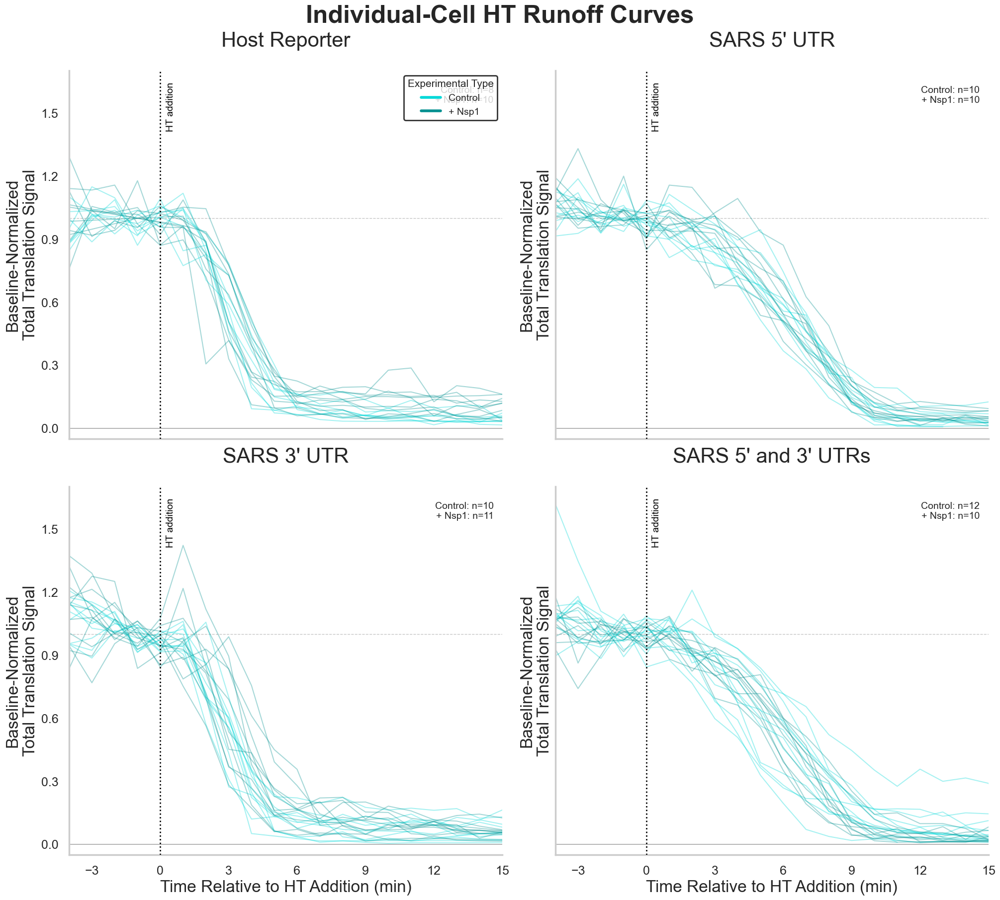


Individual-cell runoff plot
---------------------------
Metric: total_spot_intensity_baseline_norm
Fitting performed: No
Outlier-filtered cells only: False


,Experimental_Group,Experimental_Type,n_cells
0,Control,No Nsp1,8
1,Control,Nsp1,10
2,SARS_3'UTR,No Nsp1,10
3,SARS_3'UTR,Nsp1,11
4,SARS_5'UTR,No Nsp1,10
5,SARS_5'UTR,Nsp1,10
6,SARS_5'_3'UTR,No Nsp1,12
7,SARS_5'_3'UTR,Nsp1,10


In [45]:
# CELL PURPOSE:
# Create a 2×2 panel of unfitted individual-cell HT runoff curves.
#
# All plotting and data preparation for this figure are contained in this cell.

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# ============================================================
# Figure-specific settings
# ============================================================

SINGLE_CELL_RUNOFF_METRIC = "total_spot_intensity_baseline_norm"

SINGLE_CELL_LINEWIDTH = 1.5
SINGLE_CELL_LINE_ALPHA = 0.35
SINGLE_CELL_SHOW_MARKERS = False
SINGLE_CELL_MARKER_SIZE = 3
SINGLE_CELL_SHOW_COUNTS = True

# False = plot every cell in cell_time_runoff.
# True  = keep only cells retained by resistant-fraction outlier screening.
SINGLE_CELL_USE_RESISTANT_OUTLIER_FILTER = False

SINGLE_CELL_X_LIMITS = None
SINGLE_CELL_Y_LIMITS = None

# ============================================================
# Prepare data
# ============================================================

required_columns = {
    "Experimental_Group",
    "Experimental_Type",
    "Replicate_Number",
    "fov",
    "t",
    SINGLE_CELL_RUNOFF_METRIC,
}
missing_columns = required_columns.difference(cell_time_runoff.columns)
if missing_columns:
    raise KeyError(
        "cell_time_runoff is missing required columns:\n"
        f"{sorted(missing_columns)}"
    )

single_cell_runoff_plot_data = cell_time_runoff.copy()

single_cell_runoff_plot_data["t"] = pd.to_numeric(
    single_cell_runoff_plot_data["t"],
    errors="coerce",
)
single_cell_runoff_plot_data[SINGLE_CELL_RUNOFF_METRIC] = pd.to_numeric(
    single_cell_runoff_plot_data[SINGLE_CELL_RUNOFF_METRIC],
    errors="coerce",
)

single_cell_runoff_plot_data = single_cell_runoff_plot_data.loc[
    np.isfinite(single_cell_runoff_plot_data["t"])
    & np.isfinite(single_cell_runoff_plot_data[SINGLE_CELL_RUNOFF_METRIC])
].copy()

single_cell_runoff_plot_data["time_relative_to_ht_addition_min"] = (
    single_cell_runoff_plot_data["t"] - HT_ADDITION_FRAME
) * FRAME_INTERVAL_MIN

if SINGLE_CELL_USE_RESISTANT_OUTLIER_FILTER:

    if "df_ht_resistant_plot" not in globals():
        raise NameError(
            "SINGLE_CELL_USE_RESISTANT_OUTLIER_FILTER is True, but "
            "df_ht_resistant_plot is not defined."
        )

    outlier_filter_keys = [
        column
        for column in [
            "Experimental_Group",
            "Experimental_Type",
            "Replicate_Number",
            "fov",
        ]
        if (
            column in single_cell_runoff_plot_data.columns
            and column in df_ht_resistant_plot.columns
        )
    ]

    retained_cells = (
        df_ht_resistant_plot[outlier_filter_keys]
        .drop_duplicates()
        .copy()
    )

    single_cell_runoff_plot_data = single_cell_runoff_plot_data.merge(
        retained_cells,
        on=outlier_filter_keys,
        how="inner",
        validate="many_to_one",
    )

single_cell_runoff_plot_data = single_cell_runoff_plot_data.sort_values(
    [
        "Experimental_Group",
        "Experimental_Type",
        "Replicate_Number",
        "fov",
        "t",
    ]
).reset_index(drop=True)

# ============================================================
# Common limits
# ============================================================

single_cell_group_order = list(GROUP_ORDER[:4])

panel_data = single_cell_runoff_plot_data.loc[
    single_cell_runoff_plot_data["Experimental_Group"].isin(single_cell_group_order)
].copy()

if panel_data.empty:
    raise ValueError(
        "No individual-cell runoff data matched GROUP_ORDER."
    )

if SINGLE_CELL_X_LIMITS is None:
    calculated_x_limits = (
        panel_data["time_relative_to_ht_addition_min"].min(),
        15,
    )
else:
    calculated_x_limits = SINGLE_CELL_X_LIMITS

if SINGLE_CELL_Y_LIMITS is None:
    y_min = panel_data[SINGLE_CELL_RUNOFF_METRIC].min()
    y_max = panel_data[SINGLE_CELL_RUNOFF_METRIC].max()
    y_range = y_max - y_min

    if not np.isfinite(y_range) or y_range == 0:
        y_range = 1.0

    calculated_y_limits = (
        min(-0.05, y_min - 0.03 * y_range),
        max(1.10, y_max + 0.05 * y_range),
    )
else:
    calculated_y_limits = SINGLE_CELL_Y_LIMITS

# ============================================================
# Plot
# ============================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(20, 18),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for panel_index, (ax, group_name) in enumerate(
    zip(axes.flat, single_cell_group_order)
):

    group_data = single_cell_runoff_plot_data.loc[
        single_cell_runoff_plot_data["Experimental_Group"].astype(str).eq(str(group_name))
    ].copy()

    condition_count_text = []

    for experimental_type in TYPE_ORDER:

        condition_data = group_data.loc[
            group_data["Experimental_Type"].astype(str).eq(str(experimental_type))
        ].copy()

        if condition_data.empty:
            continue

        n_cells = condition_data["fov"].nunique()
        display_condition = {
            "No Nsp1": "Control",
            "Nsp1": "+ Nsp1",
            "NoCTD Nsp1": "+ Nsp1ΔC",
        }.get(experimental_type, experimental_type)

        condition_count_text.append(
            f"{display_condition}: n={n_cells}"
        )

        cell_identifier_columns = [
            column for column in CELL_KEYS
            if column in condition_data.columns
        ]

        if not cell_identifier_columns:
            cell_identifier_columns = [
                "Experimental_Type",
                "Replicate_Number",
                "fov",
            ]

        for _, cell_curve in condition_data.groupby(
            cell_identifier_columns,
            dropna=False,
            sort=False,
        ):

            cell_curve = cell_curve.sort_values(
                "time_relative_to_ht_addition_min"
            )

            ax.plot(
                cell_curve["time_relative_to_ht_addition_min"],
                cell_curve[SINGLE_CELL_RUNOFF_METRIC],
                color=TYPE_COLORS.get(experimental_type, "gray"),
                linewidth=SINGLE_CELL_LINEWIDTH,
                alpha=SINGLE_CELL_LINE_ALPHA,
                marker="o" if SINGLE_CELL_SHOW_MARKERS else None,
                markersize=(
                    SINGLE_CELL_MARKER_SIZE
                    if SINGLE_CELL_SHOW_MARKERS
                    else None
                ),
                markeredgewidth=0,
                label="_nolegend_",
                zorder=2,
            )

    ax.axvline(
        0,
        color="black",
        linestyle=":",
        linewidth=2,
        zorder=4,
    )

    ax.text(
        0.25,
        0.97,
        "HT addition",
        transform=ax.get_xaxis_transform(),
        rotation=90,
        verticalalignment="top",
        horizontalalignment="left",
        fontsize=14,
        color="black",
    )

    ax.axhline(
        0,
        color="gray",
        linewidth=1.25,
        alpha=0.65,
        zorder=1,
    )

    ax.axhline(
        1,
        color="gray",
        linestyle="--",
        linewidth=1.0,
        alpha=0.45,
        zorder=1,
    )

    ax.set_title(
        GROUP_LABELS.get(group_name, group_name),
        fontsize=30,
        pad=35,
    )
    ax.set_xlabel("")
    ax.set_ylabel(
        "Baseline-Normalized\nTotal Translation Signal",
        fontsize=24,
    )
    ax.tick_params(axis="both", which="major", labelsize=18)
    ax.set_xlim(calculated_x_limits)
    ax.set_ylim(calculated_y_limits)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=7))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))

    if SINGLE_CELL_SHOW_COUNTS and condition_count_text:
        ax.text(
            0.98,
            0.96,
            "\n".join(condition_count_text),
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=14,
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.75,
            },
        )

    if panel_index == 0:
        legend_handles = [
            Line2D(
                [0],
                [0],
                color=TYPE_COLORS.get(experimental_type, "gray"),
                linewidth=4,
                label={
                    "No Nsp1": "Control",
                    "Nsp1": "+ Nsp1",
                    "NoCTD Nsp1": "+ Nsp1ΔC",
                }.get(experimental_type, experimental_type),
            )
            for experimental_type in TYPE_ORDER
        ]

        ax.legend(
            handles=legend_handles,
            title="Experimental Type",
            fontsize=14,
            title_fontsize=15,
            frameon=True,
            facecolor="white",
            edgecolor="black",
        )

    sns.despine(ax=ax)

for ax in axes[0, :]:
    ax.set_xlabel("")

for ax in axes[1, :]:
    ax.set_xlabel(
        "Time Relative to HT Addition (min)",
        fontsize=24,
    )

for ax in axes.flat[len(single_cell_group_order):]:
    ax.set_visible(False)

fig.suptitle(
    "Individual-Cell HT Runoff Curves",
    fontsize=36,
    fontweight="bold",
)

save_figure(
    fig,
    "HT_Runoff_Individual_Cells_All_Groups_2x2",
)

plt.show()

single_cell_runoff_figure = fig
single_cell_runoff_axes = axes

print("\nIndividual-cell runoff plot")
print("---------------------------")
print(f"Metric: {SINGLE_CELL_RUNOFF_METRIC}")
print("Fitting performed: No")
print(
    "Outlier-filtered cells only: "
    f"{SINGLE_CELL_USE_RESISTANT_OUTLIER_FILTER}"
)

display(
    single_cell_runoff_plot_data[
        [
            "Experimental_Group",
            "Experimental_Type",
            "Replicate_Number",
            "fov",
        ]
    ]
    .drop_duplicates()
    .groupby(
        [
            "Experimental_Group",
            "Experimental_Type",
        ],
        dropna=False,
    )
    .size()
    .rename("n_cells")
    .reset_index()
)


## Part XVII — Individual-cell fits and kinetic metrics

Each individual-cell and biological-replicate mean trajectory is fit with the
same **continuous residual-aware tanh model from the HT-addition reference
(frame 4, 0 min) onward**. Frame 5 (~+1 min) is retained in the fit so the upper
shoulder contributes to the fitted curve width rather than being discarded.

The approximately 1-minute HT-action delay is retained as an absolute timing
correction. `t_half_post_ht_min` is measured from physical HT addition, while
`t_half_after_ht_action_min = t_half_post_ht_min - HT_ACTION_DELAY_MIN`.
Because the elongation rate is derived from the **width** of the tanh transition,
a constant 1-minute horizontal shift is not subtracted from the width-derived
runoff time or elongation rate.


In [46]:
# CELL PURPOSE:
# Fit every corrected, normalized cell curve and every biological-
# replicate mean curve using the current residual-aware tanh model.

# ------------------------------------------------------------------
# A. Individual-cell fits
# ------------------------------------------------------------------

cell_fit_rows = []
cell_fit_curve_rows = []

for cell_keys, cell_curve in (
    cell_time_runoff
    .groupby(
        CELL_KEYS,
        dropna=False,
        sort=False,
    )
):

    cell_information = dict(
        zip(
            CELL_KEYS,
            cell_keys,
        )
    )

    measured_residual = (
        pd.to_numeric(
            cell_curve[
                PER_CELL_ENDPOINT_FRACTION_METRIC
            ],
            errors='coerce',
        )
        .dropna()
    )

    measured_residual_value = (
        float(
            measured_residual.iloc[0]
        )
        if not measured_residual.empty
        else np.nan
    )

    fit_result, dense_curve = (
        fit_one_residual_tanh_curve(
            frame=cell_curve,
            metric=PER_CELL_FIT_METRIC,
            measured_residual_fraction=(
                measured_residual_value
            ),
            sem_column=None,
        )
    )

    cell_fit_rows.append({
        **cell_information,
        **fit_result,
        'fit_unit': 'individual_cell',
    })

    if not dense_curve.empty:

        dense_curve = (
            dense_curve
            .assign(
                **cell_information,
                fit_unit='individual_cell',
            )
        )

        cell_fit_curve_rows.extend(
            dense_curve
            .to_dict(
                orient='records'
            )
        )


tanh_cell_fits = pd.DataFrame(
    cell_fit_rows
)

tanh_cell_fit_curves = pd.DataFrame(
    cell_fit_curve_rows
)


# ------------------------------------------------------------------
# B. Biological-replicate mean curves
#
# Each replicate mean curve is fitted directly. This is distinct from
# averaging the elongation rates fitted to individual cells.
# ------------------------------------------------------------------

REPLICATE_FIT_KEYS = [
    'Experimental_Group',
    'Experimental_Type',
    'Replicate_Number',
]


replicate_mean_runoff = (
    cell_time_runoff
    .groupby(
        [
            *REPLICATE_FIT_KEYS,
            't',
        ],
        dropna=False,
    )[
        PER_CELL_FIT_METRIC
    ]
    .agg(
        mean='mean',
        sem='sem',
        n_cells='count',
    )
    .reset_index()
    .sort_values(
        [
            *REPLICATE_FIT_KEYS,
            't',
        ]
    )
)


cell_endpoint_for_replicates = (
    cell_time_runoff[
        [
            *CELL_KEYS,
            PER_CELL_ENDPOINT_FRACTION_METRIC,
        ]
    ]
    .drop_duplicates(
        subset=CELL_KEYS
    )
)


replicate_endpoint_fractions = (
    cell_endpoint_for_replicates
    .groupby(
        REPLICATE_FIT_KEYS,
        dropna=False,
    )[
        PER_CELL_ENDPOINT_FRACTION_METRIC
    ]
    .agg(
        measured_endpoint_fraction='mean',
        endpoint_fraction_sem='sem',
        endpoint_fraction_n='count',
    )
    .reset_index()
)


replicate_endpoint_lookup = (
    replicate_endpoint_fractions
    .set_index(
        REPLICATE_FIT_KEYS
    )[
        'measured_endpoint_fraction'
    ]
    .to_dict()
)


replicate_fit_rows = []
replicate_fit_curve_rows = []

for replicate_keys, replicate_curve in (
    replicate_mean_runoff
    .groupby(
        REPLICATE_FIT_KEYS,
        dropna=False,
        sort=False,
    )
):

    replicate_information = dict(
        zip(
            REPLICATE_FIT_KEYS,
            replicate_keys,
        )
    )

    measured_residual_value = (
        replicate_endpoint_lookup.get(
            replicate_keys,
            np.nan,
        )
    )

    fit_input = (
        replicate_curve
        .rename(
            columns={
                'mean': (
                    PER_CELL_FIT_METRIC
                )
            }
        )
    )

    fit_result, dense_curve = (
        fit_one_residual_tanh_curve(
            frame=fit_input,
            metric=PER_CELL_FIT_METRIC,
            measured_residual_fraction=(
                measured_residual_value
            ),
            sem_column='sem',
        )
    )

    replicate_fit_rows.append({
        **replicate_information,
        **fit_result,
        'fit_unit': (
            'replicate_mean_curve'
        ),
    })

    if not dense_curve.empty:

        dense_curve = (
            dense_curve
            .assign(
                **replicate_information,
                fit_unit=(
                    'replicate_mean_curve'
                ),
            )
        )

        replicate_fit_curve_rows.extend(
            dense_curve
            .to_dict(
                orient='records'
            )
        )


tanh_replicate_fits = pd.DataFrame(
    replicate_fit_rows
)

tanh_replicate_fit_curves = pd.DataFrame(
    replicate_fit_curve_rows
)


# ------------------------------------------------------------------
# C. Replicate summaries of individual-cell fitted parameters
# ------------------------------------------------------------------

usable_cell_fits = (
    tanh_cell_fits.loc[
        tanh_cell_fits[
            'fit_usable'
        ].fillna(False)
    ]
    .copy()
)


cell_fit_replicate_summary = (
    usable_cell_fits
    .groupby(
        REPLICATE_FIT_KEYS,
        dropna=False,
    )
    .agg(
        mean_cell_fitted_elongation_rate_aa_per_sec=(
            'elongation_rate_aa_per_sec',
            'mean',
        ),

        median_cell_fitted_elongation_rate_aa_per_sec=(
            'elongation_rate_aa_per_sec',
            'median',
        ),

        cell_fitted_elongation_rate_sd=(
            'elongation_rate_aa_per_sec',
            'std',
        ),

        cell_fitted_elongation_rate_sem=(
            'elongation_rate_aa_per_sec',
            'sem',
        ),

        mean_cell_fitted_residual_fraction=(
            'fitted_residual_fraction',
            'mean',
        ),

        median_cell_fitted_residual_fraction=(
            'fitted_residual_fraction',
            'median',
        ),

        n_usable_cell_fits=(
            'fov',
            'nunique',
        ),
    )
    .reset_index()
)


# ------------------------------------------------------------------
# D. Fit-audit summaries
# ------------------------------------------------------------------

cell_fit_status_summary = (
    tanh_cell_fits
    .groupby(
        [
            'Experimental_Group',
            'Experimental_Type',
            'fit_success',
            'fit_usable',
            'fit_exclusion_reason',
        ],
        dropna=False,
    )
    .size()
    .rename(
        'n_cells'
    )
    .reset_index()
)


replicate_fit_status_summary = (
    tanh_replicate_fits
    .groupby(
        [
            'Experimental_Group',
            'Experimental_Type',
            'fit_success',
            'fit_usable',
            'fit_exclusion_reason',
        ],
        dropna=False,
    )
    .size()
    .rename(
        'n_replicates'
    )
    .reset_index()
)


print('\nIndividual-cell tanh fitting')
print('----------------------------')
print(
    'Cells attempted: '
    f'{len(tanh_cell_fits):,}'
)
print(
    'Successful fits: '
    f"{int(tanh_cell_fits['fit_success'].fillna(False).sum()):,}"
)
print(
    'Usable primary fits: '
    f"{int(tanh_cell_fits['fit_usable'].fillna(False).sum()):,}"
)

print('\nReplicate-mean tanh fitting')
print('---------------------------')
print(
    'Replicate curves attempted: '
    f'{len(tanh_replicate_fits):,}'
)
print(
    'Successful replicate fits: '
    f"{int(tanh_replicate_fits['fit_success'].fillna(False).sum()):,}"
)
print(
    'Usable replicate fits: '
    f"{int(tanh_replicate_fits['fit_usable'].fillna(False).sum()):,}"
)


save_table(
    tanh_cell_fits,
    'tethered_ht_individual_cell_tanh_fits',
)

save_table(
    tanh_cell_fit_curves,
    'tethered_ht_individual_cell_tanh_fit_curves',
)

save_table(
    tanh_replicate_fits,
    'tethered_ht_replicate_mean_curve_tanh_fits',
)

save_table(
    tanh_replicate_fit_curves,
    'tethered_ht_replicate_mean_curve_tanh_fit_curves',
)

save_table(
    replicate_mean_runoff,
    'tethered_ht_replicate_mean_normalized_runoff',
)

save_table(
    replicate_endpoint_fractions,
    'tethered_ht_replicate_endpoint_fractions',
)

save_table(
    cell_fit_replicate_summary,
    'tethered_ht_cell_fit_replicate_summary',
)

save_table(
    cell_fit_status_summary,
    'tethered_ht_cell_fit_status_summary',
)

save_table(
    replicate_fit_status_summary,
    'tethered_ht_replicate_fit_status_summary',
)


display(
    cell_fit_status_summary
)

display(
    replicate_fit_status_summary
)

display(
    tanh_cell_fits[
        [
            column
            for column in [
                'Experimental_Group',
                'Experimental_Type',
                'Replicate_Number',
                'Cell_Number',
                'fov',
                'elongation_rate_aa_per_sec',
                'elongation_rate_se',
                't_half_post_ht_min',
                't_half_after_ht_action_min',
                'fitted_residual_fraction',
                'R_squared',
                'RMSE',
                'rate_at_boundary',
                'residual_at_boundary',
                'fit_success',
                'fit_usable',
                'fit_exclusion_reason',
                'fit_error',
            ]
            if column
            in tanh_cell_fits.columns
        ]
    ]
    .head(30)
)


Individual-cell tanh fitting
----------------------------
Cells attempted: 83
Successful fits: 81
Usable primary fits: 81

Replicate-mean tanh fitting
---------------------------
Replicate curves attempted: 16
Successful replicate fits: 16
Usable replicate fits: 16
Parquet unavailable for tethered_ht_individual_cell_tanh_fits: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.
Saved: Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT\Analysis_Output\Tethered_HT\Dataframes\tethered_ht_individual_cell_tanh_fits.csv
Parquet unavailable for tethered_ht_individual_cell_tanh_fit_c

,Experimental_Group,Experimental_Type,fit_success,fit_usable,fit_exclusion_reason,n_cells
0,Control,No Nsp1,True,True,,8
1,Control,Nsp1,True,True,,10
2,SARS_3'UTR,No Nsp1,True,True,,10
3,SARS_3'UTR,Nsp1,True,True,,11
4,SARS_5'UTR,No Nsp1,False,False,Too few full-runoff fit points,1
5,SARS_5'UTR,No Nsp1,True,True,,10
6,SARS_5'UTR,Nsp1,True,True,,10
7,SARS_5'_3'UTR,No Nsp1,True,True,,12
8,SARS_5'_3'UTR,Nsp1,False,False,Too few full-runoff fit points,1
9,SARS_5'_3'UTR,Nsp1,True,True,,10


,Experimental_Group,Experimental_Type,fit_success,fit_usable,fit_exclusion_reason,n_replicates
0,Control,No Nsp1,True,True,,2
1,Control,Nsp1,True,True,,2
2,SARS_3'UTR,No Nsp1,True,True,,2
3,SARS_3'UTR,Nsp1,True,True,,2
4,SARS_5'UTR,No Nsp1,True,True,,2
5,SARS_5'UTR,Nsp1,True,True,,2
6,SARS_5'_3'UTR,No Nsp1,True,True,,2
7,SARS_5'_3'UTR,Nsp1,True,True,,2


,Experimental_Group,Experimental_Type,Replicate_Number,Cell_Number,fov,elongation_rate_aa_per_sec,elongation_rate_se,t_half_post_ht_min,t_half_after_ht_action_min,fitted_residual_fraction,R_squared,RMSE,rate_at_boundary,residual_at_boundary,fit_success,fit_usable,fit_exclusion_reason,fit_error
0,Control,No Nsp1,1,1,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,3.190205,0.315654,3.481457,2.481457,6.291805e-02,0.972644,0.040710,False,False,True,True,,
1,Control,No Nsp1,1,2,SARS_CTRL_20260709_20260709_3_1_Cell02_processed_Cell02_TRNL_Ch1_nc,3.949638,0.282754,4.043879,3.043879,3.593146e-02,0.995892,0.024778,False,False,True,True,,
2,Control,No Nsp1,1,3,SARS_CTRL_20260709_20260709_3_1_Cell03_processed_Cell03_TRNL_Ch1_nc,2.944818,0.217855,3.061919,2.061919,4.136506e-02,0.982834,0.031535,False,False,True,True,,
3,Control,No Nsp1,1,4,SARS_CTRL_20260709_20260709_3_1_Cell04_processed_Cell04_TRNL_Ch1_nc,3.608675,0.134336,3.697165,2.697165,4.562474e-02,0.996608,0.014784,False,False,True,True,,
4,SARS_3'UTR,No Nsp1,1,1,SARS_3_UTR_20260713_20260713_1_1_Cell01_processed_Cell01_TRNL_Ch1_nc,4.021703,0.432907,3.018712,2.018712,8.545934e-02,0.981211,0.037526,False,False,True,True,,
5,SARS_3'UTR,No Nsp1,1,2,SARS_3_UTR_20260713_20260713_1_1_Cell02_processed_Cell02_TRNL_Ch1_nc,2.810025,0.298608,2.931623,1.931623,1.234221e-01,0.972807,0.040732,False,False,True,True,,
6,SARS_3'UTR,No Nsp1,1,3,SARS_3_UTR_20260713_20260713_1_1_Cell03_processed_Cell03_TRNL_Ch1_nc,3.791068,0.463454,2.852893,1.852893,7.792352e-02,0.972944,0.043858,False,False,True,True,,
7,SARS_3'UTR,No Nsp1,1,4,SARS_3_UTR_20260713_20260713_1_1_Cell04_processed_Cell04_TRNL_Ch1_nc,4.124276,0.301837,3.391379,2.391379,4.027213e-02,0.992529,0.026538,False,False,True,True,,
8,SARS_3'UTR,No Nsp1,1,5,SARS_3_UTR_20260713_20260713_1_1_Cell05_processed_Cell05_TRNL_Ch1_nc,4.865915,0.567905,2.247401,1.247401,6.126243e-02,0.984132,0.036587,False,False,True,True,,
9,SARS_5'UTR,No Nsp1,1,1,SARS_5_UTR_20260713_20260713_2_1_Cell01_processed_Cell01_TRNL_Ch1_nc,1.787860,0.122151,5.769570,4.769570,3.039081e-03,0.990741,0.034264,False,False,True,True,,


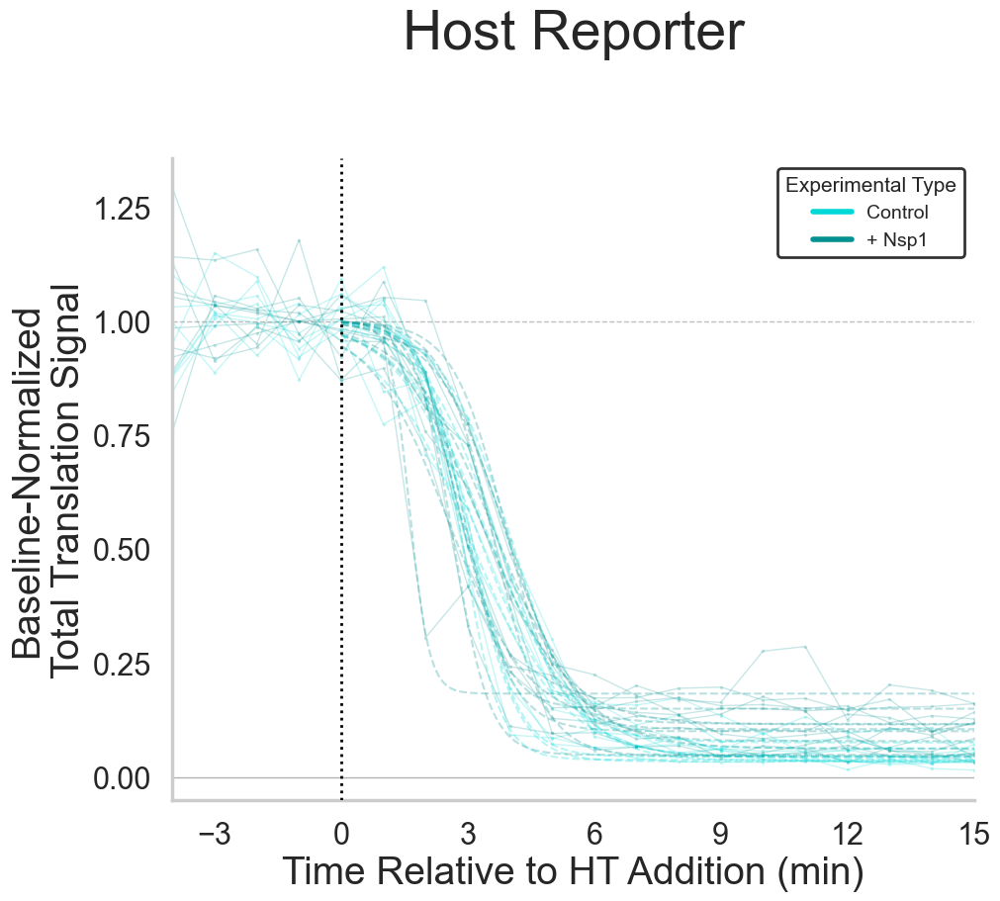

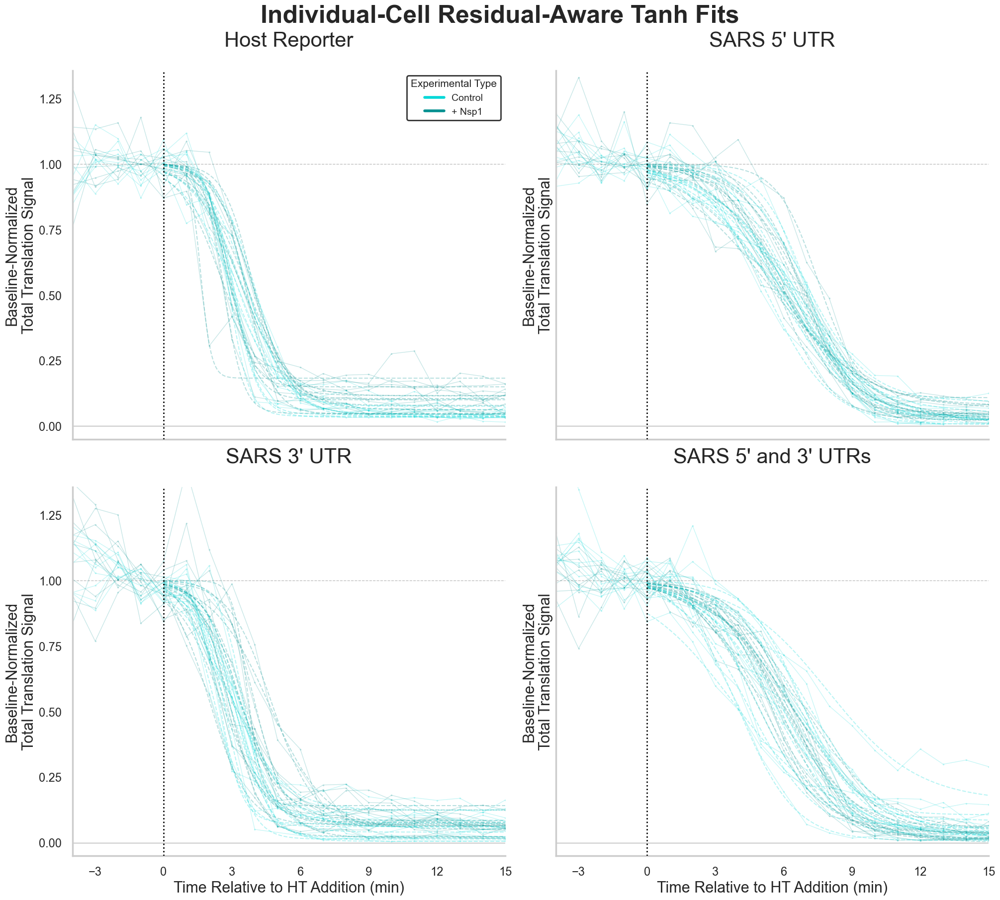

In [47]:
# CELL PURPOSE:
# Plot every measured individual-cell runoff curve together with its fitted
# residual-aware tanh curve.
#
# This cell contains the full plotting code for both the Host Reporter figure
# and the 2×2 all-reporter panel.

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

PLOT_ONLY_USABLE_CELL_FITS = True

CELL_FIT_DATA_ALPHA = 0.22
CELL_FIT_LINE_ALPHA = 0.28
CELL_FIT_DATA_LINEWIDTH = 1.0
CELL_FIT_MODEL_LINEWIDTH = 1.5

# ============================================================
# Host Reporter only
# ============================================================

group_name = CONTROL_GROUP

measured_group = cell_time_runoff.loc[
    cell_time_runoff["Experimental_Group"].astype(str).eq(str(group_name))
].copy()

fit_table_group = tanh_cell_fits.loc[
    tanh_cell_fits["Experimental_Group"].astype(str).eq(str(group_name))
].copy()

fit_curve_group = tanh_cell_fit_curves.loc[
    tanh_cell_fit_curves["Experimental_Group"].astype(str).eq(str(group_name))
].copy()

if PLOT_ONLY_USABLE_CELL_FITS:
    usable_fovs = set(
        fit_table_group.loc[
            fit_table_group["fit_usable"].fillna(False),
            "fov",
        ].astype(str)
    )

    measured_group = measured_group.loc[
        measured_group["fov"].astype(str).isin(usable_fovs)
    ].copy()

    fit_curve_group = fit_curve_group.loc[
        fit_curve_group["fov"].astype(str).isin(usable_fovs)
    ].copy()

fig, ax = plt.subplots(
    figsize=(10, 9),
    constrained_layout=True,
)

for experimental_type in TYPE_ORDER:

    measured_type = measured_group.loc[
        measured_group["Experimental_Type"].astype(str).eq(str(experimental_type))
    ].copy()

    fit_type = fit_curve_group.loc[
        fit_curve_group["Experimental_Type"].astype(str).eq(str(experimental_type))
    ].copy()

    for fov, cell_curve in measured_type.groupby(
        "fov",
        dropna=False,
        sort=False,
    ):

        cell_curve = cell_curve.sort_values("t")
        display_time = (
            cell_curve["t"] - HT_ADDITION_FRAME
        ) * FRAME_INTERVAL_MIN

        ax.plot(
            display_time,
            cell_curve[PER_CELL_FIT_METRIC],
            color=TYPE_COLORS.get(experimental_type, "gray"),
            linewidth=CELL_FIT_DATA_LINEWIDTH,
            alpha=CELL_FIT_DATA_ALPHA,
            marker="o",
            markersize=2.5,
            markeredgewidth=0,
            label="_nolegend_",
            zorder=2,
        )

        fitted_curve = fit_type.loc[
            fit_type["fov"].astype(str).eq(str(fov))
        ].sort_values("t")

        if not fitted_curve.empty:
            fit_display_time = (
                fitted_curve["t"] - HT_ADDITION_FRAME
            ) * FRAME_INTERVAL_MIN

            ax.plot(
                fit_display_time,
                fitted_curve["fit_value_display"],
                color=TYPE_COLORS.get(experimental_type, "gray"),
                linewidth=CELL_FIT_MODEL_LINEWIDTH,
                alpha=CELL_FIT_LINE_ALPHA,
                linestyle="--",
                label="_nolegend_",
                zorder=3,
            )

ax.axvline(0, color="black", linestyle=":", linewidth=2, zorder=5)
ax.axhline(1, color="gray", linestyle="--", linewidth=1, alpha=0.5, zorder=1)
ax.axhline(0, color="gray", linewidth=1, alpha=0.6, zorder=1)

ax.set_title(
    GROUP_LABELS.get(group_name, group_name),
    fontsize=40,
    pad=80,
)
ax.set_xlabel("Time Relative to HT Addition (min)", fontsize=28)
ax.set_ylabel(
    "Baseline-Normalized\nTotal Translation Signal",
    fontsize=28,
)
ax.tick_params(axis="both", which="major", labelsize=22)
ax.set_xlim(-4, 15)
ax.set_ylim(bottom=-0.05)
ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=7))
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))

legend_handles = [
    Line2D(
        [0],
        [0],
        color=TYPE_COLORS.get(experimental_type, "gray"),
        linewidth=4,
        label={
            "No Nsp1": "Control",
            "Nsp1": "+ Nsp1",
            "NoCTD Nsp1": "+ Nsp1ΔC",
        }.get(experimental_type, experimental_type),
    )
    for experimental_type in TYPE_ORDER
]

ax.legend(
    handles=legend_handles,
    title="Experimental Type",
    fontsize=14,
    title_fontsize=15,
    frameon=True,
    facecolor="white",
    edgecolor="black",
)

sns.despine(fig=fig, top=True, right=True, left=False, bottom=False)

save_figure(
    fig,
    "HT_Runoff_Individual_Cell_Fits_Host_Reporter",
)

plt.show()

host_cell_fit_figure = fig
host_cell_fit_axis = ax

# ============================================================
# All reporters in a 2×2 panel
# ============================================================

groups_to_plot = list(GROUP_ORDER[:4])

fig, axes = plt.subplots(
    2,
    2,
    figsize=(20, 18),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for panel_index, (ax, group_name) in enumerate(
    zip(axes.flat, groups_to_plot)
):

    measured_group = cell_time_runoff.loc[
        cell_time_runoff["Experimental_Group"].astype(str).eq(str(group_name))
    ].copy()

    fit_table_group = tanh_cell_fits.loc[
        tanh_cell_fits["Experimental_Group"].astype(str).eq(str(group_name))
    ].copy()

    fit_curve_group = tanh_cell_fit_curves.loc[
        tanh_cell_fit_curves["Experimental_Group"].astype(str).eq(str(group_name))
    ].copy()

    if PLOT_ONLY_USABLE_CELL_FITS:
        usable_fovs = set(
            fit_table_group.loc[
                fit_table_group["fit_usable"].fillna(False),
                "fov",
            ].astype(str)
        )

        measured_group = measured_group.loc[
            measured_group["fov"].astype(str).isin(usable_fovs)
        ].copy()

        fit_curve_group = fit_curve_group.loc[
            fit_curve_group["fov"].astype(str).isin(usable_fovs)
        ].copy()

    for experimental_type in TYPE_ORDER:

        measured_type = measured_group.loc[
            measured_group["Experimental_Type"].astype(str).eq(str(experimental_type))
        ].copy()

        fit_type = fit_curve_group.loc[
            fit_curve_group["Experimental_Type"].astype(str).eq(str(experimental_type))
        ].copy()

        for fov, cell_curve in measured_type.groupby(
            "fov",
            dropna=False,
            sort=False,
        ):

            cell_curve = cell_curve.sort_values("t")
            display_time = (
                cell_curve["t"] - HT_ADDITION_FRAME
            ) * FRAME_INTERVAL_MIN

            ax.plot(
                display_time,
                cell_curve[PER_CELL_FIT_METRIC],
                color=TYPE_COLORS.get(experimental_type, "gray"),
                linewidth=CELL_FIT_DATA_LINEWIDTH,
                alpha=CELL_FIT_DATA_ALPHA,
                marker="o",
                markersize=2.5,
                markeredgewidth=0,
                label="_nolegend_",
                zorder=2,
            )

            fitted_curve = fit_type.loc[
                fit_type["fov"].astype(str).eq(str(fov))
            ].sort_values("t")

            if not fitted_curve.empty:
                fit_display_time = (
                    fitted_curve["t"] - HT_ADDITION_FRAME
                ) * FRAME_INTERVAL_MIN

                ax.plot(
                    fit_display_time,
                    fitted_curve["fit_value_display"],
                    color=TYPE_COLORS.get(experimental_type, "gray"),
                    linewidth=CELL_FIT_MODEL_LINEWIDTH,
                    alpha=CELL_FIT_LINE_ALPHA,
                    linestyle="--",
                    label="_nolegend_",
                    zorder=3,
                )

    ax.axvline(0, color="black", linestyle=":", linewidth=2, zorder=5)
    ax.axhline(1, color="gray", linestyle="--", linewidth=1, alpha=0.5, zorder=1)
    ax.axhline(0, color="gray", linewidth=1, alpha=0.6, zorder=1)

    ax.set_title(
        GROUP_LABELS.get(group_name, group_name),
        fontsize=30,
        pad=35,
    )
    ax.set_xlabel("")
    ax.set_ylabel(
        "Baseline-Normalized\nTotal Translation Signal",
        fontsize=22,
    )
    ax.tick_params(axis="both", which="major", labelsize=17)
    ax.set_xlim(-4, 15)
    ax.set_ylim(bottom=-0.05)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=7))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))

    if panel_index == 0:
        ax.legend(
            handles=legend_handles,
            title="Experimental Type",
            fontsize=14,
            title_fontsize=15,
            frameon=True,
            facecolor="white",
            edgecolor="black",
        )

    sns.despine(ax=ax)

for ax in axes[0, :]:
    ax.set_xlabel("")

for ax in axes[1, :]:
    ax.set_xlabel(
        "Time Relative to HT Addition (min)",
        fontsize=22,
    )

for ax in axes.flat[len(groups_to_plot):]:
    ax.set_visible(False)

fig.suptitle(
    "Individual-Cell Residual-Aware Tanh Fits",
    fontsize=36,
    fontweight="bold",
)

save_figure(
    fig,
    "HT_Runoff_Individual_Cell_Fits_All_Groups_2x2",
)

plt.show()

all_cell_fit_figure = fig
all_cell_fit_axes = axes


In [52]:
# CELL PURPOSE:
# Combine each cell's fitted elongation rate with that same cell's
# time-0 translation-site brightness to calculate:
#
#     1. ribosome occupancy
#     2. ribosome density
#     3. translation time
#     4. initiation rate in ribosomes per MINUTE
#     5. initiation interval in seconds per ribosome
#
# Uncertainty is propagated from:
#
#     - the transferred absolute ribosome-occupancy calibration
#     - the HT reference-condition brightness
#     - within-cell translation-site brightness variability
#     - the fitted elongation-rate uncertainty
#
# IMPORTANT:
# Uncertainty availability is NOT used to decide whether a cell is
# kinetically usable. A valid cell should not disappear simply because
# an SEM cannot be estimated for one component.

import numpy as np
import pandas as pd


# ============================================================
# Validate upstream data
# ============================================================

required_upstream_tables = {
    "translation_brightness_spot_t0":
        translation_brightness_spot_t0
        if "translation_brightness_spot_t0" in globals()
        else None,

    "tanh_cell_fits":
        tanh_cell_fits
        if "tanh_cell_fits" in globals()
        else None,
}


missing_upstream_tables = [
    table_name
    for table_name, table_value
    in required_upstream_tables.items()
    if table_value is None
]


if missing_upstream_tables:

    raise NameError(
        "Run the required upstream sections before calculating "
        "per-cell kinetics.\n"
        f"Missing: {missing_upstream_tables}"
    )


required_settings = [
    "REFERENCE_RIBOSOME_OCCUPANCY",
    "REFERENCE_RIBOSOME_OCCUPANCY_SEM",
    "REFERENCE_EXPERIMENTAL_GROUP",
    "REFERENCE_EXPERIMENTAL_TYPE",
    "ORF_LENGTH_AA",
]


missing_settings = [
    setting
    for setting in required_settings
    if setting not in globals()
]


if missing_settings:

    raise NameError(
        "The following required calibration settings are missing:\n"
        f"{missing_settings}"
    )


# ============================================================
# Validate calibration values
# ============================================================

REFERENCE_RIBOSOME_OCCUPANCY = float(
    REFERENCE_RIBOSOME_OCCUPANCY
)

REFERENCE_RIBOSOME_OCCUPANCY_SEM = float(
    REFERENCE_RIBOSOME_OCCUPANCY_SEM
)

ORF_LENGTH_AA = float(
    ORF_LENGTH_AA
)


if (
    not np.isfinite(
        REFERENCE_RIBOSOME_OCCUPANCY
    )
    or REFERENCE_RIBOSOME_OCCUPANCY <= 0
):

    raise ValueError(
        "REFERENCE_RIBOSOME_OCCUPANCY must be "
        "positive and finite."
    )


if (
    not np.isfinite(
        REFERENCE_RIBOSOME_OCCUPANCY_SEM
    )
    or REFERENCE_RIBOSOME_OCCUPANCY_SEM < 0
):

    raise ValueError(
        "REFERENCE_RIBOSOME_OCCUPANCY_SEM must "
        "be finite and >= 0."
    )


if (
    not np.isfinite(
        ORF_LENGTH_AA
    )
    or ORF_LENGTH_AA <= 0
):

    raise ValueError(
        "ORF_LENGTH_AA must be positive and finite."
    )


# ============================================================
# Prepare time-0 translation-site brightness measurements
# ============================================================

brightness_source = (
    translation_brightness_spot_t0
    .copy()
)


brightness_source[
    "best_z_translation_brightness"
] = pd.to_numeric(
    brightness_source[
        "best_z_translation_brightness"
    ],
    errors="coerce",
)


brightness_source = (
    brightness_source.loc[
        np.isfinite(
            brightness_source[
                "best_z_translation_brightness"
            ]
        )
        &
        (
            brightness_source[
                "best_z_translation_brightness"
            ]
            > 0
        )
    ]
    .copy()
)


if brightness_source.empty:

    raise ValueError(
        "No positive finite time-0 translation-site "
        "brightness measurements remained."
    )


# ============================================================
# Calculate one time-0 mean translation-site brightness per cell
# ============================================================

brightness_cell_keys = [
    "Experimental_Group",
    "Experimental_Type",
    "fov",
]


for optional_column in [
    "Exp_G",
    "Movie_ID",
    "Replicate_Number",
    "Date",
    "Cell_Number",
    "Assignment_Key",
]:

    if optional_column in brightness_source.columns:

        brightness_cell_keys.append(
            optional_column
        )


per_cell_time0_brightness = (
    brightness_source
    .groupby(
        brightness_cell_keys,
        dropna=False,
    )
    .agg(
        mean_best_z_translation_brightness=(
            "best_z_translation_brightness",
            "mean",
        ),

        median_best_z_translation_brightness=(
            "best_z_translation_brightness",
            "median",
        ),

        best_z_translation_brightness_sd=(
            "best_z_translation_brightness",
            "std",
        ),

        n_translation_sites_t0=(
            "n",
            "nunique",
        ),
    )
    .reset_index()
)


# ------------------------------------------------------------
# SEM of translation-site brightness within each cell
# ------------------------------------------------------------

per_cell_time0_brightness[
    "best_z_translation_brightness_sem"
] = (
    per_cell_time0_brightness[
        "best_z_translation_brightness_sd"
    ]
    / np.sqrt(
        per_cell_time0_brightness[
            "n_translation_sites_t0"
        ]
    )
)


# ============================================================
# Establish the HT reference brightness
#
# Biological replicates are given equal weight:
#
#   1. mean brightness across cells within each replicate
#   2. mean and SEM across those replicate means
# ============================================================

reference_mask = (
    per_cell_time0_brightness[
        "Experimental_Group"
    ]
    .astype(str)
    .eq(
        str(
            REFERENCE_EXPERIMENTAL_GROUP
        )
    )
    &
    per_cell_time0_brightness[
        "Experimental_Type"
    ]
    .astype(str)
    .eq(
        str(
            REFERENCE_EXPERIMENTAL_TYPE
        )
    )
)


reference_cells = (
    per_cell_time0_brightness.loc[
        reference_mask
    ]
    .copy()
)


if reference_cells.empty:

    raise ValueError(
        "The configured occupancy reference condition "
        "was not found:\n"
        f"{REFERENCE_EXPERIMENTAL_GROUP} / "
        f"{REFERENCE_EXPERIMENTAL_TYPE}"
    )


if "Replicate_Number" in reference_cells.columns:

    reference_replicate_brightness = (
        reference_cells
        .groupby(
            "Replicate_Number",
            dropna=False,
        )[
            "mean_best_z_translation_brightness"
        ]
        .mean()
        .dropna()
    )

else:

    raise KeyError(
        "Replicate_Number is required to calculate the "
        "replicate-balanced HT reference brightness."
    )


if reference_replicate_brightness.empty:

    raise ValueError(
        "No valid biological-replicate reference "
        "brightness measurements remained."
    )


per_cell_reference_mean_brightness = float(
    reference_replicate_brightness.mean()
)


n_reference_replicates = int(
    len(
        reference_replicate_brightness
    )
)


if n_reference_replicates > 1:

    per_cell_reference_brightness_sd = float(
        reference_replicate_brightness.std(
            ddof=1
        )
    )

    per_cell_reference_brightness_sem = float(
        per_cell_reference_brightness_sd
        / np.sqrt(
            n_reference_replicates
        )
    )

else:

    per_cell_reference_brightness_sd = np.nan
    per_cell_reference_brightness_sem = np.nan


if (
    not np.isfinite(
        per_cell_reference_mean_brightness
    )
    or per_cell_reference_mean_brightness <= 0
):

    raise ValueError(
        "The reference mean time-0 brightness is invalid:\n"
        f"{per_cell_reference_mean_brightness}"
    )


# ============================================================
# HT brightness-to-ribosome conversion factor
# ============================================================

per_cell_brightness_per_ribosome = (
    per_cell_reference_mean_brightness
    / REFERENCE_RIBOSOME_OCCUPANCY
)


# ============================================================
# Shared calibration uncertainty
#
# The transferred occupancy calibration and the HT reference
# brightness are shared by every downstream occupancy-derived
# measurement.
# ============================================================

source_reference_relative_sem = (
    REFERENCE_RIBOSOME_OCCUPANCY_SEM
    / REFERENCE_RIBOSOME_OCCUPANCY
)


if np.isfinite(
    per_cell_reference_brightness_sem
):

    ht_reference_brightness_relative_sem = (
        per_cell_reference_brightness_sem
        / per_cell_reference_mean_brightness
    )

else:

    ht_reference_brightness_relative_sem = 0.0


shared_occupancy_calibration_relative_uncertainty = float(
    np.sqrt(
        source_reference_relative_sem ** 2
        +
        ht_reference_brightness_relative_sem ** 2
    )
)


# ============================================================
# Ribosome occupancy
#
# N = I_cell / brightness_per_ribosome
# ============================================================

per_cell_time0_brightness[
    "average_ribosome_occupancy"
] = (
    per_cell_time0_brightness[
        "mean_best_z_translation_brightness"
    ]
    / per_cell_brightness_per_ribosome
)


# ------------------------------------------------------------
# Cell-specific brightness uncertainty
# ------------------------------------------------------------

per_cell_time0_brightness[
    "cell_brightness_relative_sem"
] = (
    per_cell_time0_brightness[
        "best_z_translation_brightness_sem"
    ]
    / per_cell_time0_brightness[
        "mean_best_z_translation_brightness"
    ]
)


per_cell_time0_brightness[
    "cell_brightness_sem_available"
] = np.isfinite(
    per_cell_time0_brightness[
        "cell_brightness_relative_sem"
    ]
)


# If a cell has only one translation site, its within-cell SEM
# cannot be estimated. Do NOT exclude the cell. Use zero for
# that local uncertainty component while retaining all shared
# calibration uncertainty.
cell_brightness_relative_sem_for_propagation = (
    per_cell_time0_brightness[
        "cell_brightness_relative_sem"
    ]
    .fillna(
        0.0
    )
)


# ------------------------------------------------------------
# Occupancy uncertainty components
# ------------------------------------------------------------

per_cell_time0_brightness[
    "ribosome_occupancy_cell_measurement_uncertainty"
] = (
    per_cell_time0_brightness[
        "average_ribosome_occupancy"
    ]
    * cell_brightness_relative_sem_for_propagation
)


per_cell_time0_brightness[
    "ribosome_occupancy_shared_calibration_uncertainty"
] = (
    per_cell_time0_brightness[
        "average_ribosome_occupancy"
    ]
    * shared_occupancy_calibration_relative_uncertainty
)


per_cell_time0_brightness[
    "ribosome_occupancy_propagated_uncertainty"
] = np.sqrt(
    per_cell_time0_brightness[
        "ribosome_occupancy_cell_measurement_uncertainty"
    ] ** 2
    +
    per_cell_time0_brightness[
        "ribosome_occupancy_shared_calibration_uncertainty"
    ] ** 2
)


# ============================================================
# Ribosome density
#
# D = 100 * N / L
# ============================================================

per_cell_time0_brightness[
    "ribosome_density_per_100_codons"
] = (
    per_cell_time0_brightness[
        "average_ribosome_occupancy"
    ]
    * 100.0
    / ORF_LENGTH_AA
)


per_cell_time0_brightness[
    "ribosome_density_per_100_codons_propagated_uncertainty"
] = (
    per_cell_time0_brightness[
        "ribosome_occupancy_propagated_uncertainty"
    ]
    * 100.0
    / ORF_LENGTH_AA
)


# Also retain density per kilobase of coding sequence.
coding_sequence_length_kb = (
    ORF_LENGTH_AA
    * 3.0
    / 1000.0
)


per_cell_time0_brightness[
    "ribosome_density_per_coding_kb"
] = (
    per_cell_time0_brightness[
        "average_ribosome_occupancy"
    ]
    / coding_sequence_length_kb
)


per_cell_time0_brightness[
    "ribosome_density_per_coding_kb_propagated_uncertainty"
] = (
    per_cell_time0_brightness[
        "ribosome_occupancy_propagated_uncertainty"
    ]
    / coding_sequence_length_kb
)


# ============================================================
# Merge occupancy with individual-cell tanh fits
# ============================================================

kinetics_merge_keys = [
    "Experimental_Group",
    "Experimental_Type",
    "fov",
]


if tanh_cell_fits.duplicated(
    subset=kinetics_merge_keys,
    keep=False,
).any():

    raise ValueError(
        "tanh_cell_fits contains duplicate rows "
        "for the same cell."
    )


if per_cell_time0_brightness.duplicated(
    subset=kinetics_merge_keys,
    keep=False,
).any():

    raise ValueError(
        "per_cell_time0_brightness contains duplicate rows "
        "for the same cell."
    )


per_cell_ht_kinetics = (
    tanh_cell_fits
    .merge(
        per_cell_time0_brightness,
        on=kinetics_merge_keys,
        how="left",
        validate="one_to_one",
        suffixes=(
            "",
            "_brightness",
        ),
    )
)


# ============================================================
# Reconcile metadata columns after merging
# ============================================================

for metadata_column in [
    "Replicate_Number",
    "Date",
    "Cell_Number",
    "Movie_ID",
    "Exp_G",
    "Assignment_Key",
]:

    brightness_column = (
        f"{metadata_column}_brightness"
    )

    if (
        metadata_column
        in per_cell_ht_kinetics.columns
        and
        brightness_column
        in per_cell_ht_kinetics.columns
    ):

        per_cell_ht_kinetics[
            metadata_column
        ] = (
            per_cell_ht_kinetics[
                metadata_column
            ]
            .combine_first(
                per_cell_ht_kinetics[
                    brightness_column
                ]
            )
        )

        per_cell_ht_kinetics.drop(
            columns=[
                brightness_column
            ],
            inplace=True,
        )


# ============================================================
# Prepare elongation rate and elongation-rate uncertainty
# ============================================================

per_cell_ht_kinetics[
    "elongation_rate_aa_per_sec"
] = pd.to_numeric(
    per_cell_ht_kinetics[
        "elongation_rate_aa_per_sec"
    ],
    errors="coerce",
)


if (
    "elongation_rate_se"
    not in per_cell_ht_kinetics.columns
):

    per_cell_ht_kinetics[
        "elongation_rate_se"
    ] = np.nan


per_cell_ht_kinetics[
    "elongation_rate_se"
] = pd.to_numeric(
    per_cell_ht_kinetics[
        "elongation_rate_se"
    ],
    errors="coerce",
)


valid_cell_rate = (
    np.isfinite(
        per_cell_ht_kinetics[
            "elongation_rate_aa_per_sec"
        ]
    )
    &
    (
        per_cell_ht_kinetics[
            "elongation_rate_aa_per_sec"
        ]
        > 0
    )
)


valid_cell_occupancy = (
    np.isfinite(
        per_cell_ht_kinetics[
            "average_ribosome_occupancy"
        ]
    )
    &
    (
        per_cell_ht_kinetics[
            "average_ribosome_occupancy"
        ]
        > 0
    )
)


per_cell_ht_kinetics[
    "elongation_rate_relative_se"
] = np.where(
    (
        valid_cell_rate
        &
        np.isfinite(
            per_cell_ht_kinetics[
                "elongation_rate_se"
            ]
        )
        &
        (
            per_cell_ht_kinetics[
                "elongation_rate_se"
            ]
            >= 0
        )
    ),
    (
        per_cell_ht_kinetics[
            "elongation_rate_se"
        ]
        / per_cell_ht_kinetics[
            "elongation_rate_aa_per_sec"
        ]
    ),
    np.nan,
)


# ============================================================
# Translation time
#
# T = L / v
# ============================================================

per_cell_ht_kinetics[
    "translation_time_sec"
] = np.where(
    valid_cell_rate,
    (
        ORF_LENGTH_AA
        / per_cell_ht_kinetics[
            "elongation_rate_aa_per_sec"
        ]
    ),
    np.nan,
)


per_cell_ht_kinetics[
    "translation_time_propagated_uncertainty_sec"
] = np.where(
    (
        valid_cell_rate
        &
        np.isfinite(
            per_cell_ht_kinetics[
                "elongation_rate_relative_se"
            ]
        )
    ),
    (
        per_cell_ht_kinetics[
            "translation_time_sec"
        ]
        * per_cell_ht_kinetics[
            "elongation_rate_relative_se"
        ]
    ),
    np.nan,
)


# ============================================================
# Initiation rate — RIBOSOMES PER MINUTE
#
# k_sec = N * v / L
#
# Therefore:
#
# k_min = 60 * N * v / L
#
# The factor of 60 is exact and contributes no uncertainty.
# ============================================================

per_cell_ht_kinetics[
    "initiation_rate_ribosomes_per_min"
] = np.where(
    (
        valid_cell_rate
        &
        valid_cell_occupancy
    ),
    (
        60.0
        * per_cell_ht_kinetics[
            "average_ribosome_occupancy"
        ]
        * per_cell_ht_kinetics[
            "elongation_rate_aa_per_sec"
        ]
        / ORF_LENGTH_AA
    ),
    np.nan,
)


# ============================================================
# Propagate initiation-rate uncertainty
#
# k = 60 * N * v / L
#
# with 60 and L treated as exact:
#
# (u_k/k)^2 =
#       (u_N/N)^2
#     + (u_v/v)^2
# ============================================================

occupancy_relative_uncertainty = (
    per_cell_ht_kinetics[
        "ribosome_occupancy_propagated_uncertainty"
    ]
    / per_cell_ht_kinetics[
        "average_ribosome_occupancy"
    ]
)


initiation_relative_uncertainty = np.sqrt(
    occupancy_relative_uncertainty ** 2
    +
    per_cell_ht_kinetics[
        "elongation_rate_relative_se"
    ] ** 2
)


per_cell_ht_kinetics[
    "initiation_rate_propagated_uncertainty_ribosomes_per_min"
] = (
    per_cell_ht_kinetics[
        "initiation_rate_ribosomes_per_min"
    ]
    * initiation_relative_uncertainty
)


# Shared calibration portion only.
per_cell_ht_kinetics[
    "initiation_rate_shared_calibration_uncertainty_ribosomes_per_min"
] = (
    per_cell_ht_kinetics[
        "initiation_rate_ribosomes_per_min"
    ]
    * shared_occupancy_calibration_relative_uncertainty
)


# ============================================================
# Initiation interval
#
# Since initiation rate is now stored as ribosomes/min:
#
# tau_seconds = 60 / k_min
# ============================================================

valid_initiation_rate = (
    np.isfinite(
        per_cell_ht_kinetics[
            "initiation_rate_ribosomes_per_min"
        ]
    )
    &
    (
        per_cell_ht_kinetics[
            "initiation_rate_ribosomes_per_min"
        ]
        > 0
    )
)


per_cell_ht_kinetics[
    "initiation_interval_sec_per_ribosome"
] = np.where(
    valid_initiation_rate,
    (
        60.0
        / per_cell_ht_kinetics[
            "initiation_rate_ribosomes_per_min"
        ]
    ),
    np.nan,
)


# tau = 60 / k, therefore relative uncertainty is unchanged.
per_cell_ht_kinetics[
    "initiation_interval_propagated_uncertainty_sec"
] = np.where(
    (
        valid_initiation_rate
        &
        np.isfinite(
            initiation_relative_uncertainty
        )
    ),
    (
        per_cell_ht_kinetics[
            "initiation_interval_sec_per_ribosome"
        ]
        * initiation_relative_uncertainty
    ),
    np.nan,
)


per_cell_ht_kinetics[
    "initiation_interval_shared_calibration_uncertainty_sec"
] = (
    per_cell_ht_kinetics[
        "initiation_interval_sec_per_ribosome"
    ]
    * shared_occupancy_calibration_relative_uncertainty
)


# ============================================================
# Additional fitted outputs
# ============================================================

if (
    "fitted_residual_fraction"
    in per_cell_ht_kinetics.columns
):

    per_cell_ht_kinetics[
        "fitted_residual_fraction_percent"
    ] = (
        per_cell_ht_kinetics[
            "fitted_residual_fraction"
        ]
        * 100.0
    )


# ============================================================
# Determine kinetically usable cells
#
# IMPORTANT:
# A missing uncertainty estimate does NOT exclude a cell.
# ============================================================

per_cell_ht_kinetics[
    "kinetics_usable"
] = (
    per_cell_ht_kinetics[
        "fit_usable"
    ]
    .fillna(False)
    &
    valid_cell_rate
    &
    valid_cell_occupancy
    &
    valid_initiation_rate
)


# ============================================================
# Merge count-based HT-resistant fraction when available
# ============================================================

if (
    "df_ht_resistant"
    in globals()
    and not df_ht_resistant.empty
):

    resistant_merge_columns = [
        column
        for column in [
            "Experimental_Group",
            "Experimental_Type",
            "Replicate_Number",
            "fov",
            "HT_resistant_fraction (%)",
            "baseline_spot_count",
            "endpoint_retained_spot_count",
            "baseline_mean_spot_intensity",
            "endpoint_signal_threshold",
        ]
        if column
        in df_ht_resistant.columns
    ]


    resistant_merge_keys = [
        column
        for column in [
            "Experimental_Group",
            "Experimental_Type",
            "Replicate_Number",
            "fov",
        ]
        if (
            column
            in per_cell_ht_kinetics.columns
            and
            column
            in df_ht_resistant.columns
        )
    ]


    if resistant_merge_keys:

        resistant_cell_table = (
            df_ht_resistant[
                resistant_merge_columns
            ]
            .drop_duplicates(
                subset=resistant_merge_keys,
                keep="first",
            )
        )


        per_cell_ht_kinetics = (
            per_cell_ht_kinetics
            .merge(
                resistant_cell_table,
                on=resistant_merge_keys,
                how="left",
                validate="one_to_one",
            )
        )


# ============================================================
# Primary-analysis columns
# ============================================================

per_cell_ht_kinetics[
    "primary_elongation_rate_aa_per_sec"
] = np.where(
    per_cell_ht_kinetics[
        "fit_usable"
    ]
    .fillna(False),
    per_cell_ht_kinetics[
        "elongation_rate_aa_per_sec"
    ],
    np.nan,
)


per_cell_ht_kinetics[
    "primary_initiation_rate_ribosomes_per_min"
] = np.where(
    per_cell_ht_kinetics[
        "kinetics_usable"
    ]
    .fillna(False),
    per_cell_ht_kinetics[
        "initiation_rate_ribosomes_per_min"
    ],
    np.nan,
)


# ============================================================
# Replicate summaries
# ============================================================

replicate_cell_kinetics_summary = (
    per_cell_ht_kinetics
    .groupby(
        [
            "Experimental_Group",
            "Experimental_Type",
            "Replicate_Number",
        ],
        dropna=False,
    )
    .agg(
        mean_cell_elongation_rate_aa_per_sec=(
            "primary_elongation_rate_aa_per_sec",
            "mean",
        ),

        median_cell_elongation_rate_aa_per_sec=(
            "primary_elongation_rate_aa_per_sec",
            "median",
        ),

        cell_elongation_rate_sd=(
            "primary_elongation_rate_aa_per_sec",
            "std",
        ),

        cell_elongation_rate_sem=(
            "primary_elongation_rate_aa_per_sec",
            "sem",
        ),

        mean_initiation_rate_ribosomes_per_min=(
            "primary_initiation_rate_ribosomes_per_min",
            "mean",
        ),

        median_initiation_rate_ribosomes_per_min=(
            "primary_initiation_rate_ribosomes_per_min",
            "median",
        ),

        initiation_rate_sd_ribosomes_per_min=(
            "primary_initiation_rate_ribosomes_per_min",
            "std",
        ),

        initiation_rate_sem_ribosomes_per_min=(
            "primary_initiation_rate_ribosomes_per_min",
            "sem",
        ),

        mean_initiation_interval_sec_per_ribosome=(
            "initiation_interval_sec_per_ribosome",
            "mean",
        ),

        mean_ribosome_occupancy=(
            "average_ribosome_occupancy",
            "mean",
        ),

        median_ribosome_occupancy=(
            "average_ribosome_occupancy",
            "median",
        ),

        ribosome_occupancy_sem=(
            "average_ribosome_occupancy",
            "sem",
        ),

        mean_ribosome_density_per_100_codons=(
            "ribosome_density_per_100_codons",
            "mean",
        ),

        median_ribosome_density_per_100_codons=(
            "ribosome_density_per_100_codons",
            "median",
        ),

        ribosome_density_sem=(
            "ribosome_density_per_100_codons",
            "sem",
        ),

        n_cell_fits=(
            "fov",
            "nunique",
        ),

        n_usable_kinetic_cells=(
            "kinetics_usable",
            lambda values: int(
                pd.Series(
                    values
                )
                .fillna(False)
                .astype(bool)
                .sum()
            ),
        ),
    )
    .reset_index()
)


# ============================================================
# Save calibration information
# ============================================================

per_cell_occupancy_calibration = pd.DataFrame({

    "Reference_Experimental_Group": [
        REFERENCE_EXPERIMENTAL_GROUP
    ],

    "Reference_Experimental_Type": [
        REFERENCE_EXPERIMENTAL_TYPE
    ],

    "Reference_Ribosome_Occupancy": [
        REFERENCE_RIBOSOME_OCCUPANCY
    ],

    "Reference_Ribosome_Occupancy_SEM": [
        REFERENCE_RIBOSOME_OCCUPANCY_SEM
    ],

    "Reference_Mean_Cell_Brightness": [
        per_cell_reference_mean_brightness
    ],

    "Reference_Brightness_SEM": [
        per_cell_reference_brightness_sem
    ],

    "Number_of_Reference_Replicates": [
        n_reference_replicates
    ],

    "Brightness_Per_Ribosome": [
        per_cell_brightness_per_ribosome
    ],

    "Source_Reference_Relative_SEM": [
        source_reference_relative_sem
    ],

    "HT_Reference_Brightness_Relative_SEM": [
        ht_reference_brightness_relative_sem
    ],

    "Shared_Occupancy_Calibration_Relative_Uncertainty": [
        shared_occupancy_calibration_relative_uncertainty
    ],

    "ORF_Length_AA": [
        ORF_LENGTH_AA
    ],

    "Ribosome_Density_Units": [
        "ribosomes per 100 codons"
    ],

    "Initiation_Rate_Units": [
        "ribosomes per minute"
    ],

    "Initiation_Rate_Formula": [
        "60 * cell occupancy * cell elongation rate / ORF length"
    ],
})


# ============================================================
# Save results
# ============================================================

save_table(
    per_cell_time0_brightness,
    "tethered_ht_per_cell_time0_brightness_and_density",
)


save_table(
    per_cell_ht_kinetics,
    "tethered_ht_per_cell_fitted_kinetics",
)


save_table(
    replicate_cell_kinetics_summary,
    "tethered_ht_replicate_summary_from_cell_fits",
)


save_table(
    per_cell_occupancy_calibration,
    "tethered_ht_per_cell_occupancy_calibration",
)


# ============================================================
# Report
# ============================================================

print(
    "\nPer-cell fitted kinetic calculations"
)

print(
    "------------------------------------"
)

print(
    "Cell fits available: "
    f"{len(per_cell_ht_kinetics):,}"
)

print(
    "Cells with time-0 occupancy: "
    f"{int(valid_cell_occupancy.sum()):,}"
)

print(
    "Cells with usable fit and occupancy: "
    f"{int(per_cell_ht_kinetics['kinetics_usable'].sum()):,}"
)

print(
    "Transferred reference occupancy: "
    f"{REFERENCE_RIBOSOME_OCCUPANCY:.3f} "
    f"± {REFERENCE_RIBOSOME_OCCUPANCY_SEM:.3f} ribosomes"
)

print(
    "HT reference mean brightness: "
    f"{per_cell_reference_mean_brightness:.4f} "
    f"± {per_cell_reference_brightness_sem:.4f} SEM"
)

print(
    "Brightness per ribosome: "
    f"{per_cell_brightness_per_ribosome:.4f}"
)

print(
    "Shared occupancy calibration relative uncertainty: "
    f"{100 * shared_occupancy_calibration_relative_uncertainty:.2f}%"
)


display(
    per_cell_ht_kinetics[
        [
            column
            for column in [
                "Experimental_Group",
                "Experimental_Type",
                "Replicate_Number",
                "Cell_Number",
                "fov",

                "elongation_rate_aa_per_sec",
                "elongation_rate_se",

                "average_ribosome_occupancy",
                "ribosome_occupancy_propagated_uncertainty",

                "ribosome_density_per_100_codons",
                "ribosome_density_per_100_codons_propagated_uncertainty",

                "translation_time_sec",
                "translation_time_propagated_uncertainty_sec",

                "initiation_rate_ribosomes_per_min",
                "initiation_rate_propagated_uncertainty_ribosomes_per_min",

                "initiation_interval_sec_per_ribosome",
                "initiation_interval_propagated_uncertainty_sec",

                "fitted_residual_fraction_percent",
                "HT_resistant_fraction (%)",

                "fit_usable",
                "kinetics_usable",
            ]
            if column
            in per_cell_ht_kinetics.columns
        ]
    ]
    .head(40)
)


display(
    replicate_cell_kinetics_summary
)

Parquet unavailable for tethered_ht_per_cell_time0_brightness_and_density: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.
Saved: Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT\Analysis_Output\Tethered_HT\Dataframes\tethered_ht_per_cell_time0_brightness_and_density.csv
Parquet unavailable for tethered_ht_per_cell_fitted_kinetics: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'.

,Experimental_Group,Experimental_Type,Replicate_Number,Cell_Number,fov,elongation_rate_aa_per_sec,elongation_rate_se,average_ribosome_occupancy,ribosome_occupancy_propagated_uncertainty,ribosome_density_per_100_codons,ribosome_density_per_100_codons_propagated_uncertainty,translation_time_sec,translation_time_propagated_uncertainty_sec,initiation_rate_ribosomes_per_min,initiation_rate_propagated_uncertainty_ribosomes_per_min,initiation_interval_sec_per_ribosome,initiation_interval_propagated_uncertainty_sec,fitted_residual_fraction_percent,HT_resistant_fraction (%),fit_usable,kinetics_usable
0,Control,No Nsp1,1,1,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,3.190205,0.315654,7.119546,0.947080,0.912762,0.121420,244.498371,24.191838,1.747139,0.289655,34.341849,5.693481,6.291805e+00,1.960784,True,True
1,Control,No Nsp1,1,2,SARS_CTRL_20260709_20260709_3_1_Cell02_processed_Cell02_TRNL_Ch1_nc,3.949638,0.282754,9.551840,1.202542,1.224595,0.154172,197.486462,14.138017,2.902024,0.420293,20.675227,2.994341,3.593146e+00,0.000000,True,True
2,Control,No Nsp1,1,3,SARS_CTRL_20260709_20260709_3_1_Cell03_processed_Cell03_TRNL_Ch1_nc,2.944818,0.217855,6.003167,0.767020,0.769637,0.098336,264.872094,19.595042,1.359864,0.200772,44.122060,6.514232,4.136506e+00,0.000000,True,True
3,Control,No Nsp1,1,4,SARS_CTRL_20260709_20260709_3_1_Cell04_processed_Cell04_TRNL_Ch1_nc,3.608675,0.134336,11.594585,1.364865,1.486485,0.174983,216.145829,8.046229,3.218545,0.397367,18.641964,2.301567,4.562474e+00,4.255319,True,True
4,SARS_3'UTR,No Nsp1,1,1,SARS_3_UTR_20260713_20260713_1_1_Cell01_processed_Cell01_TRNL_Ch1_nc,4.021703,0.432907,9.653922,1.205909,1.237682,0.154604,193.947703,20.877039,2.986554,0.492468,20.090043,3.312751,8.545934e+00,2.976190,True,True
5,SARS_3'UTR,No Nsp1,1,2,SARS_3_UTR_20260713_20260713_1_1_Cell02_processed_Cell02_TRNL_Ch1_nc,2.810025,0.298608,18.464927,2.144144,2.367298,0.274890,277.577599,29.496822,3.991300,0.628248,15.032694,2.366210,1.234221e+01,7.285974,True,True
6,SARS_3'UTR,No Nsp1,1,3,SARS_3_UTR_20260713_20260713_1_1_Cell03_processed_Cell03_TRNL_Ch1_nc,3.791068,0.463454,7.953601,1.191248,1.019692,0.152724,205.746783,25.152338,2.319434,0.448421,25.868380,5.001186,7.792352e+00,6.849315,True,True
7,SARS_3'UTR,No Nsp1,1,4,SARS_3_UTR_20260713_20260713_1_1_Cell04_processed_Cell04_TRNL_Ch1_nc,4.124276,0.301837,10.352518,1.179953,1.327246,0.151276,189.124085,13.841132,3.284357,0.444869,18.268414,2.474473,4.027213e+00,0.647668,True,True
8,SARS_3'UTR,No Nsp1,1,5,SARS_3_UTR_20260713_20260713_1_1_Cell05_processed_Cell05_TRNL_Ch1_nc,4.865915,0.567905,7.692807,0.958505,0.986257,0.122885,160.298722,18.708596,2.879427,0.491581,20.837480,3.557415,6.126243e+00,3.144654,True,True
9,SARS_5'UTR,No Nsp1,1,1,SARS_5_UTR_20260713_20260713_2_1_Cell01_processed_Cell01_TRNL_Ch1_nc,1.787860,0.122151,6.898841,0.870470,0.884467,0.111599,436.275688,29.807339,0.948782,0.136137,63.238985,9.073946,3.039081e-01,1.915709,True,True


,Experimental_Group,Experimental_Type,Replicate_Number,mean_cell_elongation_rate_aa_per_sec,median_cell_elongation_rate_aa_per_sec,cell_elongation_rate_sd,cell_elongation_rate_sem,mean_initiation_rate_ribosomes_per_min,median_initiation_rate_ribosomes_per_min,initiation_rate_sd_ribosomes_per_min,initiation_rate_sem_ribosomes_per_min,mean_initiation_interval_sec_per_ribosome,mean_ribosome_occupancy,median_ribosome_occupancy,ribosome_occupancy_sem,mean_ribosome_density_per_100_codons,median_ribosome_density_per_100_codons,ribosome_density_sem,n_cell_fits,n_usable_kinetic_cells
0,Control,No Nsp1,1,3.423334,3.399440,0.445224,0.222612,2.306893,2.324582,0.893584,0.446792,29.445275,8.567284,8.335693,1.251817,1.098370,1.068679,0.160489,4,4
1,Control,No Nsp1,2,5.653640,5.909050,1.664500,0.832250,3.599800,3.616134,0.752965,0.376483,17.244547,8.612716,8.491948,0.949061,1.104194,1.088711,0.121674,4,4
2,Control,Nsp1,1,6.608207,4.584869,5.004570,2.502285,7.274373,6.225811,4.625934,2.312967,11.122391,15.435063,12.536145,3.098911,1.978854,1.607198,0.397296,4,4
3,Control,Nsp1,2,5.254252,5.455478,1.696237,0.692486,5.434796,4.196680,2.583063,1.054531,12.918601,13.380874,14.944108,1.390566,1.715497,1.915911,0.178278,6,6
4,SARS_3'UTR,No Nsp1,1,3.922597,4.021703,0.740855,0.331320,3.092215,2.986554,0.612149,0.273761,20.019402,10.823555,9.653922,1.975078,1.387635,1.237682,0.253215,5,5
5,SARS_3'UTR,No Nsp1,2,5.110858,5.680940,1.446896,0.647072,2.855832,2.539873,1.345930,0.601918,24.303373,7.275296,7.773369,0.990628,0.932730,0.996586,0.127004,5,5
6,SARS_3'UTR,Nsp1,1,3.957809,3.815560,0.504976,0.225832,3.561425,3.233654,1.047547,0.468477,18.015698,11.708033,9.910466,1.422537,1.501030,1.270573,0.182376,5,5
7,SARS_3'UTR,Nsp1,2,4.724954,3.692419,2.774573,1.132715,2.922506,3.088055,0.685787,0.279971,21.606943,9.317972,9.961359,1.304075,1.194612,1.277097,0.167189,6,6
8,SARS_5'UTR,No Nsp1,1,1.926235,1.814936,0.284366,0.127173,2.787712,2.377846,2.215776,0.990925,32.001489,17.694450,17.032006,4.852252,2.268519,2.183590,0.622084,5,5
9,SARS_5'UTR,No Nsp1,2,2.245686,2.300085,0.604689,0.270425,1.758549,1.837762,0.627280,0.280528,38.723334,9.196388,9.851993,1.193896,1.179024,1.263076,0.153064,6,5


In [53]:
# CELL PURPOSE:
# Create replicate-level and group-level uncertainty summaries for the
# final per-cell kinetic measurements.
#
# For absolute occupancy-derived quantities, distinguish:
#
#     1. biological variation
#     2. shared calibration uncertainty
#     3. total propagated uncertainty
#
# The propagated uncertainty is:
#
#     sqrt(
#         Biological_Replicate_SEM^2
#         +
#         Shared_Calibration_Uncertainty^2
#     )
#
# IMPORTANT:
# The shared calibration component should be used when reporting the
# absolute numerical value, but should NOT be treated as independent
# biological noise in statistical comparisons between conditions.

import numpy as np
import pandas as pd


# ============================================================
# Define final metrics
# ============================================================

metric_specs = {

    "average_ribosome_occupancy": {
        "requires_fit": False,
        "requires_kinetics": False,
        "uses_occupancy_calibration": True,
    },

    "ribosome_density_per_100_codons": {
        "requires_fit": False,
        "requires_kinetics": False,
        "uses_occupancy_calibration": True,
    },

    "elongation_rate_aa_per_sec": {
        "requires_fit": True,
        "requires_kinetics": False,
        "uses_occupancy_calibration": False,
    },

    "translation_time_sec": {
        "requires_fit": True,
        "requires_kinetics": False,
        "uses_occupancy_calibration": False,
    },

    "initiation_rate_ribosomes_per_min": {
        "requires_fit": False,
        "requires_kinetics": True,
        "uses_occupancy_calibration": True,
    },

    "initiation_interval_sec_per_ribosome": {
        "requires_fit": False,
        "requires_kinetics": True,
        "uses_occupancy_calibration": True,
    },
}


# ============================================================
# Containers
# ============================================================

replicate_rows = []
group_rows = []


# ============================================================
# Process each metric
# ============================================================

for metric, spec in metric_specs.items():

    if metric not in per_cell_ht_kinetics.columns:

        print(
            f"Skipping {metric}: column not found."
        )

        continue


    working = (
        per_cell_ht_kinetics
        .copy()
    )


    # --------------------------------------------------------
    # Select the appropriate valid population
    # --------------------------------------------------------

    if spec[
        "requires_kinetics"
    ]:

        working = (
            working.loc[
                working[
                    "kinetics_usable"
                ]
                .fillna(False)
            ]
            .copy()
        )


    elif spec[
        "requires_fit"
    ]:

        working = (
            working.loc[
                working[
                    "fit_usable"
                ]
                .fillna(False)
            ]
            .copy()
        )


    working[
        metric
    ] = pd.to_numeric(
        working[
            metric
        ],
        errors="coerce",
    )


    working = (
        working.loc[
            np.isfinite(
                working[
                    metric
                ]
            )
        ]
        .copy()
    )


    if working.empty:

        print(
            f"Skipping {metric}: no valid values."
        )

        continue


    # ========================================================
    # Replicate-level summary
    #
    # First calculate a mean across cells within each
    # biological replicate.
    # ========================================================

    replicate_metric = (
        working
        .groupby(
            [
                "Experimental_Group",
                "Experimental_Type",
                "Replicate_Number",
            ],
            dropna=False,
        )[
            metric
        ]
        .agg(
            Replicate_Mean="mean",
            Cell_SD="std",
            N_Cells="count",
        )
        .reset_index()
    )


    replicate_metric[
        "Cell_SEM"
    ] = (
        replicate_metric[
            "Cell_SD"
        ]
        / np.sqrt(
            replicate_metric[
                "N_Cells"
            ]
        )
    )


    replicate_metric[
        "Metric"
    ] = metric


    # --------------------------------------------------------
    # Shared calibration uncertainty
    #
    # This is a correlated scale uncertainty and therefore does
    # NOT decrease simply because more cells exist.
    # --------------------------------------------------------

    if spec[
        "uses_occupancy_calibration"
    ]:

        replicate_metric[
            "Shared_Calibration_Uncertainty"
        ] = (
            replicate_metric[
                "Replicate_Mean"
            ]
            * shared_occupancy_calibration_relative_uncertainty
        )

    else:

        replicate_metric[
            "Shared_Calibration_Uncertainty"
        ] = 0.0


    # --------------------------------------------------------
    # Absolute uncertainty associated with each replicate mean
    # --------------------------------------------------------

    replicate_metric[
        "Propagated_Replicate_Uncertainty"
    ] = np.sqrt(
        replicate_metric[
            "Cell_SEM"
        ]
        .fillna(0.0) ** 2
        +
        replicate_metric[
            "Shared_Calibration_Uncertainty"
        ]
        .fillna(0.0) ** 2
    )


    replicate_rows.append(
        replicate_metric
    )


    # ========================================================
    # Group-level summary
    #
    # The final group mean is the mean of the biological-
    # replicate means.
    # ========================================================

    group_metric = (
        replicate_metric
        .groupby(
            [
                "Experimental_Group",
                "Experimental_Type",
            ],
            dropna=False,
        )[
            "Replicate_Mean"
        ]
        .agg(
            Group_Mean="mean",
            Replicate_SD="std",
            N_Replicates="count",
        )
        .reset_index()
    )


    group_metric[
        "Biological_Replicate_SEM"
    ] = (
        group_metric[
            "Replicate_SD"
        ]
        / np.sqrt(
            group_metric[
                "N_Replicates"
            ]
        )
    )


    group_metric[
        "Metric"
    ] = metric


    # --------------------------------------------------------
    # Shared calibration component at the group level
    # --------------------------------------------------------

    if spec[
        "uses_occupancy_calibration"
    ]:

        group_metric[
            "Shared_Calibration_Uncertainty"
        ] = (
            group_metric[
                "Group_Mean"
            ]
            * shared_occupancy_calibration_relative_uncertainty
        )

    else:

        group_metric[
            "Shared_Calibration_Uncertainty"
        ] = 0.0


    # --------------------------------------------------------
    # Final uncertainty for reporting absolute values
    # --------------------------------------------------------

    group_metric[
        "Propagated_Uncertainty"
    ] = np.sqrt(
        group_metric[
            "Biological_Replicate_SEM"
        ]
        .fillna(0.0) ** 2
        +
        group_metric[
            "Shared_Calibration_Uncertainty"
        ]
        .fillna(0.0) ** 2
    )


    group_rows.append(
        group_metric
    )


# ============================================================
# Combine summaries
# ============================================================

if replicate_rows:

    ht_replicate_kinetics_uncertainty = (
        pd.concat(
            replicate_rows,
            ignore_index=True,
        )
    )

else:

    ht_replicate_kinetics_uncertainty = (
        pd.DataFrame()
    )


if group_rows:

    ht_group_kinetics_uncertainty = (
        pd.concat(
            group_rows,
            ignore_index=True,
        )
    )

else:

    ht_group_kinetics_uncertainty = (
        pd.DataFrame()
    )


# ============================================================
# Save
# ============================================================

save_table(
    ht_replicate_kinetics_uncertainty,
    "tethered_ht_replicate_kinetics_with_propagated_uncertainty",
)


save_table(
    ht_group_kinetics_uncertainty,
    "tethered_ht_group_kinetics_with_propagated_uncertainty",
)


# ============================================================
# Display initiation-rate summary explicitly
# ============================================================

initiation_rate_uncertainty_summary = (
    ht_group_kinetics_uncertainty.loc[
        ht_group_kinetics_uncertainty[
            "Metric"
        ]
        .eq(
            "initiation_rate_ribosomes_per_min"
        )
    ]
    .copy()
)


print(
    "\nInitiation rate — ribosomes per minute"
)

print(
    "======================================"
)


display(
    initiation_rate_uncertainty_summary[
        [
            "Experimental_Group",
            "Experimental_Type",
            "Group_Mean",
            "Biological_Replicate_SEM",
            "Shared_Calibration_Uncertainty",
            "Propagated_Uncertainty",
            "N_Replicates",
        ]
    ]
    .sort_values(
        [
            "Experimental_Group",
            "Experimental_Type",
        ]
    )
)


# ============================================================
# Display complete summary
# ============================================================

print(
    "\nAll kinetic uncertainty summaries"
)


display(
    ht_group_kinetics_uncertainty
    .sort_values(
        [
            "Metric",
            "Experimental_Group",
            "Experimental_Type",
        ]
    )
)

Parquet unavailable for tethered_ht_replicate_kinetics_with_propagated_uncertainty: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.
Saved: Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT\Analysis_Output\Tethered_HT\Dataframes\tethered_ht_replicate_kinetics_with_propagated_uncertainty.csv
Parquet unavailable for tethered_ht_group_kinetics_with_propagated_uncertainty: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Mi

,Experimental_Group,Experimental_Type,Group_Mean,Biological_Replicate_SEM,Shared_Calibration_Uncertainty,Propagated_Uncertainty,N_Replicates
32,Control,No Nsp1,2.953346,0.646453,0.323278,0.722780,2
33,Control,Nsp1,6.354584,0.919788,0.695582,1.153189,2
34,SARS_3'UTR,No Nsp1,2.974023,0.118191,0.325541,0.346333,2
35,SARS_3'UTR,Nsp1,3.241966,0.319460,0.354871,0.477480,2
36,SARS_5'UTR,No Nsp1,2.273131,0.514582,0.248820,0.571582,2
37,SARS_5'UTR,Nsp1,2.465415,0.327867,0.269868,0.424648,2
38,SARS_5'_3'UTR,No Nsp1,4.607856,1.212622,0.504383,1.313337,2
39,SARS_5'_3'UTR,Nsp1,6.511116,0.118386,0.712717,0.722482,2



All kinetic uncertainty summaries


,Experimental_Group,Experimental_Type,Group_Mean,Replicate_SD,N_Replicates,Biological_Replicate_SEM,Metric,Shared_Calibration_Uncertainty,Propagated_Uncertainty
0,Control,No Nsp1,8.590000,0.032125,2,0.022716,average_ribosome_occupancy,0.940274,0.940549
1,Control,Nsp1,14.407969,1.452531,2,1.027094,average_ribosome_occupancy,1.577118,1.882080
2,SARS_3'UTR,No Nsp1,9.049426,2.508998,2,1.774129,average_ribosome_occupancy,0.990564,2.031933
3,SARS_3'UTR,Nsp1,10.513002,1.690029,2,1.195031,average_ribosome_occupancy,1.150769,1.659026
4,SARS_5'UTR,No Nsp1,13.445419,6.009038,2,4.249031,average_ribosome_occupancy,1.471756,4.496702
5,SARS_5'UTR,Nsp1,13.804519,2.568778,2,1.816400,average_ribosome_occupancy,1.511064,2.362758
6,SARS_5'_3'UTR,No Nsp1,27.842193,8.132325,2,5.750422,average_ribosome_occupancy,3.047649,6.508112
7,SARS_5'_3'UTR,Nsp1,38.318263,1.824237,2,1.289931,average_ribosome_occupancy,4.194375,4.388246
16,Control,No Nsp1,4.538487,1.577065,2,1.115153,elongation_rate_aa_per_sec,0.000000,1.115153
17,Control,Nsp1,5.931230,0.957390,2,0.676977,elongation_rate_aa_per_sec,0.000000,0.676977


### Cell-level kinetic plotting convention

The previous generic `plot_metric_control_and_all_groups()` helper has been
removed. Each kinetic metric below now has explicit Host Reporter and
all-reporter plotting code, using the replicate-average workflow copied from
the analysis notebook.


### Plot — Individual-cell elongation rate

C:\Users\AdamC\AppData\Local\Temp\ipykernel_8044\3501707677.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


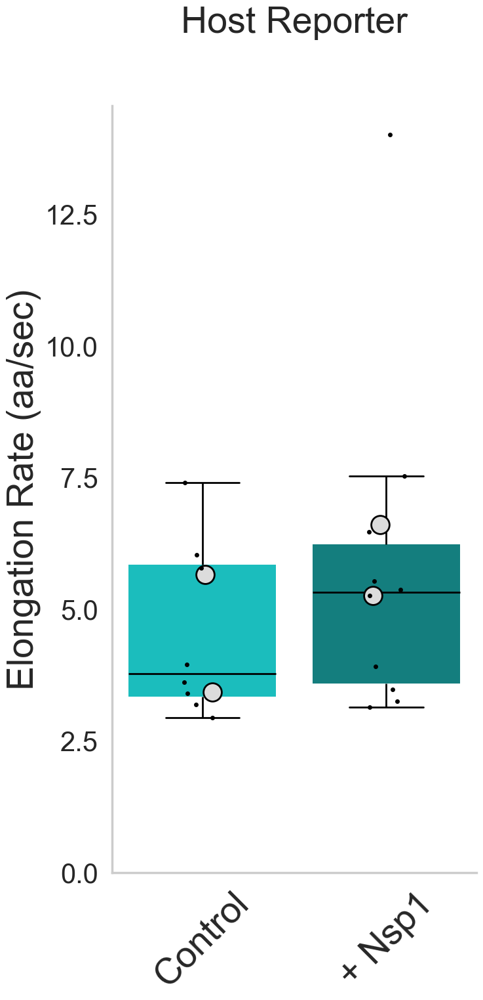

C:\Users\AdamC\AppData\Local\Temp\ipykernel_8044\3501707677.py:179: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


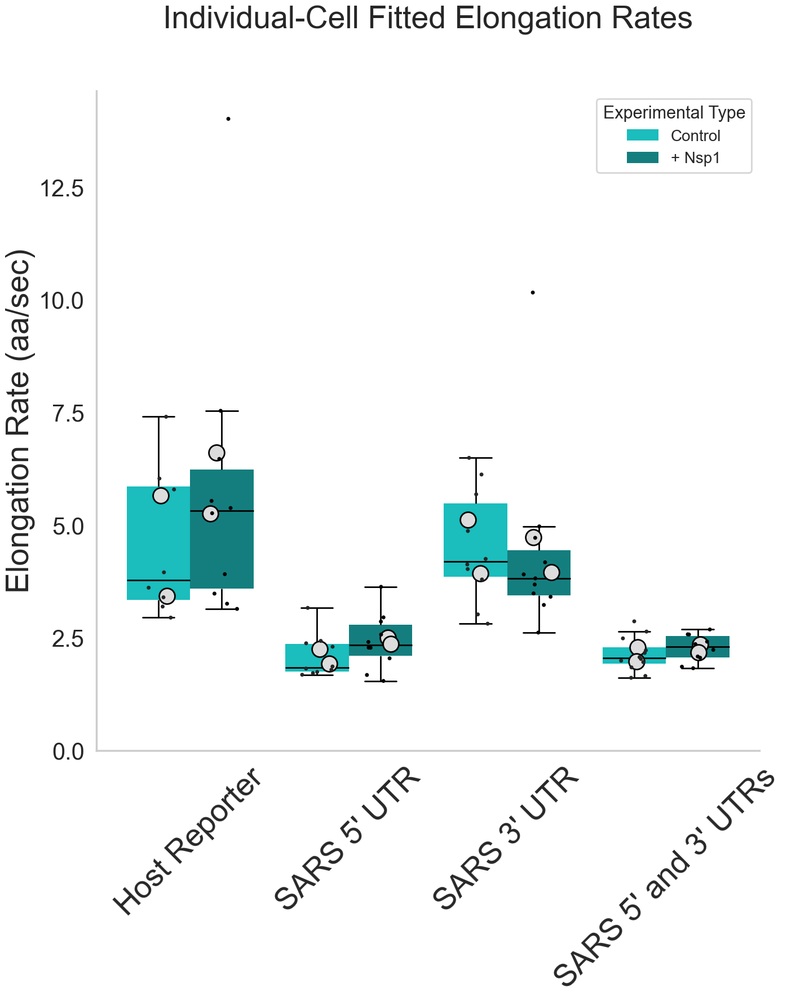

In [49]:
# CELL PURPOSE:
# Plot elongation rates obtained from individual-cell tanh fits.
#
# The Host Reporter and all-reporter figures are written explicitly in this
# cell to match the customizable plotting pattern in crop_array_analysis(8).

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# ============================================================
# Prepare one value per cell and calculate replicate means
# ============================================================

cell_elongation_plot_data = tanh_cell_fits.loc[tanh_cell_fits['fit_usable'].fillna(False)].copy()

data = collapse_to_one_value_per_cell(
    cell_elongation_plot_data,
    "elongation_rate_aa_per_sec",
).rename(
    columns={
        "_Replicate_ID": "Replicate_Number",
        "_Cell_ID": "Cell_ID",
    }
)

superplot = calculate_grouped_average(
    data,
    "elongation_rate_aa_per_sec",
    ["Experimental_Group", "Experimental_Type", "Replicate_Number"],
)

type_order = [
    experimental_type for experimental_type in TYPE_ORDER
    if experimental_type in data["Experimental_Type"].astype(str).unique()
]

type_label_map = {
    "No Nsp1": "Control",
    "Nsp1": "+ Nsp1",
    "NoCTD Nsp1": "+ Nsp1ΔC",
}

# ============================================================
# PLOT 1: Host Reporter
# ============================================================

control_data = data.loc[
    data["Experimental_Group"].astype(str).eq(str(CONTROL_GROUP))
].copy()

control_superplot = superplot.loc[
    superplot["Experimental_Group"].astype(str).eq(str(CONTROL_GROUP))
].copy()

order = type_order
new_labels = [
    type_label_map.get(experimental_type, experimental_type)
    for experimental_type in order
]

fig, ax = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig, top=True, right=True, left=False, bottom=False)

sns.boxplot(
    x="Experimental_Type",
    y="elongation_rate_aa_per_sec",
    data=control_data,
    order=order,
    ax=ax,
    palette=blue_palette,
    boxprops=dict(linewidth=0),
    whiskerprops=dict(color="black", linewidth=2),
    capprops=dict(color="black", linewidth=2),
    medianprops=dict(color="black", linewidth=2),
    showfliers=False,
)

sns.stripplot(
    x="Experimental_Type",
    y="elongation_rate_aa_per_sec",
    data=control_data,
    order=order,
    color="black",
    alpha=1,
    size=5,
    jitter=True,
    dodge=True,
    ax=ax,
    zorder=9,
)

plot_open_circles_with_hue(
    ax,
    control_superplot,
    order=order,
    x="Experimental_Type",
    y="Super elongation_rate_aa_per_sec",
    hue="Experimental_Group",
    jitter=True,
    jitter_strength=0.08,
    random_state=100,
)

ax.set_title(
    GROUP_LABELS.get(CONTROL_GROUP, CONTROL_GROUP),
    fontsize=40,
    pad=80,
)
ax.set_ylabel('Elongation Rate (aa/sec)', fontsize=40)
ax.set_xlabel("")
ax.set_ylim(bottom=0)
ax.tick_params(axis="both", which="major", labelsize=30)
ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))

if ax.get_legend() is not None:
    ax.get_legend().remove()

save_figure(
    fig,
    "HT_Cell_Fitted_Elongation_Rate_Host_Reporter",
)

plt.tight_layout()
plt.show()

control_figure = fig
control_axis = ax

# ============================================================
# PLOT 2: All reporters
# ============================================================

group_order = [
    group for group in GROUP_ORDER
    if group in data["Experimental_Group"].astype(str).unique()
]

new_group_labels = [
    GROUP_LABELS.get(group, group)
    for group in group_order
]

fig_all, ax_all = plt.subplots(
    figsize=(16, 16),
    constrained_layout=True,
)

sns.despine(
    fig=fig_all,
    top=True,
    right=True,
    left=False,
    bottom=False,
)

sns.boxplot(
    x="Experimental_Group",
    y="elongation_rate_aa_per_sec",
    hue="Experimental_Type",
    data=data,
    order=group_order,
    hue_order=type_order,
    ax=ax_all,
    palette=blue_palette,
    boxprops=dict(linewidth=0),
    whiskerprops=dict(color="black", linewidth=2),
    capprops=dict(color="black", linewidth=2),
    medianprops=dict(color="black", linewidth=2),
    showfliers=False,
)

sns.stripplot(
    x="Experimental_Group",
    y="elongation_rate_aa_per_sec",
    hue="Experimental_Type",
    data=data,
    order=group_order,
    hue_order=type_order,
    color="black",
    alpha=1,
    size=5,
    jitter=0.2,
    dodge=True,
    ax=ax_all,
    zorder=9,
)

plot_open_circles_with_hue(
    ax_all,
    superplot,
    order=group_order,
    x="Experimental_Group",
    y="Super elongation_rate_aa_per_sec",
    hue="Experimental_Type",
    hue_order=type_order,
    jitter=True,
    jitter_strength=0.08,
    random_state=100,
)

ax_all.set_title('Individual-Cell Fitted Elongation Rates', fontsize=40, pad=80)
ax_all.set_ylabel('Elongation Rate (aa/sec)', fontsize=40)
ax_all.set_xlabel("")
ax_all.set_ylim(bottom=0)
ax_all.tick_params(axis="both", which="major", labelsize=30)
ax_all.set_xticklabels(
    new_group_labels,
    fontsize=40,
    rotation=45,
)
ax_all.yaxis.set_major_locator(MaxNLocator(nbins=6))

handles, labels = ax_all.get_legend_handles_labels()
legend_lookup = {}
for handle, label in zip(handles, labels):
    if label in type_order and label not in legend_lookup:
        legend_lookup[label] = handle

if legend_lookup:
    ax_all.legend(
        [legend_lookup[label] for label in type_order if label in legend_lookup],
        [type_label_map.get(label, label) for label in type_order if label in legend_lookup],
        title="Experimental Type",
        fontsize=20,
        title_fontsize=22,
        loc="upper right",
    )
elif ax_all.get_legend() is not None:
    ax_all.get_legend().remove()

save_figure(
    fig_all,
    "HT_Cell_Fitted_Elongation_Rate_All_Reporters",
)

plt.tight_layout()
plt.show()

all_figure = fig_all
all_axis = ax_all
replicate_data = superplot

cell_elongation_plot_results = {
    "control_figure": control_figure,
    "control_axis": control_axis,
    "all_figure": all_figure,
    "all_axis": all_axis,
    "cell_data": data,
    "replicate_data": replicate_data,
}


### Statistics — Individual-cell elongation rate

In [50]:
# CELL PURPOSE: Cell-level statistics corresponding to the elongation-rate plot.

cell_elongation_statistics = run_within_reporter_cell_tests(
    dataframe=cell_elongation_plot_data,
    value_column='elongation_rate_aa_per_sec',
    analysis_name='Individual-cell fitted elongation rate',
    group_order=GROUP_ORDER,
    transform='log',
)

cell_elongation_cross_reporter_statistics = run_cross_reporter_cell_tests(
    dataframe=cell_elongation_plot_data,
    value_column='elongation_rate_aa_per_sec',
    analysis_name='No Nsp1 elongation rate versus Host Reporter',
    experimental_type='No Nsp1',
    reference_group=CONTROL_GROUP,
    group_order=GROUP_ORDER,
    transform='log',
)

save_and_display_statistics(
    cell_elongation_statistics,
    'tethered_ht_cell_elongation_within_reporter_cell_level_mixed_models',
    'Cell-level mixed models: elongation rate within reporter',
)

save_and_display_statistics(
    cell_elongation_cross_reporter_statistics,
    'tethered_ht_cell_elongation_cross_reporter_cell_level_mixed_models',
    'Cell-level mixed models: No Nsp1 elongation versus Host Reporter',
)



Cell-level mixed models: elongation rate within reporter
--------------------------------------------------------
Observation level: one averaged value per cell
Replicate handling: random intercept; blocked-model fallback if needed
Significance stars: Holm-adjusted p-values
Host Reporter: n=8/10 cells; 2 matched replicates; mean=4.538/5.796; effect=1.192 (ratio (comparison/reference)); p=0.3315; Holm p=0.7648; ns; Linear mixed-effects model
SARS 5' UTR: n=10/10 cells; 2 matched replicates; mean=2.086/2.422; effect=1.145 (ratio (comparison/reference)); p=0.1752; Holm p=0.7006; ns; Linear mixed-effects model
SARS 3' UTR: n=10/11 cells; 2 matched replicates; mean=4.517/4.376; effect=0.9327 (ratio (comparison/reference)); p=0.5872; Holm p=0.7648; ns; Linear mixed-effects model
SARS 5' and 3' UTRs: n=12/10 cells; 2 matched replicates; mean=2.126/2.264; effect=1.071 (ratio (comparison/reference)); p=0.2549; Holm p=0.7648; ns; Linear mixed-effects model
Parquet unavailable for tethered_ht_ce

,analysis,value_column,comparison_column,reference_level,comparison_level,transform,effect_scale,n_reference_cells,n_comparison_cells,n_cells_total,n_reference_replicates,n_comparison_replicates,n_matched_replicates,reference_mean_raw,comparison_mean_raw,reference_median_raw,comparison_median_raw,raw_mean_difference_comparison_minus_reference,model_effect,model_effect_ci_low,model_effect_ci_high,standard_error,test_statistic,pvalue,model,replicate_adjustment,status,Experimental_Group,pvalue_holm,stars_raw,stars_holm,stars
0,Individual-cell fitted elongation rate,elongation_rate_aa_per_sec,Experimental_Type,No Nsp1,Nsp1,log,ratio (comparison/reference),8,10,18,2,2,2,4.538487,5.795834,3.779156,5.318829,1.257347,1.192476,0.835915,1.701128,0.181258,0.971166,0.331466,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,Control,0.764767,ns,ns,ns
1,Individual-cell fitted elongation rate,elongation_rate_aa_per_sec,Experimental_Type,No Nsp1,Nsp1,log,ratio (comparison/reference),10,10,20,2,2,2,2.085960,2.422031,1.837876,2.342226,0.336071,1.144570,0.941604,1.391286,0.099593,1.355803,0.175162,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,SARS_5'UTR,0.700648,ns,ns,ns
2,Individual-cell fitted elongation rate,elongation_rate_aa_per_sec,Experimental_Type,No Nsp1,Nsp1,log,ratio (comparison/reference),10,11,21,2,2,2,4.516728,4.376252,4.185950,3.815560,-0.140476,0.932677,0.725220,1.199481,0.128362,-0.542965,0.587154,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,SARS_3'UTR,0.764767,ns,ns,ns
3,Individual-cell fitted elongation rate,elongation_rate_aa_per_sec,Experimental_Type,No Nsp1,Nsp1,log,ratio (comparison/reference),12,10,22,2,2,2,2.125584,2.264357,2.047328,2.293845,0.138774,1.071440,0.951428,1.206590,0.060611,1.138474,0.254922,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,SARS_5'_3'UTR,0.764767,ns,ns,ns



Cell-level mixed models: No Nsp1 elongation versus Host Reporter
----------------------------------------------------------------
Observation level: one averaged value per cell
Replicate handling: random intercept; blocked-model fallback if needed
Significance stars: Holm-adjusted p-values
SARS 5' UTR: n=8/10 cells; 2 matched replicates; mean=4.538/2.086; effect=0.4748 (ratio (comparison/reference)); p=6.153e-13; Holm p=1.846e-12; ****; Linear mixed-effects model
SARS 3' UTR: n=8/10 cells; 2 matched replicates; mean=4.538/4.517; effect=1.013 (ratio (comparison/reference)); p=0.905; Holm p=0.905; ns; Linear mixed-effects model
SARS 5' and 3' UTRs: n=8/12 cells; 2 matched replicates; mean=4.538/2.126; effect=0.4871 (ratio (comparison/reference)); p=1.883e-11; Holm p=3.767e-11; ****; Linear mixed-effects model
Parquet unavailable for tethered_ht_cell_elongation_cross_reporter_cell_level_mixed_models: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable versio

,analysis,value_column,comparison_column,reference_level,comparison_level,transform,effect_scale,n_reference_cells,n_comparison_cells,n_cells_total,n_reference_replicates,n_comparison_replicates,n_matched_replicates,reference_mean_raw,comparison_mean_raw,reference_median_raw,comparison_median_raw,raw_mean_difference_comparison_minus_reference,model_effect,model_effect_ci_low,model_effect_ci_high,standard_error,test_statistic,pvalue,model,replicate_adjustment,status,Experimental_Type,reference_group,comparison_group,pvalue_holm,stars_raw,stars_holm,stars
0,No Nsp1 elongation rate versus Host Reporter,elongation_rate_aa_per_sec,Experimental_Group,Control,SARS_5'UTR,log,ratio (comparison/reference),8,10,18,2,2,2,4.538487,2.085960,3.779156,1.837876,-2.452527,0.474825,0.387654,0.581598,0.103488,-7.197048,6.153028e-13,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,No Nsp1,Control,SARS_5'UTR,1.845908e-12,****,****,****
1,No Nsp1 elongation rate versus Host Reporter,elongation_rate_aa_per_sec,Experimental_Group,Control,SARS_3'UTR,log,ratio (comparison/reference),8,10,18,2,2,2,4.538487,4.516728,3.779156,4.185950,-0.021759,1.013474,0.813494,1.262616,0.112146,0.119349,9.049987e-01,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,No Nsp1,Control,SARS_3'UTR,9.049987e-01,ns,ns,ns
2,No Nsp1 elongation rate versus Host Reporter,elongation_rate_aa_per_sec,Experimental_Group,Control,SARS_5'_3'UTR,log,ratio (comparison/reference),8,12,20,2,2,2,4.538487,2.125584,3.779156,2.047328,-2.412903,0.487106,0.394861,0.600900,0.107118,-6.714798,1.883267e-11,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,No Nsp1,Control,SARS_5'_3'UTR,3.766534e-11,****,****,****


### Plot — Per-cell initiation rate

In [62]:
translation_brightness_spot_t0_external = pd.read_csv(
    r"Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Rapid\Analysis_Output\Brightness Data\translation_brightness_spot_t0.csv"
)

In [63]:
translation_brightness_spot_t0_external

,Experimental Group,fov,Experimental Type,Replicate Number,Cell Average Translation Signal
0,SARS_3'UTR,0,No Nsp1,1,396.102866
1,SARS_3'UTR,0,Nsp1,1,396.494533
2,SARS_3'UTR,1,No Nsp1,1,508.836825
3,SARS_3'UTR,1,Nsp1,1,787.846296
4,SARS_3'UTR,2,No Nsp1,1,918.357079
...,...,...,...,...,...
137,SARS_CTRL,27,No Nsp1,3,289.400000
138,SARS_CTRL,28,No Nsp1,3,326.572149
139,SARS_CTRL,30,No Nsp1,3,373.290608
140,SARS_CTRL,31,No Nsp1,3,424.563008


In [55]:
# CELL PURPOSE:
# Rebuild the per-cell initiation-rate dataset from the CURRENT usable
# individual-cell fits and CURRENT time-point-0 brightness measurements.
#
# This ensures that the initiation-rate plot uses the same fit-usable
# cell population as the individual-cell elongation-rate plot.

import numpy as np
import pandas as pd


KINETIC_CELL_KEYS = [
    "Experimental_Group",
    "Experimental_Type",
    "fov",
]


# ============================================================
# 1. Select the exact cells used by the elongation-rate plot
# ============================================================

current_fit_cells = tanh_cell_fits.loc[
    tanh_cell_fits[
        "fit_usable"
    ].fillna(False)
].copy()


current_fit_cells[
    "elongation_rate_aa_per_sec"
] = pd.to_numeric(
    current_fit_cells[
        "elongation_rate_aa_per_sec"
    ],
    errors="coerce",
)


current_fit_cells = current_fit_cells.loc[
    np.isfinite(
        current_fit_cells[
            "elongation_rate_aa_per_sec"
        ]
    )
    &
    (
        current_fit_cells[
            "elongation_rate_aa_per_sec"
        ]
        > 0
    )
].copy()


if current_fit_cells.duplicated(
    subset=KINETIC_CELL_KEYS,
    keep=False,
).any():

    raise ValueError(
        "The current tanh_cell_fits table contains duplicate usable "
        "fits for the same cell."
    )


# ============================================================
# 2. Rebuild one time-0 brightness value per cell
# ============================================================

brightness_source = (
    translation_brightness_spot_t0
    .copy()
)


brightness_source[
    "best_z_translation_brightness"
] = pd.to_numeric(
    brightness_source[
        "best_z_translation_brightness"
    ],
    errors="coerce",
)


brightness_source = brightness_source.loc[
    np.isfinite(
        brightness_source[
            "best_z_translation_brightness"
        ]
    )
    &
    (
        brightness_source[
            "best_z_translation_brightness"
        ]
        > 0
    )
].copy()


current_brightness_by_cell = (
    brightness_source
    .groupby(
        KINETIC_CELL_KEYS,
        dropna=False,
    )
    .agg(
        mean_best_z_translation_brightness=(
            "best_z_translation_brightness",
            "mean",
        ),

        n_translation_sites_t0=(
            "n",
            "nunique",
        ),
    )
    .reset_index()
)


# ============================================================
# 3. Recalculate the ribosome-occupancy calibration
# ============================================================

reference_mask = (
    current_brightness_by_cell[
        "Experimental_Group"
    ]
    .astype(str)
    .eq(
        str(
            REFERENCE_EXPERIMENTAL_GROUP
        )
    )
    &
    current_brightness_by_cell[
        "Experimental_Type"
    ]
    .astype(str)
    .eq(
        str(
            REFERENCE_EXPERIMENTAL_TYPE
        )
    )
)


reference_values = (
    current_brightness_by_cell.loc[
        reference_mask,
        "mean_best_z_translation_brightness",
    ]
    .dropna()
)


if reference_values.empty:

    raise ValueError(
        "The configured ribosome-occupancy reference condition "
        "is absent from the current brightness table."
    )


current_reference_mean_brightness = float(
    reference_values.mean()
)


if (
    not np.isfinite(
        current_reference_mean_brightness
    )
    or current_reference_mean_brightness <= 0
):

    raise ValueError(
        "The current reference mean brightness is invalid: "
        f"{current_reference_mean_brightness}"
    )


current_brightness_per_ribosome = (
    current_reference_mean_brightness
    / float(
        REFERENCE_RIBOSOME_OCCUPANCY
    )
)


current_brightness_by_cell[
    "average_ribosome_occupancy"
] = (
    current_brightness_by_cell[
        "mean_best_z_translation_brightness"
    ]
    / current_brightness_per_ribosome
)


# ============================================================
# 4. Merge current occupancy with current elongation fits
# ============================================================

current_initiation_plot_data = (
    current_fit_cells
    .merge(
        current_brightness_by_cell,
        on=KINETIC_CELL_KEYS,
        how="left",
        validate="one_to_one",
    )
)


valid_occupancy = (
    np.isfinite(
        current_initiation_plot_data[
            "average_ribosome_occupancy"
        ]
    )
    &
    (
        current_initiation_plot_data[
            "average_ribosome_occupancy"
        ]
        > 0
    )
)


current_initiation_plot_data[
    "initiation_rate_ribosomes_per_sec"
] = np.where(
    valid_occupancy,
    (
        current_initiation_plot_data[
            "average_ribosome_occupancy"
        ]
        * current_initiation_plot_data[
            "elongation_rate_aa_per_sec"
        ]
        / float(
            ORF_LENGTH_AA
        )
    ),
    np.nan,
)


current_initiation_plot_data[
    "kinetics_usable"
] = (
    valid_occupancy
    &
    np.isfinite(
        current_initiation_plot_data[
            "initiation_rate_ribosomes_per_sec"
        ]
    )
    &
    (
        current_initiation_plot_data[
            "initiation_rate_ribosomes_per_sec"
        ]
        > 0
    )
)


# ============================================================
# 5. Do not silently omit fit-usable cells
# ============================================================

missing_cells = (
    current_initiation_plot_data.loc[
        ~current_initiation_plot_data[
            "kinetics_usable"
        ],
        [
            column
            for column in [
                "Experimental_Group",
                "Experimental_Type",
                "Replicate_Number",
                "Cell_Number",
                "fov",
                "elongation_rate_aa_per_sec",
                "mean_best_z_translation_brightness",
                "average_ribosome_occupancy",
                "n_translation_sites_t0",
            ]
            if column
            in current_initiation_plot_data.columns
        ],
    ]
    .copy()
)


if not missing_cells.empty:

    print(
        "\nFit-usable elongation cells missing a valid "
        "initiation-rate measurement:"
    )

    display(
        missing_cells
    )

    raise RuntimeError(
        "At least one fit-usable elongation cell lacks a valid "
        "time-0 occupancy measurement. The initiation-rate plot "
        "was stopped rather than silently omitting that cell."
    )


current_initiation_plot_data = (
    current_initiation_plot_data.loc[
        current_initiation_plot_data[
            "kinetics_usable"
        ]
    ]
    .copy()
)


# ============================================================
# 6. Confirm equal cell counts
# ============================================================

elongation_counts = (
    current_fit_cells
    .groupby(
        [
            "Experimental_Group",
            "Experimental_Type",
        ],
        dropna=False,
    )[
        "fov"
    ]
    .nunique()
    .rename(
        "elongation_cells"
    )
)


initiation_counts = (
    current_initiation_plot_data
    .groupby(
        [
            "Experimental_Group",
            "Experimental_Type",
        ],
        dropna=False,
    )[
        "fov"
    ]
    .nunique()
    .rename(
        "initiation_cells"
    )
)


initiation_cell_count_audit = (
    pd.concat(
        [
            elongation_counts,
            initiation_counts,
        ],
        axis=1,
    )
    .fillna(0)
    .astype(int)
    .reset_index()
)


initiation_cell_count_audit[
    "difference"
] = (
    initiation_cell_count_audit[
        "elongation_cells"
    ]
    - initiation_cell_count_audit[
        "initiation_cells"
    ]
)


display(
    initiation_cell_count_audit
    .sort_values(
        [
            "Experimental_Group",
            "Experimental_Type",
        ]
    )
)


if (
    initiation_cell_count_audit[
        "difference"
    ]
    != 0
).any():

    raise RuntimeError(
        "The initiation-rate and elongation-rate cell counts "
        "do not match."
    )


print(
    "\nInitiation-rate data refreshed successfully."
)

print(
    "Every fit-usable elongation cell is represented in the "
    "initiation-rate dataset."
)

,Experimental_Group,Experimental_Type,elongation_cells,initiation_cells,difference
0,Control,No Nsp1,8,8,0
1,Control,Nsp1,10,10,0
2,SARS_3'UTR,No Nsp1,10,10,0
3,SARS_3'UTR,Nsp1,11,11,0
4,SARS_5'UTR,No Nsp1,10,10,0
5,SARS_5'UTR,Nsp1,10,10,0
6,SARS_5'_3'UTR,No Nsp1,12,12,0
7,SARS_5'_3'UTR,Nsp1,10,10,0



Initiation-rate data refreshed successfully.
Every fit-usable elongation cell is represented in the initiation-rate dataset.


In [71]:
# CELL PURPOSE:
# Build initiation-rate estimates by combining TWO INDEPENDENT
# condition-level measurements:
#
#   1. ELONGATION:
#
#      Mean:
#          fitted elongation rate from the COMPLETE
#          CONDITION-AVERAGE HT runoff curve
#
#      SEM:
#          SEM across fits to biological-replicate mean curves
#
#      This is EXACTLY the elongation-rate definition used in the
#      1x4 average HT runoff figure.
#
#
#   2. RIBOSOME OCCUPANCY:
#
#      Derived from the larger independent brightness experiment.
#
#      Mean:
#          mean of biological-replicate mean occupancies
#
#      SEM:
#          SEM across biological-replicate means, with the absolute
#          occupancy calibration uncertainty included.
#
#
# CONDITION-LEVEL INITIATION RATE:
#
#      k_init = occupancy * elongation_rate / ORF_length
#
#
# For plotting individual brightness cells:
#
#      each brightness cell retains its own inferred occupancy,
#      but EVERY CELL within a condition receives the SAME
#      group-average elongation rate.
#
#
# Main outputs:
#
#   elongation_summary_by_condition
#   current_brightness_by_replicate
#   current_brightness_by_condition
#   current_initiation_plot_data
#   current_initiation_by_replicate
#   current_initiation_summary


import numpy as np
import pandas as pd


# ============================================================
# 0. CONFIGURATION
# ============================================================

REFERENCE_EXTERNAL_GROUP = "SARS_CTRL"
REFERENCE_EXTERNAL_TYPE = "No Nsp1"

REFERENCE_RIBOSOME_OCCUPANCY = 8.59
REFERENCE_RIBOSOME_OCCUPANCY_SEM = 0.669
REFERENCE_RIBOSOME_OCCUPANCY_SD = 1.159


# ------------------------------------------------------------
# External brightness names -> HT kinetic notebook names
# ------------------------------------------------------------

EXTERNAL_GROUP_MAP = {

    # Host reporter
    "SARS_CTRL":
        "Control",

    # Combined SARS 5' + 3' UTR reporter
    "SARS_5'UTR_3'UTR":
        "SARS_5'_3'UTR",
}


EXTERNAL_TYPE_MAP = {
    # Add mappings here only if type names differ.
}


CONDITION_KEYS = [
    "Experimental_Group",
    "Experimental_Type",
]


# ============================================================
# 1. REBUILD BIOLOGICAL-REPLICATE MEAN-CURVE FITS
#
# This is the SAME workflow used by the average HT plotting cell
# to obtain the elongation-rate SEM.
# ============================================================

replicate_fit_rows = []


# Use the conditions actually represented in the group-average
# fit table.

group_fit_conditions = (
    tanh_group_fits[
        CONDITION_KEYS
    ]
    .drop_duplicates()
    .copy()
)


for _, condition_row in group_fit_conditions.iterrows():

    group_name = (
        condition_row[
            "Experimental_Group"
        ]
    )

    experimental_type = (
        condition_row[
            "Experimental_Type"
        ]
    )


    # --------------------------------------------------------
    # Cell-level runoff data for this condition
    # --------------------------------------------------------

    condition_cell_data = (
        cell_time_runoff.loc[

            cell_time_runoff[
                "Experimental_Group"
            ]
            .astype(str)
            .eq(
                str(
                    group_name
                )
            )

            &

            cell_time_runoff[
                "Experimental_Type"
            ]
            .astype(str)
            .eq(
                str(
                    experimental_type
                )
            )

        ]
        .copy()
    )


    if condition_cell_data.empty:

        continue


    # --------------------------------------------------------
    # Fit the MEAN CURVE from each biological replicate
    # --------------------------------------------------------

    for (
        replicate_number,
        replicate_data,
    ) in condition_cell_data.groupby(

        "Replicate_Number",

        dropna=False,
        sort=False,
    ):


        # ====================================================
        # Biological-replicate mean runoff curve
        # ====================================================

        replicate_curve = (
            replicate_data

            .groupby(
                "t",
                dropna=False,
            )[
                FIT_METRIC
            ]

            .agg(
                mean="mean",
                sem="sem",
                n_cells="count",
            )

            .reset_index()

            .sort_values(
                "t"
            )
        )


        # ====================================================
        # Biological-replicate measured endpoint fraction
        # ====================================================

        endpoint_keys = [
            column

            for column in CELL_KEYS

            if column
            in replicate_data.columns
        ]


        endpoint_values = (
            replicate_data[
                [
                    *endpoint_keys,
                    ENDPOINT_FRACTION_METRIC,
                ]
            ]

            .drop_duplicates(
                subset=endpoint_keys
            )[
                ENDPOINT_FRACTION_METRIC
            ]

            .dropna()
        )


        if not endpoint_values.empty:

            measured_immobile_fraction = (
                endpoint_values.mean()
            )

        else:

            measured_immobile_fraction = (
                np.nan
            )


        # ====================================================
        # Fit biological-replicate MEAN curve
        # ====================================================

        fit_result, _ = (
            fit_one_residual_tanh_curve(

                frame=
                    replicate_curve.rename(
                        columns={
                            "mean":
                                FIT_METRIC,
                        }
                    ),

                metric=
                    FIT_METRIC,

                measured_residual_fraction=
                    measured_immobile_fraction,

                sem_column=
                    "sem",
            )
        )


        replicate_fit_rows.append(
            {

                "Experimental_Group":
                    group_name,

                "Experimental_Type":
                    experimental_type,

                "Replicate_Number":
                    replicate_number,

                **fit_result,
            }
        )


# ============================================================
# 2. REPLICATE-FIT DATAFRAME
# ============================================================

replicate_mean_curve_fits = (
    pd.DataFrame(
        replicate_fit_rows
    )
)


if replicate_mean_curve_fits.empty:

    raise RuntimeError(
        "No biological-replicate mean-curve fits were generated."
    )


usable_replicate_mean_curve_fits = (
    replicate_mean_curve_fits.loc[
        replicate_mean_curve_fits[
            "fit_usable"
        ]
        .fillna(False)
    ]
    .copy()
)


usable_replicate_mean_curve_fits[
    "elongation_rate_aa_per_sec"
] = pd.to_numeric(
    usable_replicate_mean_curve_fits[
        "elongation_rate_aa_per_sec"
    ],
    errors="coerce",
)


usable_replicate_mean_curve_fits = (
    usable_replicate_mean_curve_fits.loc[
        np.isfinite(
            usable_replicate_mean_curve_fits[
                "elongation_rate_aa_per_sec"
            ]
        )
        &
        (
            usable_replicate_mean_curve_fits[
                "elongation_rate_aa_per_sec"
            ]
            > 0
        )
    ]
    .copy()
)


# ============================================================
# 3. ELONGATION SEM FROM BIOLOGICAL-REPLICATE MEAN-CURVE FITS
# ============================================================

elongation_sem_by_condition = (
    usable_replicate_mean_curve_fits

    .groupby(
        CONDITION_KEYS,
        dropna=False,
    )

    .agg(

        sem_elongation_rate_aa_per_sec=(
            "elongation_rate_aa_per_sec",
            "sem",
        ),

        sd_elongation_rate_aa_per_sec=(
            "elongation_rate_aa_per_sec",
            "std",
        ),

        n_elongation_replicates=(
            "Replicate_Number",
            "nunique",
        ),
    )

    .reset_index()
)


# ============================================================
# 4. GET THE ELONGATION RATE FROM THE COMPLETE
#    CONDITION-AVERAGE CURVE
#
# IMPORTANT:
#
# This is the value displayed as "runoff rate" in the average
# HT runoff figure.
#
# We DO NOT average individual-cell elongation fits here.
# We DO NOT average replicate-fit elongation rates here.
# ============================================================

group_average_elongation = (
    tanh_group_fits
    .copy()
)


group_average_elongation[
    "mean_elongation_rate_aa_per_sec"
] = pd.to_numeric(
    group_average_elongation[
        "runoff rate (aa/sec)"
    ],
    errors="coerce",
)


# If the group-fit table includes fit_usable, respect it.

if (
    "fit_usable"
    in group_average_elongation.columns
):

    group_average_elongation = (
        group_average_elongation.loc[
            group_average_elongation[
                "fit_usable"
            ]
            .fillna(False)
        ]
        .copy()
    )


group_average_elongation = (
    group_average_elongation.loc[
        np.isfinite(
            group_average_elongation[
                "mean_elongation_rate_aa_per_sec"
            ]
        )
        &
        (
            group_average_elongation[
                "mean_elongation_rate_aa_per_sec"
            ]
            > 0
        )
    ]
    .copy()
)


if group_average_elongation.duplicated(
    subset=CONDITION_KEYS,
    keep=False,
).any():

    display(
        group_average_elongation.loc[
            group_average_elongation.duplicated(
                subset=CONDITION_KEYS,
                keep=False,
            ),
            CONDITION_KEYS
            +
            [
                "mean_elongation_rate_aa_per_sec"
            ],
        ]
    )

    raise RuntimeError(
        "More than one usable complete group-average fit exists "
        "for at least one condition."
    )


# ============================================================
# 5. BUILD FINAL ELONGATION SUMMARY
#
# Mean = complete condition-average curve fit
# SEM  = replicate mean-curve fit SEM
# ============================================================

elongation_summary_by_condition = (
    group_average_elongation[
        CONDITION_KEYS
        +
        [
            "mean_elongation_rate_aa_per_sec"
        ]
    ]

    .merge(
        elongation_sem_by_condition,
        on=CONDITION_KEYS,
        how="left",
        validate="one_to_one",
    )
)


# ============================================================
# Number of unique runoff cells
#
# Used only for auditing / reporting sample size.
#
# IMPORTANT:
# CELL_KEYS may already contain Experimental_Group and
# Experimental_Type. Exclude those here so that we do not
# create duplicate dataframe column names.
# ============================================================

elongation_cell_keys = [
    column

    for column in CELL_KEYS

    if (
        column
        in cell_time_runoff.columns

        and

        column
        not in CONDITION_KEYS
    )
]


if elongation_cell_keys:

    elongation_count_columns = (
        CONDITION_KEYS
        +
        elongation_cell_keys
    )


    elongation_cell_counts = (
        cell_time_runoff[
            elongation_count_columns
        ]

        .drop_duplicates(
            subset=
                elongation_count_columns
        )

        .groupby(
            CONDITION_KEYS,
            dropna=False,
        )

        .size()

        .rename(
            "n_elongation_cells_total"
        )

        .reset_index()
    )


    elongation_summary_by_condition = (
        elongation_summary_by_condition

        .merge(
            elongation_cell_counts,
            on=CONDITION_KEYS,
            how="left",
            validate="one_to_one",
        )
    )


else:

    elongation_summary_by_condition[
        "n_elongation_cells_total"
    ] = np.nan

# ============================================================
# 6. PREPARE EXTERNAL BRIGHTNESS DATAFRAME
# ============================================================

brightness_source = (
    translation_brightness_spot_t0_external
    .copy()
)


brightness_source = brightness_source.rename(
    columns={

        "Experimental Group":
            "Experimental_Group",

        "Experimental Type":
            "Experimental_Type",

        "Replicate Number":
            "Replicate_Number",

        "Cell Average Translation Signal":
            "cell_average_translation_brightness",
    }
)


required_columns = [
    "Experimental_Group",
    "Experimental_Type",
    "Replicate_Number",
    "cell_average_translation_brightness",
]


missing_columns = [
    column

    for column in required_columns

    if column not in brightness_source.columns
]


if missing_columns:

    raise ValueError(
        "External brightness dataframe is missing required "
        f"columns: {missing_columns}"
    )


# ============================================================
# 7. CLEAN AND MAP EXTERNAL LABELS
# ============================================================

brightness_source[
    "External_Experimental_Group"
] = (
    brightness_source[
        "Experimental_Group"
    ]
    .astype(str)
    .str.strip()
)


brightness_source[
    "External_Experimental_Type"
] = (
    brightness_source[
        "Experimental_Type"
    ]
    .astype(str)
    .str.strip()
)


brightness_source[
    "Experimental_Group"
] = (
    brightness_source[
        "External_Experimental_Group"
    ]
    .replace(
        EXTERNAL_GROUP_MAP
    )
)


brightness_source[
    "Experimental_Type"
] = (
    brightness_source[
        "External_Experimental_Type"
    ]
    .replace(
        EXTERNAL_TYPE_MAP
    )
)


brightness_source[
    "cell_average_translation_brightness"
] = pd.to_numeric(
    brightness_source[
        "cell_average_translation_brightness"
    ],
    errors="coerce",
)


brightness_source[
    "Replicate_Number"
] = pd.to_numeric(
    brightness_source[
        "Replicate_Number"
    ],
    errors="coerce",
)


brightness_source = (
    brightness_source.loc[
        np.isfinite(
            brightness_source[
                "cell_average_translation_brightness"
            ]
        )
        &
        (
            brightness_source[
                "cell_average_translation_brightness"
            ]
            > 0
        )
        &
        brightness_source[
            "Replicate_Number"
        ].notna()
    ]
    .copy()
)


if brightness_source.empty:

    raise RuntimeError(
        "No valid external brightness measurements remain."
    )


# ============================================================
# 8. FIND REFERENCE BRIGHTNESS
#
# Cells -> biological-replicate mean -> condition mean
#
# Replicates therefore receive equal weight.
# ============================================================

reference_mask = (

    brightness_source[
        "External_Experimental_Group"
    ].eq(
        REFERENCE_EXTERNAL_GROUP
    )

    &

    brightness_source[
        "External_Experimental_Type"
    ].eq(
        REFERENCE_EXTERNAL_TYPE
    )
)


reference_brightness_cells = (
    brightness_source.loc[
        reference_mask
    ]
    .copy()
)


if reference_brightness_cells.empty:

    raise RuntimeError(
        "Could not find external reference condition: "
        f"{REFERENCE_EXTERNAL_GROUP} / "
        f"{REFERENCE_EXTERNAL_TYPE}"
    )


reference_brightness_by_replicate = (
    reference_brightness_cells

    .groupby(
        "Replicate_Number",
        dropna=False,
    )

    .agg(

        replicate_mean_reference_brightness=(
            "cell_average_translation_brightness",
            "mean",
        ),

        n_reference_cells=(
            "cell_average_translation_brightness",
            "size",
        ),
    )

    .reset_index()
)


reference_mean_brightness = float(
    reference_brightness_by_replicate[
        "replicate_mean_reference_brightness"
    ]
    .mean()
)


reference_brightness_sd = float(
    reference_brightness_by_replicate[
        "replicate_mean_reference_brightness"
    ]
    .std()
)


reference_brightness_sem = (
    reference_brightness_sd
    /
    np.sqrt(
        len(
            reference_brightness_by_replicate
        )
    )
)


# ============================================================
# 9. BRIGHTNESS PER RIBOSOME
# ============================================================

brightness_per_ribosome = (

    reference_mean_brightness

    /

    float(
        REFERENCE_RIBOSOME_OCCUPANCY
    )
)


if (
    not np.isfinite(
        brightness_per_ribosome
    )
    or
    brightness_per_ribosome <= 0
):

    raise RuntimeError(
        "Calculated brightness per ribosome is invalid."
    )


# ============================================================
# 10. PER-CELL OCCUPANCY
#
# These values are retained ONLY so the superplot can show the
# actual distribution of the independent brightness dataset.
# ============================================================

brightness_source[
    "average_ribosome_occupancy"
] = (

    brightness_source[
        "cell_average_translation_brightness"
    ]

    /

    brightness_per_ribosome
)


brightness_source[
    "mean_best_z_translation_brightness"
] = (
    brightness_source[
        "cell_average_translation_brightness"
    ]
)


# ============================================================
# 11. BIOLOGICAL-REPLICATE OCCUPANCY
# ============================================================

current_brightness_by_replicate = (
    brightness_source

    .groupby(
        CONDITION_KEYS
        +
        [
            "Replicate_Number"
        ],
        dropna=False,
    )

    .agg(

        replicate_mean_translation_brightness=(
            "cell_average_translation_brightness",
            "mean",
        ),

        replicate_mean_ribosome_occupancy=(
            "average_ribosome_occupancy",
            "mean",
        ),

        replicate_sd_ribosome_occupancy=(
            "average_ribosome_occupancy",
            "std",
        ),

        n_brightness_cells=(
            "average_ribosome_occupancy",
            "size",
        ),
    )

    .reset_index()
)


# ============================================================
# 12. CONDITION-MEAN OCCUPANCY ± SEM
#
# Mean and SEM are based on BIOLOGICAL-REPLICATE MEANS.
# ============================================================

current_brightness_by_condition = (
    current_brightness_by_replicate

    .groupby(
        CONDITION_KEYS,
        dropna=False,
    )

    .agg(

        mean_translation_brightness=(
            "replicate_mean_translation_brightness",
            "mean",
        ),

        average_ribosome_occupancy=(
            "replicate_mean_ribosome_occupancy",
            "mean",
        ),

        sd_ribosome_occupancy=(
            "replicate_mean_ribosome_occupancy",
            "std",
        ),

        n_brightness_replicates=(
            "Replicate_Number",
            "nunique",
        ),

        n_brightness_cells_total=(
            "n_brightness_cells",
            "sum",
        ),
    )

    .reset_index()
)


current_brightness_by_condition[
    "sem_ribosome_occupancy_brightness_only"
] = (

    current_brightness_by_condition[
        "sd_ribosome_occupancy"
    ]

    /

    np.sqrt(
        current_brightness_by_condition[
            "n_brightness_replicates"
        ]
    )
)


# ============================================================
# 13. INCLUDE ABSOLUTE OCCUPANCY-CALIBRATION UNCERTAINTY
# ============================================================

relative_reference_occupancy_sem = (

    REFERENCE_RIBOSOME_OCCUPANCY_SEM

    /

    REFERENCE_RIBOSOME_OCCUPANCY
)


current_brightness_by_condition[
    "sem_ribosome_occupancy"
] = np.sqrt(

    current_brightness_by_condition[
        "sem_ribosome_occupancy_brightness_only"
    ] ** 2

    +

    (
        current_brightness_by_condition[
            "average_ribosome_occupancy"
        ]
        *
        relative_reference_occupancy_sem
    ) ** 2
)


# ------------------------------------------------------------
# The reference condition is DEFINED as 8.59 ± 0.669.
# Do not double-count that uncertainty.
# ------------------------------------------------------------

mapped_reference_group = (
    EXTERNAL_GROUP_MAP.get(
        REFERENCE_EXTERNAL_GROUP,
        REFERENCE_EXTERNAL_GROUP,
    )
)


mapped_reference_type = (
    EXTERNAL_TYPE_MAP.get(
        REFERENCE_EXTERNAL_TYPE,
        REFERENCE_EXTERNAL_TYPE,
    )
)


mapped_reference_mask = (

    current_brightness_by_condition[
        "Experimental_Group"
    ].eq(
        mapped_reference_group
    )

    &

    current_brightness_by_condition[
        "Experimental_Type"
    ].eq(
        mapped_reference_type
    )
)


current_brightness_by_condition.loc[
    mapped_reference_mask,
    "average_ribosome_occupancy",
] = (
    REFERENCE_RIBOSOME_OCCUPANCY
)


current_brightness_by_condition.loc[
    mapped_reference_mask,
    "sem_ribosome_occupancy",
] = (
    REFERENCE_RIBOSOME_OCCUPANCY_SEM
)


# ============================================================
# 14. CONDITION MATCHING AUDIT
# ============================================================

elongation_conditions = (
    elongation_summary_by_condition[
        CONDITION_KEYS
    ]
    .drop_duplicates()
)


brightness_conditions = (
    current_brightness_by_condition[
        CONDITION_KEYS
    ]
    .drop_duplicates()
)


condition_audit = (
    elongation_conditions

    .merge(
        brightness_conditions.assign(
            brightness_available=True
        ),

        on=CONDITION_KEYS,

        how="outer",

        indicator=True,
    )
)


print(
    "\nCondition matching audit"
)

print(
    "========================"
)

display(
    condition_audit.sort_values(
        CONDITION_KEYS
    )
)


# ============================================================
# 15. CREATE CONDITION-LEVEL KINETIC SUMMARY
#
# THIS is the clean mean ± SEM calculation.
# ============================================================

shared_condition_summary = (
    current_brightness_by_condition

    .merge(
        elongation_summary_by_condition,

        on=CONDITION_KEYS,

        how="inner",

        validate="one_to_one",
    )
)


if shared_condition_summary.empty:

    raise RuntimeError(
        "No conditions overlap between the average HT fits and "
        "the external brightness experiment after label mapping."
    )


# ============================================================
# 16. CONDITION-MEAN INITIATION RATE
#
# k = N * v / L
# ============================================================

shared_condition_summary[
    "mean_initiation_rate_ribosomes_per_sec"
] = (

    shared_condition_summary[
        "average_ribosome_occupancy"
    ]

    *

    shared_condition_summary[
        "mean_elongation_rate_aa_per_sec"
    ]

    /

    float(
        ORF_LENGTH_AA
    )
)


shared_condition_summary[
    "mean_initiation_rate_ribosomes_per_min"
] = (

    shared_condition_summary[
        "mean_initiation_rate_ribosomes_per_sec"
    ]

    * 60
)


# ============================================================
# 17. PROPAGATE CONDITION-LEVEL SEM
#
# For:
#
#     k = N*v/L
#
# independent uncertainties give:
#
#     SEM_k / k =
#         sqrt[
#             (SEM_N/N)^2 +
#             (SEM_v/v)^2
#         ]
# ============================================================

relative_occupancy_error = (

    shared_condition_summary[
        "sem_ribosome_occupancy"
    ]

    /

    shared_condition_summary[
        "average_ribosome_occupancy"
    ]
)


relative_elongation_error = (

    shared_condition_summary[
        "sem_elongation_rate_aa_per_sec"
    ]

    /

    shared_condition_summary[
        "mean_elongation_rate_aa_per_sec"
    ]
)


shared_condition_summary[
    "sem_initiation_rate_propagated"
] = (

    shared_condition_summary[
        "mean_initiation_rate_ribosomes_per_sec"
    ]

    *

    np.sqrt(
        relative_occupancy_error ** 2
        +
        relative_elongation_error ** 2
    )
)


shared_condition_summary[
    "sem_initiation_rate_propagated_per_min"
] = (

    shared_condition_summary[
        "sem_initiation_rate_propagated"
    ]

    * 60
)


# ============================================================
# 18. BUILD PER-CELL PLOTTING DATA
#
# Each brightness cell retains its own occupancy.
#
# EVERY cell in a condition receives the SAME elongation rate:
#
#     complete condition-average HT curve fit
#
# There are NO individual-cell elongation fits involved.
# ============================================================

current_initiation_plot_data = (
    brightness_source

    .merge(
        elongation_summary_by_condition[
            CONDITION_KEYS
            +
            [
                "mean_elongation_rate_aa_per_sec",
                "sem_elongation_rate_aa_per_sec",
                "n_elongation_replicates",
                "n_elongation_cells_total",
            ]
        ],

        on=CONDITION_KEYS,

        how="inner",

        validate="many_to_one",
    )
)


if current_initiation_plot_data.empty:

    raise RuntimeError(
        "No brightness cells matched the average HT-fit conditions."
    )


current_initiation_plot_data[
    "initiation_rate_ribosomes_per_sec"
] = (

    current_initiation_plot_data[
        "average_ribosome_occupancy"
    ]

    *

    current_initiation_plot_data[
        "mean_elongation_rate_aa_per_sec"
    ]

    /

    float(
        ORF_LENGTH_AA
    )
)


current_initiation_plot_data[
    "initiation_rate_ribosomes_per_min"
] = (

    current_initiation_plot_data[
        "initiation_rate_ribosomes_per_sec"
    ]

    * 60
)


current_initiation_plot_data[
    "kinetics_usable"
] = (

    np.isfinite(
        current_initiation_plot_data[
            "initiation_rate_ribosomes_per_sec"
        ]
    )

    &

    (
        current_initiation_plot_data[
            "initiation_rate_ribosomes_per_sec"
        ]
        > 0
    )
)


current_initiation_plot_data = (
    current_initiation_plot_data.loc[
        current_initiation_plot_data[
            "kinetics_usable"
        ]
    ]
    .copy()
)


# ============================================================
# 19. REPLICATE-LEVEL INITIATION VALUES FOR SUPERPLOT
#
# Because k is linear in occupancy and every cell within a
# condition uses the same v, this is equivalent to:
#
#     replicate mean occupancy * group-average v / L
# ============================================================

current_initiation_by_replicate = (
    current_initiation_plot_data

    .groupby(
        CONDITION_KEYS
        +
        [
            "Replicate_Number"
        ],
        dropna=False,
    )

    .agg(

        replicate_mean_initiation_rate_ribosomes_per_sec=(
            "initiation_rate_ribosomes_per_sec",
            "mean",
        ),

        replicate_sd_initiation_rate_ribosomes_per_sec=(
            "initiation_rate_ribosomes_per_sec",
            "std",
        ),

        replicate_mean_initiation_rate_ribosomes_per_min=(
            "initiation_rate_ribosomes_per_min",
            "mean",
        ),

        n_initiation_cells=(
            "initiation_rate_ribosomes_per_sec",
            "size",
        ),
    )

    .reset_index()
)


current_initiation_by_replicate[
    "replicate_sem_initiation_rate_ribosomes_per_sec"
] = (

    current_initiation_by_replicate[
        "replicate_sd_initiation_rate_ribosomes_per_sec"
    ]

    /

    np.sqrt(
        current_initiation_by_replicate[
            "n_initiation_cells"
        ]
    )
)


# ============================================================
# 20. FINAL CONDITION-LEVEL OUTPUT
#
# Keep the established dataframe name so downstream cells
# continue to work.
# ============================================================

current_initiation_summary = (
    shared_condition_summary
    .copy()
)


# ============================================================
# 21. DISPLAY FINAL SUMMARIES
# ============================================================

print(
    "\nElongation-rate summary"
)

print(
    "======================="
)

print(
    "Mean = fit to complete condition-average HT runoff curve"
)

print(
    "SEM  = SEM across biological-replicate mean-curve fits"
)


display(
    elongation_summary_by_condition[
        CONDITION_KEYS
        +
        [
            "mean_elongation_rate_aa_per_sec",
            "sem_elongation_rate_aa_per_sec",
            "n_elongation_replicates",
            "n_elongation_cells_total",
        ]
    ]
    .sort_values(
        CONDITION_KEYS
    )
)


print(
    "\nRibosome-occupancy summary"
)

print(
    "=========================="
)

print(
    "Mean and SEM are based on the independent brightness "
    "experiment."
)


display(
    current_brightness_by_condition[
        CONDITION_KEYS
        +
        [
            "average_ribosome_occupancy",
            "sem_ribosome_occupancy",
            "n_brightness_replicates",
            "n_brightness_cells_total",
        ]
    ]
    .sort_values(
        CONDITION_KEYS
    )
)


print(
    "\nInitiation-rate summary"
)

print(
    "======================="
)

print(
    "Mean = condition mean occupancy × average-curve elongation"
)

print(
    "SEM  = propagated occupancy SEM + elongation SEM"
)


display(
    current_initiation_summary[
        CONDITION_KEYS
        +
        [
            "average_ribosome_occupancy",
            "sem_ribosome_occupancy",
            "mean_elongation_rate_aa_per_sec",
            "sem_elongation_rate_aa_per_sec",
            "mean_initiation_rate_ribosomes_per_sec",
            "sem_initiation_rate_propagated",
            "mean_initiation_rate_ribosomes_per_min",
            "sem_initiation_rate_propagated_per_min",
        ]
    ]
    .sort_values(
        CONDITION_KEYS
    )
)


print(
    "\nInitiation-rate data refreshed successfully."
)

print(
    "No individual-cell elongation-rate fits were used."
)

print(
    "Every brightness cell within a condition uses the SAME "
    "elongation rate from the complete condition-average HT fit."
)

print(
    f"\nExternal brightness cells used: "
    f"{len(current_initiation_plot_data)}"
)

print(
    f"Brightness per ribosome: "
    f"{brightness_per_ribosome:.3f}"
)

print(
    f"Reference occupancy: "
    f"{REFERENCE_RIBOSOME_OCCUPANCY:.3f} "
    f"± {REFERENCE_RIBOSOME_OCCUPANCY_SEM:.3f} SEM"
)


Condition matching audit


,Experimental_Group,Experimental_Type,brightness_available,_merge
0,Control,No Nsp1,True,both
1,Control,Nsp1,True,both
2,SARS_3'UTR,No Nsp1,True,both
3,SARS_3'UTR,Nsp1,True,both
4,SARS_5'UTR,No Nsp1,True,both
5,SARS_5'UTR,Nsp1,True,both
6,SARS_5'_3'UTR,No Nsp1,True,both
7,SARS_5'_3'UTR,Nsp1,True,both



Elongation-rate summary
Mean = fit to complete condition-average HT runoff curve
SEM  = SEM across biological-replicate mean-curve fits


,Experimental_Group,Experimental_Type,mean_elongation_rate_aa_per_sec,sem_elongation_rate_aa_per_sec,n_elongation_replicates,n_elongation_cells_total
0,Control,No Nsp1,4.030330,0.983853,2,8
1,Control,Nsp1,3.947312,0.483831,2,10
2,SARS_3'UTR,No Nsp1,4.055935,0.383762,2,10
3,SARS_3'UTR,Nsp1,3.451322,0.252400,2,11
4,SARS_5'UTR,No Nsp1,2.015748,0.080477,2,11
5,SARS_5'UTR,Nsp1,2.226769,0.016302,2,10
6,SARS_5'_3'UTR,No Nsp1,1.911313,0.193428,2,12
7,SARS_5'_3'UTR,Nsp1,2.200469,0.090668,2,11



Ribosome-occupancy summary
Mean and SEM are based on the independent brightness experiment.


,Experimental_Group,Experimental_Type,average_ribosome_occupancy,sem_ribosome_occupancy,n_brightness_replicates,n_brightness_cells_total
0,Control,No Nsp1,8.590000,0.669000,3,31
1,Control,Nsp1,13.491094,1.210177,3,16
2,SARS_3'UTR,No Nsp1,13.518724,1.982977,3,16
3,SARS_3'UTR,Nsp1,13.481824,2.054428,3,11
4,SARS_5'UTR,No Nsp1,11.044200,1.014421,3,16
5,SARS_5'UTR,Nsp1,27.325167,6.045984,3,18
6,SARS_5'_3'UTR,No Nsp1,22.488743,2.399411,3,22
7,SARS_5'_3'UTR,Nsp1,20.473775,5.046905,3,12



Initiation-rate summary
Mean = condition mean occupancy × average-curve elongation
SEM  = propagated occupancy SEM + elongation SEM


,Experimental_Group,Experimental_Type,average_ribosome_occupancy,sem_ribosome_occupancy,mean_elongation_rate_aa_per_sec,sem_elongation_rate_aa_per_sec,mean_initiation_rate_ribosomes_per_sec,sem_initiation_rate_propagated,mean_initiation_rate_ribosomes_per_min,sem_initiation_rate_propagated_per_min
0,Control,No Nsp1,8.590000,0.669000,4.030330,0.983853,0.044385,0.011373,2.663118,0.682384
1,Control,Nsp1,13.491094,1.210177,3.947312,0.483831,0.068274,0.010370,4.096428,0.622204
2,SARS_3'UTR,No Nsp1,13.518724,1.982977,4.055935,0.383762,0.070296,0.012270,4.217774,0.736223
3,SARS_3'UTR,Nsp1,13.481824,2.054428,3.451322,0.252400,0.059654,0.010083,3.579240,0.604981
4,SARS_5'UTR,No Nsp1,11.044200,1.014421,2.015748,0.080477,0.028541,0.002858,1.712486,0.171510
5,SARS_5'UTR,Nsp1,27.325167,6.045984,2.226769,0.016302,0.078009,0.017270,4.680525,1.036183
6,SARS_5'_3'UTR,No Nsp1,22.488743,2.399411,1.911313,0.193428,0.055106,0.008104,3.306387,0.486222
7,SARS_5'_3'UTR,Nsp1,20.473775,5.046905,2.200469,0.090668,0.057759,0.014435,3.465531,0.866126



Initiation-rate data refreshed successfully.
No individual-cell elongation-rate fits were used.
Every brightness cell within a condition uses the SAME elongation rate from the complete condition-average HT fit.

External brightness cells used: 142
Brightness per ribosome: 50.816
Reference occupancy: 8.590 ± 0.669 SEM



Initiation-rate plotting data


,Experimental_Group,Experimental_Type,n_cells,n_replicates,mean_initiation_rate_ribosomes_per_min
0,Control,No Nsp1,31,3,2.654603
1,Control,Nsp1,16,3,4.119115
2,SARS_3'UTR,No Nsp1,16,3,4.097150
3,SARS_3'UTR,Nsp1,11,3,3.651064
4,SARS_5'UTR,No Nsp1,16,3,1.716278
5,SARS_5'UTR,Nsp1,18,3,4.866543
6,SARS_5'_3'UTR,No Nsp1,22,3,3.391798
7,SARS_5'_3'UTR,Nsp1,12,3,3.464373


C:\Users\AdamC\AppData\Local\Temp\ipykernel_8044\3720551322.py:569: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


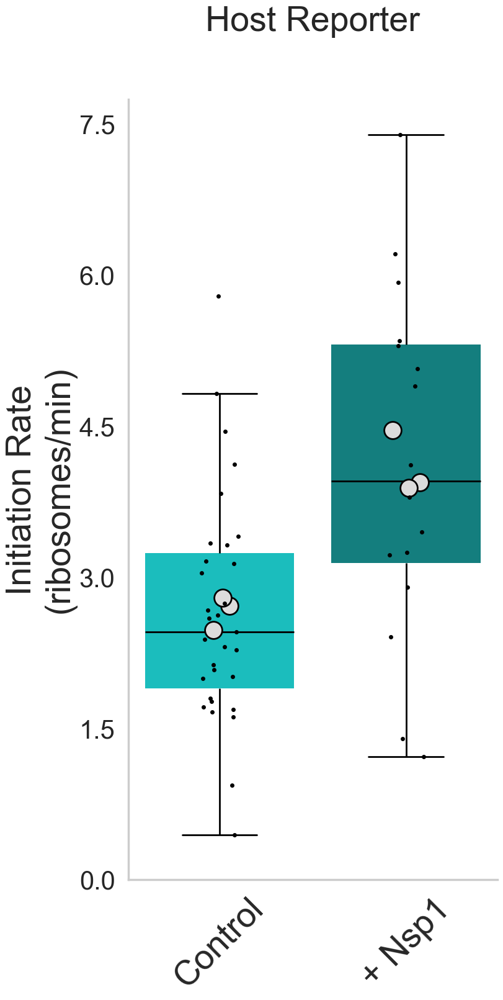

C:\Users\AdamC\AppData\Local\Temp\ipykernel_8044\3720551322.py:805: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


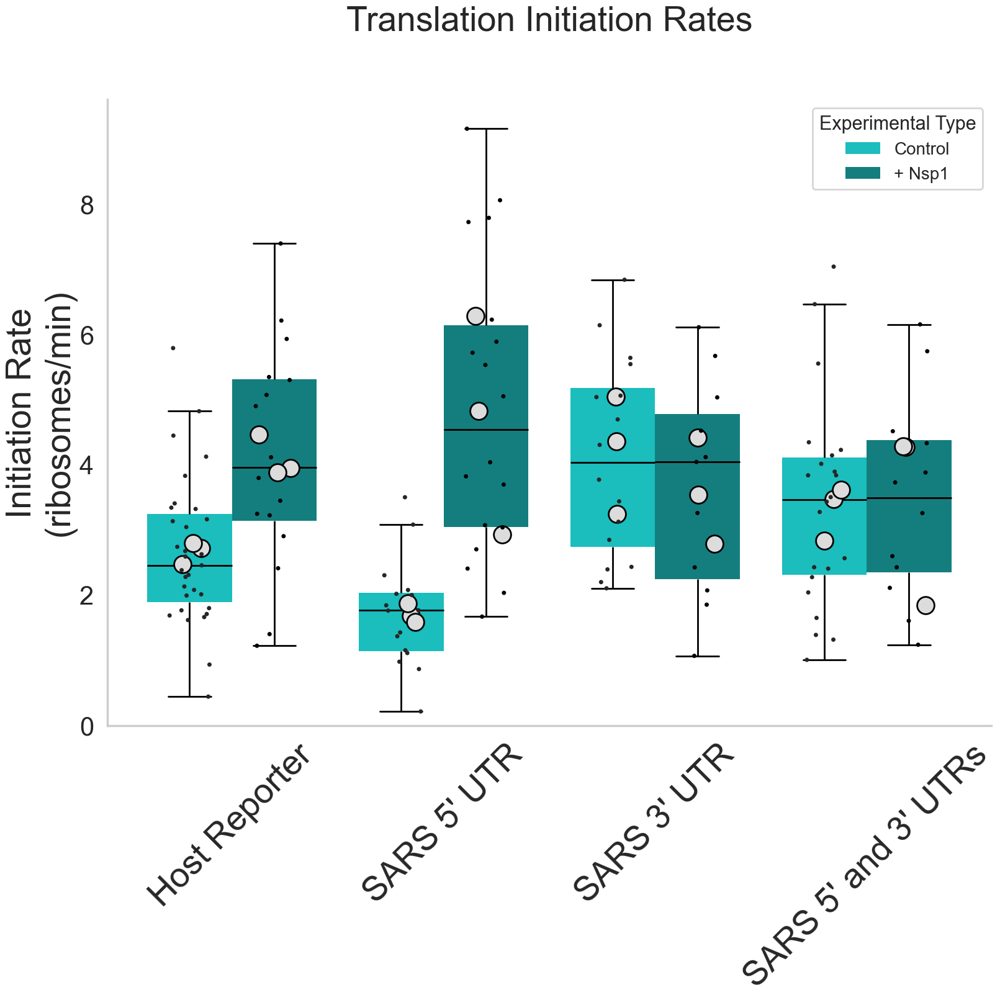


Initiation-rate plots generated successfully.
Individual points and replicate means are derived from the external brightness experiment.
Condition-level elongation rates are derived from the independent HT experiment.


In [72]:
# CELL PURPOSE:
# Plot initiation rates calculated by combining:
#
#   - PER-CELL ribosome occupancy from the independent
#     external brightness experiment
#
#   - CONDITION-MEAN elongation rates from the HT experiment
#
# Individual black points = individual brightness-experiment cells
# Large open circles      = brightness-experiment biological-replicate means
#
# NOTE:
# The visual spread in this superplot reflects the brightness /
# occupancy dataset. Elongation-rate uncertainty is incorporated
# separately in the propagated SEM stored in:
#
#     current_initiation_summary[
#         "sem_initiation_rate_propagated_per_min"
#     ]


import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from matplotlib.ticker import MaxNLocator


# ============================================================
# Plot formatting
# ============================================================

sns.set(
    font_scale=1.9
)

sns.set_style(
    "whitegrid",
    {
        "grid.linestyle": "",
    },
)

sns.set_context(
    "poster"
)


# ============================================================
# 1. Prepare NEW initiation-rate dataset
# ============================================================

INITIATION_RATE_COLUMN = (
    "initiation_rate_ribosomes_per_min"
)


# current_initiation_plot_data contains ONE ROW PER CELL from
# the external brightness experiment.
#
# Each row contains:
#
#     cell-specific ribosome occupancy
#
#                 ×
#
#     condition-mean elongation rate
#
#                 /
#
#              ORF length
#
# Therefore no cell matching or cell collapsing is needed here.

initiation_plot_data = (
    current_initiation_plot_data
    .copy()
)


# ============================================================
# 2. Confirm required columns
# ============================================================

required_plot_columns = [
    "Experimental_Group",
    "Experimental_Type",
    "Replicate_Number",
    "fov",
    INITIATION_RATE_COLUMN,
]


missing_plot_columns = [
    column
    for column in required_plot_columns
    if column not in initiation_plot_data.columns
]


if missing_plot_columns:

    raise ValueError(
        "current_initiation_plot_data is missing required "
        f"plotting columns: {missing_plot_columns}"
    )


# ============================================================
# 3. Clean initiation-rate values
# ============================================================

initiation_plot_data[
    INITIATION_RATE_COLUMN
] = pd.to_numeric(
    initiation_plot_data[
        INITIATION_RATE_COLUMN
    ],
    errors="coerce",
)


initiation_plot_data[
    "Replicate_Number"
] = pd.to_numeric(
    initiation_plot_data[
        "Replicate_Number"
    ],
    errors="coerce",
)


if (
    "kinetics_usable"
    in initiation_plot_data.columns
):

    initiation_plot_data = (
        initiation_plot_data.loc[
            initiation_plot_data[
                "kinetics_usable"
            ]
            .fillna(False)
        ]
        .copy()
    )


initiation_plot_data = (
    initiation_plot_data.loc[
        np.isfinite(
            initiation_plot_data[
                INITIATION_RATE_COLUMN
            ]
        )
        &
        (
            initiation_plot_data[
                INITIATION_RATE_COLUMN
            ]
            > 0
        )
        &
        initiation_plot_data[
            "Replicate_Number"
        ].notna()
    ]
    .copy()
)


if initiation_plot_data.empty:

    raise ValueError(
        "No usable initiation-rate measurements "
        "were available for plotting."
    )


# ============================================================
# 4. Confirm one value per external-brightness cell
# ============================================================

BRIGHTNESS_CELL_KEYS = [
    "Experimental_Group",
    "Experimental_Type",
    "Replicate_Number",
    "fov",
]


duplicate_cell_mask = (
    initiation_plot_data.duplicated(
        subset=BRIGHTNESS_CELL_KEYS,
        keep=False,
    )
)


if duplicate_cell_mask.any():

    print(
        "\nDuplicate external-brightness cells detected:"
    )

    display(
        initiation_plot_data.loc[
            duplicate_cell_mask,
            BRIGHTNESS_CELL_KEYS
            +
            [
                INITIATION_RATE_COLUMN
            ],
        ]
        .sort_values(
            BRIGHTNESS_CELL_KEYS
        )
    )

    raise RuntimeError(
        "More than one initiation-rate measurement exists "
        "for the same external-brightness cell."
    )


# ============================================================
# 5. Cell-level plotting dataframe
# ============================================================

# No collapse_to_one_value_per_cell() is required.
#
# The external brightness dataframe already contains one
# measurement per cell.

data = (
    initiation_plot_data
    .copy()
)


# Convenient unique cell label

data[
    "Cell_ID"
] = (
    "Rep"
    +
    data[
        "Replicate_Number"
    ]
    .astype(int)
    .astype(str)
    +
    "_FOV"
    +
    data[
        "fov"
    ]
    .astype(str)
)


# ============================================================
# 6. Calculate biological-replicate means
# ============================================================

# These are the REAL biological replicates from the
# external brightness experiment.

superplot = (
    calculate_grouped_average(
        data,
        INITIATION_RATE_COLUMN,
        [
            "Experimental_Group",
            "Experimental_Type",
            "Replicate_Number",
        ],
    )
)


# ============================================================
# 7. Ordering and labels
# ============================================================

type_order = [
    experimental_type

    for experimental_type
    in TYPE_ORDER

    if experimental_type
    in data[
        "Experimental_Type"
    ]
    .astype(str)
    .unique()
]


# Include unexpected types at the end rather than silently
# dropping them.

extra_types = [
    experimental_type

    for experimental_type
    in data[
        "Experimental_Type"
    ]
    .astype(str)
    .unique()

    if experimental_type
    not in type_order
]


type_order = (
    type_order
    +
    sorted(
        extra_types
    )
)


type_label_map = {

    "No Nsp1":
        "Control",

    "Nsp1":
        "+ Nsp1",

    "NoCTD Nsp1":
        "+ Nsp1ΔC",
}


# ============================================================
# 8. Group names
# ============================================================

# SARS_CTRL was mapped to "Control" when the initiation-rate
# dataset was created.

INITIATION_CONTROL_GROUP = (
    "Control"
)


# Build group ordering from the established GROUP_ORDER where
# possible, but accommodate the new "Control" name.

available_groups = (
    data[
        "Experimental_Group"
    ]
    .astype(str)
    .unique()
    .tolist()
)


group_order = []


for group in GROUP_ORDER:

    # Old Host Reporter name may have been SARS_CTRL.
    # In this dataset that condition is now called Control.

    mapped_group = (
        "Control"
        if str(group) == "SARS_CTRL"
        else str(group)
    )

    if (
        mapped_group in available_groups
        and mapped_group not in group_order
    ):

        group_order.append(
            mapped_group
        )


# Include anything not already represented in GROUP_ORDER.

for group in available_groups:

    if group not in group_order:

        group_order.append(
            group
        )


# ============================================================
# 9. Group display labels
# ============================================================

def get_initiation_group_label(
    group
):

    if str(group) == "Control":

        # Prefer the established SARS_CTRL display label.
        return GROUP_LABELS.get(
            "SARS_CTRL",
            "Host Reporter",
        )

    return GROUP_LABELS.get(
        group,
        group,
    )


# ============================================================
# 10. Audit data before plotting
# ============================================================

print(
    "\nInitiation-rate plotting data"
)

print(
    "============================="
)


plot_data_audit = (
    data
    .groupby(
        [
            "Experimental_Group",
            "Experimental_Type",
        ],
        dropna=False,
    )
    .agg(

        n_cells=(
            INITIATION_RATE_COLUMN,
            "size",
        ),

        n_replicates=(
            "Replicate_Number",
            "nunique",
        ),

        mean_initiation_rate_ribosomes_per_min=(
            INITIATION_RATE_COLUMN,
            "mean",
        ),
    )
    .reset_index()
)


display(
    plot_data_audit.sort_values(
        [
            "Experimental_Group",
            "Experimental_Type",
        ]
    )
)


# ============================================================
# PLOT 1: Host Reporter
# ============================================================

control_data = (
    data.loc[
        data[
            "Experimental_Group"
        ]
        .astype(str)
        .eq(
            INITIATION_CONTROL_GROUP
        )
    ]
    .copy()
)


control_superplot = (
    superplot.loc[
        superplot[
            "Experimental_Group"
        ]
        .astype(str)
        .eq(
            INITIATION_CONTROL_GROUP
        )
    ]
    .copy()
)


if control_data.empty:

    raise ValueError(
        "No Host Reporter initiation-rate data were found "
        f"under Experimental_Group = "
        f"'{INITIATION_CONTROL_GROUP}'."
    )


# Only show types actually present in the Host Reporter.

order = [
    experimental_type

    for experimental_type
    in type_order

    if experimental_type
    in control_data[
        "Experimental_Type"
    ]
    .astype(str)
    .unique()
]


new_labels = [
    type_label_map.get(
        experimental_type,
        experimental_type,
    )

    for experimental_type
    in order
]


fig, ax = plt.subplots(
    figsize=(
        8,
        16,
    ),
    constrained_layout=True,
)


sns.despine(
    fig=fig,
    top=True,
    right=True,
    left=False,
    bottom=False,
)


# ------------------------------------------------------------
# Cell distribution
# ------------------------------------------------------------

sns.boxplot(
    x="Experimental_Type",
    y=INITIATION_RATE_COLUMN,

    data=control_data,

    order=order,

    ax=ax,

    palette=blue_palette,

    boxprops=dict(
        linewidth=0
    ),

    whiskerprops=dict(
        color="black",
        linewidth=2,
    ),

    capprops=dict(
        color="black",
        linewidth=2,
    ),

    medianprops=dict(
        color="black",
        linewidth=2,
    ),

    showfliers=False,
)


# ------------------------------------------------------------
# Individual brightness-experiment cells
# ------------------------------------------------------------

sns.stripplot(
    x="Experimental_Type",
    y=INITIATION_RATE_COLUMN,

    data=control_data,

    order=order,

    color="black",

    alpha=1,

    size=5,

    jitter=True,

    dodge=False,

    ax=ax,

    zorder=9,
)


# ------------------------------------------------------------
# Brightness biological-replicate means
# ------------------------------------------------------------

plot_open_circles_with_hue(
    ax,
    control_superplot,

    order=order,

    x="Experimental_Type",

    y=(
        "Super "
        "initiation_rate_ribosomes_per_min"
    ),

    hue="Experimental_Group",

    jitter=True,

    jitter_strength=0.08,

    random_state=100,
)


# ------------------------------------------------------------
# Host Reporter formatting
# ------------------------------------------------------------

ax.set_title(
    get_initiation_group_label(
        INITIATION_CONTROL_GROUP
    ),
    fontsize=40,
    pad=80,
)


ax.set_ylabel(
    "Initiation Rate\n(ribosomes/min)",
    fontsize=40,
)


ax.set_xlabel(
    ""
)


ax.set_ylim(
    bottom=0
)


ax.tick_params(
    axis="both",
    which="major",
    labelsize=30,
)


ax.set_xticklabels(
    new_labels,
    fontsize=40,
    rotation=45,
)


ax.yaxis.set_major_locator(
    MaxNLocator(
        nbins=6
    )
)


if ax.get_legend() is not None:

    ax.get_legend().remove()


save_figure(
    fig,
    "HT_External_Brightness_Initiation_Rate_Host_Reporter",
)


plt.show()


control_figure = fig
control_axis = ax


# ============================================================
# PLOT 2: All reporters
# ============================================================

new_group_labels = [
    get_initiation_group_label(
        group
    )

    for group
    in group_order
]


fig_all, ax_all = plt.subplots(
    figsize=(
        16,
        16,
    ),
    constrained_layout=True,
)


sns.despine(
    fig=fig_all,
    top=True,
    right=True,
    left=False,
    bottom=False,
)


# ------------------------------------------------------------
# Cell distribution
# ------------------------------------------------------------

sns.boxplot(
    x="Experimental_Group",
    y=INITIATION_RATE_COLUMN,

    hue="Experimental_Type",

    data=data,

    order=group_order,
    hue_order=type_order,

    ax=ax_all,

    palette=blue_palette,

    boxprops=dict(
        linewidth=0
    ),

    whiskerprops=dict(
        color="black",
        linewidth=2,
    ),

    capprops=dict(
        color="black",
        linewidth=2,
    ),

    medianprops=dict(
        color="black",
        linewidth=2,
    ),

    showfliers=False,
)


# ------------------------------------------------------------
# Individual brightness-experiment cells
# ------------------------------------------------------------

sns.stripplot(
    x="Experimental_Group",
    y=INITIATION_RATE_COLUMN,

    hue="Experimental_Type",

    data=data,

    order=group_order,
    hue_order=type_order,

    color="black",

    alpha=1,

    size=5,

    jitter=0.2,

    dodge=True,

    ax=ax_all,

    zorder=9,
)


# ------------------------------------------------------------
# Brightness biological-replicate means
# ------------------------------------------------------------

plot_open_circles_with_hue(
    ax_all,
    superplot,

    order=group_order,

    x="Experimental_Group",

    y=(
        "Super "
        "initiation_rate_ribosomes_per_min"
    ),

    hue="Experimental_Type",

    hue_order=type_order,

    jitter=True,

    jitter_strength=0.08,

    random_state=100,
)


# ------------------------------------------------------------
# All-reporter formatting
# ------------------------------------------------------------

ax_all.set_title(
    "Translation Initiation Rates",
    fontsize=40,
    pad=80,
)


ax_all.set_ylabel(
    "Initiation Rate\n(ribosomes/min)",
    fontsize=40,
)


ax_all.set_xlabel(
    ""
)


ax_all.set_ylim(
    bottom=0
)


ax_all.tick_params(
    axis="both",
    which="major",
    labelsize=30,
)


ax_all.set_xticklabels(
    new_group_labels,
    fontsize=40,
    rotation=45,
)


ax_all.yaxis.set_major_locator(
    MaxNLocator(
        nbins=6
    )
)


# ============================================================
# Clean legend
# ============================================================

handles, labels = (
    ax_all.get_legend_handles_labels()
)


legend_lookup = {}


for handle, label in zip(
    handles,
    labels,
):

    if (
        label in type_order
        and label not in legend_lookup
    ):

        legend_lookup[
            label
        ] = handle


if legend_lookup:

    ax_all.legend(

        [
            legend_lookup[
                label
            ]

            for label
            in type_order

            if label
            in legend_lookup
        ],

        [
            type_label_map.get(
                label,
                label,
            )

            for label
            in type_order

            if label
            in legend_lookup
        ],

        title="Experimental Type",

        fontsize=20,

        title_fontsize=22,

        loc="upper right",
    )


elif ax_all.get_legend() is not None:

    ax_all.get_legend().remove()


save_figure(
    fig_all,
    "HT_External_Brightness_Initiation_Rate_All_Reporters",
)


plt.show()


all_figure = fig_all
all_axis = ax_all


# ============================================================
# Save plotting outputs
# ============================================================

replicate_data = (
    superplot
)


initiation_rate_plot_results = {

    "control_figure":
        control_figure,

    "control_axis":
        control_axis,

    "all_figure":
        all_figure,

    "all_axis":
        all_axis,

    "cell_data":
        data,

    "replicate_data":
        replicate_data,

    "condition_summary":
        current_initiation_summary,
}


print(
    "\nInitiation-rate plots generated successfully."
)

print(
    "Individual points and replicate means are derived from "
    "the external brightness experiment."
)

print(
    "Condition-level elongation rates are derived from the "
    "independent HT experiment."
)


Initiation-rate plotting data


,Experimental_Group,Experimental_Type,n_cells,n_replicates,mean_initiation_rate_ribosomes_per_min
0,Control,No Nsp1,31,3,2.654603
1,Control,Nsp1,16,3,4.119115
2,SARS_3'UTR,No Nsp1,16,3,4.097150
3,SARS_3'UTR,Nsp1,11,3,3.651064
4,SARS_5'UTR,No Nsp1,16,3,1.716278
5,SARS_5'UTR,Nsp1,18,3,4.866543
6,SARS_5'_3'UTR,No Nsp1,22,3,3.391798
7,SARS_5'_3'UTR,Nsp1,12,3,3.464373


C:\Users\AdamC\AppData\Local\Temp\ipykernel_8044\1079768103.py:876: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


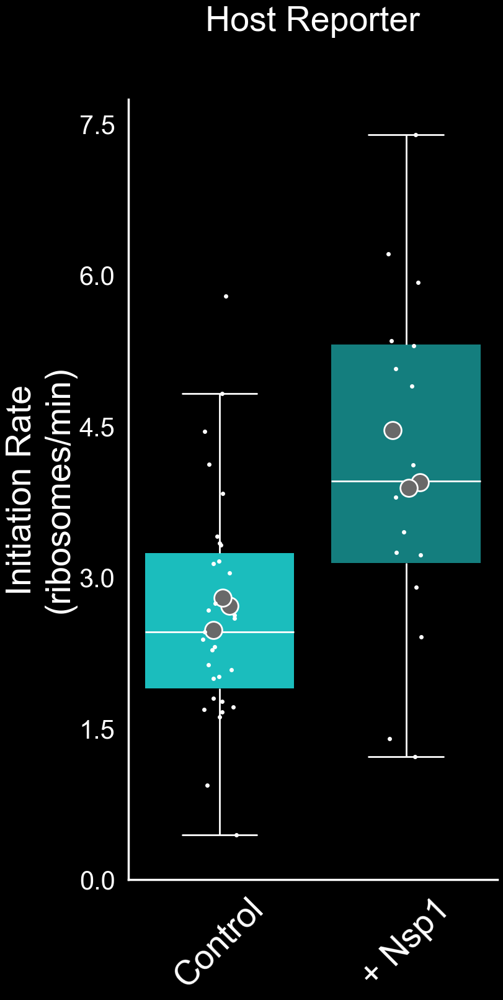

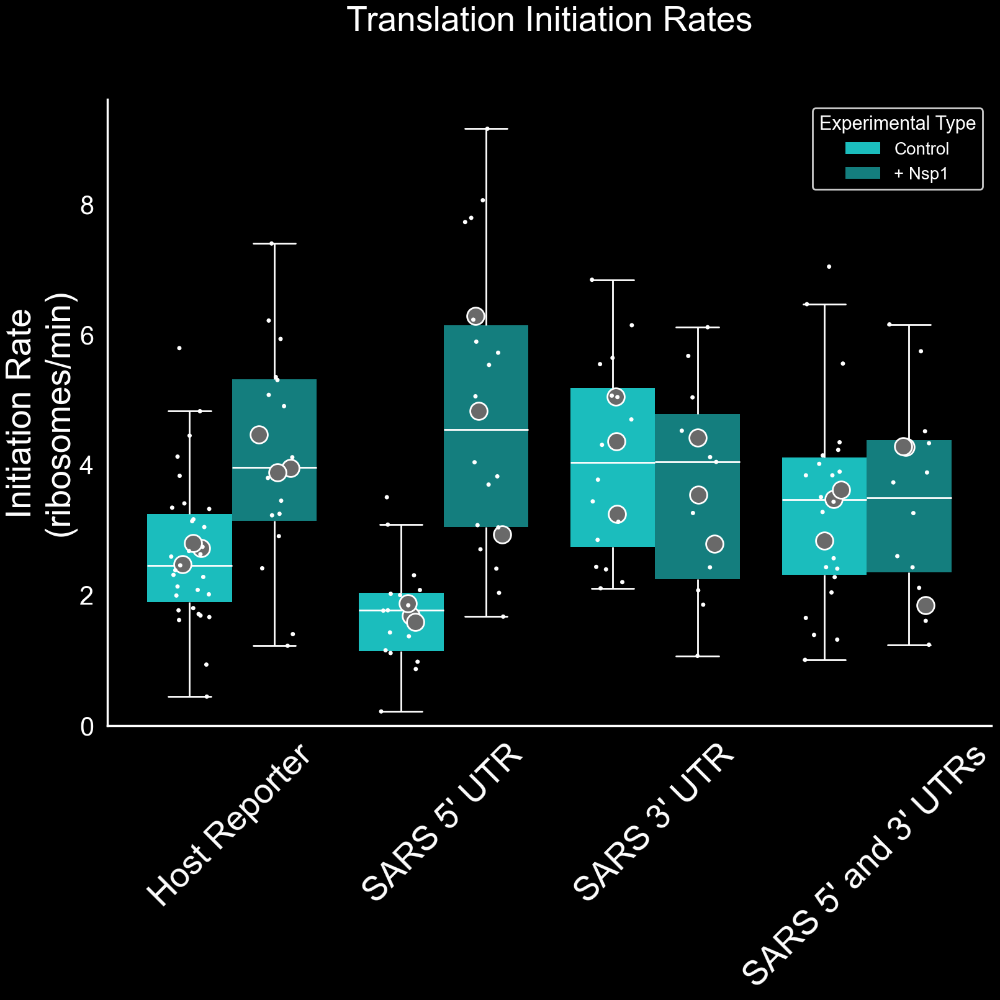


Initiation-rate plots generated successfully.
Individual points and replicate means are derived from the external brightness experiment.
Condition-level elongation rates are derived from the independent HT experiment.


In [76]:
# CELL PURPOSE:
# Plot initiation rates calculated by combining:
#
#   - PER-CELL ribosome occupancy from the independent
#     external brightness experiment
#
#   - CONDITION-MEAN elongation rates from the HT experiment
#
# Individual white points = individual brightness-experiment cells
# Large open circles       = brightness-experiment biological-replicate means
#
# BLACK-BACKGROUND VERSION


import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

from matplotlib.ticker import MaxNLocator
from matplotlib.colors import to_rgba


# ============================================================
# BLACK-BACKGROUND FORMATTING
# ============================================================

mpl.rcParams.update(
    {
        "figure.facecolor": "black",
        "axes.facecolor": "black",
        "savefig.facecolor": "black",
        "text.color": "white",
        "axes.labelcolor": "white",
        "axes.edgecolor": "white",
        "xtick.color": "white",
        "ytick.color": "white",
    }
)


def _is_dark_color(
    color,
    threshold=0.28,
):
    """
    Identify black / very-dark plot elements that need to
    become white on a black background.
    """

    try:

        r, g, b, a = to_rgba(
            color
        )

    except Exception:

        return False

    return (
        a > 0.05
        and
        max(
            r,
            g,
            b,
        ) < threshold
    )


def finalize_black_axes(
    ax
):
    """
    Convert an existing Matplotlib axis for presentation
    on a black background without altering the data colors.
    """

    ax.set_facecolor(
        "black"
    )


    # --------------------------------------------------------
    # Text
    # --------------------------------------------------------

    ax.title.set_color(
        "white"
    )

    ax.xaxis.label.set_color(
        "white"
    )

    ax.yaxis.label.set_color(
        "white"
    )


    ax.tick_params(
        axis="both",
        which="both",
        colors="white",
    )


    for label in (
        ax.get_xticklabels()
        +
        ax.get_yticklabels()
    ):

        label.set_color(
            "white"
        )


    # --------------------------------------------------------
    # Axis spines
    # --------------------------------------------------------

    for spine in ax.spines.values():

        if spine.get_visible():

            spine.set_color(
                "white"
            )


    # --------------------------------------------------------
    # Line2D objects
    #
    # Includes:
    #   whiskers
    #   caps
    #   medians
    #   line-based marker outlines
    # --------------------------------------------------------

    for line in ax.lines:

        try:

            if _is_dark_color(
                line.get_color()
            ):

                line.set_color(
                    "white"
                )

        except Exception:

            pass


        try:

            if _is_dark_color(
                line.get_markeredgecolor()
            ):

                line.set_markeredgecolor(
                    "white"
                )

        except Exception:

            pass


    # --------------------------------------------------------
    # Patch outlines
    # --------------------------------------------------------

    for patch in ax.patches:

        try:

            if _is_dark_color(
                patch.get_edgecolor()
            ):

                patch.set_edgecolor(
                    "white"
                )

        except Exception:

            pass


    # --------------------------------------------------------
    # Collections
    #
    # Important for scatter points / open replicate circles.
    # --------------------------------------------------------

    for collection in ax.collections:

        try:

            edgecolors = (
                collection.get_edgecolors()
            )


            if (
                edgecolors is not None
                and
                len(edgecolors) > 0
            ):

                new_edges = (
                    edgecolors.copy()
                )


                for i, rgba in enumerate(
                    new_edges
                ):

                    if (
                        len(rgba) >= 4
                        and
                        rgba[3] > 0.05
                        and
                        max(
                            rgba[:3]
                        ) < 0.28
                    ):

                        new_edges[
                            i,
                            :3
                        ] = 1.0


                collection.set_edgecolors(
                    new_edges
                )

        except Exception:

            pass


    # --------------------------------------------------------
    # Annotations
    # --------------------------------------------------------

    for text in ax.texts:

        try:

            if _is_dark_color(
                text.get_color()
            ):

                text.set_color(
                    "white"
                )

        except Exception:

            pass


    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------

    legend = (
        ax.get_legend()
    )


    if legend is not None:

        frame = (
            legend.get_frame()
        )

        frame.set_facecolor(
            "black"
        )

        frame.set_edgecolor(
            "white"
        )


        for text in legend.get_texts():

            text.set_color(
                "white"
            )


        if (
            legend.get_title()
            is not None
        ):

            legend.get_title().set_color(
                "white"
            )


    return ax


def finalize_black_figure(
    fig
):
    """
    Convert complete figure to black-background presentation
    formatting.
    """

    fig.patch.set_facecolor(
        "black"
    )


    for axis in fig.axes:

        finalize_black_axes(
            axis
        )


    return fig


# ============================================================
# Plot formatting
# ============================================================

sns.set(
    font_scale=1.9
)

sns.set_context(
    "poster"
)

# Do not use Seaborn's white background.
sns.set_style(
    "dark",
    {
        "axes.facecolor":
            "black",

        "figure.facecolor":
            "black",

        "axes.edgecolor":
            "white",

        "axes.labelcolor":
            "white",

        "xtick.color":
            "white",

        "ytick.color":
            "white",

        "text.color":
            "white",

        "grid.linestyle":
            "",
    },
)


# ============================================================
# 1. Prepare NEW initiation-rate dataset
# ============================================================

INITIATION_RATE_COLUMN = (
    "initiation_rate_ribosomes_per_min"
)


initiation_plot_data = (
    current_initiation_plot_data
    .copy()
)


# ============================================================
# 2. Confirm required columns
# ============================================================

required_plot_columns = [
    "Experimental_Group",
    "Experimental_Type",
    "Replicate_Number",
    "fov",
    INITIATION_RATE_COLUMN,
]


missing_plot_columns = [
    column
    for column in required_plot_columns
    if column not in initiation_plot_data.columns
]


if missing_plot_columns:

    raise ValueError(
        "current_initiation_plot_data is missing required "
        f"plotting columns: {missing_plot_columns}"
    )


# ============================================================
# 3. Clean initiation-rate values
# ============================================================

initiation_plot_data[
    INITIATION_RATE_COLUMN
] = pd.to_numeric(
    initiation_plot_data[
        INITIATION_RATE_COLUMN
    ],
    errors="coerce",
)


initiation_plot_data[
    "Replicate_Number"
] = pd.to_numeric(
    initiation_plot_data[
        "Replicate_Number"
    ],
    errors="coerce",
)


if (
    "kinetics_usable"
    in initiation_plot_data.columns
):

    initiation_plot_data = (
        initiation_plot_data.loc[
            initiation_plot_data[
                "kinetics_usable"
            ]
            .fillna(False)
        ]
        .copy()
    )


initiation_plot_data = (
    initiation_plot_data.loc[
        np.isfinite(
            initiation_plot_data[
                INITIATION_RATE_COLUMN
            ]
        )
        &
        (
            initiation_plot_data[
                INITIATION_RATE_COLUMN
            ]
            > 0
        )
        &
        initiation_plot_data[
            "Replicate_Number"
        ].notna()
    ]
    .copy()
)


if initiation_plot_data.empty:

    raise ValueError(
        "No usable initiation-rate measurements "
        "were available for plotting."
    )


# ============================================================
# 4. Confirm one value per external-brightness cell
# ============================================================

BRIGHTNESS_CELL_KEYS = [
    "Experimental_Group",
    "Experimental_Type",
    "Replicate_Number",
    "fov",
]


duplicate_cell_mask = (
    initiation_plot_data.duplicated(
        subset=BRIGHTNESS_CELL_KEYS,
        keep=False,
    )
)


if duplicate_cell_mask.any():

    print(
        "\nDuplicate external-brightness cells detected:"
    )

    display(
        initiation_plot_data.loc[
            duplicate_cell_mask,
            BRIGHTNESS_CELL_KEYS
            +
            [
                INITIATION_RATE_COLUMN
            ],
        ]
        .sort_values(
            BRIGHTNESS_CELL_KEYS
        )
    )

    raise RuntimeError(
        "More than one initiation-rate measurement exists "
        "for the same external-brightness cell."
    )


# ============================================================
# 5. Cell-level plotting dataframe
# ============================================================

data = (
    initiation_plot_data
    .copy()
)


data[
    "Cell_ID"
] = (
    "Rep"
    +
    data[
        "Replicate_Number"
    ]
    .astype(int)
    .astype(str)
    +
    "_FOV"
    +
    data[
        "fov"
    ]
    .astype(str)
)


# ============================================================
# 6. Calculate biological-replicate means
# ============================================================

superplot = (
    calculate_grouped_average(
        data,
        INITIATION_RATE_COLUMN,
        [
            "Experimental_Group",
            "Experimental_Type",
            "Replicate_Number",
        ],
    )
)


# ============================================================
# 7. Ordering and labels
# ============================================================

type_order = [
    experimental_type

    for experimental_type
    in TYPE_ORDER

    if experimental_type
    in data[
        "Experimental_Type"
    ]
    .astype(str)
    .unique()
]


extra_types = [
    experimental_type

    for experimental_type
    in data[
        "Experimental_Type"
    ]
    .astype(str)
    .unique()

    if experimental_type
    not in type_order
]


type_order = (
    type_order
    +
    sorted(
        extra_types
    )
)


type_label_map = {

    "No Nsp1":
        "Control",

    "Nsp1":
        "+ Nsp1",

    "NoCTD Nsp1":
        "+ Nsp1ΔC",
}


# ------------------------------------------------------------
# White palette used specifically for stripplot points.
#
# This is important when hue is present because
# color="white" does NOT reliably override hue colors.
# ------------------------------------------------------------

white_strip_palette = {

    experimental_type:
        "white"

    for experimental_type
    in type_order
}


# ============================================================
# 8. Group names
# ============================================================

INITIATION_CONTROL_GROUP = (
    "Control"
)


available_groups = (
    data[
        "Experimental_Group"
    ]
    .astype(str)
    .unique()
    .tolist()
)


group_order = []


for group in GROUP_ORDER:

    mapped_group = (
        "Control"
        if str(group) == "SARS_CTRL"
        else str(group)
    )

    if (
        mapped_group in available_groups
        and
        mapped_group not in group_order
    ):

        group_order.append(
            mapped_group
        )


for group in available_groups:

    if group not in group_order:

        group_order.append(
            group
        )


# ============================================================
# 9. Group display labels
# ============================================================

def get_initiation_group_label(
    group
):

    if str(group) == "Control":

        return GROUP_LABELS.get(
            "SARS_CTRL",
            "Host Reporter",
        )

    return GROUP_LABELS.get(
        group,
        group,
    )


# ============================================================
# 10. Audit data before plotting
# ============================================================

print(
    "\nInitiation-rate plotting data"
)

print(
    "============================="
)


plot_data_audit = (
    data
    .groupby(
        [
            "Experimental_Group",
            "Experimental_Type",
        ],
        dropna=False,
    )
    .agg(

        n_cells=(
            INITIATION_RATE_COLUMN,
            "size",
        ),

        n_replicates=(
            "Replicate_Number",
            "nunique",
        ),

        mean_initiation_rate_ribosomes_per_min=(
            INITIATION_RATE_COLUMN,
            "mean",
        ),
    )
    .reset_index()
)


display(
    plot_data_audit.sort_values(
        [
            "Experimental_Group",
            "Experimental_Type",
        ]
    )
)


# ============================================================
# PLOT 1: Host Reporter
# ============================================================

control_data = (
    data.loc[
        data[
            "Experimental_Group"
        ]
        .astype(str)
        .eq(
            INITIATION_CONTROL_GROUP
        )
    ]
    .copy()
)


control_superplot = (
    superplot.loc[
        superplot[
            "Experimental_Group"
        ]
        .astype(str)
        .eq(
            INITIATION_CONTROL_GROUP
        )
    ]
    .copy()
)


if control_data.empty:

    raise ValueError(
        "No Host Reporter initiation-rate data were found "
        f"under Experimental_Group = "
        f"'{INITIATION_CONTROL_GROUP}'."
    )


order = [
    experimental_type

    for experimental_type
    in type_order

    if experimental_type
    in control_data[
        "Experimental_Type"
    ]
    .astype(str)
    .unique()
]


new_labels = [
    type_label_map.get(
        experimental_type,
        experimental_type,
    )

    for experimental_type
    in order
]


fig, ax = plt.subplots(
    figsize=(
        8,
        16,
    ),
    constrained_layout=True,
)


sns.despine(
    fig=fig,
    top=True,
    right=True,
    left=False,
    bottom=False,
)


# ------------------------------------------------------------
# Cell distribution
# ------------------------------------------------------------

sns.boxplot(
    x="Experimental_Type",
    y=INITIATION_RATE_COLUMN,

    data=control_data,

    order=order,

    ax=ax,

    palette=blue_palette,

    boxprops=dict(
        linewidth=0
    ),

    whiskerprops=dict(
        color="white",
        linewidth=2,
    ),

    capprops=dict(
        color="white",
        linewidth=2,
    ),

    medianprops=dict(
        color="white",
        linewidth=2,
    ),

    showfliers=False,
)


# ------------------------------------------------------------
# Individual brightness-experiment cells
# ------------------------------------------------------------

sns.stripplot(
    x="Experimental_Type",
    y=INITIATION_RATE_COLUMN,

    data=control_data,

    order=order,

    color="white",

    alpha=1,

    size=5,

    jitter=True,

    dodge=False,

    ax=ax,

    zorder=9,
)


# ------------------------------------------------------------
# Brightness biological-replicate means
# ------------------------------------------------------------

plot_open_circles_with_hue(
    ax,
    control_superplot,

    order=order,

    x="Experimental_Type",

    y=(
        "Super "
        "initiation_rate_ribosomes_per_min"
    ),

    hue="Experimental_Group",

    jitter=True,

    jitter_strength=0.08,

    random_state=100,
)


# ------------------------------------------------------------
# Host Reporter formatting
# ------------------------------------------------------------

ax.set_title(
    get_initiation_group_label(
        INITIATION_CONTROL_GROUP
    ),
    fontsize=40,
    pad=80,
)


ax.set_ylabel(
    "Initiation Rate\n(ribosomes/min)",
    fontsize=40,
)


ax.set_xlabel(
    ""
)


ax.set_ylim(
    bottom=0
)


ax.tick_params(
    axis="both",
    which="major",
    labelsize=30,
    colors="white",
)


ax.set_xticklabels(
    new_labels,
    fontsize=40,
    rotation=45,
    color="white",
)


ax.yaxis.set_major_locator(
    MaxNLocator(
        nbins=6
    )
)


if ax.get_legend() is not None:

    ax.get_legend().remove()


# ------------------------------------------------------------
# IMPORTANT:
# Convert BEFORE saving and BEFORE displaying.
# ------------------------------------------------------------

finalize_black_figure(
    fig
)


save_figure(
    fig,
    "HT_External_Brightness_Initiation_Rate_Host_Reporter",
)


plt.show()


control_figure = fig
control_axis = ax


# ============================================================
# PLOT 2: All reporters
# ============================================================

new_group_labels = [
    get_initiation_group_label(
        group
    )

    for group
    in group_order
]


fig_all, ax_all = plt.subplots(
    figsize=(
        16,
        16,
    ),
    constrained_layout=True,
)


sns.despine(
    fig=fig_all,
    top=True,
    right=True,
    left=False,
    bottom=False,
)


# ------------------------------------------------------------
# Cell distribution
# ------------------------------------------------------------

sns.boxplot(
    x="Experimental_Group",
    y=INITIATION_RATE_COLUMN,

    hue="Experimental_Type",

    data=data,

    order=group_order,
    hue_order=type_order,

    ax=ax_all,

    palette=blue_palette,

    boxprops=dict(
        linewidth=0
    ),

    whiskerprops=dict(
        color="white",
        linewidth=2,
    ),

    capprops=dict(
        color="white",
        linewidth=2,
    ),

    medianprops=dict(
        color="white",
        linewidth=2,
    ),

    showfliers=False,
)


# ------------------------------------------------------------
# Individual brightness-experiment cells
# ------------------------------------------------------------

sns.stripplot(
    x="Experimental_Group",
    y=INITIATION_RATE_COLUMN,

    hue="Experimental_Type",

    data=data,

    order=group_order,
    hue_order=type_order,

    # Explicitly force EVERY hue category to white.
    palette=white_strip_palette,

    alpha=1,

    size=5,

    jitter=0.2,

    dodge=True,

    ax=ax_all,

    zorder=9,
)


# ------------------------------------------------------------
# Brightness biological-replicate means
# ------------------------------------------------------------

plot_open_circles_with_hue(
    ax_all,
    superplot,

    order=group_order,

    x="Experimental_Group",

    y=(
        "Super "
        "initiation_rate_ribosomes_per_min"
    ),

    hue="Experimental_Type",

    hue_order=type_order,

    jitter=True,

    jitter_strength=0.08,

    random_state=100,
)


# ------------------------------------------------------------
# All-reporter formatting
# ------------------------------------------------------------

ax_all.set_title(
    "Translation Initiation Rates",
    fontsize=40,
    pad=80,
)


ax_all.set_ylabel(
    "Initiation Rate\n(ribosomes/min)",
    fontsize=40,
)


ax_all.set_xlabel(
    ""
)


ax_all.set_ylim(
    bottom=0
)


ax_all.tick_params(
    axis="both",
    which="major",
    labelsize=30,
    colors="white",
)


ax_all.set_xticklabels(
    new_group_labels,
    fontsize=40,
    rotation=45,
    color="white",
)


ax_all.yaxis.set_major_locator(
    MaxNLocator(
        nbins=6
    )
)


# ============================================================
# Clean legend
# ============================================================

handles, labels = (
    ax_all.get_legend_handles_labels()
)


legend_lookup = {}


for handle, label in zip(
    handles,
    labels,
):

    if (
        label in type_order
        and
        label not in legend_lookup
    ):

        legend_lookup[
            label
        ] = handle


if legend_lookup:

    legend = ax_all.legend(

        [
            legend_lookup[
                label
            ]

            for label
            in type_order

            if label
            in legend_lookup
        ],

        [
            type_label_map.get(
                label,
                label,
            )

            for label
            in type_order

            if label
            in legend_lookup
        ],

        title="Experimental Type",

        fontsize=20,

        title_fontsize=22,

        loc="upper right",

        facecolor="black",

        edgecolor="white",

        labelcolor="white",
    )


elif ax_all.get_legend() is not None:

    ax_all.get_legend().remove()


# ------------------------------------------------------------
# IMPORTANT:
# Convert BEFORE saving and BEFORE displaying.
# ------------------------------------------------------------

finalize_black_figure(
    fig_all
)


save_figure(
    fig_all,
    "HT_External_Brightness_Initiation_Rate_All_Reporters",
)


plt.show()


all_figure = fig_all
all_axis = ax_all


# ============================================================
# Save plotting outputs
# ============================================================

replicate_data = (
    superplot
)


initiation_rate_plot_results = {

    "control_figure":
        control_figure,

    "control_axis":
        control_axis,

    "all_figure":
        all_figure,

    "all_axis":
        all_axis,

    "cell_data":
        data,

    "replicate_data":
        replicate_data,

    "condition_summary":
        current_initiation_summary,
}


print(
    "\nInitiation-rate plots generated successfully."
)

print(
    "Individual points and replicate means are derived from "
    "the external brightness experiment."
)

print(
    "Condition-level elongation rates are derived from the "
    "independent HT experiment."
)

### Statistics — Per-cell initiation rate

In [73]:
# Cell-level statistics corresponding exactly to the
# per-cell initiation-rate plot.
#
# Initiation rate is analyzed in ribosomes per minute:
#
#     initiation_rate_ribosomes_per_min
#
# IMPORTANT:
# The dataframe "data" is used here because it is the exact
# one-value-per-cell dataframe used in the plotting cell.
# Therefore, the statistical analysis and plotted cell
# population are identical.
#
# The statistical model is unchanged from the previous
# ribosomes-per-second analysis.
#
# Because:
#
#     ribosomes/min = ribosomes/sec * 60
#
# and the analysis uses a log transform:
#
#     log(rate_per_min)
#         = log(rate_per_sec) + log(60)
#
# multiplying every observation by the same constant only adds
# a constant offset after log transformation. Therefore,
# test statistics and p-values should be identical to the
# previous ribosomes-per-second analysis.


# ============================================================
# Validate the plotted dataset
# ============================================================

INITIATION_RATE_COLUMN = (
    "initiation_rate_ribosomes_per_min"
)


if "data" not in globals():

    raise NameError(
        "The dataframe 'data' does not exist. "
        "Run the per-cell initiation-rate plotting cell first."
    )


if INITIATION_RATE_COLUMN not in data.columns:

    raise KeyError(
        f"{INITIATION_RATE_COLUMN} is not present in the "
        "initiation-rate plotting dataframe."
    )


# ============================================================
# Prepare the exact dataset used in the plot
# ============================================================

initiation_rate_statistics_data = (
    data
    .copy()
)


initiation_rate_statistics_data[
    INITIATION_RATE_COLUMN
] = pd.to_numeric(
    initiation_rate_statistics_data[
        INITIATION_RATE_COLUMN
    ],
    errors="coerce",
)


initiation_rate_statistics_data = (
    initiation_rate_statistics_data.loc[
        np.isfinite(
            initiation_rate_statistics_data[
                INITIATION_RATE_COLUMN
            ]
        )
        &
        (
            initiation_rate_statistics_data[
                INITIATION_RATE_COLUMN
            ]
            > 0
        )
    ]
    .copy()
)


if initiation_rate_statistics_data.empty:

    raise ValueError(
        "No valid positive per-cell initiation-rate "
        "measurements were available for statistical analysis."
    )


# ============================================================
# Confirm the number of cells entering the analysis
# ============================================================

initiation_rate_statistics_cell_counts = (
    initiation_rate_statistics_data
    .groupby(
        [
            "Experimental_Group",
            "Experimental_Type",
            "Replicate_Number",
        ],
        dropna=False,
    )
    .size()
    .rename(
        "N_Cells"
    )
    .reset_index()
)


print(
    "\nCells included in initiation-rate statistics"
)

print(
    "============================================"
)


display(
    initiation_rate_statistics_cell_counts
    .sort_values(
        [
            "Experimental_Group",
            "Experimental_Type",
            "Replicate_Number",
        ]
    )
)


print(
    "\nTotal cells included: "
    f"{len(initiation_rate_statistics_data):,}"
)


# ============================================================
# Cell-level statistics
#
# Uses the same within-reporter mixed-model testing framework
# as the previous initiation-rate analysis.
# ============================================================

initiation_rate_cell_statistics = (
    run_within_reporter_cell_tests(

        dataframe=(
            initiation_rate_statistics_data
        ),

        value_column=(
            INITIATION_RATE_COLUMN
        ),

        analysis_name=(
            "Per-cell initiation rate "
            "(ribosomes/min)"
        ),

        group_order=(
            GROUP_ORDER
        ),

        transform="log",
    )
)


# ============================================================
# Save and display
# ============================================================

save_and_display_statistics(

    initiation_rate_cell_statistics,

    (
        "tethered_ht_per_cell_"
        "initiation_rate_ribosomes_per_min_"
        "mixed_models"
    ),

    (
        "Cell-level mixed models: "
        "initiation rate (ribosomes/min)"
    ),
)


Cells included in initiation-rate statistics


,Experimental_Group,Experimental_Type,Replicate_Number,N_Cells
0,Control,No Nsp1,1,11
1,Control,No Nsp1,2,9
2,Control,No Nsp1,3,11
3,Control,Nsp1,1,6
4,Control,Nsp1,2,5
5,Control,Nsp1,3,5
6,SARS_3'UTR,No Nsp1,1,5
7,SARS_3'UTR,No Nsp1,2,2
8,SARS_3'UTR,No Nsp1,3,9
9,SARS_3'UTR,Nsp1,1,4



Total cells included: 142

Cell-level mixed models: initiation rate (ribosomes/min)
--------------------------------------------------------
Observation level: one averaged value per cell
Replicate handling: random intercept; blocked-model fallback if needed
Significance stars: Holm-adjusted p-values
Host Reporter: n=31/16 cells; 3 matched replicates; mean=2.655/4.119; effect=1.542 (ratio (comparison/reference)); p=0.003553; Holm p=0.01066; *; Linear mixed-effects model
SARS 5' UTR: n=16/18 cells; 3 matched replicates; mean=1.716/4.867; effect=2.958 (ratio (comparison/reference)); p=4.004e-09; Holm p=1.601e-08; ****; Linear mixed-effects model
SARS 3' UTR: n=16/11 cells; 3 matched replicates; mean=4.097/3.651; effect=0.8871 (ratio (comparison/reference)); p=0.4813; Holm p=0.9625; ns; Linear mixed-effects model
SARS 5' and 3' UTRs: n=22/12 cells; 3 matched replicates; mean=3.392/3.464; effect=1.063 (ratio (comparison/reference)); p=0.7153; Holm p=0.9625; ns; Linear mixed-effects model


,analysis,value_column,comparison_column,reference_level,comparison_level,transform,effect_scale,n_reference_cells,n_comparison_cells,n_cells_total,n_reference_replicates,n_comparison_replicates,n_matched_replicates,reference_mean_raw,comparison_mean_raw,reference_median_raw,comparison_median_raw,raw_mean_difference_comparison_minus_reference,model_effect,model_effect_ci_low,model_effect_ci_high,standard_error,test_statistic,pvalue,model,replicate_adjustment,status,Experimental_Group,pvalue_holm,stars_raw,stars_holm,stars
0,Per-cell initiation rate (ribosomes/min),initiation_rate_ribosomes_per_min,Experimental_Type,No Nsp1,Nsp1,log,ratio (comparison/reference),31,16,47,3,3,3,2.654603,4.119115,2.455583,3.954779,1.464512,1.542382,1.152585,2.064007,0.148636,2.915369,3.552687e-03,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,Control,1.065806e-02,**,*,*
1,Per-cell initiation rate (ribosomes/min),initiation_rate_ribosomes_per_min,Experimental_Type,No Nsp1,Nsp1,log,ratio (comparison/reference),16,18,34,3,3,3,1.716278,4.866543,1.763451,4.542796,3.150265,2.958348,2.061312,4.245754,0.184334,5.884047,4.003548e-09,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,SARS_5'UTR,1.601419e-08,****,****,****
2,Per-cell initiation rate (ribosomes/min),initiation_rate_ribosomes_per_min,Experimental_Type,No Nsp1,Nsp1,log,ratio (comparison/reference),16,11,27,3,3,3,4.097150,3.651064,4.036785,4.042172,-0.446086,0.887075,0.635534,1.238174,0.170138,-0.704289,4.812531e-01,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,SARS_3'UTR,9.625062e-01,ns,ns,ns
3,Per-cell initiation rate (ribosomes/min),initiation_rate_ribosomes_per_min,Experimental_Type,No Nsp1,Nsp1,log,ratio (comparison/reference),22,12,34,3,3,3,3.391798,3.464373,3.466619,3.492294,0.072575,1.063208,0.764897,1.477861,0.168016,0.364793,7.152661e-01,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,SARS_5'_3'UTR,9.625062e-01,ns,ns,ns


### Plot — Per-cell ribosome density

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30524\4186176074.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


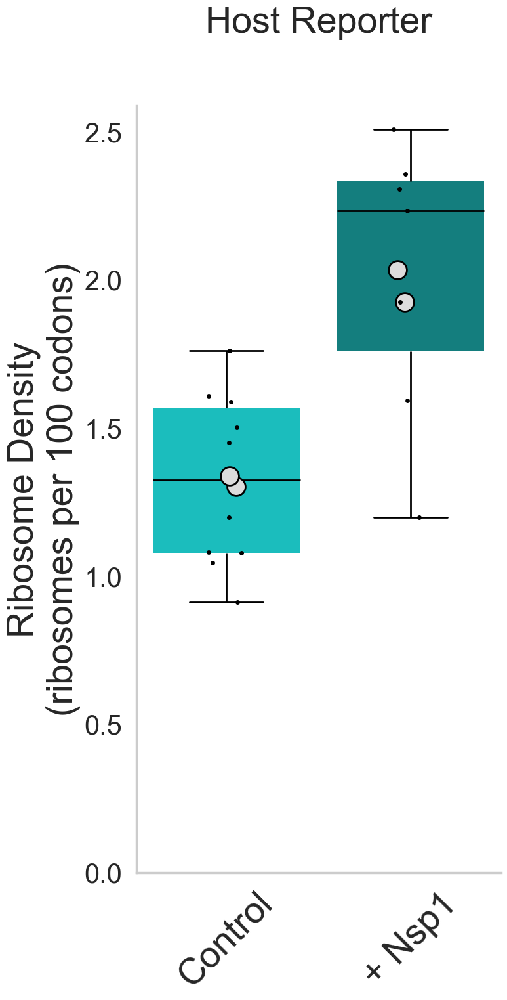

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30524\4186176074.py:179: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


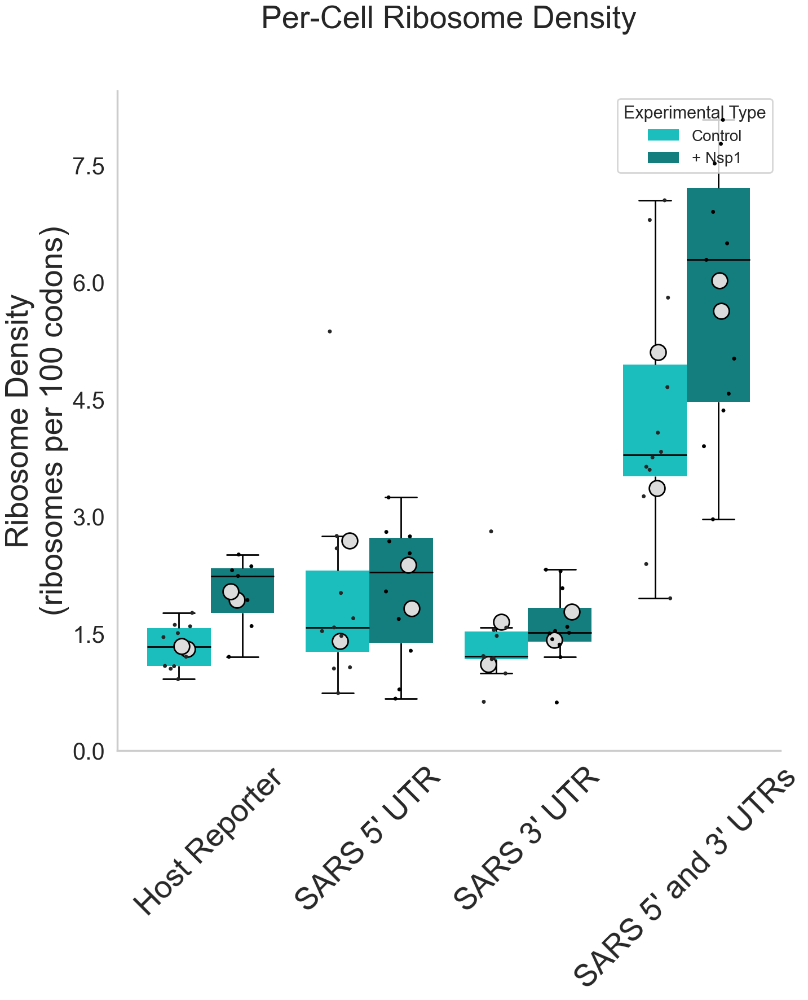

In [100]:
# CELL PURPOSE:
# Plot ribosome density calculated independently for each cell.
#
# The Host Reporter and all-reporter figures are written explicitly in this
# cell to match the customizable plotting pattern in crop_array_analysis(8).

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# ============================================================
# Prepare one value per cell and calculate replicate means
# ============================================================

ribosome_density_plot_data = per_cell_ht_kinetics.loc[np.isfinite(per_cell_ht_kinetics['ribosome_density_per_100_codons'])].copy()

data = collapse_to_one_value_per_cell(
    ribosome_density_plot_data,
    "ribosome_density_per_100_codons",
).rename(
    columns={
        "_Replicate_ID": "Replicate_Number",
        "_Cell_ID": "Cell_ID",
    }
)

superplot = calculate_grouped_average(
    data,
    "ribosome_density_per_100_codons",
    ["Experimental_Group", "Experimental_Type", "Replicate_Number"],
)

type_order = [
    experimental_type for experimental_type in TYPE_ORDER
    if experimental_type in data["Experimental_Type"].astype(str).unique()
]

type_label_map = {
    "No Nsp1": "Control",
    "Nsp1": "+ Nsp1",
    "NoCTD Nsp1": "+ Nsp1ΔC",
}

# ============================================================
# PLOT 1: Host Reporter
# ============================================================

control_data = data.loc[
    data["Experimental_Group"].astype(str).eq(str(CONTROL_GROUP))
].copy()

control_superplot = superplot.loc[
    superplot["Experimental_Group"].astype(str).eq(str(CONTROL_GROUP))
].copy()

order = type_order
new_labels = [
    type_label_map.get(experimental_type, experimental_type)
    for experimental_type in order
]

fig, ax = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig, top=True, right=True, left=False, bottom=False)

sns.boxplot(
    x="Experimental_Type",
    y="ribosome_density_per_100_codons",
    data=control_data,
    order=order,
    ax=ax,
    palette=blue_palette,
    boxprops=dict(linewidth=0),
    whiskerprops=dict(color="black", linewidth=2),
    capprops=dict(color="black", linewidth=2),
    medianprops=dict(color="black", linewidth=2),
    showfliers=False,
)

sns.stripplot(
    x="Experimental_Type",
    y="ribosome_density_per_100_codons",
    data=control_data,
    order=order,
    color="black",
    alpha=1,
    size=5,
    jitter=True,
    dodge=True,
    ax=ax,
    zorder=9,
)

plot_open_circles_with_hue(
    ax,
    control_superplot,
    order=order,
    x="Experimental_Type",
    y="Super ribosome_density_per_100_codons",
    hue="Experimental_Group",
    jitter=True,
    jitter_strength=0.08,
    random_state=100,
)

ax.set_title(
    GROUP_LABELS.get(CONTROL_GROUP, CONTROL_GROUP),
    fontsize=40,
    pad=80,
)
ax.set_ylabel('Ribosome Density\n(ribosomes per 100 codons)', fontsize=40)
ax.set_xlabel("")
ax.set_ylim(bottom=0)
ax.tick_params(axis="both", which="major", labelsize=30)
ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))

if ax.get_legend() is not None:
    ax.get_legend().remove()

save_figure(
    fig,
    "HT_Per_Cell_Ribosome_Density_Host_Reporter",
)

plt.tight_layout()
plt.show()

control_figure = fig
control_axis = ax

# ============================================================
# PLOT 2: All reporters
# ============================================================

group_order = [
    group for group in GROUP_ORDER
    if group in data["Experimental_Group"].astype(str).unique()
]

new_group_labels = [
    GROUP_LABELS.get(group, group)
    for group in group_order
]

fig_all, ax_all = plt.subplots(
    figsize=(16, 16),
    constrained_layout=True,
)

sns.despine(
    fig=fig_all,
    top=True,
    right=True,
    left=False,
    bottom=False,
)

sns.boxplot(
    x="Experimental_Group",
    y="ribosome_density_per_100_codons",
    hue="Experimental_Type",
    data=data,
    order=group_order,
    hue_order=type_order,
    ax=ax_all,
    palette=blue_palette,
    boxprops=dict(linewidth=0),
    whiskerprops=dict(color="black", linewidth=2),
    capprops=dict(color="black", linewidth=2),
    medianprops=dict(color="black", linewidth=2),
    showfliers=False,
)

sns.stripplot(
    x="Experimental_Group",
    y="ribosome_density_per_100_codons",
    hue="Experimental_Type",
    data=data,
    order=group_order,
    hue_order=type_order,
    color="black",
    alpha=1,
    size=5,
    jitter=0.2,
    dodge=True,
    ax=ax_all,
    zorder=9,
)

plot_open_circles_with_hue(
    ax_all,
    superplot,
    order=group_order,
    x="Experimental_Group",
    y="Super ribosome_density_per_100_codons",
    hue="Experimental_Type",
    hue_order=type_order,
    jitter=True,
    jitter_strength=0.08,
    random_state=100,
)

ax_all.set_title('Per-Cell Ribosome Density', fontsize=40, pad=80)
ax_all.set_ylabel('Ribosome Density\n(ribosomes per 100 codons)', fontsize=40)
ax_all.set_xlabel("")
ax_all.set_ylim(bottom=0)
ax_all.tick_params(axis="both", which="major", labelsize=30)
ax_all.set_xticklabels(
    new_group_labels,
    fontsize=40,
    rotation=45,
)
ax_all.yaxis.set_major_locator(MaxNLocator(nbins=6))

handles, labels = ax_all.get_legend_handles_labels()
legend_lookup = {}
for handle, label in zip(handles, labels):
    if label in type_order and label not in legend_lookup:
        legend_lookup[label] = handle

if legend_lookup:
    ax_all.legend(
        [legend_lookup[label] for label in type_order if label in legend_lookup],
        [type_label_map.get(label, label) for label in type_order if label in legend_lookup],
        title="Experimental Type",
        fontsize=20,
        title_fontsize=22,
        loc="upper right",
    )
elif ax_all.get_legend() is not None:
    ax_all.get_legend().remove()

save_figure(
    fig_all,
    "HT_Per_Cell_Ribosome_Density_All_Reporters",
)

plt.tight_layout()
plt.show()

all_figure = fig_all
all_axis = ax_all
replicate_data = superplot

ribosome_density_plot_results = {
    "control_figure": control_figure,
    "control_axis": control_axis,
    "all_figure": all_figure,
    "all_axis": all_axis,
    "cell_data": data,
    "replicate_data": replicate_data,
}


### Statistics — Per-cell ribosome density

In [101]:
# CELL PURPOSE: Cell-level statistics corresponding to the ribosome-density plot.

ribosome_density_cell_statistics = run_within_reporter_cell_tests(
    dataframe=ribosome_density_plot_data,
    value_column='ribosome_density_per_100_codons',
    analysis_name='Per-cell ribosome density',
    group_order=GROUP_ORDER,
    transform='log',
)

save_and_display_statistics(
    ribosome_density_cell_statistics,
    'tethered_ht_per_cell_ribosome_density_mixed_models',
    'Cell-level mixed models: ribosome density',
)



Cell-level mixed models: ribosome density
-----------------------------------------
Observation level: one averaged value per cell
Replicate handling: random intercept; blocked-model fallback if needed
Significance stars: Holm-adjusted p-values
Host Reporter: n=10/7 cells; 2 matched replicates; mean=1.323/2.018; effect=1.502 (ratio (comparison/reference)); p=0.001276; Holm p=0.005104; **; Replicate-blocked linear model (fallback)
SARS 5' UTR: n=11/10 cells; 2 matched replicates; mean=1.984/2.042; effect=1.084 (ratio (comparison/reference)); p=0.6954; Holm p=0.6954; ns; Linear mixed-effects model
SARS 3' UTR: n=10/11 cells; 2 matched replicates; mean=1.375/1.581; effect=1.183 (ratio (comparison/reference)); p=0.2265; Holm p=0.453; ns; Linear mixed-effects model
SARS 5' and 3' UTRs: n=12/11 cells; 2 matched replicates; mean=4.231/5.805; effect=1.389 (ratio (comparison/reference)); p=0.0171; Holm p=0.0513; ns; Linear mixed-effects model
Parquet unavailable for tethered_ht_per_cell_riboso

,analysis,value_column,comparison_column,reference_level,comparison_level,transform,effect_scale,n_reference_cells,n_comparison_cells,n_cells_total,n_reference_replicates,n_comparison_replicates,n_matched_replicates,reference_mean_raw,comparison_mean_raw,reference_median_raw,comparison_median_raw,raw_mean_difference_comparison_minus_reference,model_effect,model_effect_ci_low,model_effect_ci_high,standard_error,test_statistic,pvalue,model,replicate_adjustment,status,Experimental_Group,pvalue_holm,stars_raw,stars_holm,stars
0,Per-cell ribosome density,ribosome_density_per_100_codons,Experimental_Type,No Nsp1,Nsp1,log,ratio (comparison/reference),10,7,17,2,2,2,1.323077,2.017798,1.325475,2.233838,0.694721,1.502485,1.172824,1.924809,0.126383,3.221326,0.001276,Replicate-blocked linear model (fallback),Replicate included as a fixed blocking factor; HC3 SE,Test completed; MixedLM failed: Singular matrix,Control,0.005104,**,**,**
1,Per-cell ribosome density,ribosome_density_per_100_codons,Experimental_Type,No Nsp1,Nsp1,log,ratio (comparison/reference),11,10,21,2,2,2,1.984303,2.042362,1.574737,2.280914,0.058058,1.083934,0.724087,1.622611,0.205841,0.391549,0.695392,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,SARS_5'UTR,0.695392,ns,ns,ns
2,Per-cell ribosome density,ribosome_density_per_100_codons,Experimental_Type,No Nsp1,Nsp1,log,ratio (comparison/reference),10,11,21,2,2,2,1.375037,1.580916,1.201405,1.505870,0.205879,1.183362,0.900786,1.554582,0.139210,1.209392,0.226512,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,SARS_3'UTR,0.453025,ns,ns,ns
3,Per-cell ribosome density,ribosome_density_per_100_codons,Experimental_Type,No Nsp1,Nsp1,log,ratio (comparison/reference),12,11,23,2,2,2,4.230549,5.804543,3.789167,6.284913,1.573994,1.389491,1.060315,1.820860,0.137947,2.384515,0.017102,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,SARS_5'_3'UTR,0.051305,*,ns,ns


## Part XVIII — Fitted immobile fraction

The fitted immobile fraction is calculated independently for each cell from
the continuous residual-aware tanh fit.

For the primary analysis, the immobile fraction is defined as the fitted
baseline-normalized translation signal remaining at **frame 19**, which is
**15 minutes after physical HT addition** on the experimental timeline.

### HT timing convention

- frames **0–4**: pre-HT acquisitions used for baseline/normalization;
- HT is added immediately after **frame 4** (`t = 0 min`);
- frame **5**: `+1 min`, corresponding approximately to the expected HT-action delay;
- the continuous tanh fit includes **frame 4 onward**, including frame 5 and the
  complete descending runoff phase.

The fit x-axis is therefore:

    fit time = (frame - HT_ADDITION_FRAME) × FRAME_INTERVAL_MIN

so:

    frame 19 = 15 min after HT addition

The fitted curve is evaluated directly at **+15 min**. The one-minute HT-action
delay is relevant to absolute timing interpretation but is not subtracted from
this experimental endpoint.

The fitted lower asymptote is also retained separately as
`fitted_residual_plateau_percent`, distinguishing the fitted signal remaining
at frame 19 from the mathematical long-time plateau.


In [102]:
# CELL PURPOSE:
# Create one fitted immobile-fraction value per cell at frame 19.
#
# Experimental timeline:
#     frame 4  = HT addition (0 min)
#     frame 5  = +1 min, approximately the expected HT-action delay
#     frame 19 = +15 min after HT addition
#
# Because the continuous tanh fit is parameterized directly in time after
# HT addition, the fitted curve is evaluated at +15 min for this endpoint.

IMMOBILE_EVALUATION_FRAME = 19

IMMOBILE_TIME_AFTER_HT_ADDITION_MIN = (
    IMMOBILE_EVALUATION_FRAME
    - HT_ADDITION_FRAME
) * FRAME_INTERVAL_MIN

IMMOBILE_EVALUATION_MIN = (
    IMMOBILE_TIME_AFTER_HT_ADDITION_MIN
)

IMMOBILE_TIME_AFTER_HT_ACTION_MIN = (
    IMMOBILE_TIME_AFTER_HT_ADDITION_MIN
    - HT_ACTION_DELAY_MIN
)

IMMOBILE_VALUE_COLUMN = 'immobile_fraction_percent'


# ------------------------------------------------------------------
# Load saved individual-cell fits if needed
# ------------------------------------------------------------------

if (
    'tanh_cell_fits' not in globals()
    or tanh_cell_fits is None
    or tanh_cell_fits.empty
):
    tanh_cell_fits = load_saved_table(
        'tethered_ht_individual_cell_tanh_fits'
    )


required_columns = {
    'Experimental_Group',
    'Experimental_Type',
    'Replicate_Number',
    'fov',
    't_half_post_ht_min',
    'elongation_rate_aa_per_sec',
    'fitted_residual_fraction',
    'fit_usable',
}


missing_columns = (
    required_columns
    - set(tanh_cell_fits.columns)
)


if missing_columns:
    raise KeyError(
        'tanh_cell_fits is missing required columns:\n'
        f'{sorted(missing_columns)}'
    )


# Protect against accidentally loading fits saved by the previous frame-6
# fitting convention when this section is run by itself.
if 'fit_convention' not in tanh_cell_fits.columns:
    raise RuntimeError(
        'The saved individual-cell fit table predates the full-runoff fitting '
        'update. Run Part XVII once to regenerate and save the current fits.'
    )

observed_fit_conventions = set(
    tanh_cell_fits[
        'fit_convention'
    ]
    .dropna()
    .astype(str)
    .unique()
)

if observed_fit_conventions != {FIT_CONVENTION}:
    raise RuntimeError(
        'The individual-cell fit table does not use the current fitting '
        f'convention {FIT_CONVENTION!r}. Observed: '
        f'{sorted(observed_fit_conventions)}. Run Part XVII first.'
    )


# ------------------------------------------------------------------
# Confirm the experimental/action-delay relationship
# ------------------------------------------------------------------

print()
print('Fitted immobile-fraction timing')
print('--------------------------------')
print(
    f'HT addition: frame {HT_ADDITION_FRAME} = 0 min'
)
print(
    f'Approximate HT action: +{HT_ACTION_DELAY_MIN:g} min '
    f'(around acquisition frame {HT_ACTION_FRAME:g})'
)
print(
    f'Continuous fit begins at frame {HT_FIT_START_FRAME} = '
    f'+{HT_FIT_START_TIME_AFTER_ADDITION_MIN:g} min after HT addition'
)
print(
    f'Immobile endpoint: frame {IMMOBILE_EVALUATION_FRAME} = '
    f'{IMMOBILE_TIME_AFTER_HT_ADDITION_MIN:g} min after HT addition '
    f'(~{IMMOBILE_TIME_AFTER_HT_ACTION_MIN:g} min after expected HT action)'
)


# ------------------------------------------------------------------
# Residual-aware tanh model
#
# Prefer the notebook function. If only the saved fit table was loaded,
# recreate the identical equation locally.
# ------------------------------------------------------------------

if 'tanh_ht_model_with_residual' in globals():

    immobile_tanh_model = (
        tanh_ht_model_with_residual
    )

else:

    def immobile_tanh_model(
        time_post_ht_min,
        t_half_min,
        rate_aa_sec,
        residual_fraction,
        orf_length_aa=ORF_LENGTH_AA,
    ):

        width_min = (
            orf_length_aa
            / (
                2.0
                * np.maximum(
                    rate_aa_sec,
                    1e-12,
                )
                * 60.0
            )
        )

        core = (
            1.0
            - np.tanh(
                (
                    time_post_ht_min
                    - t_half_min
                )
                / width_min
            )
        ) / 2.0

        return (
            residual_fraction
            + (
                1.0
                - residual_fraction
            )
            * core
        )


# ------------------------------------------------------------------
# Evaluate every individual-cell fit at frame 19 = +15 min after HT addition.
# ------------------------------------------------------------------

df_ht_immobile_all_fits = (
    tanh_cell_fits.copy()
)


for column in [
    't_half_post_ht_min',
    'elongation_rate_aa_per_sec',
    'fitted_residual_fraction',
]:

    df_ht_immobile_all_fits[
        column
    ] = pd.to_numeric(
        df_ht_immobile_all_fits[
            column
        ],
        errors='coerce',
    )


df_ht_immobile_all_fits[
    'fitted_signal_at_15min_fraction'
] = immobile_tanh_model(
    np.full(
        len(
            df_ht_immobile_all_fits
        ),
        IMMOBILE_EVALUATION_MIN,
        dtype=float,
    ),

    df_ht_immobile_all_fits[
        't_half_post_ht_min'
    ].to_numpy(
        dtype=float
    ),

    df_ht_immobile_all_fits[
        'elongation_rate_aa_per_sec'
    ].to_numpy(
        dtype=float
    ),

    df_ht_immobile_all_fits[
        'fitted_residual_fraction'
    ].to_numpy(
        dtype=float
    ),
)


# ------------------------------------------------------------------
# Primary immobile-fraction measurement: fitted y(frame 19).
# ------------------------------------------------------------------

df_ht_immobile_all_fits[
    IMMOBILE_VALUE_COLUMN
] = (
    100.0
    * df_ht_immobile_all_fits[
        'fitted_signal_at_15min_fraction'
    ]
)


# ------------------------------------------------------------------
# Also retain the fitted asymptotic residual.
# ------------------------------------------------------------------

df_ht_immobile_all_fits[
    'fitted_residual_plateau_percent'
] = (
    100.0
    * df_ht_immobile_all_fits[
        'fitted_residual_fraction'
    ]
)


df_ht_immobile_all_fits[
    'immobile_evaluation_time_after_ht_addition_min'
] = (
    IMMOBILE_TIME_AFTER_HT_ADDITION_MIN
)


df_ht_immobile_all_fits[
    'immobile_evaluation_time_after_ht_action_min'
] = (
    IMMOBILE_TIME_AFTER_HT_ACTION_MIN
)


df_ht_immobile_all_fits[
    'immobile_equivalent_frame'
] = (
    IMMOBILE_EVALUATION_FRAME
)


# ------------------------------------------------------------------
# Primary analysis dataset: usable individual-cell fits only.
# ------------------------------------------------------------------

df_ht_immobile = (
    df_ht_immobile_all_fits.loc[
        (
            df_ht_immobile_all_fits[
                'fit_usable'
            ]
            .fillna(False)
        )
        &
        (
            np.isfinite(
                df_ht_immobile_all_fits[
                    IMMOBILE_VALUE_COLUMN
                ]
            )
        )
    ]
    .copy()
)


# ------------------------------------------------------------------
# Biological-replicate summaries
# ------------------------------------------------------------------

immobile_replicate = (
    df_ht_immobile
    .groupby(
        [
            'Experimental_Group',
            'Experimental_Type',
            'Replicate_Number',
        ],
        dropna=False,
    )[
        IMMOBILE_VALUE_COLUMN
    ]
    .agg(
        mean='mean',
        median='median',
        sd='std',
        sem='sem',
        n_cells='count',
    )
    .reset_index()
)


# ------------------------------------------------------------------
# Save
# ------------------------------------------------------------------

save_table(
    df_ht_immobile_all_fits,
    'tethered_ht_fitted_immobile_fraction_all_cell_fits',
)

save_table(
    df_ht_immobile,
    'tethered_ht_fitted_immobile_fraction_cell',
)

save_table(
    immobile_replicate,
    'tethered_ht_fitted_immobile_fraction_replicate',
)


# ------------------------------------------------------------------
# Display
# ------------------------------------------------------------------

display_columns = [
    column
    for column in [
        'Experimental_Group',
        'Experimental_Type',
        'Replicate_Number',
        'Cell_Number',
        'fov',
        't_half_post_ht_min',
        't_half_after_ht_action_min',
        'elongation_rate_aa_per_sec',
        'fitted_residual_plateau_percent',
        IMMOBILE_VALUE_COLUMN,
        'immobile_evaluation_time_after_ht_addition_min',
        'immobile_evaluation_time_after_ht_action_min',
        'immobile_equivalent_frame',
        'fit_usable',
    ]
    if column
    in df_ht_immobile.columns
]


print(
    f'Usable cell fits retained: '
    f'{len(df_ht_immobile):,}'
)


display(
    df_ht_immobile[
        display_columns
    ].head(30)
)


display(
    immobile_replicate
)



Fitted immobile-fraction timing
--------------------------------
HT addition: frame 4 = 0 min
Approximate HT action: +1 min (around acquisition frame 5)
Continuous fit begins at frame 4 = +0 min after HT addition
Immobile endpoint: frame 19 = 15 min after HT addition (~14 min after expected HT action)
Parquet unavailable for tethered_ht_fitted_immobile_fraction_all_cell_fits: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.
Saved: Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT\Analysis_Output\Tethered_HT\Dataframes\tethered_ht_fitted_immobile_fraction_all_cell_fits.csv

,Experimental_Group,Experimental_Type,Replicate_Number,Cell_Number,fov,t_half_post_ht_min,t_half_after_ht_action_min,elongation_rate_aa_per_sec,fitted_residual_plateau_percent,immobile_fraction_percent,immobile_evaluation_time_after_ht_addition_min,immobile_evaluation_time_after_ht_action_min,immobile_equivalent_frame,fit_usable
0,Control,No Nsp1,1,1,SARS_CTRL_20260709_20260709_3_1_Cell01_processed_Cell01_TRNL_Ch1_nc,3.481457,2.481457,3.190205,6.291805e+00,6.292957,15.0,14.0,19,True
1,Control,No Nsp1,1,2,SARS_CTRL_20260709_20260709_3_1_Cell02_processed_Cell02_TRNL_Ch1_nc,4.043879,3.043879,3.949638,3.593146e+00,3.593305,15.0,14.0,19,True
2,Control,No Nsp1,1,3,SARS_CTRL_20260709_20260709_3_1_Cell03_processed_Cell03_TRNL_Ch1_nc,3.061919,2.061919,2.944818,4.136506e+00,4.138429,15.0,14.0,19,True
3,Control,No Nsp1,1,4,SARS_CTRL_20260709_20260709_3_1_Cell04_processed_Cell04_TRNL_Ch1_nc,3.697165,2.697165,3.608675,4.562474e+00,4.562812,15.0,14.0,19,True
4,SARS_3'UTR,No Nsp1,1,1,SARS_3_UTR_20260713_20260713_1_1_Cell01_processed_Cell01_TRNL_Ch1_nc,3.018712,2.018712,4.021703,8.545934e+00,8.545967,15.0,14.0,19,True
5,SARS_3'UTR,No Nsp1,1,2,SARS_3_UTR_20260713_20260713_1_1_Cell02_processed_Cell02_TRNL_Ch1_nc,2.931623,1.931623,2.810025,1.234221e+01,12.344783,15.0,14.0,19,True
6,SARS_3'UTR,No Nsp1,1,3,SARS_3_UTR_20260713_20260713_1_1_Cell03_processed_Cell03_TRNL_Ch1_nc,2.852893,1.852893,3.791068,7.792352e+00,7.792417,15.0,14.0,19,True
7,SARS_3'UTR,No Nsp1,1,4,SARS_3_UTR_20260713_20260713_1_1_Cell04_processed_Cell04_TRNL_Ch1_nc,3.391379,2.391379,4.124276,4.027213e+00,4.027251,15.0,14.0,19,True
8,SARS_3'UTR,No Nsp1,1,5,SARS_3_UTR_20260713_20260713_1_1_Cell05_processed_Cell05_TRNL_Ch1_nc,2.247401,1.247401,4.865915,6.126243e+00,6.126244,15.0,14.0,19,True
9,SARS_5'UTR,No Nsp1,1,1,SARS_5_UTR_20260713_20260713_2_1_Cell01_processed_Cell01_TRNL_Ch1_nc,5.769570,4.769570,1.787860,3.039081e-01,0.921549,15.0,14.0,19,True


,Experimental_Group,Experimental_Type,Replicate_Number,mean,median,sd,sem,n_cells
0,Control,No Nsp1,1,4.646876,4.350621,1.166930,0.583465,4
1,Control,No Nsp1,2,4.774335,4.478568,1.642056,0.734350,5
2,Control,Nsp1,1,19.127697,19.127697,NaN,NaN,1
3,Control,Nsp1,2,8.738686,8.153210,4.193337,1.711923,6
4,SARS_3'UTR,No Nsp1,1,7.767332,7.792417,3.091979,1.382775,5
5,SARS_3'UTR,No Nsp1,2,3.449649,2.164411,2.994062,1.338985,5
6,SARS_3'UTR,Nsp1,1,6.568622,7.759101,4.471575,1.999749,5
7,SARS_3'UTR,Nsp1,2,7.677903,6.631445,3.236746,1.321396,6
8,SARS_5'UTR,No Nsp1,1,1.335956,0.921549,1.044696,0.467202,5
9,SARS_5'UTR,No Nsp1,2,4.500446,4.221673,3.456703,1.545884,5


In [103]:
# CELL PURPOSE:
# Apply the same replicate-aware Tukey-IQR cell screening used for the
# HT-resistant-fraction plots.

REMOVE_IMMOBILE_OUTLIERS = True

IMMOBILE_OUTLIER_METHOD = 'iqr'

IMMOBILE_IQR_MULTIPLIER = 1.5

IMMOBILE_MIN_GROUP_SIZE = 4


IMMOBILE_OUTLIER_GROUP_COLUMNS = [
    'Experimental_Group',
    'Experimental_Type',
    'Replicate_Number',
]


MANUAL_IMMOBILE_EXCLUDE_FOVS = [
    # 'movie_identifier_or_fov_here',
]


# ------------------------------------------------------------------
# Flag outliers using the existing helper
# ------------------------------------------------------------------

df_ht_immobile_flagged = (
    flag_groupwise_outliers(
        dataframe=df_ht_immobile,

        value_column=(
            IMMOBILE_VALUE_COLUMN
        ),

        group_columns=(
            IMMOBILE_OUTLIER_GROUP_COLUMNS
        ),

        method=(
            IMMOBILE_OUTLIER_METHOD
        ),

        iqr_multiplier=(
            IMMOBILE_IQR_MULTIPLIER
        ),

        min_group_size=(
            IMMOBILE_MIN_GROUP_SIZE
        ),

        manual_exclude_fovs=(
            MANUAL_IMMOBILE_EXCLUDE_FOVS
        ),
    )
)


# The shared helper uses HT-resistant-specific audit-column names.
# Rename them so this output is self-explanatory.
df_ht_immobile_flagged = (
    df_ht_immobile_flagged.rename(
        columns={
            column: column.replace(
                'HT_resistant',
                'immobile',
            )
            for column
            in df_ht_immobile_flagged.columns
            if column.startswith(
                'HT_resistant'
            )
        }
    )
)


immobile_outliers = (
    df_ht_immobile_flagged.loc[
        df_ht_immobile_flagged[
            'immobile_outlier'
        ]
    ]
    .copy()
)


if REMOVE_IMMOBILE_OUTLIERS:

    df_ht_immobile_plot = (
        df_ht_immobile_flagged.loc[
            ~df_ht_immobile_flagged[
                'immobile_outlier'
            ]
        ]
        .copy()
    )

else:

    df_ht_immobile_plot = (
        df_ht_immobile_flagged.copy()
    )


# ------------------------------------------------------------------
# Recalculate replicate means after screening
# ------------------------------------------------------------------

immobile_replicate_filtered = (
    df_ht_immobile_plot
    .groupby(
        [
            'Experimental_Group',
            'Experimental_Type',
            'Replicate_Number',
        ],
        dropna=False,
    )[
        IMMOBILE_VALUE_COLUMN
    ]
    .agg(
        mean='mean',
        median='median',
        sd='std',
        sem='sem',
        n_cells='count',
    )
    .reset_index()
)


# ------------------------------------------------------------------
# Audit summary
# ------------------------------------------------------------------

immobile_outlier_summary = (
    df_ht_immobile_flagged
    .groupby(
        IMMOBILE_OUTLIER_GROUP_COLUMNS,
        dropna=False,
    )
    .agg(
        n_cells=(
            IMMOBILE_VALUE_COLUMN,
            'count',
        ),

        n_outliers=(
            'immobile_outlier',
            'sum',
        ),

        lower_bound=(
            'immobile_outlier_lower_bound',
            'first',
        ),

        upper_bound=(
            'immobile_outlier_upper_bound',
            'first',
        ),
    )
    .reset_index()
)


immobile_outlier_summary[
    'n_retained'
] = (
    immobile_outlier_summary[
        'n_cells'
    ]
    - immobile_outlier_summary[
        'n_outliers'
    ]
)


# ------------------------------------------------------------------
# Save
# ------------------------------------------------------------------

save_table(
    df_ht_immobile_flagged,
    'tethered_ht_fitted_immobile_fraction_cell_outlier_flags',
)


save_table(
    immobile_outliers,
    'tethered_ht_fitted_immobile_fraction_excluded_outliers',
)


save_table(
    df_ht_immobile_plot,
    'tethered_ht_fitted_immobile_fraction_cell_filtered',
)


save_table(
    immobile_replicate_filtered,
    'tethered_ht_fitted_immobile_fraction_replicate_filtered',
)


save_table(
    immobile_outlier_summary,
    'tethered_ht_fitted_immobile_fraction_outlier_summary',
)


print(
    '\nFitted immobile-fraction outlier screening'
)
print(
    '-------------------------------------------'
)
print(
    f'Total usable cells: '
    f'{len(df_ht_immobile_flagged):,}'
)
print(
    f'Outliers flagged: '
    f'{len(immobile_outliers):,}'
)
print(
    f'Cells retained: '
    f'{len(df_ht_immobile_plot):,}'
)


display(
    immobile_outlier_summary
)

Parquet unavailable for tethered_ht_fitted_immobile_fraction_cell_outlier_flags: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.
Saved: Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Tethered HT\Analysis_Output\Tethered_HT\Dataframes\tethered_ht_fitted_immobile_fraction_cell_outlier_flags.csv
Parquet unavailable for tethered_ht_fitted_immobile_fraction_excluded_outliers: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing 

,Experimental_Group,Experimental_Type,Replicate_Number,n_cells,n_outliers,lower_bound,upper_bound,n_retained
0,Control,No Nsp1,1,4,0,2.512347,6.485150,4
1,Control,No Nsp1,2,5,1,2.597388,5.780966,4
2,Control,Nsp1,1,1,0,NaN,NaN,1
3,Control,Nsp1,2,6,0,-3.876762,20.352033,6
4,SARS_3'UTR,No Nsp1,1,5,1,2.496658,12.175553,4
5,SARS_3'UTR,No Nsp1,2,5,0,-5.541397,12.816050,5
6,SARS_3'UTR,Nsp1,1,5,0,-6.727511,17.506690,5
7,SARS_3'UTR,Nsp1,2,6,2,5.255976,8.199750,4
8,SARS_5'UTR,No Nsp1,1,5,0,-1.874236,5.016580,5
9,SARS_5'UTR,No Nsp1,2,5,0,-2.817285,10.795107,5


### Plot — Fitted immobile fraction

Boxplots show the distribution of individual-cell fitted immobile fractions.

Black points represent individual cells.

Large open circles represent the mean of each biological replicate.

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30524\2281037834.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


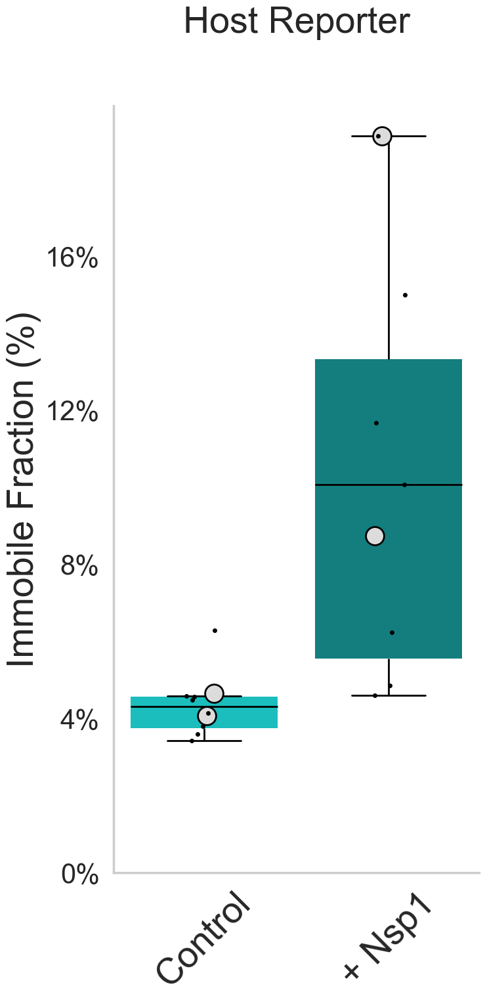

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30524\2281037834.py:176: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


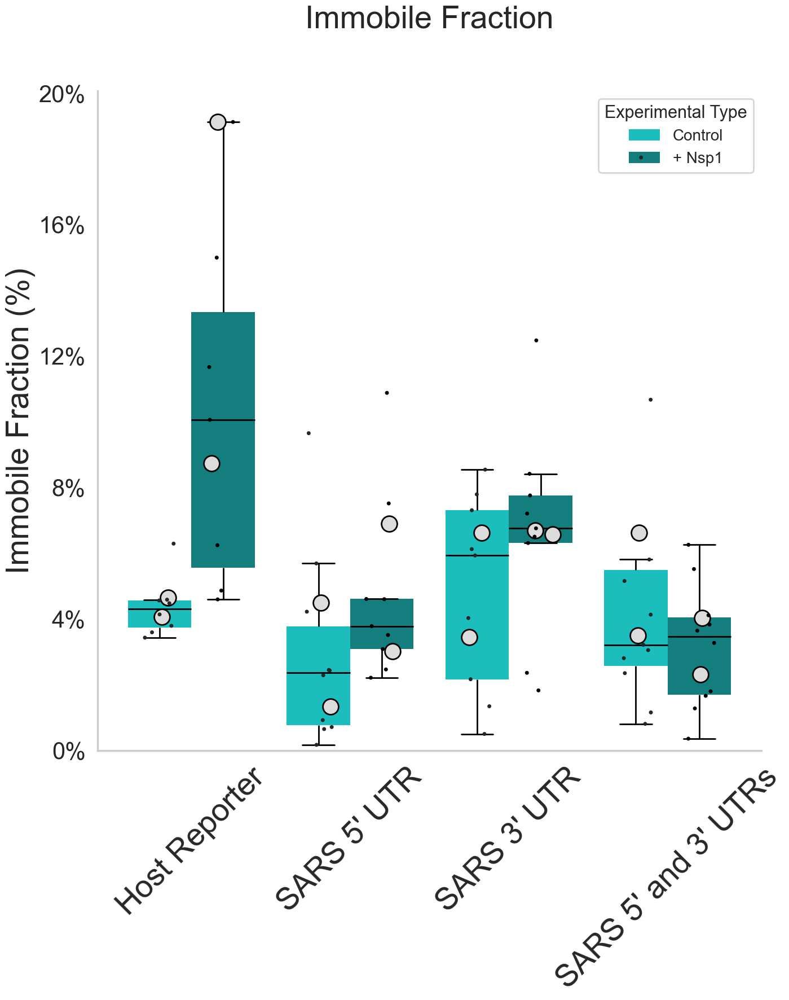

In [104]:
# CELL PURPOSE:
# Plot the fitted immobile fraction with explicit Host Reporter and
# all-reporter plotting code.
#
# Replicate means use the exact calculate_grouped_average() and
# plot_open_circles_with_hue() workflow copied from crop_array_analysis(8).

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

metric = IMMOBILE_VALUE_COLUMN

# One value per cell
data = collapse_to_one_value_per_cell(
    df_ht_immobile_plot,
    metric,
).rename(
    columns={
        "_Replicate_ID": "Replicate_Number",
        "_Cell_ID": "Cell_ID",
    }
)

# Replicate-level averages
superplot = calculate_grouped_average(
    data,
    metric,
    ["Experimental_Group", "Experimental_Type", "Replicate_Number"],
)

type_order = [
    experimental_type for experimental_type in TYPE_ORDER
    if experimental_type in data["Experimental_Type"].astype(str).unique()
]

type_label_map = {
    "No Nsp1": "Control",
    "Nsp1": "+ Nsp1",
    "NoCTD Nsp1": "+ Nsp1ΔC",
}

# ============================================================
# PLOT 1: Host Reporter
# ============================================================

control_data = data.loc[
    data["Experimental_Group"].astype(str).eq(str(CONTROL_GROUP))
].copy()

control_superplot = superplot.loc[
    superplot["Experimental_Group"].astype(str).eq(str(CONTROL_GROUP))
].copy()

order = type_order
new_labels = [
    type_label_map.get(experimental_type, experimental_type)
    for experimental_type in order
]

fig, ax = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig, top=True, right=True, left=False, bottom=False)

sns.boxplot(
    x="Experimental_Type",
    y=metric,
    data=control_data,
    order=order,
    ax=ax,
    palette=blue_palette,
    boxprops=dict(linewidth=0),
    whiskerprops=dict(color="black", linewidth=2),
    capprops=dict(color="black", linewidth=2),
    medianprops=dict(color="black", linewidth=2),
    showfliers=False,
)

sns.stripplot(
    x="Experimental_Type",
    y=metric,
    data=control_data,
    order=order,
    color="black",
    alpha=1,
    size=5,
    jitter=True,
    dodge=True,
    ax=ax,
    zorder=9,
)

plot_open_circles_with_hue(
    ax,
    control_superplot,
    order=order,
    x="Experimental_Type",
    y=f"Super {metric}",
    hue="Experimental_Group",
    jitter=True,
    jitter_strength=0.08,
    random_state=100,
)

ax.set_title("Host Reporter", fontsize=40, pad=80)
ax.set_ylabel("Immobile Fraction (%)", fontsize=40)
ax.set_xlabel("")
ax.set_ylim(bottom=0)
ax.tick_params(axis="both", which="major", labelsize=30)
ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:.0f}%")
)

if ax.get_legend() is not None:
    ax.get_legend().remove()

save_figure(
    fig,
    f"HT_Fitted_Immobile_Fraction_{IMMOBILE_EVALUATION_MIN:g}min_Host_Reporter",
)

plt.tight_layout()
plt.show()

control_fig = fig
control_ax = ax

# ============================================================
# PLOT 2: All reporters
# ============================================================

group_order = [
    group for group in GROUP_ORDER
    if group in data["Experimental_Group"].astype(str).unique()
]
new_group_labels = [
    GROUP_LABELS.get(group, group)
    for group in group_order
]

fig_all, ax_all = plt.subplots(
    figsize=(16, 16),
    constrained_layout=True,
)

sns.despine(
    fig=fig_all,
    top=True,
    right=True,
    left=False,
    bottom=False,
)

sns.boxplot(
    x="Experimental_Group",
    y=metric,
    hue="Experimental_Type",
    data=data,
    order=group_order,
    hue_order=type_order,
    ax=ax_all,
    palette=blue_palette,
    boxprops=dict(linewidth=0),
    whiskerprops=dict(color="black", linewidth=2),
    capprops=dict(color="black", linewidth=2),
    medianprops=dict(color="black", linewidth=2),
    showfliers=False,
)

sns.stripplot(
    x="Experimental_Group",
    y=metric,
    hue="Experimental_Type",
    data=data,
    order=group_order,
    hue_order=type_order,
    color="black",
    alpha=1,
    size=5,
    jitter=0.2,
    dodge=True,
    ax=ax_all,
    zorder=9,
)

plot_open_circles_with_hue(
    ax_all,
    superplot,
    order=group_order,
    x="Experimental_Group",
    y=f"Super {metric}",
    hue="Experimental_Type",
    hue_order=type_order,
    jitter=True,
    jitter_strength=0.08,
    random_state=100,
)

ax_all.set_title("Immobile Fraction", fontsize=40, pad=80)
ax_all.set_ylabel("Immobile Fraction (%)", fontsize=40)
ax_all.set_xlabel("")
ax_all.set_ylim(bottom=0)
ax_all.tick_params(axis="both", which="major", labelsize=30)
ax_all.set_xticklabels(
    new_group_labels,
    fontsize=40,
    rotation=45,
)
ax_all.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax_all.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:.0f}%")
)

handles, labels = ax_all.get_legend_handles_labels()
legend_lookup = {}
for handle, label in zip(handles, labels):
    if label in type_order and label not in legend_lookup:
        legend_lookup[label] = handle

if legend_lookup:
    ax_all.legend(
        [legend_lookup[label] for label in type_order if label in legend_lookup],
        [type_label_map.get(label, label) for label in type_order if label in legend_lookup],
        title="Experimental Type",
        fontsize=20,
        title_fontsize=22,
        loc="upper right",
    )
elif ax_all.get_legend() is not None:
    ax_all.get_legend().remove()

save_figure(
    fig_all,
    f"HT_Fitted_Immobile_Fraction_{IMMOBILE_EVALUATION_MIN:g}min_All_Reporters",
)

plt.tight_layout()
plt.show()

all_fig = fig_all
all_ax = ax_all
immobile_replicate_plot_data = superplot

immobile_plot_results = {
    "control_figure": control_fig,
    "control_axis": control_ax,
    "all_figure": all_fig,
    "all_axis": all_ax,
    "cell_data": data,
    "replicate_data": immobile_replicate_plot_data,
}


### Statistics — Host Reporter fitted immobile fraction

In [105]:
# CELL PURPOSE:
# Cell-level, replicate-aware statistics corresponding to the
# Host Reporter fitted immobile-fraction plot.


control_immobile = (
    df_ht_immobile_plot.loc[
        (
            df_ht_immobile_plot[
                'Experimental_Group'
            ]
            .astype(str)
            .eq(
                str(
                    CONTROL_GROUP
                )
            )
        )
        &
        (
            df_ht_immobile_plot[
                'Experimental_Type'
            ]
            .isin(
                TYPE_ORDER
            )
        )
    ]
    .copy()
)


control_immobile_statistics = (
    run_within_reporter_cell_tests(
        dataframe=control_immobile,

        value_column=(
            IMMOBILE_VALUE_COLUMN
        ),

        analysis_name=(
            'Host Reporter fitted immobile '
            f'fraction at '
            f'{IMMOBILE_TIME_AFTER_HT_ADDITION_MIN:g} min post-HT'
        ),

        group_order=[
            CONTROL_GROUP
        ],

        transform='log1p',
    )
)


save_and_display_statistics(
    control_immobile_statistics,

    (
        'tethered_ht_host_fitted_immobile_fraction_'
        'cell_level_mixed_model'
    ),

    (
        'Cell-level mixed model: Host Reporter '
        'fitted immobile fraction'
    ),
)


Cell-level mixed model: Host Reporter fitted immobile fraction
--------------------------------------------------------------
Observation level: one averaged value per cell
Replicate handling: random intercept; blocked-model fallback if needed
Significance stars: Holm-adjusted p-values
Host Reporter: n=8/7 cells; 2 matched replicates; mean=4.359/10.22; effect=2.128 (ratio of (value + 1)); p=9.75e-06; Holm p=9.75e-06; ****; Linear mixed-effects model
Parquet unavailable for tethered_ht_host_fitted_immobile_fraction_cell_level_mixed_model: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.
S

,analysis,value_column,comparison_column,reference_level,comparison_level,transform,effect_scale,n_reference_cells,n_comparison_cells,n_cells_total,n_reference_replicates,n_comparison_replicates,n_matched_replicates,reference_mean_raw,comparison_mean_raw,reference_median_raw,comparison_median_raw,raw_mean_difference_comparison_minus_reference,model_effect,model_effect_ci_low,model_effect_ci_high,standard_error,test_statistic,pvalue,model,replicate_adjustment,status,Experimental_Group,pvalue_holm,stars_raw,stars_holm,stars
0,Host Reporter fitted immobile fraction at 15 min post-HT,immobile_fraction_percent,Experimental_Type,No Nsp1,Nsp1,log1p,ratio of (value + 1),8,7,15,2,2,2,4.359443,10.22283,4.308499,10.062273,5.863387,2.128399,1.522898,2.974645,0.170796,4.422636,0.00001,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,Control,0.00001,****,****,****


### Statistics — Fitted immobile fraction across all reporters

In [106]:
# CELL PURPOSE:
# Cell-level, replicate-aware No Nsp1 versus +Nsp1 comparisons for
# each reporter in the all-reporter fitted immobile-fraction plot.


all_immobile = (
    df_ht_immobile_plot.loc[
        (
            df_ht_immobile_plot[
                'Experimental_Group'
            ]
            .isin(
                GROUP_ORDER
            )
        )
        &
        (
            df_ht_immobile_plot[
                'Experimental_Type'
            ]
            .isin(
                TYPE_ORDER
            )
        )
    ]
    .copy()
)


all_immobile_statistics = (
    run_within_reporter_cell_tests(
        dataframe=all_immobile,

        value_column=(
            IMMOBILE_VALUE_COLUMN
        ),

        analysis_name=(
            'Fitted immobile fraction at '
            f'{IMMOBILE_TIME_AFTER_HT_ADDITION_MIN:g} min post-HT'
        ),

        group_order=(
            GROUP_ORDER
        ),

        transform='log1p',
    )
)


save_and_display_statistics(
    all_immobile_statistics,

    (
        'tethered_ht_all_fitted_immobile_fraction_'
        'cell_level_mixed_models'
    ),

    (
        'Cell-level mixed models: '
        'fitted immobile fraction'
    ),
)


Cell-level mixed models: fitted immobile fraction
-------------------------------------------------
Observation level: one averaged value per cell
Replicate handling: random intercept; blocked-model fallback if needed
Significance stars: Holm-adjusted p-values
Host Reporter: n=8/7 cells; 2 matched replicates; mean=4.359/10.22; effect=2.128 (ratio of (value + 1)); p=9.75e-06; Holm p=3.9e-05; ****; Linear mixed-effects model
SARS 5' UTR: n=10/9 cells; 2 matched replicates; mean=2.918/4.74; effect=1.671 (ratio of (value + 1)); p=0.04207; Holm p=0.1262; ns; Linear mixed-effects model
SARS 3' UTR: n=9/9 cells; 2 matched replicates; mean=4.86/6.625; effect=1.349 (ratio of (value + 1)); p=0.2375; Holm p=0.4751; ns; Linear mixed-effects model
SARS 5' and 3' UTRs: n=11/10 cells; 2 matched replicates; mean=5.2/3.172; effect=0.7715 (ratio of (value + 1)); p=0.2904; Holm p=0.4751; ns; Linear mixed-effects model
Parquet unavailable for tethered_ht_all_fitted_immobile_fraction_cell_level_mixed_mode

,analysis,value_column,comparison_column,reference_level,comparison_level,transform,effect_scale,n_reference_cells,n_comparison_cells,n_cells_total,n_reference_replicates,n_comparison_replicates,n_matched_replicates,reference_mean_raw,comparison_mean_raw,reference_median_raw,comparison_median_raw,raw_mean_difference_comparison_minus_reference,model_effect,model_effect_ci_low,model_effect_ci_high,standard_error,test_statistic,pvalue,model,replicate_adjustment,status,Experimental_Group,pvalue_holm,stars_raw,stars_holm,stars
0,Fitted immobile fraction at 15 min post-HT,immobile_fraction_percent,Experimental_Type,No Nsp1,Nsp1,log1p,ratio of (value + 1),8,7,15,2,2,2,4.359443,10.222830,4.308499,10.062273,5.863387,2.128399,1.522898,2.974645,0.170796,4.422636,0.000010,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,Control,0.000039,****,****,****
1,Fitted immobile fraction at 15 min post-HT,immobile_fraction_percent,Experimental_Type,No Nsp1,Nsp1,log1p,ratio of (value + 1),10,9,19,2,2,2,2.918201,4.740069,2.359943,3.781498,1.821868,1.670541,1.018565,2.739841,0.252429,2.032835,0.042069,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,SARS_5'UTR,0.126208,*,ns,ns
2,Fitted immobile fraction at 15 min post-HT,immobile_fraction_percent,Experimental_Type,No Nsp1,Nsp1,log1p,ratio of (value + 1),9,9,18,2,2,2,4.860014,6.625112,5.932007,6.758801,1.765098,1.348594,0.821028,2.215155,0.253199,1.181138,0.237548,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,SARS_3'UTR,0.475096,ns,ns,ns
3,Fitted immobile fraction at 15 min post-HT,immobile_fraction_percent,Experimental_Type,No Nsp1,Nsp1,log1p,ratio of (value + 1),11,10,21,2,2,2,5.200144,3.172287,3.213262,3.456270,-2.027858,0.771499,0.476958,1.247930,0.245365,-1.057283,0.290382,Linear mixed-effects model,Random intercept for biological replicate,Test completed; Random effects covariance is singular | The random effects covariance matrix is singular. | The MLE may be on the bounda...,SARS_5'_3'UTR,0.475096,ns,ns,ns



Time-point-0 translation brightness

Time point: 0

Cells per biological replicate:


,Experimental_Group,Experimental_Type,Replicate_Number,Cells
0,Control,No Nsp1,1,4
1,Control,No Nsp1,2,4
2,Control,Nsp1,1,4
3,Control,Nsp1,2,6
4,SARS_3'UTR,No Nsp1,1,5
5,SARS_3'UTR,No Nsp1,2,5
6,SARS_3'UTR,Nsp1,1,5
7,SARS_3'UTR,Nsp1,2,6
8,SARS_5'UTR,No Nsp1,1,5
9,SARS_5'UTR,No Nsp1,2,6



Translation sites contributing per cell:


,Experimental_Group,Experimental_Type,Replicate_Number,Translation Sites,Cell Average Translation Signal
0,Control,No Nsp1,1,54,285.197318
1,Control,No Nsp1,1,35,382.631034
2,Control,No Nsp1,1,39,240.477011
3,Control,No Nsp1,1,141,464.460015
4,SARS_3'UTR,No Nsp1,1,71,386.720253
5,SARS_3'UTR,No Nsp1,1,109,739.674628
6,SARS_3'UTR,No Nsp1,1,29,318.608205
7,SARS_3'UTR,No Nsp1,1,162,414.704874
8,SARS_3'UTR,No Nsp1,1,37,308.161230
9,SARS_5'UTR,No Nsp1,1,62,276.356229


C:\Users\AdamC\AppData\Local\Temp\ipykernel_8044\1963930674.py:510: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


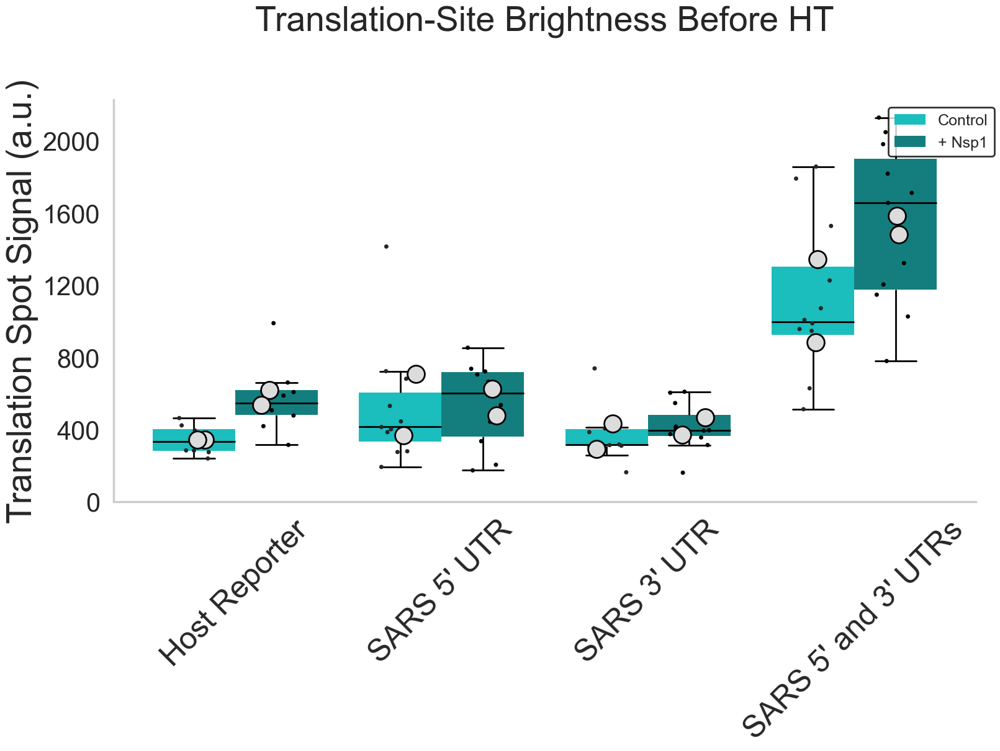

In [59]:
# ============================================================
# TETHERED HT
# TIME-POINT-0 TRANSLATION-SITE BRIGHTNESS
#
# Box plots:
#     box/whiskers = individual-cell distribution
#
# Black dots:
#     individual-cell mean translation-site brightness
#
# Open circles:
#     biological-replicate means
#
# Brightness is calculated from the raw spot-level translation
# signal at t = 0, before HT-dependent runoff normalization.
# ============================================================

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from matplotlib.ticker import MaxNLocator


# ============================================================
# SETTINGS
# ============================================================

BRIGHTNESS_TIMEPOINT = 0

BRIGHTNESS_SIGNAL_COLUMN = "signal"

CELL_BRIGHTNESS_COLUMN = (
    "Cell Average Translation Signal"
)

SUPER_BRIGHTNESS_COLUMN = (
    "Super Cell Average Translation Signal"
)


# ============================================================
# GROUP / TYPE ORDER
#
# Use the same reporter ordering already defined by the
# tethered-HT notebook.
# ============================================================

group_order = [

    group

    for group in GROUP_ORDER[:4]

    if group
    in spot_analysis_df[
        "Experimental_Group"
    ]
    .astype(str)
    .unique()
]


type_order = [

    experimental_type

    for experimental_type in TYPE_ORDER

    if experimental_type
    in spot_analysis_df[
        "Experimental_Type"
    ]
    .astype(str)
    .unique()
]


# ============================================================
# DISPLAY LABELS
# ============================================================

new_labels = [

    GROUP_LABELS.get(
        group,
        group,
    )

    for group in group_order
]


type_label_map = {

    "No Nsp1":
        "Control",

    "Nsp1":
        "+ Nsp1",

    "NoCTD Nsp1":
        "+ Nsp1ΔC",
}


legend_labels = [

    type_label_map.get(
        experimental_type,
        experimental_type,
    )

    for experimental_type in type_order
]


# ============================================================
# SELECT TIME POINT 0
# ============================================================

brightness_spot_df = (
    spot_analysis_df
    .copy()
)


brightness_spot_df[
    "t"
] = pd.to_numeric(

    brightness_spot_df[
        "t"
    ],

    errors="coerce",
)


brightness_spot_df[
    BRIGHTNESS_SIGNAL_COLUMN
] = pd.to_numeric(

    brightness_spot_df[
        BRIGHTNESS_SIGNAL_COLUMN
    ],

    errors="coerce",
)


brightness_spot_df[
    "Replicate_Number"
] = pd.to_numeric(

    brightness_spot_df[
        "Replicate_Number"
    ],

    errors="coerce",
)


brightness_spot_df = (

    brightness_spot_df.loc[

        brightness_spot_df[
            "t"
        ].eq(
            BRIGHTNESS_TIMEPOINT
        )

        &

        brightness_spot_df[
            "Experimental_Group"
        ].astype(str)
        .isin(
            group_order
        )

        &

        brightness_spot_df[
            "Experimental_Type"
        ].astype(str)
        .isin(
            type_order
        )

        &

        np.isfinite(
            brightness_spot_df[
                BRIGHTNESS_SIGNAL_COLUMN
            ]
        )

        &

        (
            brightness_spot_df[
                BRIGHTNESS_SIGNAL_COLUMN
            ]
            > 0
        )

    ]

    .copy()
)


if brightness_spot_df.empty:

    raise RuntimeError(
        "No positive translation-site signals were found "
        f"at t={BRIGHTNESS_TIMEPOINT}."
    )


# ============================================================
# IDENTIFY ONE CELL
#
# Use the notebook's CELL_KEYS so this remains consistent
# with the HT analysis.
# ============================================================

brightness_cell_keys = [

    column

    for column in CELL_KEYS

    if column
    in brightness_spot_df.columns
]


# Make sure the variables needed for plotting are retained.
for required_column in [

    "Experimental_Group",
    "Experimental_Type",
    "Replicate_Number",

]:

    if (
        required_column
        not in brightness_cell_keys
    ):

        brightness_cell_keys.append(
            required_column
        )


# ============================================================
# SPOTS -> CELL AVERAGES
#
# Each cell contributes exactly one value:
#
# mean translation-site signal at t = 0
# ============================================================

t0_translation_cell_df = (

    brightness_spot_df

    .groupby(
        brightness_cell_keys,
        dropna=False,
    )

    .agg(

        **{
            CELL_BRIGHTNESS_COLUMN:
                (
                    BRIGHTNESS_SIGNAL_COLUMN,
                    "mean",
                ),

            "Translation Sites":
                (
                    BRIGHTNESS_SIGNAL_COLUMN,
                    "count",
                ),
        }
    )

    .reset_index()
)


# ============================================================
# BIOLOGICAL-REPLICATE AVERAGES
# ============================================================

superplot_translation_t0 = (
    calculate_grouped_average(

        df=
            t0_translation_cell_df,

        average_column=
            CELL_BRIGHTNESS_COLUMN,

        group_by_columns=[
            "Experimental_Group",
            "Experimental_Type",
            "Replicate_Number",
        ],
    )
)


# ============================================================
# QUICK QC
# ============================================================

print(
    "\nTime-point-0 translation brightness"
)

print(
    "==================================="
)

print(
    f"\nTime point: {BRIGHTNESS_TIMEPOINT}"
)


print(
    "\nCells per biological replicate:"
)


display(

    t0_translation_cell_df

    .groupby(
        [
            "Experimental_Group",
            "Experimental_Type",
            "Replicate_Number",
        ],
        dropna=False,
    )

    .size()

    .rename(
        "Cells"
    )

    .reset_index()
)


print(
    "\nTranslation sites contributing per cell:"
)


display(

    t0_translation_cell_df[
        [
            "Experimental_Group",
            "Experimental_Type",
            "Replicate_Number",
            "Translation Sites",
            CELL_BRIGHTNESS_COLUMN,
        ]
    ]
    .head(
        20
    )
)


# ============================================================
# USER-ADJUSTABLE Y LIMIT
# ============================================================

translation_y_max = None


# ============================================================
# STYLE
# ============================================================

sns.set(
    font_scale=1.9
)

sns.set_style(
    "whitegrid",
    {
        "grid.linestyle": ""
    }
)

sns.set_context(
    "poster"
)


# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(

    figsize=(
        16,
        12,
    ),

    constrained_layout=True,
)


sns.despine(

    fig=fig,

    top=True,

    right=True,

    left=False,

    bottom=False,
)


# ============================================================
# CELL-LEVEL BOX PLOTS
# ============================================================

sns.boxplot(

    x="Experimental_Group",

    y=
        CELL_BRIGHTNESS_COLUMN,

    hue=
        "Experimental_Type",

    data=
        t0_translation_cell_df,

    order=
        group_order,

    hue_order=
        type_order,

    ax=ax,

    palette=
        blue_palette[
            :len(
                type_order
            )
        ],

    boxprops=dict(
        linewidth=0
    ),

    whiskerprops=dict(
        color="black",
        linewidth=2
    ),

    capprops=dict(
        color="black",
        linewidth=2
    ),

    medianprops=dict(
        color="black",
        linewidth=2
    ),

    showfliers=False,
)


# Save clean boxplot legend handles before overlays.
handles, labels = (
    ax.get_legend_handles_labels()
)


# ============================================================
# INDIVIDUAL CELLS
# ============================================================

sns.stripplot(

    x="Experimental_Group",

    y=
        CELL_BRIGHTNESS_COLUMN,

    hue=
        "Experimental_Type",

    data=
        t0_translation_cell_df,

    order=
        group_order,

    hue_order=
        type_order,

    dodge=True,

    jitter=0.20,

    color="black",

    alpha=1,

    size=5,

    ax=ax,

    zorder=9,
)


# ============================================================
# BIOLOGICAL-REPLICATE MEANS
# ============================================================

plot_open_circles_with_hue(

    ax,

    superplot_translation_t0,

    order=
        group_order,

    x=
        "Experimental_Group",

    y=
        SUPER_BRIGHTNESS_COLUMN,

    hue=
        "Experimental_Type",

    hue_order=
        type_order,

    zorder=10,

    jitter=True,

    jitter_strength=0.08,

    random_state=100,
)


# ============================================================
# FORMATTING
# ============================================================

ax.set_title(

    "Translation-Site Brightness Before HT",

    fontsize=40,

    pad=80,
)


ax.set_ylabel(

    "Translation Spot Signal (a.u.)",

    fontsize=40,
)


ax.set_xlabel(
    ""
)


ax.tick_params(

    axis="both",

    which="major",

    labelsize=30,
)


ax.set_xticklabels(

    new_labels,

    fontsize=36,

    rotation=45,
)


if translation_y_max is None:

    ax.set_ylim(
        bottom=0
    )

else:

    ax.set_ylim(
        0,
        translation_y_max
    )


ax.yaxis.set_major_locator(

    MaxNLocator(
        nbins=6
    )
)


# ============================================================
# CLEAN LEGEND
# ============================================================

if ax.get_legend() is not None:

    ax.get_legend().remove()


ax.legend(

    handles[
        :len(
            type_order
        )
    ],

    legend_labels,

    title=None,

    facecolor="white",

    edgecolor="black",

    fontsize=18,

    loc="upper right",

    bbox_to_anchor=(
        1.03,
        1
    ),
)


# ============================================================
# PAIRED STATISTICS
#
# Compare experimental types WITHIN each reporter using the
# biological-replicate averages.
# ============================================================

if (
    "print_paired_ttest_summary"
    in globals()
):

    res_translation_t0 = (
        print_paired_ttest_summary(

            data=
                superplot_translation_t0,

            x=
                "Experimental_Group",

            y=
                SUPER_BRIGHTNESS_COLUMN,

            hue=
                "Experimental_Type",

            pair_col=
                "Replicate_Number",

            order=
                group_order,

            hue_order=
                type_order,

            compare_x=False,

            compare_hue=True,

            verbose=True,
        )
    )


    print(
        "\nPaired biological-replicate statistics:"
    )


    display(
        res_translation_t0
    )


# ============================================================
# SAVE
# ============================================================

save_figure(

    fig,

    "Tethered_HT_Time0_Translation_Spot_Brightness",
)


plt.show()


# ============================================================
# STORE RESULTS
# ============================================================

tethered_ht_t0_translation_cell_data = (
    t0_translation_cell_df
)

tethered_ht_t0_translation_replicate_data = (
    superplot_translation_t0
)

tethered_ht_t0_translation_figure = (
    fig
)

tethered_ht_t0_translation_axis = (
    ax
)